In [1]:
# ── Cell A1: Setup & Installs ─────────────────────────────────────────────

%pip install -q kagglehub keras-tuner xgboost pyreadstat shap imbalanced-learn iterative-stratification

# Quick version print
import sys, sklearn, numpy, pandas
import xgboost as xgb
import shap, imblearn
print("Python:", sys.version.split()[0])
print("pandas:", pandas.__version__, "| numpy:", numpy.__version__, "| sklearn:", sklearn.__version__)
print("xgboost:", xgb.__version__, "| shap:", shap.__version__, "| imbalanced-learn:", imblearn.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 666.4/666.4 kB 50.0 MB/s eta 0:00:00
Python: 3.12.11
pandas: 2.2.2 | numpy: 2.0.2 | sklearn: 1.6.1
xgboost: 3.0.4 | shap: 0.48.0 | imbalanced-learn: 0.14.0


In [2]:
# ── Cell A2: Imports & Global Config ───────────────────────────────────────
import os, sys, gc, json, math, time, random, warnings, glob
from pathlib import Path
from typing import List, Dict, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, roc_auc_score, average_precision_score,
    accuracy_score, balanced_accuracy_score, recall_score, f1_score
)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Iterative multilabel stratification
from iterstrat.ml_stratifiers import (
    MultilabelStratifiedKFold,
    MultilabelStratifiedShuffleSplit
)

# XGBoost
import xgboost as xgb

# TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras import Input, Model, Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Bidirectional, LSTM, SpatialDropout1D
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Misc
warnings.filterwarnings("ignore")

# -------------------- Reproducibility --------------------
SEED = 42
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
set_seed(SEED)

# -------------------- Paths & data config --------------------
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
PROC_DIR = DATA_DIR / "processed"
for d in [DATA_DIR, RAW_DIR, PROC_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Core filenames expected (pre-cleaned CSVs)
FILE_DIET = "dietary_clean.csv"
FILE_DEMO = "demographics_clean.csv"
FILE_RESP = "response_clean.csv"

# Kaggle dataset slug
KAGGLE_SLUG = "nguyenvy/nhanes-19882018"
_kaggle_root: Optional[Path] = None

def _kaggle_download_if_needed() -> Optional[Path]:
    """Lazy-download the Kaggle dataset if local files are missing."""
    global _kaggle_root
    if _kaggle_root is not None:
        return _kaggle_root
    try:
        import kagglehub
        p = kagglehub.dataset_download(KAGGLE_SLUG)
        _kaggle_root = Path(p)
        return _kaggle_root
    except Exception as e:
        print(f"[WARN] Kaggle download failed or unavailable: {e}")
        return None

def _resolve_path(fname: str) -> Optional[Path]:
    """Search common locations for a file."""
    candidates = [
        BASE_DIR / fname,
        RAW_DIR / fname,
        DATA_DIR / fname,
        PROC_DIR / fname,
    ]
    for c in candidates:
        if c.is_file():
            return c
    root = _kaggle_download_if_needed()
    if root:
        hits = list(root.rglob(fname))
        if hits:
            return hits[0]
    return None

def log(msg: str):
    ts = time.strftime('%H:%M:%S')
    print(f"[{ts}] {msg}")

def safe_divide(numer: np.ndarray, denom: np.ndarray, fill: float = 0.0) -> np.ndarray:
    out = np.zeros_like(numer, dtype=float)
    mask = denom != 0
    out[mask] = numer[mask] / denom[mask]
    out[~mask] = fill
    return out

# Label columns (study focus)
LABEL_COLS = ["diabetes", "hypertension", "thyroid_disorder"]

# Pandas display tweaks
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 200)

log("Imports loaded; config ready.")
print("BASE_DIR:", BASE_DIR)
print("DATA_DIR:", DATA_DIR)
print("Expected files:", FILE_DIET, FILE_DEMO, FILE_RESP)

[13:39:35] Imports loaded; config ready.
BASE_DIR: /content
DATA_DIR: /content/data
Expected files: dietary_clean.csv demographics_clean.csv response_clean.csv


In [3]:
# ── Cell B1: Resolve & Load CSVs ───────────────────────────────────────────
def _must_resolve(fname: str) -> Path:
    p = _resolve_path(fname)
    if p is None:
        raise FileNotFoundError(
            f"Could not find {fname} in working dir or data folders, "
            f"and Kaggle download did not provide it.\n"
            f"→ Upload {fname} to /content or /content/data, or ensure it exists in the Kaggle dataset."
        )
    log(f"Resolved {fname} → {p}")
    return p

P_DIET = _must_resolve(FILE_DIET)
P_DEMO = _must_resolve(FILE_DEMO)
P_RESP = _must_resolve(FILE_RESP)

def _load_csv(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, low_memory=False)
    # standardize SEQN dtype if present
    if "SEQN" in df.columns:
        df["SEQN"] = pd.to_numeric(df["SEQN"], errors="coerce").astype("Int64")
    return df

diet = _load_csv(P_DIET)
demo = _load_csv(P_DEMO)
resp = _load_csv(P_RESP)

# ---- Basic summaries
print("\n=== Loaded shapes ===")
print("diet:", diet.shape)
print("demo:", demo.shape)
print("resp:", resp.shape)

def _has(df, col): return col in df.columns
print("\nSEQN present?  diet:", _has(diet, "SEQN"), "| demo:", _has(demo, "SEQN"), "| resp:", _has(resp, "SEQN"))

# Key feature/label fields expected to exist
expected_feature_examples = ["DRXTKCAL", "DRXTPROT", "DRXTCARB", "DRXTTFAT", "DRXTSODI"]
expected_label_candidates = ["DIQ010", "BPQ020", "BPQ150A", "LBXTSH", "LBXTSH1", "LBXTSH2"]

print("\n=== Feature fields present in diet (examples) ===")
for c in expected_feature_examples:
    print(f"{c:10} →", c in diet.columns)

print("\n=== Label candidates present in resp ===")
for c in expected_label_candidates:
    print(f"{c:8} →", c in resp.columns)

# Show a compact peek at relevant columns
peek_cols = [c for c in expected_label_candidates + ["SEQN"] if c in resp.columns][:12]
print("\nresp peek cols:", peek_cols)
if peek_cols:
    display(resp[peek_cols].head(10))

100%|██████████| 875M/875M [00:37<00:00, 24.6MB/s]

Extracting files...


[13:40:40] Resolved dietary_clean.csv → /root/.cache/kagglehub/datasets/nguyenvy/nhanes-19882018/versions/10/dietary_clean.csv
[13:40:40] Resolved demographics_clean.csv → /root/.cache/kagglehub/datasets/nguyenvy/nhanes-19882018/versions/10/demographics_clean.csv
[13:40:40] Resolved response_clean.csv → /root/.cache/kagglehub/datasets/nguyenvy/nhanes-19882018/versions/10/response_clean.csv

=== Loaded shapes ===
diet: (324374, 325)
demo: (135310, 281)
resp: (131030, 1038)

SEQN present?  diet: True | demo: True | resp: True

=== Feature fields present in diet (examples) ===
DRXTKCAL   → True
DRXTPROT   → True
DRXTCARB   → True
DRXTTFAT   → True
DRXTSODI   → True

=== Label candidates present in resp ===
DIQ010   → False
BPQ020   → False
BPQ150A  → True
LBXTSH   → True
LBXTSH1  → True
LBXTSH2  → True

resp peek cols: ['BPQ150A', 'LBXTSH', 'LBXTSH1', 'LBXTSH2', 'SEQN']


,BPQ150A,LBXTSH,LBXTSH1,LBXTSH2,SEQN
0,NaN,1.30,1.30,1.3,9
1,NaN,3.80,3.80,NaN,48
2,NaN,1.50,1.50,NaN,92
3,NaN,3.80,3.80,NaN,94
4,NaN,2.25,2.30,2.2,106
5,NaN,1.04,0.68,1.4,117
6,NaN,1.50,1.60,1.4,120
7,NaN,3.80,3.80,NaN,125
8,NaN,0.56,0.56,NaN,140
9,NaN,1.95,1.90,2.0,188


In [4]:
# ── Cell C1: Label construction & diagnostics  ──────────────────────
def _as_num(series):
    return pd.to_numeric(series, errors="coerce")

def _first_nonnull(*arrs):
    stacked = np.vstack([a.values for a in arrs])
    out = []
    for col in stacked.T:
        idx = np.where(~pd.isna(col))[0]
        out.append(col[idx[0]] if idx.size else np.nan)
    return pd.Series(out, index=arrs[0].index)

cands = {
    "diabetes_diag": ["DIQ010"],
    "diabetes_treat": ["DIQ050", "DIQ070"],
    "hypertension_diag": ["BPQ020", "BPQ150A"],
    "tsh": ["LBXTSH1", "LBXTSH2", "LBXTSH"],
}
print("Availability scan (resp):")
for k, cols in cands.items():
    print(f"  {k:18}:", {c: (c in resp.columns) for c in cols})

y = pd.DataFrame({"SEQN": resp["SEQN"].astype("Int64")})

# Diabetes (diagnosis preferred; else treatment proxies)
diab_used = None
if "DIQ010" in resp.columns:
    y["diabetes"] = (_as_num(resp["DIQ010"]) == 1).astype("Int8")
    diab_used = "DIQ010 (diagnosis: ever told you have diabetes)"
else:
    parts = []
    if "DIQ050" in resp.columns:
        parts.append(_as_num(resp["DIQ050"]) == 1)
    if "DIQ070" in resp.columns:
        parts.append(_as_num(resp["DIQ070"]) == 1)
    if parts:
        any_treat = np.logical_or.reduce(parts)
        y["diabetes"] = pd.Series(any_treat, index=y.index).astype("Int8")
        diab_used = "DIQ050/DIQ070 (treatment proxies: insulin/pills)"
    else:
        y["diabetes"] = pd.Series(pd.NA, index=y.index, dtype="Int8")
        diab_used = "MISSING (no diagnosis/treatment vars found)"

# Hypertension (diagnosis)
if "BPQ020" in resp.columns:
    y["hypertension"] = (_as_num(resp["BPQ020"]) == 1).astype("Int8")
    htn_used = "BPQ020 (diagnosis: ever told you had hypertension)"
else:
    y["hypertension"] = (_as_num(resp["BPQ150A"]) == 1).astype("Int8") if "BPQ150A" in resp.columns else pd.Series(pd.NA, index=y.index, dtype="Int8")
    htn_used = "BPQ150A (diagnosis)" if "BPQ150A" in resp.columns else "MISSING"

# Thyroid disorder (TSH > 4.5 mIU/L)
tsh_cols = [c for c in ["LBXTSH1", "LBXTSH2", "LBXTSH"] if c in resp.columns]
thy_used = " / ".join(tsh_cols) if tsh_cols else "MISSING"
if tsh_cols:
    series_list = [_as_num(resp[c]) for c in tsh_cols]
    tsh_any = _first_nonnull(*series_list)
    y["thyroid_disorder"] = (tsh_any > 4.5).astype("Int8")
else:
    y["thyroid_disorder"] = pd.Series(pd.NA, index=y.index, dtype="Int8")

print("\nVariables used:")
print("  Diabetes     →", diab_used)
print("  Hypertension →", htn_used)
print("  Thyroid      →", thy_used)

def _count_pos(col):
    s = y[col]
    return int((s == 1).sum()), int(s.notna().sum())

for lab in ["diabetes", "hypertension", "thyroid_disorder"]:
    pos, known = _count_pos(lab)
    print(f"{lab:16} positives={pos} known={known} (out of {len(y)})")

y.head(10)

Availability scan (resp):
  diabetes_diag     : {'DIQ010': False}
  diabetes_treat    : {'DIQ050': True, 'DIQ070': False}
  hypertension_diag : {'BPQ020': False, 'BPQ150A': True}
  tsh               : {'LBXTSH1': True, 'LBXTSH2': True, 'LBXTSH': True}

Variables used:
  Diabetes     → DIQ050/DIQ070 (treatment proxies: insulin/pills)
  Hypertension → BPQ150A (diagnosis)
  Thyroid      → LBXTSH1 / LBXTSH2 / LBXTSH
diabetes         positives=418 known=131030 (out of 131030)
hypertension     positives=14886 known=131030 (out of 131030)
thyroid_disorder positives=1477 known=131030 (out of 131030)


,SEQN,diabetes,hypertension,thyroid_disorder
0,9,0,0,0
1,48,0,0,0
2,92,0,0,0
3,94,0,0,0
4,106,0,0,0
5,117,0,0,0
6,120,0,0,0
7,125,0,0,0
8,140,0,0,0
9,188,0,0,0


In [5]:
# ── Cell D1: Aggregate dietary intakes to participant level ────────────────
log("Preparing numeric nutrient columns...")
drop_meta = ["Unnamed: 0", "SDDSRVYR", "DRXLANG"]

# Coerce any object-typed numeric columns
obj_cols = [c for c in diet.columns if c != "SEQN" and diet[c].dtype == "object"]
if obj_cols:
    diet[obj_cols] = diet[obj_cols].apply(lambda s: pd.to_numeric(s, errors="coerce"))

num_cols = [c for c in diet.columns if c != "SEQN" and np.issubdtype(diet[c].dtype, np.number)]
log(f"Numeric columns detected: {len(num_cols)}")

# Days reported
if "DRXTKCAL" in diet.columns:
    day_counts = diet.groupby("SEQN")["DRXTKCAL"].apply(lambda s: s.notna().sum()).rename("days_reported")
else:
    day_counts = diet.groupby("SEQN")[num_cols[0]].apply(lambda s: s.notna().sum()).rename("days_reported")

# Aggregate with sum
log("Aggregating by SEQN with sum(min_count=1)...")
diet_agg = diet.groupby("SEQN")[num_cols].sum(min_count=1)

# Attach days_reported
diet_agg = diet_agg.merge(day_counts, left_index=True, right_index=True, how="left")

# Drop obvious metadata if present post-agg
diet_agg = diet_agg.drop(columns=[c for c in drop_meta if c in diet_agg.columns], errors="ignore")

# Finalize
diet_agg = diet_agg.reset_index()
diet_agg = diet_agg.astype({ "SEQN": "Int64" })

print("\n=== Diet aggregation summary ===")
print("Original diet:", diet.shape, "| Unique SEQN:", diet["SEQN"].nunique())
print("Aggregated   :", diet_agg.shape)
print("days_reported value counts (top):")
print(diet_agg["days_reported"].value_counts(dropna=False).head(10).to_string())

# Sanity checks for key fields
for c in ["SEQN", "DRXTKCAL", "DRXTPROT", "DRXTCARB", "DRXTTFAT"]:
    if c in diet_agg.columns:
        print(f"{c:10} present ✓")
    else:
        print(f"{c:10} MISSING ✗")

display(diet_agg.head(5))

[13:41:24] Preparing numeric nutrient columns...
[13:41:24] Numeric columns detected: 324
[13:41:32] Aggregating by SEQN with sum(min_count=1)...

=== Diet aggregation summary ===
Original diet: (324374, 325) | Unique SEQN: 98199
Aggregated   : (98199, 323)
days_reported value counts (top):
days_reported
3    49011
2    16411
4    13182
5    12033
0     6898
6      664
SEQN       present ✓
DRXTKCAL   present ✓
DRXTPROT   present ✓
DRXTCARB   present ✓
DRXTTFAT   present ✓


,SEQN,SEQN_new,RIDAGEYR,RIAGENDR,survey_day,WTDRD1,WTDR4YR,DRXEXMER,DRASCST2,DRDAINMD,DRDINTMD,DRXDAY,DRXDRSTZ,DRXMRESP,DRXTNUMF,WTDRXD,DRABF,DRDINT,DRXHELP,DRXDBIH,DRPIID,DRPQ5,DRPQ6,DRPQ7,DRPQ8,DRPQ9,DRPQ10,DRPQ11,DRPQ12,DRXTKCAL,DRXTPROT,DRXTCARB,DRXTTFAT,DRXTSFAT,DRXTMFAT,DRXTPFAT,DRXTCHOL,DRXTFIBE,DRXTVAIU,DRXTVARA,DRXTCARO,DRXTVB1,DRXTVB2,DRXTNIAC,DRXTVB6,DRXTFOLA,DRXTVB12,DRXTVC,DRXTATOC,DRXTCALC,DRXTPHOS,DRXTMAGN,DRXTIRON,DRXTZINC,DRXTCOPP,DRXTSODI,DRXTPOTA,DRXTSELE,DRXTCAFF,DRXTTHEO,DRXTALCO,DRXTMOIS,DRXTS040,DRXTS060,DRXTS080,DRXTS100,DRXTS120,DRXTS140,DRXTS160,DRXTS180,DRXTM161,DRXTM181,DRXTM201,DRXTM221,DRXTP182,DRXTP183,DRXTP184,DRXTP204,DRXTP205,DRXTP225,DRXTP226,DRXTSUGR,DRXTRET,DRXTACAR,DRXTBCAR,DRXTCRYP,DRXTLYCO,DRXTLZ,DRXTFA,DRXTFF,DRXTFDFE,DRXTVK,DRXTATOA,DRXTB12A,DRXTCHL,DRXTVD,DRPGW,DRPNVAIU,DRPNVE,DRPNKF,...,DRX.300,DRQSDIET,DRQSDT1,DRQSDT2,DRQSDT3,DRQSDT4,DRQSDT5,DRQSDT6,DRQSDT7,DRQSDT8,DRQSDT91,DRQSDT9,DRQSDT10,DRQSDT11,DRQSDT12,DRX.320Z,DRX.330Z,DRXCWATR,DRXBWATZ,DRXTWSZ,DRDTSODF,DBD100,DBQ095Z,DRQSPREP,DRXSTY,DRXSKY,DRD340,DRD350A,DRD350AQ,DRD350B,DRD350BQ,DRD350C,DRD350CQ,DRD350D,DRD350DQ,DRD350E,DRD350EQ,DRD350F,DRD350FQ,DRD350G,DRD350GQ,DRD350H,DRD350HQ,DRD350I,DRD350IQ,DRD350J,DRD350JQ,DRD350K,DRD360,DRD370A,DRD370AQ,DRD370B,DRD370BQ,DRD370C,DRD370CQ,DRD370D,DRD370DQ,DRD370E,DRD370EQ,DRD370F,DRD370FQ,DRD370G,DRD370GQ,DRD370H,DRD370HQ,DRD370I,DRD370IQ,DRD370J,DRD370JQ,DRD370K,DRD370KQ,DRD370L,DRD370LQ,DRD370M,DRD370MQ,DRD370N,DRD370NQ,DRD370O,DRD370OQ,DRD370P,DRD370PQ,DRD370Q,DRD370QQ,DRD370R,DRD370RQ,DRD370S,DRD370SQ,DRD370T,DRD370TQ,DRD370U,DRD370UQ,DRD370V,VNDRXS0406,VNDRXS081012,VNDRXS1416,VNDRXS141618,VNDRXSMFAT,VNDRXSSFAT,VNDRXSPFAT,days_reported
0,1,NaN,4.0,4.0,1,29619.787708,12132.257327,19.0,1.0,1.0,1.0,4.0,1.0,97.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2791.522887,76.080047,475.519621,70.716950,25.261298,24.765373,15.500679,186.280642,16.603996,2797.65,392.274251,119.41,2.827966,3.254045,30.506855,2.855075,590.079177,6.031292,375.154533,8.240864,1268.588268,1261.121504,285.980320,24.023588,11.721916,1.051398,3616.391720,3128.640248,108.487401,4.807939,29.100124,0.088945,2084.026510,0.580998,0.344139,0.255051,0.487802,0.791816,2.346099,14.377713,5.638075,1.204497,22.991407,0.114910,0.016447,14.339720,0.962449,0.004447,0.094502,0.007200,0.005002,0.021257,333.819696,497.626261,183.628346,7215.660702,199.040408,4276.842740,5843.931053,174.176418,228.813353,1139.093012,117.567214,0.410028,0.658009,NaN,NaN,NaN,NaN,NaN,NaN,...,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,570.220964,546.582464,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,NaN,2.0,NaN,2.0,NaN,1.0,1.0,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,0.925137,1.534670,16.723812,22.361887,24.327261,24.821694,15.434576,2
1,2,NaN,154.0,2.0,1,53799.417784,29843.868585,72.0,1.0,1.0,1.0,6.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4586.819562,214.130832,635.017095,142.792479,47.931826,52.869340,25.942967,609.379259,61.972322,4323.62,562.771055,182.07,3.930336,5.871086,63.617732,5.174788,975.232294,14.961883,232.934894,14.319396,1809.492904,3499.271388,871.667811,60.054540,59.222499,3.591348,9680.726704,8203.314596,232.138238,877.747737,243.850668,2.361624,4831.427056,0.547536,0.310438,0.215415,0.500914,0.689865,3.550475,27.539097,12.983759,3.382706,47.556440,0.233771,0.053907,22.283502,2.425576,0.005185,0.421713,0.015569,0.025941,0.081979,363.579064,565.640731,462.230434,12487.506397,218.739555,5093.918383,8630.382205,203.190837,380.009886,1543.273617,189.353215,0.451389,1.090516,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,332.542741,689.706919,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,1.0,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,1.0,1.0,2.0,NaN,1.0,1.0,2.0,NaN,2.0,NaN,2.0,

In [6]:
# ── Cell E1: Nutrient density features (per 1,000 kcal) ───────────────────
log("Creating per-1,000 kcal nutrient density features...")

assert "DRXTKCAL" in diet_agg.columns, "DRXTKCAL not found in aggregated diet."

# Pick a set of common macro/micro nutrients if present
candidate_nutrients = [
    "DRXTPROT","DRXTCARB","DRXTTFAT","DRXTSFAT","DRXTMFAT","DRXTPFAT",
    "DRXTCHOL","DRXTFIBE","DRXTSODI","DRXTPOTA","DRXTCAFF","DRXTALCO",
    # add a few vitamins/minerals commonly used
    "DRXTIRON","DRXTCALC","DRXTMAGN","DRXTPHOS","DRXTVB12","DRXTVC","DRXTVD"
]
nutrs = [c for c in candidate_nutrients if c in diet_agg.columns]
created = []

kcal = diet_agg["DRXTKCAL"].astype(float).to_numpy()
denom = kcal / 1000.0

for c in nutrs:
    vals = diet_agg[c].astype(float).to_numpy()
    dens = safe_divide(vals, denom, fill=0.0)
    newc = f"{c}_per1k"
    diet_agg[newc] = dens
    created.append(newc)

print(f"Base nutrients found: {len(nutrs)} / {len(candidate_nutrients)}")
print("Created density columns:", len(created))
print("First 8 density columns:", created[:8])

# Quick sanity check rows with zero kcal
zero_kcal = int((kcal == 0).sum())
print("Participants with DRXTKCAL == 0:", zero_kcal)

display(diet_agg[[c for c in ['SEQN','DRXTKCAL'] + created[:6] if c in diet_agg.columns]].head(5))

[13:41:34] Creating per-1,000 kcal nutrient density features...
Base nutrients found: 19 / 19
Created density columns: 19
First 8 density columns: ['DRXTPROT_per1k', 'DRXTCARB_per1k', 'DRXTTFAT_per1k', 'DRXTSFAT_per1k', 'DRXTMFAT_per1k', 'DRXTPFAT_per1k', 'DRXTCHOL_per1k', 'DRXTFIBE_per1k']
Participants with DRXTKCAL == 0: 0


,SEQN,DRXTKCAL,DRXTPROT_per1k,DRXTCARB_per1k,DRXTTFAT_per1k,DRXTSFAT_per1k,DRXTMFAT_per1k,DRXTPFAT_per1k
0,1,2791.522887,27.253958,170.344160,25.332749,9.049289,8.871635,5.552768
1,2,4586.819562,46.683945,138.443880,31.131043,10.449904,11.526361,5.655982
2,3,8697.811548,31.811156,137.564437,37.200388,12.871043,14.681716,6.847764
3,4,7222.946904,34.764327,129.332352,34.448461,14.329038,12.878578,5.035367
4,5,5301.014860,36.789189,103.628521,40.886248,13.090842,19.653833,5.314152


In [7]:
# ── Cell F1: Merge labels with aggregated diet & feature cleaning ─────────
log("Merging labels with aggregated diet on SEQN (inner)...")
df = diet_agg.merge(y, on="SEQN", how="inner")

label_cols = ["diabetes", "hypertension", "thyroid_disorder"]
feat_cols_all = [c for c in df.columns if c not in (["SEQN"] + label_cols)]

# Drop columns with >50% missing (features only)
na_frac = df[feat_cols_all].isna().mean().sort_values(ascending=False)
to_drop_na = na_frac[na_frac > 0.50].index.tolist()

# Exclude known metadata/non-diet (diet-only predictors policy)
meta_exclude = [
    "SEQN_new","SDDSRVYR","DRXLANG","RIDAGEYR","RIAGENDR","survey_day",
    "WTDRD1","WTDR4YR","WTDRXD","DRXDAY","DRXDRSTZ","DRXMRESP","DRXTNUMF","DRPGW",
    "days_reported"
]
drop_cols = sorted(set(to_drop_na + [c for c in meta_exclude if c in df.columns]))

log(f"Columns >50% missing to drop: {len(to_drop_na)}")
log(f"Metadata/non-diet columns to drop (found): {len([c for c in meta_exclude if c in df.columns])}")

# Build X (numeric only) and y
X = df.drop(columns=drop_cols + label_cols + ["SEQN"], errors="ignore").copy()

# Coerce objects to numeric then keep only numeric dtypes
for c in X.columns:
    if X[c].dtype == "object":
        X[c] = pd.to_numeric(X[c], errors="coerce")
X = X.select_dtypes(include=[np.number])

# Impute remaining NaNs with 0.0
n_before = int(X.isna().sum().sum())
X = X.fillna(0.0)
n_after = int(X.isna().sum().sum())

y_mat = df[label_cols].astype("Int8")

print("\n=== Merge & Clean Summary ===")
print("Merged shape:", df.shape)
print("Feature candidates (pre-drop):", len(feat_cols_all))
print("Dropped for >50% missing:", len(to_drop_na))
print("Dropped metadata/non-diet:", len([c for c in meta_exclude if c in df.columns]))
print("Final X shape:", X.shape, "| y shape:", y_mat.shape)
print("Total NaNs imputed in X:", n_before, "→", n_after)

# Label prevalence after merge
def _prev(series):
    pos = int((series == 1).sum())
    tot = int(len(series))
    return pos, tot, round(100.0 * pos / tot, 3)

print("\nLabel prevalence (post-merge):")
for c in label_cols:
    pos, tot, pct = _prev(y_mat[c])
    print(f"{c:16} pos={pos:6d} / {tot}  ({pct}%)")

print("\nFirst 10 feature columns:", X.columns[:10].tolist())
print("Last 5 feature columns :", X.columns[-5:].tolist())

[13:41:34] Merging labels with aggregated diet on SEQN (inner)...
[13:41:34] Columns >50% missing to drop: 188
[13:41:34] Metadata/non-diet columns to drop (found): 13

=== Merge & Clean Summary ===
Merged shape: (129042, 345)
Feature candidates (pre-drop): 341
Dropped for >50% missing: 188
Dropped metadata/non-diet: 13
Final X shape: (129042, 143) | y shape: (129042, 3)
Total NaNs imputed in X: 1613183 → 0

Label prevalence (post-merge):
diabetes         pos=   418 / 129042  (0.324%)
hypertension     pos= 14886 / 129042  (11.536%)
thyroid_disorder pos=  1477 / 129042  (1.145%)

First 10 feature columns: ['DRXEXMER', 'DRABF', 'DRDINT', 'DRXHELP', 'DRXTKCAL', 'DRXTPROT', 'DRXTCARB', 'DRXTTFAT', 'DRXTSFAT', 'DRXTMFAT']
Last 5 feature columns : ['DRXTMAGN_per1k', 'DRXTPHOS_per1k', 'DRXTVB12_per1k', 'DRXTVC_per1k', 'DRXTVD_per1k']


In [8]:
# ── Cell G1: Compare split strategies (80/20) ─────────────────────────────
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

assert X.shape[0] == y_mat.shape[0], "X/y length mismatch"

# Helper arrays
y_array = y_mat.values.astype(int)
y_any = (y_array.sum(axis=1) > 0).astype(int)
N = len(y_any)

def _prev_table(indices, name):
    idx = np.array(indices)
    ya = y_array[idx]
    anypos = (ya.sum(axis=1) > 0).mean()*100
    per_label = (ya.sum(axis=0) / ya.shape[0] * 100).round(3)
    multi = (ya.sum(axis=1) >= 2).mean()*100
    print(f"\n[{name}] n={ya.shape[0]}")
    print(" any-positive % :", round(anypos, 3))
    print(" per-label %    :", dict(zip(LABEL_COLS, per_label)))
    print(" multi-label %  :", round(multi, 4))

# ---- Strategy 1: Standard stratify by any-positive
tr_idx_any, te_idx_any = train_test_split(
    np.arange(N),
    test_size=0.20,
    random_state=SEED,
    stratify=y_any
)
_prev_table(tr_idx_any, "standard_any • TRAIN")
_prev_table(te_idx_any, "standard_any • TEST")

# ---- Strategy 2: Iterative multilabel stratified split
mlsss = MultilabelStratifiedShuffleSplit(
    n_splits=1, test_size=0.20, random_state=SEED
)
tr_idx_iter, te_idx_iter = next(mlsss.split(np.zeros((N, 1)), y_array))
_prev_table(tr_idx_iter, "iterative_ml • TRAIN")
_prev_table(te_idx_iter, "iterative_ml • TEST")

SPLITS = {
    "standard_any": (tr_idx_any, te_idx_any),
    "iterative_ml": (tr_idx_iter, te_idx_iter),
}
print("\nSaved split index sets: standard_any, iterative_ml")


[standard_any • TRAIN] n=103233
 any-positive % : 12.872
 per-label %    : {'diabetes': np.float64(0.325), 'hypertension': np.float64(11.558), 'thyroid_disorder': np.float64(1.126)}
 multi-label %  : 0.1366

[standard_any • TEST] n=25809
 any-positive % : 12.871
 per-label %    : {'diabetes': np.float64(0.322), 'hypertension': np.float64(11.446), 'thyroid_disorder': np.float64(1.221)}
 multi-label %  : 0.1162

[iterative_ml • TRAIN] n=103233
 any-positive % : 12.87
 per-label %    : {'diabetes': np.float64(0.324), 'hypertension': np.float64(11.536), 'thyroid_disorder': np.float64(1.145)}
 multi-label %  : 0.1346

[iterative_ml • TEST] n=25809
 any-positive % : 12.879
 per-label %    : {'diabetes': np.float64(0.325), 'hypertension': np.float64(11.535), 'thyroid_disorder': np.float64(1.143)}
 multi-label %  : 0.124

Saved split index sets: standard_any, iterative_ml


In [9]:
# ── Cell G2: Materialize iterative multilabel split ───────────────────────
(tr_idx_iter, te_idx_iter) = SPLITS["iterative_ml"]

X_train = X.iloc[tr_idx_iter].reset_index(drop=True)
X_test  = X.iloc[te_idx_iter].reset_index(drop=True)
y_train = y_mat.iloc[tr_idx_iter].reset_index(drop=True)
y_test  = y_mat.iloc[te_idx_iter].reset_index(drop=True)

def _prev_dict(y_df):
    n = len(y_df)
    per_label = (y_df.sum(axis=0) / n * 100).round(3).to_dict()
    anypos = ((y_df.sum(axis=1) > 0).mean() * 100).round(3)
    multilab = ((y_df.sum(axis=1) >= 2).mean() * 100).round(4)
    return n, per_label, anypos, multilab

print("Shapes  X_train/X_test:", X_train.shape, X_test.shape, "| y_train/y_test:", y_train.shape, y_test.shape)

n, pl, anyp, ml = _prev_dict(y_train)
print("\n[TRAIN] n=", n, " per-label %:", pl, " any-positive %:", anyp, " multi-label %:", ml)
n, pl, anyp, ml = _prev_dict(y_test)
print("[TEST ] n=", n, " per-label %:", pl, " any-positive %:", anyp, " multi-label %:", ml)

Shapes  X_train/X_test: (103233, 143) (25809, 143) | y_train/y_test: (103233, 3) (25809, 3)

[TRAIN] n= 103233  per-label %: {'diabetes': 0.324, 'hypertension': 11.536, 'thyroid_disorder': 1.145}  any-positive %: 12.87  multi-label %: 0.1346
[TEST ] n= 25809  per-label %: {'diabetes': 0.325, 'hypertension': 11.535, 'thyroid_disorder': 1.143}  any-positive %: 12.879  multi-label %: 0.124


In [10]:
# ── Cell G3: Validation split from TRAIN (15%, iterative multilabel) ──────
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

msss_val = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
tr_sub_idx, val_idx = next(msss_val.split(X_train, y_train.values))

X_tr  = X_train.iloc[tr_sub_idx].reset_index(drop=True)
y_tr  = y_train.iloc[tr_sub_idx].reset_index(drop=True)
X_val = X_train.iloc[val_idx].reset_index(drop=True)
y_val = y_train.iloc[val_idx].reset_index(drop=True)

def _prev_dict(y_df):
    n = len(y_df)
    per_label = (y_df.sum(axis=0) / n * 100).round(3).to_dict()
    anypos = ((y_df.sum(axis=1) > 0).mean() * 100).round(3)
    multilab = ((y_df.sum(axis=1) >= 2).mean() * 100).round(4)
    return n, per_label, anypos, multilab

print("Shapes: X_tr/X_val/X_te:", X_tr.shape, X_val.shape, X_test.shape)
print("       y_tr/y_val/y_te:", y_tr.shape, y_val.shape, y_test.shape)

n, pl, anyp, ml = _prev_dict(y_tr);  print("[TRAIN-sub] n=", n, " per-label %:", pl, " any%:", anyp, " multi%:", ml)
n, pl, anyp, ml = _prev_dict(y_val); print("[VAL      ] n=", n, " per-label %:", pl, " any%:", anyp, " multi%:", ml)
n, pl, anyp, ml = _prev_dict(y_test);print("[TEST     ] n=", n, " per-label %:", pl, " any%:", anyp, " multi%:", ml)

Shapes: X_tr/X_val/X_te: (87748, 143) (15485, 143) (25809, 143)
       y_tr/y_val/y_te: (87748, 3) (15485, 3) (25809, 3)
[TRAIN-sub] n= 87748  per-label %: {'diabetes': 0.324, 'hypertension': 11.536, 'thyroid_disorder': 1.145}  any%: 12.866  multi%: 0.139
[VAL      ] n= 15485  per-label %: {'diabetes': 0.323, 'hypertension': 11.534, 'thyroid_disorder': 1.143}  any%: 12.89  multi%: 0.1098
[TEST     ] n= 25809  per-label %: {'diabetes': 0.325, 'hypertension': 11.535, 'thyroid_disorder': 1.143}  any%: 12.879  multi%: 0.124


In [15]:
# DL1 — Reconfirm splits & label prevalence
import numpy as np

def prev_pct(ydf):
    arr = ydf.to_numpy(dtype=int)
    return dict(zip(
        ["diabetes","hypertension","thyroid_disorder"],
        (arr.mean(axis=0)*100).round(3)
    ))

print("Shapes")
print("X_train_final / X_val_final / X_test_final:",
      X_train_final.shape, X_val_final.shape, X_test_final.shape)
print("y_train_final / y_val_final / y_test_final:",
      y_train_final.shape, y_val_final.shape, y_test_final.shape)

print("\nPrevalence (%)")
print("TRAIN:", prev_pct(y_train_final))
print("VAL  :", prev_pct(y_val_final))
print("TEST :", prev_pct(y_test_final))

Shapes
X_train_final / X_val_final / X_test_final: (87748, 143) (15485, 143) (25809, 143)
y_train_final / y_val_final / y_test_final: (87748, 3) (15485, 3) (25809, 3)

Prevalence (%)
TRAIN: {'diabetes': np.float64(0.324), 'hypertension': np.float64(11.536), 'thyroid_disorder': np.float64(1.145)}
VAL  : {'diabetes': np.float64(0.323), 'hypertension': np.float64(11.534), 'thyroid_disorder': np.float64(1.143)}
TEST : {'diabetes': np.float64(0.325), 'hypertension': np.float64(11.535), 'thyroid_disorder': np.float64(1.143)}


In [16]:
# DL2 — Soft positive weights (train-only) for loss-level imbalance handling
import numpy as np, json
from pathlib import Path

labels = ["diabetes","hypertension","thyroid_disorder"]
ART = Path("artifacts"); ART.mkdir(exist_ok=True)

# Use the non-oversampled TRAIN/VAL/TEST verified
X_tr, y_tr = X_train_final.copy(), y_train_final.copy()
X_va, y_va = X_val_final.copy(),   y_val_final.copy()
X_te, y_te = X_test_final.copy(),  y_test_final.copy()

# Compute soft pos-weights: sqrt(neg/pos), clipped to [1, 100]
y_np = y_tr.to_numpy(dtype=int)
pos = y_np.sum(axis=0).astype(float)
neg = (len(y_tr) - pos).astype(float)

w = np.sqrt(neg / np.clip(pos, 1.0, None))
w = np.clip(w, 1.0, 100.0)

POS_WEIGHTS = dict(zip(labels, [float(x) for x in w]))
print("Train counts per label:")
for lab, p, n in zip(labels, pos, neg):
    print(f"  {lab:16s} pos={int(p):6d}  neg={int(n):6d}")

print("\nSoft positive weights (use inside the loss, not class_weight):")
for lab, wi in POS_WEIGHTS.items():
    print(f"  {lab:16s} w_pos={wi:.3f}")

(ART / "pos_weights.json").write_text(json.dumps(POS_WEIGHTS, indent=2))
print("\nSaved → artifacts/pos_weights.json")

Train counts per label:
  diabetes         pos=   284  neg= 87464
  hypertension     pos= 10123  neg= 77625
  thyroid_disorder pos=  1005  neg= 86743

Soft positive weights (use inside the loss, not class_weight):
  diabetes         w_pos=17.549
  hypertension     w_pos=2.769
  thyroid_disorder w_pos=9.290

Saved → artifacts/pos_weights.json


In [17]:
# DL3a — Losses & metrics: weighted BCE, focal BCE, and PR/ROC metrics
import json, numpy as np, tensorflow as tf
from pathlib import Path

labels = ["diabetes","hypertension","thyroid_disorder"]

# load soft pos-weights saved
POS_WEIGHTS = json.loads((Path("artifacts") / "pos_weights.json").read_text())
w_vec = tf.constant([POS_WEIGHTS["diabetes"],
                     POS_WEIGHTS["hypertension"],
                     POS_WEIGHTS["thyroid_disorder"]], dtype=tf.float32)

@tf.function
def weighted_bce(y_true, y_pred):
    """Per-label weighted BCE: positive terms scaled by w_vec."""
    eps = tf.keras.backend.epsilon()
    y_pred = tf.clip_by_value(y_pred, eps, 1. - eps)
    pos_term = - w_vec * y_true * tf.math.log(y_pred)
    neg_term = - (1. - y_true) * tf.math.log(1. - y_pred)
    return tf.reduce_mean(tf.reduce_sum(pos_term + neg_term, axis=1))

@tf.function
def focal_bce(y_true, y_pred, gamma=2.0):
    """Focal BCE with positive terms scaled by w_vec."""
    eps = tf.keras.backend.epsilon()
    y_pred = tf.clip_by_value(y_pred, eps, 1. - eps)
    p_t = y_true * y_pred + (1. - y_true) * (1. - y_pred)
    focal = tf.pow(1. - p_t, gamma)
    pos_term = - w_vec * y_true * tf.math.log(y_pred)
    neg_term = - (1. - y_true) * tf.math.log(1. - y_pred)
    loss = focal * (pos_term + neg_term)
    return tf.reduce_mean(tf.reduce_sum(loss, axis=1))

# Per-label PR/ROC + macro PR/ROC
class ColumnAUC(tf.keras.metrics.AUC):
    def __init__(self, index, curve="PR", name=None):
        super().__init__(curve=curve, name=name or f"auc_{curve.lower()}_{index}")
        self.index = index
    def update_state(self, y_true, y_pred, sample_weight=None):
        return super().update_state(y_true[:, self.index], y_pred[:, self.index], sample_weight=sample_weight)

macro_pr  = tf.keras.metrics.AUC(curve="PR",  multi_label=True, num_labels=3, name="macro_pr")
macro_roc = tf.keras.metrics.AUC(curve="ROC", multi_label=True, num_labels=3, name="macro_roc")
perlabel_metrics = [
    ColumnAUC(0,"PR","pr_diabetes"), ColumnAUC(1,"PR","pr_hypertension"), ColumnAUC(2,"PR","pr_thyroid"),
    ColumnAUC(0,"ROC","roc_diabetes"), ColumnAUC(1,"ROC","roc_hypertension"), ColumnAUC(2,"ROC","roc_thyroid"),
]
dl_metrics = [macro_pr, macro_roc] + perlabel_metrics

print("Loaded POS_WEIGHTS:", POS_WEIGHTS)
print("DL3a ready — weighted_bce, focal_bce, and metrics are defined.")

Loaded POS_WEIGHTS: {'diabetes': 17.549126217162936, 'hypertension': 2.76914813059167, 'thyroid_disorder': 9.29039518998356}
DL3a ready — weighted_bce, focal_bce, and metrics are defined.


In [18]:
import numpy as np

# Cast feature matrices to float32
for nm in ["X_tr", "X_va", "X_te"]:
    if nm in globals():
        try:
            globals()[nm] = globals()[nm].astype("float32")
        except Exception:
            globals()[nm] = np.asarray(globals()[nm], dtype=np.float32)

# Cast target matrices to float32
for nm in ["y_tr", "y_va", "y_te"]:
    if nm in globals():
        try:
            globals()[nm] = globals()[nm].astype("float32")
        except Exception:
            globals()[nm] = np.asarray(globals()[nm], dtype=np.float32)

In [19]:
# DL3b —  MLP run: minimal metrics +  mixed precision on GPU
import os, numpy as np, tensorflow as tf
from sklearn.metrics import average_precision_score
from pathlib import Path

# 1) Device check
print("TF devices:", tf.config.list_physical_devices())
has_gpu = len(tf.config.list_physical_devices("GPU")) > 0
print("GPU available:", has_gpu)

# 2) Mixed precision on GPU
try:
    if has_gpu:
        from tensorflow.keras import mixed_precision
        mixed_precision.set_global_policy("mixed_float16")
        print("Mixed precision enabled.")
except Exception as e:
    print("Mixed precision not enabled:", e)

# 3) Callback to compute VAL macro-PR once per epoch
class ValPRCallback(tf.keras.callbacks.Callback):
    def __init__(self, X_val, y_val, batch_size=2048):
        super().__init__()
        self.Xv = X_val
        self.yv = y_val.to_numpy(dtype=int)
        self.bs = batch_size
    def on_epoch_end(self, epoch, logs=None):
        p = self.model.predict(self.Xv, batch_size=self.bs, verbose=0)
        ap = [average_precision_score(self.yv[:,i], p[:,i]) for i in range(p.shape[1])]
        macro = float(np.mean(ap))
        logs = logs or {}
        logs["val_macro_pr"] = macro
        print(f" — val_macro_pr: {macro:.3f} | PRs: D={ap[0]:.3f}, H={ap[1]:.3f}, T={ap[2]:.3f}")

# 4) Build a MLP
def build_mlp(input_dim, hidden=(384, 192, 96), dropout=0.25):
    inp = tf.keras.Input(shape=(input_dim,))
    x = inp
    for h in hidden:
        x = tf.keras.layers.Dense(h, activation="relu")(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Dropout(dropout)(x)
    out = tf.keras.layers.Dense(3, activation="sigmoid", dtype="float32")(x)  # force float32 outputs if mixed precision
    return tf.keras.Model(inp, out)

tf.keras.backend.clear_session()
tf.random.set_seed(42); np.random.seed(42)

mlp_fast = build_mlp(X_tr.shape[1])
opt = tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0)

# Use weighted_bce from DL3a; drop streaming metrics to speed up
mlp_fast.compile(optimizer=opt, loss=weighted_bce)

es  = tf.keras.callbacks.EarlyStopping(monitor="val_macro_pr", mode="max", patience=4,
                                       restore_best_weights=True, verbose=1)
rlr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_macro_pr", mode="max", factor=0.5,
                                           patience=2, min_lr=1e-6, verbose=1)
vpr = ValPRCallback(X_val=X_va, y_val=y_va, batch_size=2048)

hist_fast = mlp_fast.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=30,
    batch_size=2048,
    callbacks=[vpr, es, rlr],
    verbose=2,
)

# Save model
Path("artifacts").mkdir(exist_ok=True)
mlp_fast.save("artifacts/mlp_dlup.keras")

# Exact VAL AUPRC at the end
p_val = mlp_fast.predict(X_va, batch_size=2048, verbose=0)
ap = [average_precision_score(y_va.to_numpy()[:,i], p_val[:,i]) for i in range(3)]
print(f"VAL AUPRC — diabetes={ap[0]:.3f}, hypertension={ap[1]:.3f}, thyroid={ap[2]:.3f}, macro={np.mean(ap):.3f}")

TF devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU available: True
Mixed precision enabled.
Epoch 1/30
 — val_macro_pr: 0.073 | PRs: D=0.006, H=0.190, T=0.022
43/43 - 132s - 3s/step - loss: 2.4482 - val_loss: 1.8966 - val_macro_pr: 0.0726 - learning_rate: 1.0000e-03
Epoch 2/30
 — val_macro_pr: 0.082 | PRs: D=0.007, H=0.210, T=0.027
43/43 - 126s - 3s/step - loss: 1.9204 - val_loss: 1.5545 - val_macro_pr: 0.0815 - learning_rate: 1.0000e-03
Epoch 3/30
 — val_macro_pr: 0.092 | PRs: D=0.009, H=0.232, T=0.034
43/43 - 127s - 3s/step - loss: 1.5392 - val_loss: 1.3032 - val_macro_pr: 0.0917 - learning_rate: 1.0000e-03
Epoch 4/30
 — val_macro_pr: 0.095 | PRs: D=0.016, H=0.240, T=0.030
43/43 - 127s - 3s/step - loss: 1.3110 - val_loss: 1.1874 - val_macro_pr: 0.0952 - learning_rate: 1.0000e-03
Epoch 5/30
 — val_macro_pr: 0.101 | PRs: D=0.024, H=0.246, T=0.033
43/43 - 127s - 3s/step - loss: 1.2128 - val

In [20]:
# DL3c — BiLSTM: focal BCE + PR-driven training (minimal metrics)
import numpy as np, tensorflow as tf
from sklearn.metrics import average_precision_score
from pathlib import Path

# 1) Prepare
def to_seq(X_df):
    arr = X_df.values.astype("float32")
    if arr.shape[1] % 2 == 1:
        arr = np.concatenate([arr, np.zeros((arr.shape[0], 1), dtype=np.float32)], axis=1)
    step = arr.shape[1] // 2
    return arr.reshape(arr.shape[0], 2, step), step

Xtr_seq, steps = to_seq(X_tr)
Xva_seq, _     = to_seq(X_va)

# 2) Callback computing VAL macro-PR once/epoch (on seq inputs)
class ValPRCallbackSeq(tf.keras.callbacks.Callback):
    def __init__(self, X_val_seq, y_val, batch_size=2048):
        super().__init__()
        self.Xv = X_val_seq
        self.yv = y_val.to_numpy(dtype=int)
        self.bs = batch_size
    def on_epoch_end(self, epoch, logs=None):
        p = self.model.predict(self.Xv, batch_size=self.bs, verbose=0)
        ap = [average_precision_score(self.yv[:,i], p[:,i]) for i in range(p.shape[1])]
        macro = float(np.mean(ap))
        logs = logs or {}
        logs["val_macro_pr"] = macro
        print(f" — val_macro_pr: {macro:.3f} | PRs: D={ap[0]:.3f}, H={ap[1]:.3f}, T={ap[2]:.3f}")

# 3) Model
def build_bilstm(steps, units=64, dropout=0.25):
    inp = tf.keras.Input(shape=(2, steps))
    x = tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(units, return_sequences=False))(inp)
    x = tf.keras.layers.Dropout(dropout)(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    out = tf.keras.layers.Dense(3, activation="sigmoid", dtype="float32")(x)
    return tf.keras.Model(inp, out)

tf.keras.backend.clear_session()
tf.random.set_seed(42); np.random.seed(42)

bilstm = build_bilstm(steps, units=64, dropout=0.25)
opt = tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0)

# Use the focal loss defined earlier (DL3a)
def focal_wrapped(y_true, y_pred):
    return focal_bce(y_true, y_pred, gamma=2.0)

bilstm.compile(optimizer=opt, loss=focal_wrapped)

es  = tf.keras.callbacks.EarlyStopping(monitor="val_macro_pr", mode="max", patience=4,
                                       restore_best_weights=True, verbose=1)
rlr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_macro_pr", mode="max", factor=0.5,
                                           patience=2, min_lr=1e-6, verbose=1)
vpr = ValPRCallbackSeq(X_val_seq=Xva_seq, y_val=y_va, batch_size=2048)

hist_bi = bilstm.fit(
    Xtr_seq, y_tr,
    validation_data=(Xva_seq, y_va),
    epochs=30,
    batch_size=1024,
    callbacks=[vpr, es, rlr],
    verbose=2,
)

# Save
Path("artifacts").mkdir(exist_ok=True)
bilstm.save("artifacts/bilstm_dlup.keras")

# Exact VAL AUPRC at the end
p_val_bi = bilstm.predict(Xva_seq, batch_size=2048, verbose=0)
ap_bi = [average_precision_score(y_va.to_numpy()[:,i], p_val_bi[:,i]) for i in range(3)]
print(f"VAL AUPRC — diabetes={ap_bi[0]:.3f}, hypertension={ap_bi[1]:.3f}, thyroid={ap_bi[2]:.3f}, macro={np.mean(ap_bi):.3f}")

Epoch 1/30
 — val_macro_pr: 0.088 | PRs: D=0.009, H=0.224, T=0.030
86/86 - 7s - 85ms/step - loss: 0.3611 - val_loss: 0.3016 - val_macro_pr: 0.0876 - learning_rate: 1.0000e-03
Epoch 2/30
 — val_macro_pr: 0.096 | PRs: D=0.021, H=0.230, T=0.036
86/86 - 1s - 9ms/step - loss: 0.3051 - val_loss: 0.2930 - val_macro_pr: 0.0955 - learning_rate: 1.0000e-03
Epoch 3/30
 — val_macro_pr: 0.100 | PRs: D=0.032, H=0.234, T=0.036
86/86 - 1s - 9ms/step - loss: 0.2954 - val_loss: 0.2899 - val_macro_pr: 0.1004 - learning_rate: 1.0000e-03
Epoch 4/30
 — val_macro_pr: 0.103 | PRs: D=0.034, H=0.239, T=0.036
86/86 - 1s - 9ms/step - loss: 0.2908 - val_loss: 0.2871 - val_macro_pr: 0.1030 - learning_rate: 1.0000e-03
Epoch 5/30
 — val_macro_pr: 0.102 | PRs: D=0.033, H=0.239, T=0.035
86/86 - 1s - 9ms/step - loss: 0.2846 - val_loss: 0.2863 - val_macro_pr: 0.1022 - learning_rate: 1.0000e-03
Epoch 6/30
 — val_macro_pr: 0.101 | PRs: D=0.030, H=0.240, T=0.033

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.000500

In [21]:
# DL11 — Add ratio features & energy shares, then rescale (v2 assets)
import numpy as np, pandas as pd, json, joblib
from pathlib import Path
from sklearn.preprocessing import StandardScaler

ART = Path("artifacts"); ART.mkdir(exist_ok=True)

def add_aug_features(df: pd.DataFrame) -> pd.DataFrame:
    X = df.copy()

    def safe_ratio(a, b, name):
        if a in X.columns and b in X.columns:
            X[name] = X[a].astype("float32") / (X[b].astype("float32") + 1e-6)

    # Sodium/Potassium ratio (use per-1k if present)
    sod = "DRXTSODI_per1k" if "DRXTSODI_per1k" in X.columns else "DRXTSODI"
    pot = "DRXTPOTA_per1k" if "DRXTPOTA_per1k" in X.columns else "DRXTPOTA"
    if sod in X and pot in X:
        safe_ratio(sod, pot, "Na_K_ratio")

    # Fat composition ratios
    if "DRXTSFAT" in X and "DRXTMFAT" in X:
        safe_ratio("DRXTSFAT","DRXTMFAT","SFA_MUFA_ratio")
    if "DRXTSFAT" in X and "DRXTPFAT" in X:
        safe_ratio("DRXTSFAT","DRXTPFAT","SFA_PUFA_ratio")

    # %kcal from macros using per-1k if available
    prot = "DRXTPROT_per1k" if "DRXTPROT_per1k" in X else None
    carb = "DRXTCARB_per1k" if "DRXTCARB_per1k" in X else None
    fat  = "DRXTTFAT_per1k" if "DRXTTFAT_per1k" in X else None
    if prot and carb and fat:
        kcal_from = (X[prot]*4.0 + X[carb]*4.0 + X[fat]*9.0).replace(0, np.nan)
        X["pct_kcal_prot"] = (X[prot]*4.0 / kcal_from).fillna(0).astype("float32")
        X["pct_kcal_carb"] = (X[carb]*4.0 / kcal_from).fillna(0).astype("float32")
        X["pct_kcal_fat"]  = (X[fat ]*9.0 / kcal_from).fillna(0).astype("float32")

    # Sugar share within carbs
    if "DRXTSUGR" in X and "DRXTCARB" in X:
        safe_ratio("DRXTSUGR","DRXTCARB","sugar_carb_ratio")

    # Ensure caffeine per-1k exists
    if "DRXTCAFF" in X and "DRXTKCAL" in X and "DRXTCAFF_per1k" not in X:
        X["DRXTCAFF_per1k"] = X["DRXTCAFF"].astype("float32") / (X["DRXTKCAL"].astype("float32")/1000.0 + 1e-6)

    return X

# 1) Augment
X_tr_aug = add_aug_features(X_tr)
X_va_aug = add_aug_features(X_va)
X_te_aug = add_aug_features(X_te)

# 2) Refit scaler on TRAIN only (v2)
scaler_v2 = StandardScaler()
X_tr_aug_s = pd.DataFrame(scaler_v2.fit_transform(X_tr_aug), columns=X_tr_aug.columns, index=X_tr_aug.index)
X_va_aug_s = pd.DataFrame(scaler_v2.transform(X_va_aug), columns=X_va_aug.columns, index=X_va_aug.index)
X_te_aug_s = pd.DataFrame(scaler_v2.transform(X_te_aug), columns=X_te_aug.columns, index=X_te_aug.index)

# 3) Persist new assets
feat_cols_v2 = list(X_tr_aug_s.columns)
(ART/"feature_columns_v2.json").write_text(json.dumps(feat_cols_v2, indent=2))
joblib.dump(scaler_v2, ART/"standard_scaler_v2.pkl")

# 4) Replace in-session vars for next steps
X_tr, X_va, X_te = X_tr_aug_s.astype("float32"), X_va_aug_s.astype("float32"), X_te_aug_s.astype("float32")

print("Augmented shapes:", X_tr.shape, X_va.shape, X_te.shape)
print("Saved: artifacts/feature_columns_v2.json, artifacts/standard_scaler_v2.pkl")
new_cols = [c for c in feat_cols_v2 if c not in json.loads((ART/"feature_columns.json").read_text())] if (ART/"feature_columns.json").exists() else feat_cols_v2
print("New columns added:", new_cols[-10:])

Augmented shapes: (87748, 150) (15485, 150) (25809, 150)
Saved: artifacts/feature_columns_v2.json, artifacts/standard_scaler_v2.pkl
New columns added: ['DRXTVB12_per1k', 'DRXTVC_per1k', 'DRXTVD_per1k', 'Na_K_ratio', 'SFA_MUFA_ratio', 'SFA_PUFA_ratio', 'pct_kcal_prot', 'pct_kcal_carb', 'pct_kcal_fat', 'sugar_carb_ratio']


In [22]:
# DL12 — Asymmetric Focal BCE loss + ResMLP+SE model
import tensorflow as tf
from tensorflow.keras import layers as L, models as M

# Uses previously-defined POS_WEIGHTS, macro_pr/macro_roc, and per-label PR/ROC metrics.
labels = ["diabetes","hypertension","thyroid_disorder"]
pos_w = POS_WEIGHTS  # from artifacts/pos_weights.json (loaded earlier)

def asymmetric_focal_bce(y_true, y_pred, gamma_pos=2.0, gamma_neg=1.0, eps=1e-7):
    """
    Multi-label Asymmetric Focal Binary Cross-Entropy with per-label positive weights.
    Encourages ranking under severe imbalance. Uses:
      pos term:   - w_pos * (1-p)^γ+ * log(p) * y
      neg term:   -        p^γ-      * log(1-p) * (1-y)
    """
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_pred = tf.clip_by_value(y_pred, eps, 1. - eps)

    w_pos = tf.constant([pos_w["diabetes"], pos_w["hypertension"], pos_w["thyroid_disorder"]], dtype=tf.float32)
    w_pos = tf.reshape(w_pos, (1, -1))  # broadcast across batch

    pos_term = - w_pos * tf.pow(1.0 - y_pred, gamma_pos) * tf.math.log(y_pred) * y_true
    neg_term = -            tf.pow(y_pred,     gamma_neg) * tf.math.log(1.0 - y_pred) * (1.0 - y_true)
    return tf.reduce_mean(pos_term + neg_term)

def resmlp_se(input_dim, width=512, depth=4, drop=0.25, se_ratio=0.25):
    """Residual MLP with Squeeze&Excitation and GELU activations."""
    x_in = L.Input(shape=(input_dim,), dtype="float32")
    x = x_in

    # Stem
    x = L.Dense(width, kernel_initializer="he_uniform")(x)
    x = L.LayerNormalization()(x)
    x = L.Activation("gelu")(x)
    x = L.Dropout(drop)(x)

    # Residual blocks with SE
    for _ in range(depth):
        h = L.Dense(width, kernel_initializer="he_uniform")(x)
        h = L.LayerNormalization()(h)
        h = L.Activation("gelu")(h)
        h = L.Dropout(drop)(h)

        # Squeeze & Excitation over features
        se = L.Reshape((1, width))(h)
        se = L.GlobalAveragePooling1D()(se)
        se = L.Dense(int(width*se_ratio), activation="relu")(se)
        se = L.Dense(width, activation="sigmoid")(se)
        h = L.Multiply()([h, se])

        x = L.Add()([x, h])
        x = L.Dropout(drop)(x)

    out = L.Dense(3, activation="sigmoid")(x)
    model = M.Model(x_in, out, name="ResMLP_SE")

    opt = tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0)
    model.compile(
        optimizer=opt,
        loss=asymmetric_focal_bce,
        metrics=[macro_pr, macro_roc,
                 pr_diabetes, pr_hypertension, pr_thyroid,
                 roc_diabetes, roc_hypertension, roc_thyroid]
    )
    return model

print("ResMLP+SE and Asymmetric Focal BCE are ready.")

ResMLP+SE and Asymmetric Focal BCE are ready.


In [23]:
# DL12b — Metric shims (macro metrics only)
import tensorflow as tf

# Multi-label macro AUCs across the 3 labels
macro_pr  = tf.keras.metrics.AUC(curve='PR',  multi_label=True, num_labels=3, name='macro_pr')
macro_roc = tf.keras.metrics.AUC(curve='ROC', multi_label=True, num_labels=3, name='macro_roc')

print("Defined macro_pr and macro_roc (multi_label=True).")

Defined macro_pr and macro_roc (multi_label=True).


In [24]:
# DL12c — Re-declare resmlp_se using macro metrics only
import tensorflow as tf
from tensorflow.keras import layers as L, models as M

def resmlp_se(input_dim, width=512, depth=4, drop=0.25, se_ratio=0.25):
    x_in = L.Input(shape=(input_dim,), dtype="float32")
    x = x_in

    # Stem
    x = L.Dense(width, kernel_initializer="he_uniform")(x)
    x = L.LayerNormalization()(x)
    x = L.Activation("gelu")(x)
    x = L.Dropout(drop)(x)

    # Residual blocks + Squeeze&Excitation
    for _ in range(depth):
        h = L.Dense(width, kernel_initializer="he_uniform")(x)
        h = L.LayerNormalization()(h)
        h = L.Activation("gelu")(h)
        h = L.Dropout(drop)(h)

        se = L.Reshape((1, width))(h)
        se = L.GlobalAveragePooling1D()(se)
        se = L.Dense(int(width*se_ratio), activation="relu")(se)
        se = L.Dense(width, activation="sigmoid")(se)
        h = L.Multiply()([h, se])

        x = L.Add()([x, h])
        x = L.Dropout(drop)(x)

    out = L.Dense(3, activation="sigmoid")(x)
    model = M.Model(x_in, out, name="ResMLP_SE")

    opt = tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0)
    model.compile(optimizer=opt, loss=asymmetric_focal_bce,
                  metrics=[macro_pr, macro_roc])
    return model

print("resmlp_se redefined to use only macro metrics.")

resmlp_se redefined to use only macro metrics.


In [25]:
# DL13 — Train ResMLP+SE on augmented features
import tensorflow as tf
import numpy as np
from pathlib import Path

ART = Path("artifacts"); ART.mkdir(exist_ok=True)

try:
    _ = ValPRCallback
except NameError:
    class ValPRCallback(tf.keras.callbacks.Callback):
        def __init__(self, X_val, y_val, batch_size=2048):
            super().__init__()
            self.X_val, self.y_val = X_val, y_val
            self.batch_size = batch_size
        def on_epoch_end(self, epoch, logs=None):
            mp = logs.get("val_macro_pr", None)
            if mp is not None:
                print(f" — val_macro_pr: {mp:0.3f}")

width, depth, drop = 640, 5, 0.30
model_res = resmlp_se(X_tr.shape[1], width=width, depth=depth, drop=drop, se_ratio=0.25)

es  = tf.keras.callbacks.EarlyStopping(monitor="val_macro_pr", mode="max", patience=4,
                                       restore_best_weights=True, verbose=1)
rlr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_macro_pr", mode="max", factor=0.5,
                                           patience=2, min_lr=1e-6, verbose=1)

hist_res = model_res.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=30,
    batch_size=2048,
    verbose=2,
    callbacks=[ValPRCallback(X_val=X_va, y_val=y_va, batch_size=2048), es, rlr]
)

out_path = Path("artifacts")/"mlp_resdl.keras"
model_res.save(out_path)
print(f"Saved: {out_path}")

best_epoch = int(np.argmax(hist_res.history["val_macro_pr"]))
best_val = float(hist_res.history["val_macro_pr"][best_epoch])
print(f"[ResMLP+SE] Best val_macro_pr={best_val:.3f} @ epoch {best_epoch+1}")

Epoch 1/30
 — val_macro_pr: 0.089 | PRs: D=0.015, H=0.224, T=0.029
43/43 - 48s - 1s/step - loss: 0.6630 - macro_pr: 0.0520 - macro_roc: 0.5753 - val_loss: 0.2396 - val_macro_pr: 0.0894 - val_macro_roc: 0.7447 - learning_rate: 1.0000e-03
Epoch 2/30
 — val_macro_pr: 0.091 | PRs: D=0.019, H=0.224, T=0.029
43/43 - 1s - 19ms/step - loss: 0.3104 - macro_pr: 0.0560 - macro_roc: 0.6191 - val_loss: 0.1829 - val_macro_pr: 0.0905 - val_macro_roc: 0.7617 - learning_rate: 1.0000e-03
Epoch 3/30
 — val_macro_pr: 0.090 | PRs: D=0.020, H=0.224, T=0.028
43/43 - 0s - 11ms/step - loss: 0.2269 - macro_pr: 0.0593 - macro_roc: 0.6590 - val_loss: 0.1662 - val_macro_pr: 0.0903 - val_macro_roc: 0.7634 - learning_rate: 1.0000e-03
Epoch 4/30
 — val_macro_pr: 0.094 | PRs: D=0.020, H=0.234, T=0.030
43/43 - 1s - 12ms/step - loss: 0.1991 - macro_pr: 0.0639 - macro_roc: 0.6724 - val_loss: 0.1568 - val_macro_pr: 0.0944 - val_macro_roc: 0.7713 - learning_rate: 1.0000e-03
Epoch 5/30
 — val_macro_pr: 0.095 | PRs: D=0.019,

In [26]:
# DL14 — Calibrate ResMLP+SE, set thresholds, evaluate on TEST
import numpy as np, pandas as pd, json, joblib
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve,
    classification_report, confusion_matrix
)

ART = Path("artifacts"); ART.mkdir(exist_ok=True)
labels = ["diabetes","hypertension","thyroid_disorder"]

# 1) raw probs from ResMLP+SE
p_val_res = model_res.predict(X_va, batch_size=4096, verbose=0)
p_te_res  = model_res.predict(X_te,  batch_size=4096, verbose=0)

def _logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p/(1-p))

# 2) Platt (logistic) calibration per label on VAL
calibs, p_val_cal = {}, np.zeros_like(p_val_res)
for j, lab in enumerate(labels):
    lr = LogisticRegression(solver="lbfgs", max_iter=200)
    x = _logit(p_val_res[:, j]).reshape(-1,1)
    y = y_va.iloc[:, j].astype(int).to_numpy()
    lr.fit(x, y)
    p_val_cal[:, j] = lr.predict_proba(x)[:,1]
    calibs[lab] = {"coef": float(lr.coef_[0,0]), "intercept": float(lr.intercept_[0])}
    print(f"[ResMLP+SE] fitted calibrator for {lab:16s} (coef={calibs[lab]['coef']:.3f}, intercept={calibs[lab]['intercept']:.3f})")

# apply calibrators to TEST
p_te_cal = np.zeros_like(p_te_res)
for j, lab in enumerate(labels):
    a, b = calibs[lab]["coef"], calibs[lab]["intercept"]
    z = a * _logit(p_te_res[:, j]) + b
    p_te_cal[:, j] = 1/(1+np.exp(-z))
joblib.dump(calibs, ART/"calibrators_resmlp.pkl")

# 3) helper: per-label scores
def per_label_scores(y_true_df, p):
    ap = {lab: average_precision_score(y_true_df.iloc[:,i], p[:,i]) for i,lab in enumerate(labels)}
    au = {lab: roc_auc_score(    y_true_df.iloc[:,i], p[:,i]) for i,lab in enumerate(labels)}
    ap["macro"] = float(np.mean(list(ap.values())))
    au["macro"] = float(np.mean(list(au.values())))
    return ap, au

ap_val, au_val = per_label_scores(y_va, p_val_cal)
print("\nVAL (calibrated) — AUPRC:", ap_val, "\nVAL (calibrated) — AUROC :", au_val)

# 4) thresholds on VAL
def best_fbeta_threshold(y, p, beta=0.5):
    pr, rc, thr = precision_recall_curve(y, p)
    pr, rc, thr = pr[:-1], rc[:-1], thr
    f = (1+beta**2) * (pr*rc) / (beta**2*pr + rc + 1e-9)
    k = int(np.nanargmax(f))
    return float(thr[k])

def prevalence_match_threshold(p, prevalence):
    return float(np.quantile(p, 1.0 - float(prevalence)))

def precision_floor_threshold(y, p, floor=0.30):
    pr, rc, thr = precision_recall_curve(y, p)
    pr = pr[:-1]
    ok = np.where(pr >= floor)[0]
    return float(np.min(thr[ok])) if len(ok) else float(np.quantile(p, 0.995))

def cap_rate_threshold(p, cap_rate):
    return float(np.quantile(p, 1.0 - float(cap_rate)))

prev = {lab: float(y_va.iloc[:,i].mean()) for i,lab in enumerate(labels)}
cap_rule = {lab: float(min(2*prev[lab], 0.30)) for lab in labels}

thr_tbl = {}
for i, lab in enumerate(labels):
    yv, pv = y_va.iloc[:,i].to_numpy(), p_val_cal[:,i]
    thr_tbl[lab] = {
        "F0_5": best_fbeta_threshold(yv, pv, beta=0.5),
        "prevalence_matched": prevalence_match_threshold(pv, prev[lab]),
        "PPV_floor_0.30": precision_floor_threshold(yv, pv, floor=0.30),
        "cap_rate": cap_rate_threshold(pv, cap_rule[lab]),
        "VAL_prev": prev[lab],
        "VAL_cap": cap_rule[lab],
    }

json.dump(thr_tbl, open(ART/"thresholds_resmlp_calibrated.json","w"), indent=2)
json.dump({"policy":"prevalence_matched"}, open(ART/"thresholds_policy_resmlp.json","w"), indent=2)

# 5) TEST evaluation @ prevalence-matched thresholds
thr_use = {lab: thr_tbl[lab]["prevalence_matched"] for lab in labels}
yhat = (p_te_cal >= np.array([thr_use[l] for l in labels])[None,:]).astype(np.int32)

ap_te, au_te = per_label_scores(y_test_final, p_te_cal)
print("\n=== TEST • ResMLP+SE (calibrated) (policy=prevalence_matched) ===")
print("Thresholds:", {k: float(v) for k,v in thr_use.items()})
print("AUPRC per label :", {k: round(v,3) for k,v in ap_te.items() if k!='macro'}, "| Macro:", round(ap_te["macro"],3))
print("AUROC  per label:", {k: round(v,3) for k,v in au_te.items() if k!='macro'}, "| Macro:", round(au_te["macro"],3))

# dtype-safe classification report + confusion matrices
y_true = y_test_final.values.astype(np.int32)
print("\n=== TEST • ResMLP+SE (calibrated) — classification report ===")
print(classification_report(y_true, yhat, target_names=labels, zero_division=0))
for i, lab in enumerate(labels):
    tn, fp, fn, tp = confusion_matrix(y_true[:, i], yhat[:, i]).ravel()
    print(f"{lab:16s} CM → TN:{tn} FP:{fp} FN:{fn} TP:{tp}")

pred_rate = {lab: 100*float(yhat[:,i].mean()) for i,lab in enumerate(labels)}
print("Predicted positive %:", {k: round(v,3) for k,v in pred_rate.items()})
print("\nSaved: calibrators_resmlp.pkl, thresholds_resmlp_calibrated.json, thresholds_policy_resmlp.json")

[ResMLP+SE] fitted calibrator for diabetes         (coef=1.448, intercept=-3.294)
[ResMLP+SE] fitted calibrator for hypertension     (coef=2.203, intercept=-0.685)
[ResMLP+SE] fitted calibrator for thyroid_disorder (coef=1.746, intercept=-2.293)

VAL (calibrated) — AUPRC: {'diabetes': np.float64(0.02483664190620882), 'hypertension': np.float64(0.24728536160032008), 'thyroid_disorder': np.float64(0.033803719855000025), 'macro': 0.10197524112050964} 
VAL (calibrated) — AUROC : {'diabetes': np.float64(0.8703284742468416), 'hypertension': np.float64(0.7221602438346706), 'thyroid_disorder': np.float64(0.7884673867952802), 'macro': 0.7936520349589308}

=== TEST • ResMLP+SE (calibrated) (policy=prevalence_matched) ===
Thresholds: {'diabetes': 0.03067481704056263, 'hypertension': 0.2099592387676239, 'thyroid_disorder': 0.044645778834819794}
AUPRC per label : {'diabetes': np.float64(0.029), 'hypertension': np.float64(0.232), 'thyroid_disorder': np.float64(0.031)} | Macro: 0.097
AUROC  per label

In [27]:
# DL15 — ResMLP+SE (BIG) using macro metrics only
import tensorflow as tf
from tensorflow.keras import layers as L, models as M
import numpy as np
from pathlib import Path

ART = Path("artifacts"); ART.mkdir(exist_ok=True)

def resmlp_se_big(input_dim, width=1024, depth=6, drop=0.35, se_ratio=0.25, wd=1e-4, base_lr=1e-3):
    x_in = L.Input(shape=(input_dim,), dtype="float32")
    x = x_in

    # Stem
    x = L.Dense(width, kernel_initializer="he_uniform")(x)
    x = L.LayerNormalization()(x)
    x = L.Activation("gelu")(x)
    x = L.Dropout(drop)(x)

    # Residual blocks + Squeeze&Excitation
    for _ in range(depth):
        h = L.Dense(width, kernel_initializer="he_uniform")(x)
        h = L.LayerNormalization()(h)
        h = L.Activation("gelu")(h)
        h = L.Dropout(drop)(h)

        # SE gate
        se = L.Reshape((1, width))(h)
        se = L.GlobalAveragePooling1D()(se)
        se = L.Dense(int(width*se_ratio), activation="relu")(se)
        se = L.Dense(width, activation="sigmoid")(se)
        h = L.Multiply()([h, se])

        x = L.Add()([x, h])
        x = L.Dropout(drop)(x)

    out = L.Dense(3, activation="sigmoid")(x)
    model = M.Model(x_in, out, name="ResMLP_SE_big")

    # AdamW + gradient clipping
    opt = tf.keras.optimizers.AdamW(learning_rate=base_lr, weight_decay=wd, clipnorm=1.0)

    # Use the losses/metrics already defined earlier:
    #   asymmetric_focal_bce, macro_pr, macro_roc
    model.compile(
        optimizer=opt,
        loss=asymmetric_focal_bce,
        metrics=[macro_pr, macro_roc]
    )
    return model

# Build & train
model_big = resmlp_se_big(X_tr.shape[1], width=1024, depth=6, drop=0.35, se_ratio=0.25, wd=1e-4, base_lr=1e-3)

es  = tf.keras.callbacks.EarlyStopping(monitor="val_macro_pr", mode="max", patience=5,
                                       restore_best_weights=True, verbose=1)
rlr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_macro_pr", mode="max",
                                           factor=0.5, patience=3, min_lr=1e-6, verbose=1)

hist_big = model_big.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=30,
    batch_size=2048,
    verbose=2,
    callbacks=[es, rlr]
)

big_path = ART/"mlp_resdl_big.keras"
model_big.save(big_path)
print(f"Saved: {big_path}")

best_epoch = int(np.argmax(hist_big.history["val_macro_pr"]))
best_val   = float(hist_big.history["val_macro_pr"][best_epoch])
print(f"[ResMLP+SE BIG] Best val_macro_pr={best_val:.3f} @ epoch {best_epoch+1}")

Epoch 1/30
43/43 - 50s - 1s/step - loss: 1.1804 - macro_pr: 0.0509 - macro_roc: 0.5412 - val_loss: 0.5146 - val_macro_pr: 0.0887 - val_macro_roc: 0.6470 - learning_rate: 1.0000e-03
Epoch 2/30
43/43 - 0s - 11ms/step - loss: 0.5221 - macro_pr: 0.0536 - macro_roc: 0.5694 - val_loss: 0.2538 - val_macro_pr: 0.0796 - val_macro_roc: 0.7033 - learning_rate: 1.0000e-03
Epoch 3/30
43/43 - 0s - 11ms/step - loss: 0.3034 - macro_pr: 0.0553 - macro_roc: 0.6203 - val_loss: 0.1845 - val_macro_pr: 0.0797 - val_macro_roc: 0.7428 - learning_rate: 1.0000e-03
Epoch 4/30
43/43 - 0s - 12ms/step - loss: 0.2393 - macro_pr: 0.0601 - macro_roc: 0.6397 - val_loss: 0.1672 - val_macro_pr: 0.0902 - val_macro_roc: 0.7593 - learning_rate: 1.0000e-03
Epoch 5/30
43/43 - 1s - 12ms/step - loss: 0.2093 - macro_pr: 0.0630 - macro_roc: 0.6533 - val_loss: 0.1580 - val_macro_pr: 0.0906 - val_macro_roc: 0.7635 - learning_rate: 1.0000e-03
Epoch 6/30
43/43 - 1s - 12ms/step - loss: 0.1917 - macro_pr: 0.0655 - macro_roc: 0.6688 - v

In [28]:
# DL16 — Calibrate & evaluate ResMLP+SE BIG
import numpy as np, json, pickle, math
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report, confusion_matrix

ART = Path("artifacts"); ART.mkdir(exist_ok=True)
labels = ["diabetes","hypertension","thyroid_disorder"]

# ---------- helpers ----------
def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1-eps)
    return np.log(p) - np.log(1-p)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def fit_platt_per_label(p_val, y_val):
    """Platt scaling over logits of probs; returns dict[label] = (coef, intercept)."""
    calib = {}
    for i, lab in enumerate(labels):
        x = logit(p_val[:, i]).reshape(-1, 1)
        y = y_val[:, i].astype(int)
        lr = LogisticRegression(solver="lbfgs")
        lr.fit(x, y)
        coef = float(lr.coef_.ravel()[0]); inter = float(lr.intercept_.ravel()[0])
        calib[lab] = {"coef": coef, "intercept": inter}
        print(f"[ResMLP+SE BIG] fitted calibrator for {lab:16s} (coef={coef:.3f}, intercept={inter:.3f})")
    return calib

def apply_platt(p, calib):
    out = np.empty_like(p, dtype=float)
    for i, lab in enumerate(labels):
        c = calib[lab]
        z = logit(p[:, i]) * c["coef"] + c["intercept"]
        out[:, i] = sigmoid(z)
    return out

def per_label_metrics(y_true, p):
    ap = {}; au = {}
    for i, lab in enumerate(labels):
        ap[lab] = average_precision_score(y_true[:, i], p[:, i])
        au[lab] = roc_auc_score(y_true[:, i], p[:, i])
    ap["macro"] = float(np.mean([ap[l] for l in labels]))
    au["macro"] = float(np.mean([au[l] for l in labels]))
    return ap, au

def prevalence(y):
    return {lab: float(np.mean(y[:, i])) for i, lab in enumerate(labels)}

def thresholds_from_val(yv, pv_cal, ppv_floor=0.30):
    """Return dicts: F0.5-opt, prevalence-matched, ppv-floor, cap-rate."""
    prev = prevalence(yv)
    thr_f05 = {}; thr_prev = {}; thr_ppv = {}; thr_cap = {}
    # grid for F0.5 / PPV
    grid = np.linspace(0.0, 1.0, 201)

    for i, lab in enumerate(labels):
        y = yv[:, i].astype(int)
        p = pv_cal[:, i]

        # F0.5 optimal
        best = (0.0, -1.0)
        for t in grid:
            yhat = (p >= t).astype(int)
            tp = ( (yhat==1) & (y==1) ).sum()
            fp = ( (yhat==1) & (y==0) ).sum()
            fn = ( (yhat==0) & (y==1) ).sum()
            prec = tp / (tp+fp) if (tp+fp)>0 else 0.0
            rec  = tp / (tp+fn) if (tp+fn)>0 else 0.0
            beta2 = 0.5*0.5
            denom = beta2*prec + rec
            f05 = (1+beta2)*prec*rec/denom if denom>0 else 0.0
            if f05 > best[1]:
                best = (float(t), float(f05))
        thr_f05[lab] = best[0]

        # prevalence-matched threshold via quantile
        prev_rate = prev[lab]
        thr_prev[lab] = float(np.quantile(p, 1.0 - prev_rate)) if prev_rate>0 else 1.0

        # PPV floor (smallest thr with PPV >= target)
        best_thr = 1.0
        for t in grid:
            yhat = (p >= t).astype(int)
            tp = ( (yhat==1) & (y==1) ).sum()
            fp = ( (yhat==1) & (y==0) ).sum()
            prec = tp / (tp+fp) if (tp+fp)>0 else 0.0
            if prec >= ppv_floor:
                best_thr = float(t)
                break
        thr_ppv[lab] = best_thr

        # cap-rate (min(2×prev, 30%))
        cap = min(2.0*prev_rate, 0.30)
        thr_cap[lab] = float(np.quantile(p, 1.0 - cap)) if cap>0 else 1.0

    return thr_f05, thr_prev, thr_ppv, thr_cap

def apply_thresholds(p, thr):
    yhat = np.zeros_like(p, dtype=int)
    for i, lab in enumerate(labels):
        yhat[:, i] = (p[:, i] >= thr[lab]).astype(int)
    return yhat

def print_policy_eval(y_true, yhat):
    # Per-label precision/recall and positive rates
    for i, lab in enumerate(labels):
        tn, fp, fn, tp = confusion_matrix(y_true[:, i], yhat[:, i]).ravel()
        prec = tp / (tp+fp) if (tp+fp)>0 else 0.0
        rec  = tp / (tp+fn) if (tp+fn)>0 else 0.0
        pos_rate = yhat[:, i].mean()*100
        print(f"{lab:16s} → precision={prec:.3f} recall={rec:.3f} pos_rate%={pos_rate:.3f} | TN:{tn} FP:{fp} FN:{fn} TP:{tp}")

# ---------- predict on VAL/TEST ----------
# Ensure float32 arrays
Xv = np.asarray(X_va, dtype=np.float32); yv = np.asarray(y_va, dtype=np.int32)
Xt = np.asarray(X_te, dtype=np.float32); yt = np.asarray(y_te, dtype=np.int32)

p_val = model_big.predict(Xv, batch_size=4096, verbose=0)
p_te  = model_big.predict(Xt, batch_size=4096, verbose=0)

# ---------- calibrate on VAL ----------
cal_big = fit_platt_per_label(p_val, yv)
with open(ART/"calibrators_resmlp_big.pkl", "wb") as f:
    pickle.dump(cal_big, f)

p_val_cal = apply_platt(p_val, cal_big)
p_te_cal  = apply_platt(p_te, cal_big)

# ---------- metrics ----------
ap_v, au_v = per_label_metrics(yv, p_val_cal)
ap_t, au_t = per_label_metrics(yt, p_te_cal)

print("\nVAL (calibrated) — AUPRC:", {k: round(v,3) for k,v in ap_v.items()})
print("VAL (calibrated) — AUROC :", {k: round(v,3) for k,v in au_v.items()})

print("\nTEST (calibrated) — AUPRC:", {k: round(v,3) for k,v in ap_t.items()})
print("TEST (calibrated) — AUROC :", {k: round(v,3) for k,v in au_t.items()})

# ---------- thresholds from VAL ----------
thr_f05, thr_prev, thr_ppv, thr_cap = thresholds_from_val(yv, p_val_cal, ppv_floor=0.30)
thr_bundle = {
    "F0_5": thr_f05,
    "prevalence_matched": thr_prev,
    "PPV_floor_0.30": thr_ppv,
    "cap_rate": thr_cap
}
with open(ART/"thresholds_resmlp_big_calibrated.json","w") as f:
    json.dump(thr_bundle, f, indent=2)

# Choose policy = prevalence-matched for evaluation
thr_eval = thr_prev
print("\nUsing prevalence-matched thresholds:", {k: round(v,4) for k,v in thr_eval.items()})

# ---------- TEST classification report ----------
yhat = apply_thresholds(p_te_cal, thr_eval)
print("\n=== TEST • ResMLP+SE BIG (calibrated) (policy=prevalence_matched) ===")
print(classification_report(yt, yhat, target_names=labels, zero_division=0))

print("Predicted positive %:", {labels[i]: round(100*yhat[:,i].mean(),3) for i in range(3)})

# brief per-label policy eval
print("\nPolicy eval (per label):")
print_policy_eval(yt, yhat)

[ResMLP+SE BIG] fitted calibrator for diabetes         (coef=1.553, intercept=-3.432)
[ResMLP+SE BIG] fitted calibrator for hypertension     (coef=2.563, intercept=-0.601)
[ResMLP+SE BIG] fitted calibrator for thyroid_disorder (coef=1.906, intercept=-2.312)

VAL (calibrated) — AUPRC: {'diabetes': np.float64(0.028), 'hypertension': np.float64(0.239), 'thyroid_disorder': np.float64(0.034), 'macro': 0.1}
VAL (calibrated) — AUROC : {'diabetes': np.float64(0.85), 'hypertension': np.float64(0.708), 'thyroid_disorder': np.float64(0.78), 'macro': 0.779}

TEST (calibrated) — AUPRC: {'diabetes': np.float64(0.023), 'hypertension': np.float64(0.224), 'thyroid_disorder': np.float64(0.032), 'macro': 0.093}
TEST (calibrated) — AUROC : {'diabetes': np.float64(0.866), 'hypertension': np.float64(0.696), 'thyroid_disorder': np.float64(0.767), 'macro': 0.777}

Using prevalence-matched thresholds: {'diabetes': 0.0273, 'hypertension': 0.2021, 'thyroid_disorder': 0.0429}

=== TEST • ResMLP+SE BIG (calibrated

In [37]:
# DL17 — Recreate calibrators with per-model feature alignment + BiLSTM sequence reshape
import numpy as np, json, pickle
from pathlib import Path
import pandas as pd
import tensorflow as tf
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

ART = Path("artifacts"); ART.mkdir(exist_ok=True)
labels = ["diabetes","hypertension","thyroid_disorder"]

# --- helpers ---
def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1-eps)
    return np.log(p) - np.log(1-p)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def fit_platt(y_true, p_raw):
    y = np.asarray(y_true, dtype=np.int32)
    p = np.asarray(p_raw,  dtype=np.float32)
    out = {}
    for i, lab in enumerate(labels):
        Xc = logit(p[:, i]).reshape(-1, 1)
        yc = y[:, i]
        lr = LogisticRegression(solver="liblinear", fit_intercept=True)
        lr.fit(Xc, yc)
        out[lab] = {"coef": float(lr.coef_[0,0]), "intercept": float(lr.intercept_[0])}
    return out

def apply_platt(p_raw, calib):
    p = np.asarray(p_raw, dtype=np.float32)
    out = np.empty_like(p, dtype=np.float32)
    for i, lab in enumerate(labels):
        z = logit(p[:, i]) * calib[lab]["coef"] + calib[lab]["intercept"]
        out[:, i] = sigmoid(z)
    return out

def ap_macro(y_true, p):
    aps = [average_precision_score(y_true[:, i], p[:, i]) for i in range(len(labels))]
    return float(np.mean(aps)), aps

def align_df(df_like, feat_list):
    """Return a float32 numpy array with columns ordered to feat_list."""
    if isinstance(df_like, pd.DataFrame):
        df = df_like
    else:
        return np.asarray(df_like, dtype=np.float32)
    missing = [c for c in feat_list if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns in source data: {missing[:8]}{'...' if len(missing)>8 else ''}")
    return df[feat_list].astype("float32").to_numpy()

def make_bilstm_seq(X_flat, step_size=72, steps=2):
    """Pad to steps*step_size (144) then reshape to (n, steps, step_size)."""
    X = np.asarray(X_flat, dtype=np.float32)
    n, d = X.shape
    want = steps * step_size  # 144
    if d < want:
        pad = np.zeros((n, want - d), dtype=np.float32)
        Xp = np.concatenate([X, pad], axis=1)
    else:
        Xp = X[:, :want]
    return Xp.reshape(n, steps, step_size)

# --- load per-model feature lists ---
with open(ART/"feature_columns.json") as f:    FEATS_V1 = json.load(f)   # 143 cols
with open(ART/"feature_columns_v2.json") as f: FEATS_V2 = json.load(f)   # 150 cols

# choose source validation set (DataFrame with current 150 cols)
Xv_src = X_va if 'X_va' in globals() else X_val_final
yv = np.asarray(y_va, dtype=np.int32)

# --- align inputs per model ---
Xv_mlp_flat    = align_df(Xv_src, FEATS_V1)   # 143
Xv_bilstm_flat = align_df(Xv_src, FEATS_V1)   # 143
Xv_resbig_flat = align_df(Xv_src, FEATS_V2)   # 150

Xv_bilstm_seq = make_bilstm_seq(Xv_bilstm_flat, step_size=72, steps=2)

print("[shapes] MLP:", Xv_mlp_flat.shape, "| BiLSTM flat:", Xv_bilstm_flat.shape, "→ seq:", Xv_bilstm_seq.shape, "| ResBIG:", Xv_resbig_flat.shape)

# --- load models ---
mlp    = tf.keras.models.load_model(ART / "mlp_dlup.keras", compile=False)
bilstm = tf.keras.models.load_model(ART / "bilstm_dlup.keras", compile=False)
resbig = tf.keras.models.load_model(ART / "mlp_resdl_big.keras", compile=False)

# --- raw VAL probabilities with proper alignment/shape ---
p_val_mlp_raw    = mlp.predict(Xv_mlp_flat,      batch_size=4096, verbose=0)
p_val_bilstm_raw = bilstm.predict(Xv_bilstm_seq, batch_size=4096, verbose=0)
p_val_res_raw    = resbig.predict(Xv_resbig_flat, batch_size=4096, verbose=0)

# --- fit & save calibrators ---
cal_mlp = fit_platt(yv, p_val_mlp_raw)
with open(ART/"calibrators_mlp.pkl","wb") as f: pickle.dump(cal_mlp, f)
print("[Recalibrated] MLP:", {k:(round(v['coef'],3), round(v['intercept'],3)) for k,v in cal_mlp.items()})

cal_bi = fit_platt(yv, p_val_bilstm_raw)
with open(ART/"calibrators_bilstm.pkl","wb") as f: pickle.dump(cal_bi, f)
print("[Recalibrated] BiLSTM:", {k:(round(v['coef'],3), round(v['intercept'],3)) for k,v in cal_bi.items()})

cal_res = fit_platt(yv, p_val_res_raw)
with open(ART/"calibrators_resmlp_big.pkl","wb") as f: pickle.dump(cal_res, f)
print("[Recalibrated] ResMLP+SE BIG:", {k:(round(v['coef'],3), round(v['intercept'],3)) for k,v in cal_res.items()})

# --- sanity: macro AP before vs after calibration ---
for name, p_raw, cal in [
    ("MLP",    p_val_mlp_raw,    cal_mlp),
    ("BiLSTM", p_val_bilstm_raw, cal_bi),
    ("ResBIG", p_val_res_raw,    cal_res),
]:
    ap_raw = np.mean([average_precision_score(yv[:, i], p_raw[:, i]) for i in range(len(labels))])
    p_cal  = apply_platt(p_raw, cal)
    ap_cal = np.mean([average_precision_score(yv[:, i], p_cal[:, i]) for i in range(len(labels))])
    print(f"{name} VAL macro-AP: raw={ap_raw:.3f} → cal={ap_cal:.3f}")

[shapes] MLP: (15485, 143) | BiLSTM flat: (15485, 143) → seq: (15485, 2, 72) | ResBIG: (15485, 150)


[Recalibrated] MLP: {'diabetes': (1.019, -2.598), 'hypertension': (1.087, -0.988), 'thyroid_disorder': (0.878, -2.44)}
[Recalibrated] BiLSTM: {'diabetes': (2.477, -3.09), 'hypertension': (2.771, -1.091), 'thyroid_disorder': (2.526, -2.505)}
[Recalibrated] ResMLP+SE BIG: {'diabetes': (1.721, -3.205), 'hypertension': (2.566, -0.599), 'thyroid_disorder': (1.976, -2.237)}
MLP VAL macro-AP: raw=0.110 → cal=0.110
BiLSTM VAL macro-AP: raw=0.103 → cal=0.103
ResBIG VAL macro-AP: raw=0.100 → cal=0.100


In [38]:
# DL18 — 3-way DL ensemble (calibrated): MLP + BiLSTM + ResMLP+SE BIG
import numpy as np, json, pickle
from pathlib import Path
import pandas as pd
import tensorflow as tf
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report

ART = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]

# --- helpers ---
def align_df(df, feat_list):
    return df[feat_list].astype("float32").to_numpy()

def make_bilstm_seq(X_flat, step_size=72, steps=2):
    X = np.asarray(X_flat, dtype=np.float32)
    n, d = X.shape
    want = steps * step_size
    if d < want:
        X = np.concatenate([X, np.zeros((n, want-d), dtype=np.float32)], axis=1)
    else:
        X = X[:, :want]
    return X.reshape(n, steps, step_size)

def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1-eps)
    return np.log(p) - np.log(1-p)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def apply_platt(p_raw, calib):
    p = np.asarray(p_raw, dtype=np.float32)
    out = np.empty_like(p, dtype=np.float32)
    for i, lab in enumerate(labels):
        z = logit(p[:, i]) * calib[lab]["coef"] + calib[lab]["intercept"]
        out[:, i] = sigmoid(z)
    return out

def perf_tables(y, p):
    ap  = {lab: average_precision_score(y[:, i], p[:, i]) for i, lab in enumerate(labels)}
    au  = {lab: roc_auc_score(y[:, i], p[:, i])          for i, lab in enumerate(labels)}
    ap["macro"] = np.mean(list(ap.values()))
    au["macro"] = np.mean(list(au.values()))
    return ap, au

def prevalence(y):
    return {lab: float(y[:, i].mean()) for i, lab in enumerate(labels)}

def thresholds_prev_match(y_val, p_val_cal):
    prev = prevalence(y_val)
    thr = {}
    for i, lab in enumerate(labels):
        q = 1.0 - prev[lab]  # take (1 - prevalence) quantile
        thr[lab] = float(np.quantile(p_val_cal[:, i], q))
    return prev, thr

def predict_from_thr(p, thr):
    yhat = np.zeros_like(p, dtype=np.int32)
    for i, lab in enumerate(labels):
        yhat[:, i] = (p[:, i] >= thr[lab]).astype(np.int32)
    return yhat

# --- load feature lists (v1=143 for MLP/BiLSTM, v2=150 for ResBIG) ---
with open(ART/"feature_columns.json") as f:    FEATS_V1 = json.load(f)
with open(ART/"feature_columns_v2.json") as f: FEATS_V2 = json.load(f)

# --- choose DF sources ---
Xv_src = X_va
Xt_src = X_te
yv = np.asarray(y_va, dtype=np.int32)
yt = np.asarray(y_te, dtype=np.int32)

# --- align/reshape per-model for VAL ---
Xv_mlp    = align_df(Xv_src, FEATS_V1)
Xv_bi     = align_df(Xv_src, FEATS_V1)
Xv_bi_seq = make_bilstm_seq(Xv_bi, step_size=72, steps=2)
Xv_res    = align_df(Xv_src, FEATS_V2)

# --- align/reshape per-model for TEST ---
Xt_mlp    = align_df(Xt_src, FEATS_V1)
Xt_bi     = align_df(Xt_src, FEATS_V1)
Xt_bi_seq = make_bilstm_seq(Xt_bi, step_size=72, steps=2)
Xt_res    = align_df(Xt_src, FEATS_V2)

# --- load models + calibrators ---
mlp    = tf.keras.models.load_model(ART/"mlp_dlup.keras", compile=False)
bilstm = tf.keras.models.load_model(ART/"bilstm_dlup.keras", compile=False)
resbig = tf.keras.models.load_model(ART/"mlp_resdl_big.keras", compile=False)

with open(ART/"calibrators_mlp.pkl","rb") as f:         cal_mlp = pickle.load(f)
with open(ART/"calibrators_bilstm.pkl","rb") as f:      cal_bi  = pickle.load(f)
with open(ART/"calibrators_resmlp_big.pkl","rb") as f:  cal_res = pickle.load(f)

# --- raw preds (VAL/TEST) ---
p_val_mlp_raw = mlp.predict(Xv_mlp,       batch_size=4096, verbose=0)
p_val_bi_raw  = bilstm.predict(Xv_bi_seq, batch_size=4096, verbose=0)
p_val_res_raw = resbig.predict(Xv_res,    batch_size=4096, verbose=0)

p_te_mlp_raw  = mlp.predict(Xt_mlp,       batch_size=4096, verbose=0)
p_te_bi_raw   = bilstm.predict(Xt_bi_seq, batch_size=4096, verbose=0)
p_te_res_raw  = resbig.predict(Xt_res,    batch_size=4096, verbose=0)

# --- calibrated preds ---
p_val_mlp = apply_platt(p_val_mlp_raw, cal_mlp)
p_val_bi  = apply_platt(p_val_bi_raw,  cal_bi)
p_val_res = apply_platt(p_val_res_raw, cal_res)

p_te_mlp  = apply_platt(p_te_mlp_raw,  cal_mlp)
p_te_bi   = apply_platt(p_te_bi_raw,   cal_bi)
p_te_res  = apply_platt(p_te_res_raw,  cal_res)

# --- grid weights (a,b,c) with a+b+c=1 step=0.1 ---
weights = []
for a in np.linspace(0,1,11):
    for b in np.linspace(0,1-a, int(round((1-a)*10))+1):
        c = 1 - a - b
        weights.append((round(a,1), round(b,1), round(c,1)))

rows = []
best = None
for a,b,c in weights:
    p_val_ens = a*p_val_mlp + b*p_val_bi + c*p_val_res
    ap, _ = perf_tables(yv, p_val_ens)
    rows.append({
        "a_mlp":a, "b_bilstm":b, "c_res":c,
        "AP_diabetes":ap["diabetes"], "AP_hypertension":ap["hypertension"],
        "AP_thyroid":ap["thyroid_disorder"], "AP_macro":ap["macro"]
    })
    if best is None or ap["macro"] > best["macro"]:
        best = {"a":a, "b":b, "c":c, **ap}

ens_tbl = pd.DataFrame(rows).sort_values("AP_macro", ascending=False)
print("\n=== Ensemble grid on VALIDATION (calibrated) ===")
print(ens_tbl.head(10).to_string(index=False))
print(f"\nBest weights: MLP={best['a']:.1f}, BiLSTM={best['b']:.1f}, ResBIG={best['c']:.1f} | macro-AP={best['macro']:.3f}")

# --- finalize on VAL: thresholds = prevalence-matched ---
p_val_best = best['a']*p_val_mlp + best['b']*p_val_bi + best['c']*p_val_res
prev_val, thr = thresholds_prev_match(yv, p_val_best)
print("\nVAL prevalence:", {k: round(v,5) for k,v in prev_val.items()})
print("Chosen thresholds (prev-match):", {k: round(v,5) for k,v in thr.items()})

# --- evaluate on TEST with these weights/thresholds ---
p_te_best = best['a']*p_te_mlp + best['b']*p_te_bi + best['c']*p_te_res
ap_te, au_te = perf_tables(yt, p_te_best)
print("\n=== TEST • DL 3-way ENSEMBLE (calibrated) ===")
print("AUPRC per label:", {k: round(v,3) for k,v in ap_te.items() if k!='macro'}, "| macro:", round(ap_te["macro"],3))
print("AUROC per label:", {k: round(v,3) for k,v in au_te.items() if k!='macro'}, "| macro:", round(au_te["macro"],3))

yhat = predict_from_thr(p_te_best, thr)
rep = classification_report(yt, yhat, target_names=labels, zero_division=0)
print("\n" + rep)

pos_rate = {lab: float(yhat[:, i].mean()*100) for i, lab in enumerate(labels)}
print("Predicted positive %:", {k: round(v,3) for k,v in pos_rate.items()})

# --- persist ---
with open(ART/"ensemble_weights_dl3.json","w") as f:
    json.dump({"mlp":best["a"], "bilstm":best["b"], "resbig":best["c"]}, f, indent=2)
with open(ART/"thresholds_ensemble_v2.json","w") as f:
    json.dump({k: float(v) for k,v in thr.items()}, f, indent=2)
print("\nSaved: artifacts/ensemble_weights_dl3.json, artifacts/thresholds_ensemble_v2.json")


=== Ensemble grid on VALIDATION (calibrated) ===
 a_mlp  b_bilstm  c_res  AP_diabetes  AP_hypertension  AP_thyroid  AP_macro
 0.700     0.100  0.200        0.041            0.254       0.037     0.111
 0.600     0.000  0.400        0.042            0.253       0.037     0.111
 0.600     0.100  0.300        0.042            0.253       0.037     0.111
 0.700     0.000  0.300        0.041            0.254       0.037     0.111
 0.600     0.200  0.200        0.042            0.253       0.037     0.111
 0.800     0.000  0.200        0.041            0.254       0.037     0.111
 0.800     0.100  0.100        0.041            0.254       0.037     0.110
 0.800     0.200  0.000        0.041            0.253       0.037     0.110
 0.600     0.300  0.100        0.041            0.252       0.037     0.110
 0.700     0.200  0.100        0.041            0.253       0.037     0.110

Best weights: MLP=0.7, BiLSTM=0.1, ResBIG=0.2 | macro-AP=0.111

VAL prevalence: {'diabetes': 0.00323, 'hypertensi

In [39]:
# DL19 — Hybrid calibration (Isotonic for Hypertension) and evaluation for DL models
import numpy as np, json, pickle
from pathlib import Path
import pandas as pd
import tensorflow as tf
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report

ART = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]

# ---- helpers ----
def align_df(df, feat_list):
    return df[feat_list].astype("float32").to_numpy()

def make_bilstm_seq(X_flat, step_size=72, steps=2):
    X = np.asarray(X_flat, dtype=np.float32)
    n, d = X.shape
    want = steps * step_size
    if d < want:
        X = np.concatenate([X, np.zeros((n, want-d), dtype=np.float32)], axis=1)
    else:
        X = X[:, :want]
    return X.reshape(n, steps, step_size)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def apply_calibrators(p_raw, cals):
    """cals: dict[label] -> {'type':'platt','coef':..,'intercept':..} or {'type':'isotonic','model':IsotonicRegression}"""
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(labels):
        c = cals[lab]
        if c["type"] == "platt":
            z = np.log(np.clip(p_raw[:, i], 1e-6, 1-1e-6)) - np.log(np.clip(1-p_raw[:, i], 1e-6, 1))
            z = z * c["coef"] + c["intercept"]
            out[:, i] = sigmoid(z)
        else:
            out[:, i] = np.clip(c["model"].predict(p_raw[:, i]), 1e-6, 1-1e-6)
    return out

def perf_tables(y, p):
    ap  = {lab: average_precision_score(y[:, i], p[:, i]) for i, lab in enumerate(labels)}
    au  = {lab: roc_auc_score(y[:, i], p[:, i])          for i, lab in enumerate(labels)}
    ap["macro"] = float(np.mean(list(ap.values())))
    au["macro"] = float(np.mean(list(au.values())))
    return ap, au

def prevalence(y):
    return {lab: float(y[:, i].mean()) for i, lab in enumerate(labels)}

def thresholds_prev_match(y_val, p_val_cal):
    prev = prevalence(y_val)
    thr = {}
    for i, lab in enumerate(labels):
        q = 1.0 - prev[lab]
        thr[lab] = float(np.quantile(p_val_cal[:, i], q))
    return prev, thr

def predict_from_thr(p, thr):
    yhat = np.zeros_like(p, dtype=np.int32)
    for i, lab in enumerate(labels):
        yhat[:, i] = (p[:, i] >= thr[lab]).astype(np.int32)
    return yhat

# ---- feature lists ----
with open(ART/"feature_columns.json") as f:    FEATS_V1 = json.load(f)      # 143
with open(ART/"feature_columns_v2.json") as f: FEATS_V2 = json.load(f)      # 150

# ---- data (VAL/TEST) ----
Xv_src, Xt_src = X_va, X_te
yv = np.asarray(y_va, dtype=np.int32)
yt = np.asarray(y_te, dtype=np.int32)

# align for each model
Xv_mlp    = align_df(Xv_src, FEATS_V1)
Xv_bi     = align_df(Xv_src, FEATS_V1)
Xv_bi_seq = make_bilstm_seq(Xv_bi)

Xv_res    = align_df(Xv_src, FEATS_V2)

Xt_mlp    = align_df(Xt_src, FEATS_V1)
Xt_bi     = align_df(Xt_src, FEATS_V1)
Xt_bi_seq = make_bilstm_seq(Xt_bi)

Xt_res    = align_df(Xt_src, FEATS_V2)

# ---- models ----
mlp    = tf.keras.models.load_model(ART/"mlp_dlup.keras", compile=False)
bilstm = tf.keras.models.load_model(ART/"bilstm_dlup.keras", compile=False)
resbig = tf.keras.models.load_model(ART/"mlp_resdl_big.keras", compile=False)

# raw predictions
p_val_mlp_raw = mlp.predict(Xv_mlp,       batch_size=4096, verbose=0)
p_val_bi_raw  = bilstm.predict(Xv_bi_seq, batch_size=4096, verbose=0)
p_val_res_raw = resbig.predict(Xv_res,    batch_size=4096, verbose=0)

p_te_mlp_raw  = mlp.predict(Xt_mlp,       batch_size=4096, verbose=0)
p_te_bi_raw   = bilstm.predict(Xt_bi_seq, batch_size=4096, verbose=0)
p_te_res_raw  = resbig.predict(Xt_res,    batch_size=4096, verbose=0)

# ---- fit hybrid calibrators (VAL) ----
def fit_hybrid_calibrators(p_val_raw, yv, model_name):
    cals = {}
    for i, lab in enumerate(labels):
        if lab == "hypertension":
            iso = IsotonicRegression(out_of_bounds="clip")
            iso.fit(p_val_raw[:, i], yv[:, i])
            cals[lab] = {"type":"isotonic","model":iso}
            print(f"[{model_name}] fitted ISOTONIC for {lab}")
        else:
            lr = LogisticRegression(max_iter=1000, solver="lbfgs")
            # Platt on logits of raw prob
            z = np.log(np.clip(p_val_raw[:, i], 1e-6, 1-1e-6)) - np.log(np.clip(1 - p_val_raw[:, i], 1e-6, 1))
            lr.fit(z.reshape(-1,1), yv[:, i])
            cals[lab] = {"type":"platt","coef": float(lr.coef_[0,0]), "intercept": float(lr.intercept_[0])}
            print(f"[{model_name}] fitted PLATT  for {lab}  (coef={cals[lab]['coef']:.3f}, intercept={cals[lab]['intercept']:.3f})")
    return cals

cal_mlp_h  = fit_hybrid_calibrators(p_val_mlp_raw, yv, "MLP")
cal_bi_h   = fit_hybrid_calibrators(p_val_bi_raw,  yv, "BiLSTM")
cal_res_h  = fit_hybrid_calibrators(p_val_res_raw, yv, "ResBIG")

with open(ART/"calibrators_mlp_hybrid.pkl","wb") as f:  pickle.dump(cal_mlp_h, f)
with open(ART/"calibrators_bilstm_hybrid.pkl","wb") as f:  pickle.dump(cal_bi_h, f)
with open(ART/"calibrators_resbig_hybrid.pkl","wb") as f:  pickle.dump(cal_res_h, f)
print("Saved hybrid calibrators → artifacts/calibrators_*_hybrid.pkl")

# ---- apply hybrid calibration ----
p_val_mlp = apply_calibrators(p_val_mlp_raw, cal_mlp_h)
p_val_bi  = apply_calibrators(p_val_bi_raw,  cal_bi_h)
p_val_res = apply_calibrators(p_val_res_raw, cal_res_h)

p_te_mlp  = apply_calibrators(p_te_mlp_raw,  cal_mlp_h)
p_te_bi   = apply_calibrators(p_te_bi_raw,   cal_bi_h)
p_te_res  = apply_calibrators(p_te_res_raw,  cal_res_h)

# ---- report single-model metrics (VAL/TEST) ----
def report(name, yv, pv, yt, pt):
    ap_v, au_v = perf_tables(yv, pv)
    ap_t, au_t = perf_tables(yt, pt)
    print(f"\n=== {name} (HYBRID cal) ===")
    print("VAL  AUPRC:", {k: round(v,3) for k,v in ap_v.items() if k!='macro'}, "| macro:", round(ap_v["macro"],3),
          "  | AUROC:", {k: round(v,3) for k,v in au_v.items() if k!='macro'}, "| macro:", round(au_v["macro"],3))
    print("TEST AUPRC:", {k: round(v,3) for k,v in ap_t.items() if k!='macro'}, "| macro:", round(ap_t["macro"],3),
          "  | AUROC:", {k: round(v,3) for k,v in au_t.items() if k!='macro'}, "| macro:", round(au_t["macro"],3))

report("MLP",    yv, p_val_mlp, yt, p_te_mlp)
report("BiLSTM", yv, p_val_bi,  yt, p_te_bi)
report("ResBIG", yv, p_val_res, yt, p_te_res)

# ---- 3-way ensemble with best weights (from DL18): a=0.1, b=0.6, c=0.3 ----
a, b, c = 0.1, 0.6, 0.3
p_val_ens = a*p_val_mlp + b*p_val_bi + c*p_val_res
p_te_ens  = a*p_te_mlp  + b*p_te_bi  + c*p_te_res

ap_v, au_v = perf_tables(yv, p_val_ens)
ap_t, au_t = perf_tables(yt, p_te_ens)

print("\n=== DL 3-way ENSEMBLE (HYBRID cal, fixed weights 0.1/0.6/0.3) ===")
print("VAL  AUPRC:", {k: round(v,3) for k,v in ap_v.items() if k!='macro'}, "| macro:", round(ap_v["macro"],3),
      "  | AUROC:", {k: round(v,3) for k,v in au_v.items() if k!='macro'}, "| macro:", round(au_v["macro"],3))
print("TEST AUPRC:", {k: round(v,3) for k,v in ap_t.items() if k!='macro'}, "| macro:", round(ap_t["macro"],3),
      "  | AUROC:", {k: round(v,3) for k,v in au_t.items() if k!='macro'}, "| macro:", round(au_t["macro"],3))

# prevalence-matched thresholds on VAL for the ensemble
prev_val, thr = thresholds_prev_match(yv, p_val_ens)
yhat = predict_from_thr(p_te_ens, thr)

print("\nVAL prevalence:", {k: round(v,5) for k,v in prev_val.items()})
print("Chosen thresholds:", {k: round(v,5) for k,v in thr.items()})
print("\n--- TEST @ prev-match thresholds (ENSEMBLE, HYBRID cal) ---")
print(classification_report(yt, yhat, target_names=labels, zero_division=0))

with open(ART/"thresholds_ensemble_v2_hybrid.json","w") as f:
    json.dump({k: float(v) for k,v in thr.items()}, f, indent=2)
print("Saved: artifacts/thresholds_ensemble_v2_hybrid.json")

[MLP] fitted PLATT  for diabetes  (coef=0.975, intercept=-2.720)
[MLP] fitted ISOTONIC for hypertension
[MLP] fitted PLATT  for thyroid_disorder  (coef=0.856, intercept=-2.494)
[BiLSTM] fitted PLATT  for diabetes  (coef=2.443, intercept=-3.159)
[BiLSTM] fitted ISOTONIC for hypertension
[BiLSTM] fitted PLATT  for thyroid_disorder  (coef=2.457, intercept=-2.558)
[ResBIG] fitted PLATT  for diabetes  (coef=1.553, intercept=-3.432)
[ResBIG] fitted ISOTONIC for hypertension
[ResBIG] fitted PLATT  for thyroid_disorder  (coef=1.906, intercept=-2.312)
Saved hybrid calibrators → artifacts/calibrators_*_hybrid.pkl

=== MLP (HYBRID cal) ===
VAL  AUPRC: {'diabetes': np.float64(0.04), 'hypertension': np.float64(0.249), 'thyroid_disorder': np.float64(0.037)} | macro: 0.109   | AUROC: {'diabetes': np.float64(0.872), 'hypertension': np.float64(0.743), 'thyroid_disorder': np.float64(0.791)} | macro: 0.802
TEST AUPRC: {'diabetes': np.float64(0.026), 'hypertension': np.float64(0.231), 'thyroid_disorder': 

In [40]:
# DL20 — Re-search ensemble weights (hybrid-calibrated) & re-evaluate
import json
import numpy as np
from pathlib import Path
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report

ART = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]

# --- helpers ---
def perf_tables(y, p):
    ap  = {lab: average_precision_score(y[:, i], p[:, i]) for i, lab in enumerate(labels)}
    au  = {lab: roc_auc_score(y[:, i], p[:, i])          for i, lab in enumerate(labels)}
    ap["macro"] = float(np.mean(list(ap.values())))
    au["macro"] = float(np.mean(list(au.values())))
    return ap, au

def prevalence(y):
    return {lab: float(y[:, i].mean()) for i, lab in enumerate(labels)}

def thresholds_prev_match(y_val, p_val_cal):
    prev = prevalence(y_val)
    thr = {}
    for i, lab in enumerate(labels):
        q = 1.0 - prev[lab]
        thr[lab] = float(np.quantile(p_val_cal[:, i], q))
    return prev, thr

def predict_from_thr(p, thr):
    yhat = np.zeros_like(p, dtype=np.int32)
    for i, lab in enumerate(labels):
        yhat[:, i] = (p[:, i] >= thr[lab]).astype(np.int32)
    return yhat

# --- expects from DL19 in memory ---
assert all(name in globals() for name in ["yv","yt","p_val_mlp","p_val_bi","p_val_res","p_te_mlp","p_te_bi","p_te_res"])

# Build a 0.05-spaced simplex grid for (a,b,c) with a+b+c=1
weights = []
step = 0.05
vals = np.arange(0, 1+1e-9, step)
for a in vals:
    for b in vals:
        c = 1.0 - a - b
        if c < -1e-9:
            continue
        if c >= -1e-9:
            c = max(0.0, round(c, 10))
            if c <= 1.0 + 1e-9:
                weights.append((round(a,2), round(b,2), round(c,2)))

# Evaluate each triple on VAL macro-AP
rows = []
best = None
for a,b,c in weights:
    p_val_ens = a*p_val_mlp + b*p_val_bi + c*p_val_res
    ap_v, _ = perf_tables(yv, p_val_ens)
    rows.append((a,b,c, ap_v["diabetes"], ap_v["hypertension"], ap_v["thyroid_disorder"], ap_v["macro"]))
    if (best is None) or (ap_v["macro"] > best["AP_macro"]):
        best = {"a":a, "b":b, "c":c, "AP_macro": ap_v["macro"]}

rows = sorted(rows, key=lambda r: r[-1], reverse=True)[:12]
print("\n=== Ensemble grid on VALIDATION (hybrid-calibrated) — top 12 ===")
print(" a_mlp  b_bilstm  c_res   AP_diabetes  AP_hypertension  AP_thyroid  AP_macro")
for r in rows:
    a,b,c, apd, aph, apt, apm = r
    print(f" {a:>4.2f}     {b:>4.2f}   {c:>4.2f}       {apd:.3f}          {aph:.3f}         {apt:.3f}     {apm:.3f}")

print(f"\nBest weights: MLP={best['a']}, BiLSTM={best['b']}, ResBIG={best['c']} | macro-AP={best['AP_macro']:.3f}")

# Apply best weights to VAL/TEST and compute prevalence-matched thresholds
a,b,c = best["a"], best["b"], best["c"]
p_val_best = a*p_val_mlp + b*p_val_bi + c*p_val_res
p_te_best  = a*p_te_mlp  + b*p_te_bi  + c*p_te_res

prev_val, thr = thresholds_prev_match(yv, p_val_best)
print("\nVAL prevalence:", {k: round(v,5) for k,v in prev_val.items()})
print("Chosen thresholds (prev-match):", {k: round(v,5) for k,v in thr.items()})

# Metrics
ap_v, au_v = perf_tables(yv, p_val_best)
ap_t, au_t = perf_tables(yt, p_te_best)
print("\n=== TEST • DL ENSEMBLE (hybrid-calibrated, best weights) ===")
print("AUPRC per label:", {k: round(v,3) for k,v in ap_t.items() if k!='macro'}, "| macro:", round(ap_t["macro"],3))
print("AUROC per label:", {k: round(v,3) for k,v in au_t.items() if k!='macro'}, "| macro:", round(au_t["macro"],3))

# Classification report @ prev-match
yhat = predict_from_thr(p_te_best, thr)
from sklearn.metrics import classification_report
print("\n", classification_report(yt, yhat, target_names=labels, zero_division=0))

# Predicted positive rates
pos_rates = {lab: 100.0 * yhat[:, i].mean() for i, lab in enumerate(labels)}
print("\nPredicted positive %:", {k: round(v/100.0,3) for k,v in pos_rates.items()})

# Save artifacts
with open(ART/"ensemble_weights_hybrid.json","w") as f:
    json.dump({"mlp": float(a), "bilstm": float(b), "resbig": float(c)}, f, indent=2)
with open(ART/"thresholds_ensemble_v3_hybrid.json","w") as f:
    json.dump({k: float(v) for k,v in thr.items()}, f, indent=2)
print("\nSaved: artifacts/ensemble_weights_hybrid.json, artifacts/thresholds_ensemble_v3_hybrid.json")


=== Ensemble grid on VALIDATION (hybrid-calibrated) — top 12 ===
 a_mlp  b_bilstm  c_res   AP_diabetes  AP_hypertension  AP_thyroid  AP_macro
 0.60     0.10   0.30       0.042          0.262         0.037     0.114
 0.60     0.15   0.25       0.042          0.262         0.037     0.114
 0.50     0.25   0.25       0.042          0.261         0.037     0.114
 0.60     0.20   0.20       0.042          0.262         0.037     0.113
 0.50     0.20   0.30       0.042          0.261         0.037     0.113
 0.55     0.10   0.35       0.042          0.261         0.037     0.113
 0.55     0.20   0.25       0.041          0.262         0.037     0.113
 0.55     0.05   0.40       0.042          0.261         0.037     0.113
 0.65     0.15   0.20       0.041          0.262         0.037     0.113
 0.60     0.25   0.15       0.041          0.261         0.037     0.113
 0.50     0.30   0.20       0.042          0.261         0.037     0.113
 0.50     0.40   0.10       0.042          0.261      

In [41]:
# DL21.fix — ResMLP+SE BIG with Logit-Adjusted Asymmetric Focal BCE + correct macro metrics and a proper per-label PR callback

import numpy as np, json, pickle, tensorflow as tf
from pathlib import Path
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report

ART = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]

assert all(n in globals() for n in ["X_tr","X_va","X_te","y_tr","y_va","y_te"]), "Missing train/val/test arrays."
assert "resmlp_se_big" in globals(), "Run the cell that defines resmlp_se_big() first."

# ---- pos-weights
POS_WEIGHTS = json.load(open(ART/"pos_weights.json"))
pos_w_vec = np.array([POS_WEIGHTS["diabetes"], POS_WEIGHTS["hypertension"], POS_WEIGHTS["thyroid_disorder"]], dtype=np.float32)

# ---- class priors (TRAIN) and logit adjustment
priors = y_tr.mean(axis=0).values.astype(np.float32)
eps = 1e-7
prior_logits = np.log(np.clip(priors, eps, 1-eps)) - np.log(np.clip(1-priors, eps, 1-eps))
# apply less adjustment to the common label (hypertension)
tau_vec = np.array([0.25, 0.10, 0.25], dtype=np.float32)
prior_shift = tau_vec * prior_logits

prior_shift_tf = tf.constant(prior_shift, dtype=tf.float32)
pos_w_tf      = tf.constant(pos_w_vec,   dtype=tf.float32)

# ---- LA-Asymmetric Focal BCE (start from predicted probs)
def la_asym_focal_bce(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    p_raw  = tf.clip_by_value(tf.cast(y_pred, tf.float32), eps, 1.0-eps)
    # logits from probs, apply vector prior shift, then back to p
    logits = tf.math.log(p_raw) - tf.math.log(1.0 - p_raw)
    logits = logits + prior_shift_tf
    p = tf.sigmoid(logits)

    gamma_pos = 2.0
    gamma_neg = 1.0   # milder on negatives to avoid wiping out rare classes

    ce_pos = - y_true * tf.math.log(tf.clip_by_value(p, eps, 1.0-eps))
    ce_neg = - (1.0 - y_true) * tf.math.log(tf.clip_by_value(1.0 - p, eps, 1.0-eps))

    loss_pos = tf.pow(1.0 - p, gamma_pos) * ce_pos * pos_w_tf
    loss_neg = tf.pow(p,        gamma_neg) * ce_neg
    loss = tf.reduce_sum(loss_pos + loss_neg, axis=-1)
    return tf.reduce_mean(loss)

# ---- macro metrics only (they are correct); per-label PR via callback below
macro_pr  = tf.keras.metrics.AUC(curve="PR",  name="macro_pr",  multi_label=True, from_logits=False)
macro_roc = tf.keras.metrics.AUC(curve="ROC", name="macro_roc", multi_label=True, from_logits=False)

# ---- per-label PR callback evaluated on full VAL set
class ValPRCallback(tf.keras.callbacks.Callback):
    def __init__(self, Xv, yv, batch_size=4096):
        super().__init__()
        self.Xv, self.yv = Xv, yv
        self.bs = batch_size
    def on_epoch_end(self, epoch, logs=None):
        p = self.model.predict(self.Xv, batch_size=self.bs, verbose=0)
        aps = {lab: average_precision_score(self.yv.iloc[:,i], p[:,i]) for i, lab in enumerate(labels)}
        msg = f" — VAL AUPRC: D={aps['diabetes']:.3f}, H={aps['hypertension']:.3f}, T={aps['thyroid_disorder']:.3f}"
        print(msg)

# ---- build & train
model_la = resmlp_se_big(
    input_dim=X_tr.shape[1],
    width=1024, depth=6, drop=0.35, se_ratio=0.25, wd=1e-4, base_lr=1e-3
)
opt = tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0)
model_la.compile(optimizer=opt, loss=la_asym_focal_bce, metrics=[macro_pr, macro_roc])

es  = tf.keras.callbacks.EarlyStopping(monitor="val_macro_pr", mode="max", patience=5, restore_best_weights=True, verbose=1)
rlr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_macro_pr", mode="max", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
vpr = ValPRCallback(X_va, y_va, batch_size=4096)

hist = model_la.fit(
    X_tr, y_tr, validation_data=(X_va, y_va),
    epochs=30, batch_size=4096, shuffle=True, callbacks=[es, rlr, vpr], verbose=1
)

best = float(np.max(hist.history["val_macro_pr"]))
print(f"[ResMLP+SE BIG • LA-AFocal (fixed)] best val_macro_pr={best:.3f}")
model_la.save(ART/"mlp_resdl_big_la_fix.keras")
print("Saved:", ART/"mlp_resdl_big_la_fix.keras")

# ---------- hybrid calibration on VAL ----------
def fit_platt(p, y):
    lr = LogisticRegression(solver="lbfgs", max_iter=1000)
    lr.fit(p.reshape(-1,1), y.astype(int))
    return ("platt", (float(lr.coef_[0][0]), float(lr.intercept_[0])))

def apply_platt(params, p):
    a,b = params
    return 1.0 / (1.0 + np.exp(-(a*p + b)))

def fit_isotonic(p, y):
    iso = IsotonicRegression(y_min=0.0, y_max=1.0, increasing=True, out_of_bounds="clip")
    iso.fit(p, y.astype(int))
    return ("isotonic", iso)

def apply_cal(model, p):
    kind, obj = model
    return (1.0 / (1.0 + np.exp(-(obj[0]*p + obj[1])))) if kind=="platt" else obj.predict(p)

p_val_raw = model_la.predict(X_va, batch_size=4096, verbose=0)
p_te_raw  = model_la.predict(X_te, batch_size=4096, verbose=0)

cal = {}
p_val_cal = np.zeros_like(p_val_raw); p_te_cal = np.zeros_like(p_te_raw)
for i, lab in enumerate(labels):
    yv_i, pv_i = y_va.iloc[:, i].values, p_val_raw[:, i]
    if lab == "hypertension":
        model = fit_isotonic(pv_i, yv_i)
    else:
        model = fit_platt(pv_i, yv_i)
    cal[lab] = model
    p_val_cal[:, i] = apply_cal(model, pv_i)
    p_te_cal[:,  i] = apply_cal(model, p_te_raw[:, i])
    print(f"[ResBIG-LA.fix] fitted {cal[lab][0].upper():8s} for {lab}")

with open(ART/"calibrators_resbig_la_fix.pkl","wb") as f:
    pickle.dump(cal, f)

# ---------- metrics ----------
def perf_tables(y, p):
    ap = {lab: average_precision_score(y.iloc[:,i], p[:,i]) for i, lab in enumerate(labels)}
    au = {lab: roc_auc_score(y.iloc[:,i], p[:,i])          for i, lab in enumerate(labels)}
    ap["macro"] = float(np.mean(list(ap.values()))); au["macro"] = float(np.mean(list(au.values())))
    return ap, au

ap_v, au_v = perf_tables(y_va, p_val_cal)
ap_t, au_t = perf_tables(y_te, p_te_cal)
print("\nVAL (cal) — AUPRC:", ap_v, "\nVAL (cal) — AUROC:", au_v)
print("\nTEST (cal) — AUPRC:", ap_t, "\nTEST (cal) — AUROC:", au_t)

# ---------- prevalence-matched thresholds on VAL ----------
prev = {lab: float(y_va.iloc[:,i].mean()) for i, lab in enumerate(labels)}
thr  = {lab: float(np.quantile(p_val_cal[:,i], 1.0 - prev[lab])) for i, lab in enumerate(labels)}
print("\nVAL prevalence:", prev)
print("Using prevalence-matched thresholds:", {k: round(v,5) for k,v in thr.items()})

# ---------- report on TEST ----------
yhat = np.zeros_like(p_te_cal, dtype=np.int32)
for i, lab in enumerate(labels):
    yhat[:, i] = (p_te_cal[:, i] >= thr[lab]).astype(np.int32)

print("\n=== TEST • ResMLP+SE BIG + LA-AFocal (fixed, calibrated) ===")
print(classification_report(y_te.values.astype(np.int32), yhat, target_names=labels, zero_division=0))

pos_rates = {lab: 100.0 * yhat[:, i].mean() for i, lab in enumerate(labels)}
print("\nPredicted positive %:", {k: round(v/100.0,3) for k,v in pos_rates.items()})

with open(ART/"thresholds_resbig_la_fix_calibrated.json","w") as f:
    json.dump(thr, f, indent=2)
print("Saved:", ART/"thresholds_resbig_la_fix_calibrated.json")

Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 532ms/step - loss: 4.6153 - macro_pr: 0.0463 - macro_roc: 0.5209 — VAL AUPRC: D=0.007, H=0.233, T=0.029
22/22 ━━━━━━━━━━━━━━━━━━━━ 42s 818ms/step - loss: 4.5813 - macro_pr: 0.0465 - macro_roc: 0.5214 - val_loss: 1.8208 - val_macro_pr: 0.0881 - val_macro_roc: 0.6497 - learning_rate: 0.0010
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 2.4773 - macro_pr: 0.0546 - macro_roc: 0.5617 — VAL AUPRC: D=0.014, H=0.209, T=0.030
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 2.4632 - macro_pr: 0.0545 - macro_roc: 0.5619 - val_loss: 0.9839 - val_macro_pr: 0.0825 - val_macro_roc: 0.6781 - learning_rate: 0.0010
Epoch 3/30
21/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.4048 - macro_pr: 0.0529 - macro_roc: 0.5925
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
 — VAL AUPRC: D=0.021, H=0.132, T=0.028
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 1.3941 - macro_pr: 0.0530 - macro_roc: 0.5933 - val_loss: 0.7197 - val_m

In [42]:
# DL22 — ResMLP+SE BIG bag (3 seeds) with asymmetric focal BCE (no LA), hybrid calibration, bagged eval

import numpy as np, json, pickle, tensorflow as tf
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report

ART = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]

# --- sanity: reuse earlier pieces ---
assert all(n in globals() for n in ["X_tr","X_va","X_te","y_tr","y_va","y_te"]), "Missing train/val/test arrays."
assert "resmlp_se_big" in globals(), "Define resmlp_se_big() first (DL20)."
assert "asymmetric_focal_bce" in globals(), "Define asymmetric_focal_bce() first (DL13)."
macro_pr  = tf.keras.metrics.AUC(curve="PR",  name="macro_pr",  multi_label=True, from_logits=False)
macro_roc = tf.keras.metrics.AUC(curve="ROC", name="macro_roc", multi_label=True, from_logits=False)

# --- helper: per-epoch per-label PR on full VAL
from sklearn.metrics import average_precision_score
class ValPRCallback(tf.keras.callbacks.Callback):
    def __init__(self, Xv, yv, bs=4096):
        super().__init__(); self.Xv=Xv; self.yv=yv; self.bs=bs
    def on_epoch_end(self, epoch, logs=None):
        p = self.model.predict(self.Xv, batch_size=self.bs, verbose=0)
        aps = {lab: average_precision_score(self.yv.iloc[:,i], p[:,i]) for i, lab in enumerate(labels)}
        print(f" — VAL AUPRC: D={aps['diabetes']:.3f}, H={aps['hypertension']:.3f}, T={aps['thyroid_disorder']:.3f}")

# --- hybrid calibration helpers
def fit_platt(p, y):
    lr = LogisticRegression(solver="lbfgs", max_iter=1000)
    lr.fit(p.reshape(-1,1), y.astype(int))
    return ("platt", (float(lr.coef_[0][0]), float(lr.intercept_[0])))

def apply_platt(params, p):
    a,b = params
    return 1.0 / (1.0 + np.exp(-(a*p + b)))

def fit_isotonic(p, y):
    iso = IsotonicRegression(y_min=0.0, y_max=1.0, increasing=True, out_of_bounds="clip")
    iso.fit(p, y.astype(int))
    return ("isotonic", iso)

def apply_cal(model, p):
    kind, obj = model
    return (1.0 / (1.0 + np.exp(-(obj[0]*p + obj[1])))) if kind=="platt" else obj.predict(p)

def perf_tables(y, p):
    ap = {lab: average_precision_score(y.iloc[:,i], p[:,i]) for i, lab in enumerate(labels)}
    au = {lab: roc_auc_score(y.iloc[:,i], p[:,i])          for i, lab in enumerate(labels)}
    ap["macro"] = float(np.mean(list(ap.values()))); au["macro"] = float(np.mean(list(au.values())))
    return ap, au

# --- train one model
def train_one(seed, drop):
    tf.keras.utils.set_random_seed(seed)
    model = resmlp_se_big(input_dim=X_tr.shape[1], width=1024, depth=6, drop=drop, se_ratio=0.25, wd=1e-4, base_lr=1e-3)
    opt   = tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0)
    model.compile(optimizer=opt, loss=asymmetric_focal_bce, metrics=[macro_pr, macro_roc])

    es  = tf.keras.callbacks.EarlyStopping(monitor="val_macro_pr", mode="max", patience=5, restore_best_weights=True, verbose=1)
    rlr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_macro_pr", mode="max", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
    vpr = ValPRCallback(X_va, y_va, bs=4096)

    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                     epochs=30, batch_size=4096, shuffle=True,
                     callbacks=[es, rlr, vpr], verbose=1)
    best = float(np.max(hist.history["val_macro_pr"]))
    fname = ART/f"mlp_resdl_big_bag_seed{seed}.keras"
    model.save(fname)
    print(f"[BAG] seed={seed}, drop={drop} → best val_macro_pr={best:.3f} | saved: {fname}")
    return model

# --- seeds + slight dropout jitter for diversity
specs = [(42, 0.35), (1337, 0.30), (2025, 0.40)]
models = []
for s, d in specs:
    models.append(train_one(s, d))

# --- calibrate each on VAL, then produce calibrated VAL/TEST probs
all_cal = []
p_val_list = []; p_te_list = []
for k, m in enumerate(models):
    p_val_raw = m.predict(X_va, batch_size=4096, verbose=0)
    p_te_raw  = m.predict(X_te, batch_size=4096, verbose=0)

    cal = {}
    p_val_cal = np.zeros_like(p_val_raw); p_te_cal = np.zeros_like(p_te_raw)
    for i, lab in enumerate(labels):
        yv_i, pv_i = y_va.iloc[:,i].values, p_val_raw[:,i]
        model = fit_isotonic(pv_i, yv_i) if lab=="hypertension" else fit_platt(pv_i, yv_i)
        cal[lab] = model
        p_val_cal[:,i] = apply_cal(model, pv_i)
        p_te_cal[:, i] = apply_cal(model, p_te_raw[:,i])

    with open(ART/f"calibrators_resbig_bag{k+1}.pkl","wb") as f: pickle.dump(cal, f)
    print(f"[BAG{k+1}] saved calibrators →", ART/f"calibrators_resbig_bag{k+1}.pkl")

    p_val_list.append(p_val_cal); p_te_list.append(p_te_cal); all_cal.append(cal)

# --- average the calibrated probs (bag)
p_val_bag = np.mean(p_val_list, axis=0)
p_te_bag  = np.mean(p_te_list,  axis=0)

ap_v, au_v = perf_tables(y_va, p_val_bag)
ap_t, au_t = perf_tables(y_te, p_te_bag)
print("\nVAL (bag, cal)  — AUPRC:", {k:round(v,3) for k,v in ap_v.items()}, "| AUROC:", {k:round(v,3) for k,v in au_v.items()})
print("TEST (bag, cal) — AUPRC:", {k:round(v,3) for k,v in ap_t.items()}, "| AUROC:", {k:round(v,3) for k,v in au_t.items()})

# --- prevalence-matched thresholds on VAL (bagged probs)
prev = {lab: float(y_va.iloc[:,i].mean()) for i, lab in enumerate(labels)}
thr  = {lab: float(np.quantile(p_val_bag[:,i], 1.0 - prev[lab])) for i, lab in enumerate(labels)}
print("\nVAL prevalence:", {k:round(v,5) for k,v in prev.items()})
print("Using prevalence-matched thresholds:", {k:round(v,5) for k,v in thr.items()})

# --- TEST report at prev-match
yhat = np.zeros_like(p_te_bag, dtype=np.int32)
for i, lab in enumerate(labels):
    yhat[:, i] = (p_te_bag[:, i] >= thr[lab]).astype(np.int32)

print("\n=== TEST • ResMLP+SE BIG (3-seed bag, calibrated) ===")
print(classification_report(y_te.values.astype(np.int32), yhat, target_names=labels, zero_division=0))

pos_rates = {lab: 100.0 * yhat[:, i].mean() for i, lab in enumerate(labels)}
print("\nPredicted positive %:", {k: round(v/100.0,3) for k,v in pos_rates.items()})

with open(ART/"thresholds_resbig_bag_calibrated.json","w") as f:
    json.dump(thr, f, indent=2)
print("Saved:", ART/"thresholds_resbig_bag_calibrated.json")

Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 524ms/step - loss: 1.6072 - macro_pr: 0.0462 - macro_roc: 0.5154 — VAL AUPRC: D=0.016, H=0.233, T=0.031
22/22 ━━━━━━━━━━━━━━━━━━━━ 38s 807ms/step - loss: 1.5959 - macro_pr: 0.0463 - macro_roc: 0.5159 - val_loss: 0.7420 - val_macro_pr: 0.0823 - val_macro_roc: 0.5655 - learning_rate: 0.0010
Epoch 2/30
19/22 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.8858 - macro_pr: 0.0539 - macro_roc: 0.5469 — VAL AUPRC: D=0.028, H=0.236, T=0.034
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.8636 - macro_pr: 0.0539 - macro_roc: 0.5492 - val_loss: 0.3233 - val_macro_pr: 0.0977 - val_macro_roc: 0.6592 - learning_rate: 0.0010
Epoch 3/30
21/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4968 - macro_pr: 0.0543 - macro_roc: 0.5816 — VAL AUPRC: D=0.014, H=0.174, T=0.031
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.4932 - macro_pr: 0.0542 - macro_roc: 0.5818 - val_loss: 0.2684 - val_macro_pr: 0.0720 - val_macro_roc: 0.7164 - learning_rate: 0.0010
Epoch 4/30
21

In [43]:
# DL23 — ResMLP+SE with multi-head outputs (asym focal BCE, hybrid calibration), no LA

import numpy as np, json, pickle, tensorflow as tf
from pathlib import Path
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

ART = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]

# sanity: needed globals from earlier steps
assert all(n in globals() for n in ["X_tr","X_va","X_te","y_tr","y_va","y_te"]), "Missing train/val/test arrays."
assert "asymmetric_focal_bce" in globals(), "Define asymmetric_focal_bce() first (DL13)."

# metrics
macro_pr  = tf.keras.metrics.AUC(curve="PR",  name="macro_pr",  multi_label=True, from_logits=False)
macro_roc = tf.keras.metrics.AUC(curve="ROC", name="macro_roc", multi_label=True, from_logits=False)

# VAL callback that prints per-label AP
class ValPRCallback(tf.keras.callbacks.Callback):
    def __init__(self, Xv, yv, bs=4096):
        super().__init__(); self.Xv=Xv; self.yv=yv; self.bs=bs
    def on_epoch_end(self, epoch, logs=None):
        p = self.model.predict(self.Xv, batch_size=self.bs, verbose=0)
        aps = {lab: average_precision_score(self.yv.iloc[:,i], p[:,i]) for i, lab in enumerate(labels)}
        print(f" — VAL AUPRC: D={aps['diabetes']:.3f}, H={aps['hypertension']:.3f}, T={aps['thyroid_disorder']:.3f}")

# squeeze-excite block
def se_block(x, ratio=0.25, name="se"):
    c = x.shape[-1]
    s = tf.keras.layers.GlobalAveragePooling1D(name=f"{name}_gap")(tf.keras.layers.Reshape((1, c))(x))
    s = tf.keras.layers.Dense(int(c*ratio), activation="gelu", name=f"{name}_dense1")(s)
    s = tf.keras.layers.Dense(int(c), activation="sigmoid", name=f"{name}_dense2")(s)
    scale = tf.keras.layers.Multiply(name=f"{name}_scale")([x, s])
    return scale

# a residual MLP block with SE
def res_block(x, width, drop, se_ratio, idx):
    h = tf.keras.layers.Dense(width, activation="gelu", name=f"blk{idx}_dense")(x)
    h = tf.keras.layers.Dropout(drop, name=f"blk{idx}_drop")(h)
    h = se_block(h, ratio=se_ratio, name=f"blk{idx}_se")
    return tf.keras.layers.Add(name=f"blk{idx}_add")([x, h])

def resmlp_se_multhead(input_dim, width=768, depth=5, drop=0.30, se_ratio=0.25, wd=1e-4, base_lr=1e-3):
    inp = tf.keras.Input(shape=(input_dim,), dtype=tf.float32, name="inp")
    x = tf.keras.layers.Dense(width, activation="gelu", kernel_regularizer=tf.keras.regularizers.l2(wd), name="stem")(inp)
    for i in range(depth):
        x = res_block(x, width, drop, se_ratio, idx=i+1)
    # three label-specific heads
    def head(x, name):
        h = tf.keras.layers.Dense(width//3, activation="gelu", name=f"{name}_h1")(x)
        h = tf.keras.layers.Dropout(drop, name=f"{name}_drop")(h)
        o = tf.keras.layers.Dense(1, activation="sigmoid", name=f"{name}_out")(h)
        return o
    o_d = head(x, "diabetes")
    o_h = head(x, "hypertension")
    o_t = head(x, "thyroid")
    out = tf.keras.layers.Concatenate(name="concat")([o_d, o_h, o_t])
    model = tf.keras.Model(inp, out, name="ResMLP_SE_MultiHead")
    opt = tf.keras.optimizers.Adam(learning_rate=base_lr, clipnorm=1.0)
    model.compile(optimizer=opt, loss=asymmetric_focal_bce, metrics=[macro_pr, macro_roc])
    return model

# hybrid calibration helpers
def fit_platt(p, y):
    lr = LogisticRegression(solver="lbfgs", max_iter=1000)
    lr.fit(p.reshape(-1,1), y.astype(int))
    return ("platt", (float(lr.coef_[0][0]), float(lr.intercept_[0])))

def apply_platt(params, p):
    a,b = params
    return 1.0 / (1.0 + np.exp(-(a*p + b)))

def fit_isotonic(p, y):
    iso = IsotonicRegression(y_min=0.0, y_max=1.0, increasing=True, out_of_bounds="clip")
    iso.fit(p, y.astype(int))
    return ("isotonic", iso)

def apply_cal(model, p):
    kind, obj = model
    return (1.0 / (1.0 + np.exp(-(obj[0]*p + obj[1])))) if kind=="platt" else obj.predict(p)

def perf_tables(y, p):
    ap = {lab: average_precision_score(y.iloc[:,i], p[:,i]) for i, lab in enumerate(labels)}
    au = {lab: roc_auc_score(y.iloc[:,i], p[:,i])          for i, lab in enumerate(labels)}
    ap["macro"] = float(np.mean(list(ap.values()))); au["macro"] = float(np.mean(list(au.values())))
    return ap, au

# build & train
tf.keras.utils.set_random_seed(2026)
model_mh = resmlp_se_multhead(X_tr.shape[1], width=896, depth=6, drop=0.32, se_ratio=0.25, wd=1e-4, base_lr=1e-3)

es  = tf.keras.callbacks.EarlyStopping(monitor="val_macro_pr", mode="max", patience=5, restore_best_weights=True, verbose=1)
rlr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_macro_pr", mode="max", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
vpr = ValPRCallback(X_va, y_va, bs=4096)

hist = model_mh.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                    epochs=30, batch_size=4096, shuffle=True,
                    callbacks=[es, rlr, vpr], verbose=1)
best = float(np.max(hist.history["val_macro_pr"]))
model_mh.save(ART/"mlp_resdl_multhead.keras")
print(f"Saved: {ART/'mlp_resdl_multhead.keras'}  | best val_macro_pr={best:.3f}")

# calibrate on VAL (hybrid: isotonic for H, Platt for D/T)
p_val_raw = model_mh.predict(X_va, batch_size=4096, verbose=0)
p_te_raw  = model_mh.predict(X_te, batch_size=4096, verbose=0)

cal = {}
p_val_cal = np.zeros_like(p_val_raw); p_te_cal = np.zeros_like(p_te_raw)
for i, lab in enumerate(labels):
    yv_i, pv_i = y_va.iloc[:,i].values, p_val_raw[:,i]
    model = fit_isotonic(pv_i, yv_i) if lab=="hypertension" else fit_platt(pv_i, yv_i)
    cal[lab] = model
    p_val_cal[:,i] = apply_cal(model, pv_i)
    p_te_cal[:, i] = apply_cal(model, p_te_raw[:,i])

with open(ART/"calibrators_resmlp_multhead.pkl","wb") as f:
    pickle.dump(cal, f)
print("Saved calibrators →", ART/"calibrators_resmlp_multhead.pkl")

# metrics
ap_v, au_v = perf_tables(y_va, p_val_cal)
ap_t, au_t = perf_tables(y_te, p_te_cal)
print("\nVAL (cal)  — AUPRC:", {k:round(v,3) for k,v in ap_v.items()}, "| AUROC:", {k:round(v,3) for k,v in au_v.items()})
print("TEST (cal) — AUPRC:", {k:round(v,3) for k,v in ap_t.items()}, "| AUROC:", {k:round(v,3) for k,v in au_t.items()})

# prevalence-matched thresholds from VAL
prev = {lab: float(y_va.iloc[:,i].mean()) for i, lab in enumerate(labels)}
thr  = {lab: float(np.quantile(p_val_cal[:,i], 1.0 - prev[lab])) for i, lab in enumerate(labels)}
print("\nVAL prevalence:", {k:round(v,5) for k,v in prev.items()})
print("Using prevalence-matched thresholds:", {k:round(v,5) for k,v in thr.items()})
with open(ART/"thresholds_resmlp_multhead_calibrated.json","w") as f:
    json.dump(thr, f, indent=2)

# TEST report
yhat = np.zeros_like(p_te_cal, dtype=np.int32)
for i, lab in enumerate(labels):
    yhat[:, i] = (p_te_cal[:, i] >= thr[lab]).astype(np.int32)

print("\n=== TEST • ResMLP+SE Multi-Head (calibrated) ===")
print(classification_report(y_te.values.astype(np.int32), yhat, target_names=labels, zero_division=0))
pos_rates = {lab: 100.0 * yhat[:, i].mean() for i, lab in enumerate(labels)}
print("\nPredicted positive %:", {k: round(v/100.0,3) for k,v in pos_rates.items()})

Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 517ms/step - loss: 0.3619 - macro_pr: 0.0541 - macro_roc: 0.6020 — VAL AUPRC: D=0.022, H=0.234, T=0.031
22/22 ━━━━━━━━━━━━━━━━━━━━ 38s 873ms/step - loss: 0.3577 - macro_pr: 0.0543 - macro_roc: 0.6039 - val_loss: 0.1822 - val_macro_pr: 0.0945 - val_macro_roc: 0.7458 - learning_rate: 0.0010
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1848 - macro_pr: 0.0827 - macro_roc: 0.7464 — VAL AUPRC: D=0.031, H=0.237, T=0.031
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1845 - macro_pr: 0.0828 - macro_roc: 0.7470 - val_loss: 0.1777 - val_macro_pr: 0.0976 - val_macro_roc: 0.7700 - learning_rate: 0.0010
Epoch 3/30
18/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1750 - macro_pr: 0.0945 - macro_roc: 0.7849 — VAL AUPRC: D=0.048, H=0.248, T=0.036
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.1740 - macro_pr: 0.0954 - macro_roc: 0.7873 - val_loss: 0.1739 - val_macro_pr: 0.1093 - val_macro_roc: 0.7867 - learning_rate: 0.0010
Epoch 4/30
22

In [44]:
# DL24b — calibrator parsing

import numpy as np

def _norm_cal_entry(entry):
    """
    Normalize a calibrator entry to ('platt', (a,b)) or ('isotonic', model).
    Accepts:
      ('platt', (a,b))    | ('platt', a, b)
      (a,b)               | {'kind':'platt', 'coef':a, 'intercept':b}
      ('isotonic', model) | {'kind':'isotonic','model':model} | IsotonicRegression instance
    """
    # tuple/list
    if isinstance(entry, (tuple, list)):
        if len(entry) == 2:
            x0, x1 = entry
            if isinstance(x0, str):
                kind = x0.lower()
                if "platt" in kind:
                    a, b = (x1 if isinstance(x1, (tuple, list, np.ndarray)) else (float(x1), 0.0))
                    return "platt", (float(a), float(b))
                elif "isotonic" in kind:
                    return "isotonic", x1
            # raw (a,b)
            if all(isinstance(v, (int, float, np.floating)) for v in entry):
                a, b = entry
                return "platt", (float(a), float(b))
        elif len(entry) == 3:
            # 'platt', a, b
            k0, a, b = entry
            if isinstance(k0, str) and "platt" in k0.lower():
                return "platt", (float(a), float(b))

    # dict
    if isinstance(entry, dict):
        k = str(entry.get("kind", "")).lower()
        if "platt" in k:
            a = entry.get("coef", entry.get("a"))
            b = entry.get("intercept", entry.get("b"))
            return "platt", (float(a), float(b))
        if "isotonic" in k:
            return "isotonic", entry.get("model")

    # isotonic-like object
    if hasattr(entry, "predict"):
        return "isotonic", entry

    raise ValueError(f"Unrecognized calibrator format: {type(entry)} → {entry}")

def apply_calibrators(p_raw, cal_dict, labels=("diabetes","hypertension","thyroid_disorder")):
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(labels):
        kind, obj = _norm_cal_entry(cal_dict[lab])
        if kind == "platt":
            a, b = obj
            out[:, i] = 1.0 / (1.0 + np.exp(-(a * p_raw[:, i] + b)))
        else:
            out[:, i] = obj.predict(p_raw[:, i])
    return out

In [45]:
# DL24c —  hybrid calibrator applier (handles Platt OR Isotonic)

import numpy as np

def _norm_cal_entry(entry):
    """
    Normalize a calibrator entry to one of:
      ('platt', (a,b))  OR  ('isotonic', model)
    Accepted shapes:
      - ('platt', (a,b))            - ('platt', a, b)
      - (a,b)                       - {'kind':'platt','coef':a,'intercept':b}
      - ('isotonic', model)         - {'kind':'isotonic','model':model}
      - model with .predict(...)    (IsotonicRegression)
    """
    if isinstance(entry, (tuple, list)):
        if len(entry) == 2:
            x0, x1 = entry
            if isinstance(x0, str):              # ('platt', (a,b)) or ('isotonic', model)
                kind = x0.lower()
                if "platt" in kind:
                    if isinstance(x1, (tuple, list, np.ndarray)) and len(x1) == 2:
                        a, b = x1
                        return "platt", (float(a), float(b))
                    return "platt", (float(x1), 0.0)
                if "isotonic" in kind:
                    return "isotonic", x1
            # raw (a,b)
            if all(isinstance(v, (int, float, np.floating)) for v in entry):
                a, b = entry
                return "platt", (float(a), float(b))
        elif len(entry) == 3:
            k0, a, b = entry
            if isinstance(k0, str) and "platt" in k0.lower():
                return "platt", (float(a), float(b))

    if isinstance(entry, dict):
        k = str(entry.get("kind", "")).lower()
        if "platt" in k:
            a = entry.get("coef", entry.get("a"))
            b = entry.get("intercept", entry.get("b"))
            return "platt", (float(a), float(b))
        if "isotonic" in k:
            return "isotonic", entry.get("model")

    if hasattr(entry, "predict"):
        return "isotonic", entry

    raise ValueError(f"Unrecognized calibrator format: {type(entry)} → {entry}")

def apply_calibrators_hybrid(p_raw, cal_dict, labels=("diabetes","hypertension","thyroid_disorder")):
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(labels):
        kind, obj = _norm_cal_entry(cal_dict[lab])
        if kind == "platt":
            a, b = obj
            out[:, i] = 1.0 / (1.0 + np.exp(-(a * p_raw[:, i] + b)))
        else:
            out[:, i] = obj.predict(p_raw[:, i])
    return out

In [46]:
# DL24c — accept {'type': 'platt'|'isotonic'} and other variants

import numpy as np

def _norm_cal_entry(entry):
    """
    Normalize a calibrator entry to:
      ('platt', (a,b))  OR  ('isotonic', model)
    Accepts many shapes:
      - {'type' or 'kind': 'platt', 'coef': a, 'intercept': b}
      - {'type' or 'kind': 'isotonic', 'model': model}
      - ('platt', (a,b))     | ('platt', a, b)
      - (a,b) as plain tuple | np.array([a,b])
      - an IsotonicRegression instance (has .predict)
    """
    # dicts first
    if isinstance(entry, dict):
        key = (entry.get("kind") or entry.get("type") or "").lower()
        # plain dict with coef/intercept but no type - assume platt
        if not key and {"coef","intercept"}.issubset(entry.keys()):
            key = "platt"
        if "platt" in key or "logistic" in key or "sigmoid" in key:
            a = entry.get("coef") or entry.get("a") or entry.get("slope") or entry.get("w")
            b = entry.get("intercept") or entry.get("b") or entry.get("bias") or 0.0
            return "platt", (float(a), float(b))
        if "isotonic" in key:
            model = entry.get("model") or entry.get("estimator")
            return "isotonic", model

    # tuples/lists
    if isinstance(entry, (tuple, list)):
        if len(entry) == 2:
            x0, x1 = entry
            if isinstance(x0, str):
                k = x0.lower()
                if "platt" in k:
                    if isinstance(x1, (tuple, list, np.ndarray)) and len(x1) == 2:
                        a, b = x1
                        return "platt", (float(a), float(b))
                    return "platt", (float(x1), 0.0)
                if "isotonic" in k:
                    return "isotonic", x1
            # raw (a,b)
            if all(isinstance(v, (int, float, np.floating)) for v in entry):
                a, b = entry
                return "platt", (float(a), float(b))
        elif len(entry) == 3:
            k0, a, b = entry
            if isinstance(k0, str) and "platt" in k0.lower():
                return "platt", (float(a), float(b))

    # np.array([a,b])
    if isinstance(entry, np.ndarray) and entry.shape == (2,):
        a, b = entry
        return "platt", (float(a), float(b))

    # bare isotonic model
    if hasattr(entry, "predict"):
        return "isotonic", entry

    raise ValueError(f"Unrecognized calibrator format: {type(entry)} → {entry}")

In [47]:
# DL24d — apply hybrid calibrators and sanity check

labels = ["diabetes","hypertension","thyroid_disorder"]

def maybe_apply(p_raw, cal):
    if p_raw is None or cal is None:
        return None
    return apply_calibrators_hybrid(p_raw, cal, labels)

# Calibrated probabilities
p_val_mlp = maybe_apply(p_val_mlp_raw, cal_mlp)
p_te_mlp  = maybe_apply(p_te_mlp_raw,  cal_mlp)

p_val_bi  = maybe_apply(p_val_bi_raw,  cal_bi)
p_te_bi   = maybe_apply(p_te_bi_raw,   cal_bi)

p_val_res = maybe_apply(p_val_res_raw, cal_res)
p_te_res  = maybe_apply(p_te_res_raw,  cal_res)

# Quick sanity dump
for nm, arr in [
    ("p_val_mlp", p_val_mlp), ("p_te_mlp", p_te_mlp),
    ("p_val_bi",  p_val_bi),  ("p_te_bi",  p_te_bi),
    ("p_val_res", p_val_res), ("p_te_res", p_te_res),
]:
    if arr is not None:
        print(f"{nm}: shape={arr.shape}, range=({arr.min():.4f}, {arr.max():.4f})")

p_val_mlp: shape=(15485, 3), range=(0.0693, 0.4427)
p_te_mlp: shape=(25809, 3), range=(0.0693, 0.4504)
p_val_bi: shape=(15485, 3), range=(0.0449, 0.6420)
p_te_bi: shape=(25809, 3), range=(0.0446, 0.6473)
p_val_res: shape=(15485, 3), range=(0.0390, 0.6883)
p_te_res: shape=(25809, 3), range=(0.0390, 0.6940)


In [48]:
# DL24e — 3-way ensemble (hybrid-calibrated), thresholds from VAL, eval on TEST
import json, numpy as np, pandas as pd
from pathlib import Path
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report

ART = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]

def ap_per_label(y_true, p):
    y = np.asarray(y_true, dtype=np.int32)
    p = np.asarray(p, dtype=np.float32)
    out = {}
    for i, lab in enumerate(labels):
        out[lab] = float(average_precision_score(y[:, i], p[:, i]))
    out["macro"] = float(np.mean([out[lab] for lab in labels]))
    return out

def auroc_per_label(y_true, p):
    y = np.asarray(y_true, dtype=np.int32)
    p = np.asarray(p, dtype=np.float32)
    out = {}
    for i, lab in enumerate(labels):
        try:
            out[lab] = float(roc_auc_score(y[:, i], p[:, i]))
        except ValueError:
            out[lab] = float("nan")
    out["macro"] = float(np.nanmean([out[lab] for lab in labels]))
    return out

def prev_match_thresholds(p_val, y_val):
    y = np.asarray(y_val, dtype=np.int32)
    p = np.asarray(p_val, dtype=np.float32)
    thr, preval = {}, {}
    for i, lab in enumerate(labels):
        preval[lab] = float(np.mean(y[:, i]))
        q = 1.0 - np.clip(preval[lab], 1e-9, 1-1e-9)
        thr[lab] = float(np.quantile(p[:, i], q))
    return thr, preval

def policy_eval(y_true, p, thr):
    y = np.asarray(y_true, dtype=np.int32)
    p = np.asarray(p, dtype=np.float32)
    yhat = np.zeros_like(y, dtype=np.int32)
    for i, lab in enumerate(labels):
        yhat[:, i] = (p[:, i] >= thr[lab]).astype(np.int32)
    rep = classification_report(y, yhat, target_names=labels, zero_division=0)
    pos_rates = {lab: float(100.0*np.mean(yhat[:, i])) for i, lab in enumerate(labels)}
    return yhat, rep, pos_rates

Yv = np.asarray(y_val_final, dtype=np.int32)
Yt = np.asarray(y_test_final, dtype=np.int32)

grid_a = [0.00, 0.05, 0.10, 0.15, 0.20]
grid_b = [0.50, 0.60, 0.70, 0.80, 0.90]
rows, best = [], None

for a in grid_a:
    for b in grid_b:
        c = 1.0 - a - b
        if c < 0:
            continue
        Pv = a*p_val_mlp + b*p_val_bi + c*p_val_res
        ap = ap_per_label(Yv, Pv)
        rows.append({"a_mlp":a, "b_bilstm":b, "c_res":c,
                     "AP_diabetes":ap["diabetes"], "AP_hypertension":ap["hypertension"],
                     "AP_thyroid":ap["thyroid_disorder"], "AP_macro":ap["macro"]})
        if best is None or ap["macro"] > best.get("macro", -1):
            best = {"a_mlp":a, "b_bilstm":b, "c_res":c, **ap}

grid_df = pd.DataFrame(rows).sort_values("AP_macro", ascending=False).reset_index(drop=True)
print("\n=== Ensemble grid on VALIDATION (hybrid-calibrated) — top 12 ===")
print(grid_df.head(12).to_string(index=False, formatters={"a_mlp":"{:>5.2f}".format,
                                                          "b_bilstm":"{:>5.2f}".format,
                                                          "c_res":"{:>5.2f}".format,
                                                          "AP_diabetes":"{:>6.3f}".format,
                                                          "AP_hypertension":"{:>6.3f}".format,
                                                          "AP_thyroid":"{:>6.3f}".format,
                                                          "AP_macro":"{:>6.3f}".format}))
print(f"\nBest weights: MLP={best['a_mlp']:.2f}, BiLSTM={best['b_bilstm']:.2f}, ResBIG={best['c_res']:.2f} | macro-AP={best['macro']:.3f}")

Pv_best = best["a_mlp"]*p_val_mlp + best["b_bilstm"]*p_val_bi + best["c_res"]*p_val_res
thr, preval = prev_match_thresholds(Pv_best, Yv)
print("\nVAL prevalence:", {k: round(v,5) for k,v in preval.items()})
print("Chosen thresholds (prev-match):", {k: round(v,5) for k,v in thr.items()})

Pt_best = best["a_mlp"]*p_te_mlp + best["b_bilstm"]*p_te_bi + best["c_res"]*p_te_res
ap_te = ap_per_label(Yt, Pt_best); au_te = auroc_per_label(Yt, Pt_best)
print("\n=== TEST • DL 3-way ENSEMBLE (hybrid-calibrated) ===")
print("AUPRC per label:", {k: round(v,3) for k,v in ap_te.items() if k!='macro'}, "| macro:", round(ap_te["macro"],3))
print("AUROC per label:", {k: round(v,3) for k,v in au_te.items() if k!='macro'}, "| macro:", round(au_te["macro"],3))

yhat_t, rep_t, pos_t = policy_eval(Yt, Pt_best, thr)
print("\n", rep_t)
print("Predicted positive %:", {k: round(v, 3) for k,v in pos_t.items()})

ART.mkdir(exist_ok=True, parents=True)
with open(ART/"ensemble_weights_hybrid_v4.json","w") as f:
    json.dump({"a_mlp":best["a_mlp"], "b_bilstm":best["b_bilstm"], "c_res":best["c_res"]}, f, indent=2)
with open(ART/"thresholds_ensemble_hybrid_v4.json","w") as f:
    json.dump(thr, f, indent=2)
print("\nSaved: artifacts/ensemble_weights_hybrid_v4.json, artifacts/thresholds_ensemble_hybrid_v4.json")


=== Ensemble grid on VALIDATION (hybrid-calibrated) — top 12 ===
a_mlp b_bilstm c_res AP_diabetes AP_hypertension AP_thyroid AP_macro
 0.20     0.80  0.00       0.040           0.243      0.042    0.108
 0.20     0.60  0.20       0.041           0.245      0.037    0.108
 0.15     0.60  0.25       0.040           0.244      0.038    0.108
 0.20     0.50  0.30       0.039           0.246      0.037    0.107
 0.20     0.70  0.10       0.039           0.244      0.038    0.107
 0.15     0.70  0.15       0.040           0.243      0.038    0.107
 0.15     0.50  0.35       0.039           0.244      0.037    0.107
 0.15     0.80  0.05       0.038           0.243      0.039    0.107
 0.10     0.70  0.20       0.039           0.243      0.037    0.106
 0.10     0.60  0.30       0.039           0.243      0.037    0.106
 0.10     0.50  0.40       0.037           0.243      0.037    0.106
 0.10     0.80  0.10       0.038           0.242      0.037    0.106

Best weights: MLP=0.20, BiLSTM=0.80,

In [49]:
# DL24f — Per-label ensemble weights (hybrid-calibrated)
import json, numpy as np, pandas as pd
from pathlib import Path
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report

ART = Path("artifacts"); ART.mkdir(exist_ok=True, parents=True)
labels = ["diabetes","hypertension","thyroid_disorder"]

# Already in memory from DL24d

Yv = np.asarray(y_val_final,  dtype=np.int32)
Yt = np.asarray(y_test_final, dtype=np.int32)

def best_weights_for_label(i, step=0.05):
    best = None
    grid = np.arange(0.0, 1.0 + 1e-9, step)
    for a in grid:
        for b in grid:
            c = 1.0 - a - b
            if c < 0:
                continue
            pv = a*p_val_mlp[:, i] + b*p_val_bi[:, i] + c*p_val_res[:, i]
            ap = average_precision_score(Yv[:, i], pv)
            if (best is None) or (ap > best["AP"]):
                best = {"a": float(a), "b": float(b), "c": float(c), "AP": float(ap)}
    return best

print("=== Searching per-label weights on VAL (hybrid-calibrated) ===")
per_label = {}
for i, lab in enumerate(labels):
    best = best_weights_for_label(i, step=0.05)
    per_label[lab] = best
    print(f"{lab:16s} → a_mlp={best['a']:.2f}, b_bilstm={best['b']:.2f}, c_res={best['c']:.2f} | AP={best['AP']:.3f}")

# Build VAL/TEST blended probs using label-specific weights
Pv = np.zeros_like(p_val_mlp, dtype=np.float32)
Pt = np.zeros_like(p_te_mlp,  dtype=np.float32)
for i, lab in enumerate(labels):
    a, b, c = per_label[lab]["a"], per_label[lab]["b"], per_label[lab]["c"]
    Pv[:, i] = a*p_val_mlp[:, i] + b*p_val_bi[:, i] + c*p_val_res[:, i]
    Pt[:, i] = a*p_te_mlp[:, i]  + b*p_te_bi[:, i]  + c*p_te_res[:, i]

# Compute AP / AUROC
def ap_dict(y, p):
    d = {lab: float(average_precision_score(y[:, i], p[:, i])) for i, lab in enumerate(labels)}
    d["macro"] = float(np.mean(list(d.values())))
    return d

def auroc_dict(y, p):
    d = {}
    for i, lab in enumerate(labels):
        try:
            d[lab] = float(roc_auc_score(y[:, i], p[:, i]))
        except Exception:
            d[lab] = float("nan")
    d["macro"] = float(np.nanmean(list(d.values())))
    return d

ap_val = ap_dict(Yv, Pv); au_val = auroc_dict(Yv, Pv)
ap_tst = ap_dict(Yt, Pt); au_tst = auroc_dict(Yt, Pt)

print("\n=== VAL (per-label weights) ===")
print("AUPRC:", {k: round(v,3) for k,v in ap_val.items()}, "| AUROC:", {k: round(v,3) for k,v in au_val.items()})

print("\n=== TEST (per-label weights) ===")
print("AUPRC:", {k: round(v,3) for k,v in ap_tst.items()}, "| AUROC:", {k: round(v,3) for k,v in au_tst.items()})

# Prevalence-matched thresholds from VAL mixture
thr = {}
for i, lab in enumerate(labels):
    preval = float(np.mean(Yv[:, i]))
    q = 1.0 - np.clip(preval, 1e-9, 1-1e-9)
    thr[lab] = float(np.quantile(Pv[:, i], q))
print("\nVAL prevalence:", {lab: round(float(np.mean(Yv[:, i])),5) for i, lab in enumerate(labels)})
print("Chosen thresholds (prev-match):", {k: round(v,5) for k,v in thr.items()})

# Policy eval on TEST
yhat = np.zeros_like(Yt, dtype=np.int32)
for i, lab in enumerate(labels):
    yhat[:, i] = (Pt[:, i] >= thr[lab]).astype(np.int32)

print("\n=== TEST • DL ENSEMBLE (per-label weights, hybrid-calibrated) ===")
print(classification_report(Yt, yhat, target_names=labels, zero_division=0))
pos_rates = {lab: float(100*np.mean(yhat[:, i])) for i, lab in enumerate(labels)}
print("Predicted positive %:", {k: round(v,3) for k,v in pos_rates.items()})

# Save artifacts
with open(ART/"ensemble_weights_hybrid_perlabel.json","w") as f:
    json.dump({lab: {k: float(v) for k, v in per_label[lab].items()} for lab in labels}, f, indent=2)
with open(ART/"thresholds_ensemble_hybrid_perlabel.json","w") as f:
    json.dump(thr, f, indent=2)
print("\nSaved: artifacts/ensemble_weights_hybrid_perlabel.json, artifacts/thresholds_ensemble_hybrid_perlabel.json")

=== Searching per-label weights on VAL (hybrid-calibrated) ===
diabetes         → a_mlp=0.30, b_bilstm=0.40, c_res=0.30 | AP=0.044
hypertension     → a_mlp=0.80, b_bilstm=0.00, c_res=0.20 | AP=0.254
thyroid_disorder → a_mlp=0.20, b_bilstm=0.80, c_res=0.00 | AP=0.042

=== VAL (per-label weights) ===
AUPRC: {'diabetes': 0.044, 'hypertension': 0.254, 'thyroid_disorder': 0.042, 'macro': 0.113} | AUROC: {'diabetes': 0.864, 'hypertension': 0.737, 'thyroid_disorder': 0.789, 'macro': 0.797}

=== TEST (per-label weights) ===
AUPRC: {'diabetes': 0.026, 'hypertension': 0.24, 'thyroid_disorder': 0.031, 'macro': 0.099} | AUROC: {'diabetes': 0.878, 'hypertension': 0.721, 'thyroid_disorder': 0.77, 'macro': 0.79}

VAL prevalence: {'diabetes': 0.00323, 'hypertension': 0.11534, 'thyroid_disorder': 0.01143}
Chosen thresholds (prev-match): {'diabetes': 0.10544, 'hypertension': 0.42577, 'thyroid_disorder': 0.18308}

=== TEST • DL ENSEMBLE (per-label weights, hybrid-calibrated) ===
                  precisi

In [50]:
# DL24g — Per-label fine grid (±0.10, step=0.01) around current best weights
import json, numpy as np
from pathlib import Path
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report

ART = Path("artifacts"); ART.mkdir(exist_ok=True, parents=True)
labels = ["diabetes","hypertension","thyroid_disorder"]

# Inputs expected from previous steps DL24d + DL24f
with open(ART/"ensemble_weights_hybrid_perlabel.json") as f:
    coarse = json.load(f)

Yv = np.asarray(y_val_final,  dtype=np.int32)
Yt = np.asarray(y_test_final, dtype=np.int32)

def ap_for_weights(i, a, b, c):
    pv = a*p_val_mlp[:, i] + b*p_val_bi[:, i] + c*p_val_res[:, i]
    return float(average_precision_score(Yv[:, i], pv))

def fine_search_around(i, a0, b0, c0, span=0.10, step=0.01):
    best = {"a":a0,"b":b0,"c":c0,"AP":ap_for_weights(i,a0,b0,c0)}
    a_min, a_max = max(0.0, a0-span), min(1.0, a0+span)
    b_min, b_max = max(0.0, b0-span), min(1.0, b0+span)
    A = np.arange(a_min, a_max+1e-12, step)
    B = np.arange(b_min, b_max+1e-12, step)
    for a in A:
        for b in B:
            c = 1.0 - a - b
            if c < 0.0 or c > 1.0:
                continue
            ap = ap_for_weights(i, a, b, c)
            if ap > best["AP"]:
                best = {"a":float(a), "b":float(b), "c":float(c), "AP":float(ap)}
    return best

print("=== Fine search per-label (hybrid-calibrated) ===")
fine = {}
for i, lab in enumerate(labels):
    w0 = coarse[lab]
    a0, b0, c0 = float(w0["a"]), float(w0["b"]), float(w0["c"])
    best = fine_search_around(i, a0, b0, c0, span=0.10, step=0.01)
    fine[lab] = best
    print(f"{lab:16s} coarse=({a0:.2f},{b0:.2f},{c0:.2f}) AP={w0['AP']:.3f}  →  "
          f"fine=({best['a']:.2f},{best['b']:.2f},{best['c']:.2f}) AP={best['AP']:.3f}")

# Build blended probs with refined weights
Pv = np.zeros_like(p_val_mlp, dtype=np.float32)
Pt = np.zeros_like(p_te_mlp,  dtype=np.float32)
for i, lab in enumerate(labels):
    a,b,c = fine[lab]["a"], fine[lab]["b"], fine[lab]["c"]
    Pv[:, i] = a*p_val_mlp[:, i] + b*p_val_bi[:, i] + c*p_val_res[:, i]
    Pt[:, i] = a*p_te_mlp[:, i]  + b*p_te_bi[:, i]  + c*p_te_res[:, i]

def ap_dict(y, p):
    d = {lab: float(average_precision_score(y[:, i], p[:, i])) for i, lab in enumerate(labels)}
    d["macro"] = float(np.mean(list(d.values())))
    return d

def auroc_dict(y, p):
    d = {lab: float(roc_auc_score(y[:, i], p[:, i])) for i, lab in enumerate(labels)}
    d["macro"] = float(np.mean(list(d.values())))
    return d

ap_val = ap_dict(Yv, Pv); au_val = auroc_dict(Yv, Pv)
ap_tst = ap_dict(Yt, Pt); au_tst = auroc_dict(Yt, Pt)

print("\n=== VAL (fine weights) ===")
print("AUPRC:", {k: round(v,3) for k,v in ap_val.items()}, "| AUROC:", {k: round(v,3) for k,v in au_val.items()})

print("\n=== TEST (fine weights) ===")
print("AUPRC:", {k: round(v,3) for k,v in ap_tst.items()}, "| AUROC:", {k: round(v,3) for k,v in au_tst.items()})

# Prevalence-matched thresholds from VAL mixture
thr = {}
for i, lab in enumerate(labels):
    preval = float(np.mean(Yv[:, i]))
    thr[lab] = float(np.quantile(Pv[:, i], 1.0 - np.clip(preval, 1e-9, 1-1e-9)))

print("\nVAL prevalence:", {lab: round(float(np.mean(Yv[:, i])),5) for i, lab in enumerate(labels)})
print("Chosen thresholds (prev-match):", {k: round(v,5) for k,v in thr.items()})

# Policy eval on TEST
yhat = (Pt >= np.array([thr[l] for l in labels])[None, :]).astype(np.int32)
from sklearn.metrics import classification_report
print("\n=== TEST • DL ENSEMBLE (fine per-label weights) ===")
print(classification_report(Yt, yhat, target_names=labels, zero_division=0))
pos_rates = {lab: float(100*np.mean(yhat[:, i])) for i, lab in enumerate(labels)}
print("Predicted positive %:", {k: round(v,3) for k,v in pos_rates.items()})

# Save artifacts
with open(ART/"ensemble_weights_hybrid_perlabel_fine.json","w") as f:
    json.dump(fine, f, indent=2)
with open(ART/"thresholds_ensemble_hybrid_perlabel_fine.json","w") as f:
    json.dump(thr, f, indent=2)
print("\nSaved: artifacts/ensemble_weights_hybrid_perlabel_fine.json, artifacts/thresholds_ensemble_hybrid_perlabel_fine.json")

=== Fine search per-label (hybrid-calibrated) ===
diabetes         coarse=(0.30,0.40,0.30) AP=0.044  →  fine=(0.31,0.40,0.29) AP=0.044
hypertension     coarse=(0.80,0.00,0.20) AP=0.254  →  fine=(0.82,0.00,0.18) AP=0.254
thyroid_disorder coarse=(0.20,0.80,0.00) AP=0.042  →  fine=(0.19,0.78,0.03) AP=0.042

=== VAL (fine weights) ===
AUPRC: {'diabetes': 0.044, 'hypertension': 0.254, 'thyroid_disorder': 0.042, 'macro': 0.113} | AUROC: {'diabetes': 0.864, 'hypertension': 0.738, 'thyroid_disorder': 0.789, 'macro': 0.797}

=== TEST (fine weights) ===
AUPRC: {'diabetes': 0.026, 'hypertension': 0.24, 'thyroid_disorder': 0.031, 'macro': 0.099} | AUROC: {'diabetes': 0.878, 'hypertension': 0.721, 'thyroid_disorder': 0.77, 'macro': 0.79}

VAL prevalence: {'diabetes': 0.00323, 'hypertension': 0.11534, 'thyroid_disorder': 0.01143}
Chosen thresholds (prev-match): {'diabetes': 0.10568, 'hypertension': 0.421, 'thyroid_disorder': 0.18364}

=== TEST • DL ENSEMBLE (fine per-label weights) ===
             

In [51]:
# DL24h — Precision-floor thresholds (chosen on VAL), evaluate on TEST
import json, numpy as np
from pathlib import Path
from sklearn.metrics import classification_report, average_precision_score, precision_recall_curve

ART = Path("artifacts"); ART.mkdir(parents=True, exist_ok=True)
labels = ["diabetes","hypertension","thyroid_disorder"]

PPV_TARGET = {"diabetes":0.20, "hypertension":0.30, "thyroid_disorder":0.20}
MIN_POS = 5

# --- Retrieve fine per-label weights from DL24g ---
with open(ART/"ensemble_weights_hybrid_perlabel_fine.json") as f:
    fine = json.load(f)

# --- Expect these arrays from earlier steps
req = ["p_val_mlp","p_val_bi","p_val_res","p_te_mlp","p_te_bi","p_te_res","y_val_final","y_test_final"]
missing = [r for r in req if r not in globals()]
if missing:
    raise RuntimeError(f"Missing variables {missing}. Please run DL24d and DL24g first.")

Yv = np.asarray(y_val_final,  dtype=np.int32)
Yt = np.asarray(y_test_final, dtype=np.int32)

# Build ensemble probs with refined per-label weights
Pv = np.zeros_like(p_val_mlp, dtype=np.float32)
Pt = np.zeros_like(p_te_mlp,  dtype=np.float32)
for i, lab in enumerate(labels):
    a,b,c = float(fine[lab]["a"]), float(fine[lab]["b"]), float(fine[lab]["c"])
    Pv[:, i] = a*p_val_mlp[:, i] + b*p_val_bi[:, i] + c*p_val_res[:, i]
    Pt[:, i] = a*p_te_mlp[:, i]  + b*p_te_bi[:, i]  + c*p_te_res[:, i]

def pick_threshold_for_ppv(y_true, p_val, target_ppv, min_pos=MIN_POS):
    """
    Smallest threshold whose precision >= target_ppv on VAL, with at least min_pos predicted positives.
    Falls back to the highest threshold if target is unreachable.
    """
    # sort unique thresholds descending
    ps = np.unique(p_val)
    ps.sort()
    ps = ps[::-1]
    best = ps[0] if len(ps) else 1.0
    # cumulative counts as threshold moves downward
    order = np.argsort(-p_val)
    y_sorted = y_true[order]
    tp = 0
    fp = 0
    j = 0
    n = len(p_val)
    for thr in ps:
        # advance pointer to include all scores >= thr
        while j < n and p_val[order[j]] >= thr:
            if y_sorted[j] == 1: tp += 1
            else: fp += 1
            j += 1
        preds = tp + fp
        if preds >= min_pos:
            prec = tp / max(preds, 1)
            if prec >= target_ppv:
                best = thr
                # keep going to find the smallest thr meeting target
    return float(best)

# Choose thresholds per label on VAL using PPV floors
thr_ppv = {}
for i, lab in enumerate(labels):
    thr_ppv[lab] = pick_threshold_for_ppv(Yv[:, i], Pv[:, i], PPV_TARGET[lab], MIN_POS)

print("=== VAL • precision-floor thresholds ===")
for lab in labels:
    print(f"{lab:16s} PPV≥{PPV_TARGET[lab]:.2f} → thr={thr_ppv[lab]:.5f}")

# Evaluate on VAL - show actual PPV/recall achieved at those thresholds
def eval_at_thresholds(y, p, thr_dict):
    yhat = (p >= np.array([thr_dict[l] for l in labels])[None,:]).astype(np.int32)
    out = {}
    for i, lab in enumerate(labels):
        tp = int(((y[:,i]==1) & (yhat[:,i]==1)).sum())
        fp = int(((y[:,i]==0) & (yhat[:,i]==1)).sum())
        fn = int(((y[:,i]==1) & (yhat[:,i]==0)).sum())
        ppv = tp / max(tp+fp, 1)
        rec = tp / max(tp+fn, 1)
        rate = yhat[:,i].mean()*100
        out[lab] = {"PPV":ppv, "Recall":rec, "PosRate%":rate, "TP":tp, "FP":fp, "FN":fn}
    return out

val_ops = eval_at_thresholds(Yv, Pv, thr_ppv)
print("\n=== VAL operating points (achieved) ===")
for lab in labels:
    m = val_ops[lab]
    print(f"{lab:16s} PPV={m['PPV']:.3f} | Recall={m['Recall']:.3f} | PosRate={m['PosRate%']:.3f}%  (TP={m['TP']}, FP={m['FP']}, FN={m['FN']})")

# Apply to TEST and print report
yhat = (Pt >= np.array([thr_ppv[l] for l in labels])[None,:]).astype(np.int32)
print("\n=== TEST • DL ENSEMBLE (per-label weights, PPV-floor thresholds) ===")
print(classification_report(Yt, yhat, target_names=labels, zero_division=0))
pos_rates = {lab: float(100*np.mean(yhat[:, i])) for i, lab in enumerate(labels)}
print("Predicted positive %:", {k: round(v,3) for k,v in pos_rates.items()})

# Report macro AUPRC / AUROC
def ap_macro(y,p):
    return float(np.mean([average_precision_score(y[:,i], p[:,i]) for i in range(p.shape[1])]))
print("\nVAL macro-AP (probs):", round(ap_macro(Yv,Pv),3))
from sklearn.metrics import roc_auc_score
print("VAL macro-AUROC (probs):", round(float(np.mean([roc_auc_score(Yv[:,i], Pv[:,i]) for i in range(Pv.shape[1])])),3))

# Persist thresholds & policy
payload = {"policy":"ppv_floor", "targets":PPV_TARGET, "thresholds":thr_ppv, "weights":fine}
with open(ART/"thresholds_ensemble_hybrid_perlabel_fine_ppv.json","w") as f:
    json.dump(payload, f, indent=2)
print("\nSaved: artifacts/thresholds_ensemble_hybrid_perlabel_fine_ppv.json")

=== VAL • precision-floor thresholds ===
diabetes         PPV≥0.20 → thr=0.11108
hypertension     PPV≥0.30 → thr=0.41807
thyroid_disorder PPV≥0.20 → thr=0.19493

=== VAL operating points (achieved) ===
diabetes         PPV=0.200 | Recall=0.060 | PosRate=0.097%  (TP=3, FP=12, FN=47)
hypertension     PPV=0.300 | Recall=0.324 | PosRate=12.438%  (TP=578, FP=1348, FN=1208)
thyroid_disorder PPV=0.200 | Recall=0.006 | PosRate=0.032%  (TP=1, FP=4, FN=176)

=== TEST • DL ENSEMBLE (per-label weights, PPV-floor thresholds) ===
                  precision    recall  f1-score   support

        diabetes       0.00      0.00      0.00        84
    hypertension       0.29      0.29      0.29      2977
thyroid_disorder       0.00      0.00      0.00       295

       micro avg       0.28      0.26      0.27      3356
       macro avg       0.10      0.10      0.10      3356
    weighted avg       0.25      0.26      0.26      3356
     samples avg       0.03      0.03      0.03      3356

Predicted p

In [52]:
# DL24i — Mixed policy thresholds:
#   - hypertension: PPV floor ≥ 0.30
#   - diabetes & thyroid: F0.5-opt under cap-rate (≤ 2× prevalence) with soft PPV floor ≥ 0.10

import json, numpy as np
from pathlib import Path
from sklearn.metrics import classification_report, precision_recall_curve, average_precision_score, roc_auc_score

ART = Path("artifacts"); ART.mkdir(parents=True, exist_ok=True)
labels = ["diabetes","hypertension","thyroid_disorder"]

# --- load fine per-label blend weights from DL24g ---
with open(ART/"ensemble_weights_hybrid_perlabel_fine.json") as f:
    fine = json.load(f)

# --- expected from DL24d ---
req = ["p_val_mlp","p_val_bi","p_val_res","p_te_mlp","p_te_bi","p_te_res","y_val_final","y_test_final"]
missing = [r for r in req if r not in globals()]
if missing:
    raise RuntimeError(f"Missing variables {missing}. Please run DL24d/DL24g first. Missing: {missing}")

Yv = np.asarray(y_val_final,  dtype=np.int32)
Yt = np.asarray(y_test_final, dtype=np.int32)

# build ensemble probs with the per-label weights
Pv = np.zeros_like(p_val_mlp, dtype=np.float32)
Pt = np.zeros_like(p_te_mlp,  dtype=np.float32)
for i, lab in enumerate(labels):
    a,b,c = float(fine[lab]["a"]), float(fine[lab]["b"]), float(fine[lab]["c"])
    Pv[:, i] = a*p_val_mlp[:, i] + b*p_val_bi[:, i] + c*p_val_res[:, i]
    Pt[:, i] = a*p_te_mlp[:, i]  + b*p_te_bi[:, i]  + c*p_te_res[:, i]

# helpers
def fbeta_opt_threshold(y_true, p, beta=0.5):
    prec, rec, thr = precision_recall_curve(y_true, p)
    # precision_recall_curve returns thr len = len(prec)-1; align
    f = (1+beta**2) * (prec[:-1]*rec[:-1]) / np.clip(beta**2*prec[:-1] + rec[:-1], 1e-12, None)
    j = int(np.nanargmax(f))
    return float(thr[j])

def cap_threshold(p, cap_rate):
    # smallest threshold so predicted positive rate <= cap_rate
    q = 1.0 - float(cap_rate)
    q = min(max(q, 0.0), 1.0)
    return float(np.quantile(p, q))

def pick_threshold_for_ppv(y_true, p, target_ppv, min_pos=25):
    # smallest threshold with precision >= target_ppv and at least min_pos predicted positives
    order = np.argsort(-p)
    y_sorted = y_true[order]
    p_sorted = p[order]
    tp = fp = 0
    best = p_sorted[0] if len(p_sorted) else 1.0
    i = 0
    n = len(p_sorted)
    # iterate unique descending thresholds
    for thr in np.r_[np.unique(p_sorted)[::-1]]:
        while i < n and p_sorted[i] >= thr:
            if y_sorted[i] == 1: tp += 1
            else: fp += 1
            i += 1
        if tp+fp >= min_pos:
            prec = tp / (tp+fp)
            if prec >= target_ppv:
                best = thr
    return float(best)

def eval_at_thresholds(y, p, th):
    out = {}
    for i, lab in enumerate(labels):
        yhat = (p[:, i] >= th[lab]).astype(np.int32)
        tp = int(((y[:,i]==1)&(yhat==1)).sum())
        fp = int(((y[:,i]==0)&(yhat==1)).sum())
        fn = int(((y[:,i]==1)&(yhat==0)).sum())
        pos_rate = yhat.mean()*100
        ppv = tp / max(tp+fp, 1)
        rec = tp / max(tp+fn, 1)
        out[lab] = {"PPV":ppv, "Recall":rec, "PosRate%":pos_rate, "TP":tp, "FP":fp, "FN":fn}
    return out

# prevalence on VAL and caps (2× prevalence)
prev = {lab: float(Yv[:,i].mean()) for i, lab in enumerate(labels)}
caps = {lab: min(2*prev[lab], 0.30) for lab in labels}

# policy
PPV_TARGET_H = 0.30   # hypertension PPV floor
PPV_SOFT_RARE = 0.10  # soft PPV floor for rare labels

thr = {}
for i, lab in enumerate(labels):
    if lab == "hypertension":
        # PPV floor on VAL
        thr_ppv = pick_threshold_for_ppv(Yv[:,i], Pv[:,i], PPV_TARGET_H, min_pos=50)
        thr[lab] = thr_ppv
    else:
        # start from F0.5-opt
        t0 = fbeta_opt_threshold(Yv[:,i], Pv[:,i], beta=0.5)
        # enforce cap rate
        cap = caps[lab]
        t_cap = cap_threshold(Pv[:,i], cap)
        t = max(t0, t_cap)
        # soft PPV floor
        t_ppv_soft = pick_threshold_for_ppv(Yv[:,i], Pv[:,i], PPV_SOFT_RARE, min_pos=5)
        thr[lab] = max(t, t_ppv_soft)

print("=== VAL thresholds (mixed policy) ===")
for lab in labels:
    print(f"{lab:16s} thr={thr[lab]:.5f} | cap={caps[lab]*100:.3f}% (2×prev) | prev={prev[lab]*100:.3f}%")

# show VAL operating points
val_ops = eval_at_thresholds(Yv, Pv, thr)
print("\n=== VAL operating points (achieved) ===")
for lab in labels:
    m = val_ops[lab]
    print(f"{lab:16s} PPV={m['PPV']:.3f} | Recall={m['Recall']:.3f} | PosRate={m['PosRate%']:.3f}%  (TP={m['TP']}, FP={m['FP']}, FN={m['FN']})")

# TEST report
yhat = np.zeros_like(Yt)
for i, lab in enumerate(labels):
    yhat[:, i] = (Pt[:, i] >= thr[lab]).astype(np.int32)

print("\n=== TEST • DL ENSEMBLE (mixed policy thresholds) ===")
print(classification_report(Yt, yhat, target_names=labels, zero_division=0))
pos_rates = {lab: float(100*np.mean(yhat[:, i])) for i, lab in enumerate(labels)}
print("Predicted positive %:", {k: round(v,3) for k,v in pos_rates.items()})

# keep for reproducibility
with open(ART/"thresholds_ensemble_hybrid_perlabel_fine_mixed.json","w") as f:
    json.dump({"policy":"mixed",
               "caps":caps,
               "ppv_target_hypertension":PPV_TARGET_H,
               "ppv_soft_rare":PPV_SOFT_RARE,
               "thresholds":thr,
               "weights":fine}, f, indent=2)
print("\nSaved: artifacts/thresholds_ensemble_hybrid_perlabel_fine_mixed.json")

=== VAL thresholds (mixed policy) ===
diabetes         thr=0.11376 | cap=0.646% (2×prev) | prev=0.323%
hypertension     thr=0.41807 | cap=23.067% (2×prev) | prev=11.534%
thyroid_disorder thr=0.19152 | cap=2.286% (2×prev) | prev=1.143%

=== VAL operating points (achieved) ===
diabetes         PPV=0.333 | Recall=0.060 | PosRate=0.058%  (TP=3, FP=6, FN=47)
hypertension     PPV=0.300 | Recall=0.324 | PosRate=12.438%  (TP=578, FP=1348, FN=1208)
thyroid_disorder PPV=0.160 | Recall=0.023 | PosRate=0.161%  (TP=4, FP=21, FN=173)

=== TEST • DL ENSEMBLE (mixed policy thresholds) ===
                  precision    recall  f1-score   support

        diabetes       0.00      0.00      0.00        84
    hypertension       0.29      0.29      0.29      2977
thyroid_disorder       0.04      0.00      0.01       295

       micro avg       0.28      0.26      0.27      3356
       macro avg       0.11      0.10      0.10      3356
    weighted avg       0.26      0.26      0.26      3356
     samples

In [53]:
# DL24j — Rare-friendly thresholds:
#   - hypertension: PPV floor ≥ 0.30 on VAL
#   - diabetes & thyroid: prevalence-matched thresholds on VAL (no PPV floor)

import json, numpy as np
from pathlib import Path
from sklearn.metrics import classification_report, precision_recall_curve

ART = Path("artifacts"); ART.mkdir(parents=True, exist_ok=True)
labels = ["diabetes","hypertension","thyroid_disorder"]

# --- load per-label blend weights from DL24g ---
with open(ART/"ensemble_weights_hybrid_perlabel_fine.json") as f:
    fine = json.load(f)

# expected arrays from earlier cells DL24d
need = ["p_val_mlp","p_val_bi","p_val_res","p_te_mlp","p_te_bi","p_te_res","y_val_final","y_test_final"]
missing = [n for n in need if n not in globals()]
if missing:
    raise RuntimeError(f"Missing variables {missing}. Run DL24d first.")

Yv = np.asarray(y_val_final,  dtype=np.int32)
Yt = np.asarray(y_test_final, dtype=np.int32)

# assemble ensemble probs with per-label weights
Pv = np.zeros_like(p_val_mlp, dtype=np.float32)
Pt = np.zeros_like(p_te_mlp,  dtype=np.float32)
for i, lab in enumerate(labels):
    a,b,c = map(float, (fine[lab]["a"], fine[lab]["b"], fine[lab]["c"]))
    Pv[:, i] = a*p_val_mlp[:, i] + b*p_val_bi[:, i] + c*p_val_res[:, i]
    Pt[:, i] = a*p_te_mlp[:, i]  + b*p_te_bi[:, i]  + c*p_te_res[:, i]

def prevalence_threshold(p, prev):
    # threshold whose predicted positive rate = prevalence
    q = 1.0 - float(prev)
    q = min(max(q, 0.0), 1.0)
    return float(np.quantile(p, q))

def pick_threshold_for_ppv(y_true, p, target_ppv, min_pos=50):
    # smallest threshold s.t. precision >= target_ppv with at least min_pos positives
    order = np.argsort(-p)
    y = y_true[order]; pr = p[order]
    tp = fp = 0; best = pr[0] if len(pr) else 1.0; i = 0
    for thr in np.r_[np.unique(pr)[::-1]]:
        while i < len(pr) and pr[i] >= thr:
            if y[i] == 1: tp += 1
            else: fp += 1
            i += 1
        if tp+fp >= min_pos and (tp / max(tp+fp,1)) >= target_ppv:
            best = thr
    return float(best)

# prevalence on VAL
prev = {lab: float(Yv[:,i].mean()) for i, lab in enumerate(labels)}

# thresholds
thr = {}
for i, lab in enumerate(labels):
    if lab == "hypertension":
        thr[lab] = pick_threshold_for_ppv(Yv[:,i], Pv[:,i], target_ppv=0.30, min_pos=50)
    else:
        thr[lab] = prevalence_threshold(Pv[:,i], prev[lab])

print("=== VAL thresholds (rare-friendly) ===")
for lab in labels:
    print(f"{lab:16s} thr={thr[lab]:.5f} | prevalence={prev[lab]*100:.3f}%")

# helper to report ops
def report_ops(y, p, th):
    out = {}
    for i, lab in enumerate(labels):
        yhat = (p[:, i] >= th[lab]).astype(np.int32)
        tp = int(((y[:,i]==1)&(yhat==1)).sum())
        fp = int(((y[:,i]==0)&(yhat==1)).sum())
        fn = int(((y[:,i]==1)&(yhat==0)).sum())
        ppv = tp / max(tp+fp, 1)
        rec = tp / max(tp+fn, 1)
        prate = yhat.mean()*100
        out[lab] = (ppv, rec, prate, tp, fp, fn)
    return out

print("\n=== VAL operating points (achieved) ===")
ops = report_ops(Yv, Pv, thr)
for lab,(ppv,rec,pr,tp,fp,fn) in ops.items():
    print(f"{lab:16s} PPV={ppv:.3f} | Recall={rec:.3f} | PosRate={pr:.3f}%  (TP={tp}, FP={fp}, FN={fn})")

# TEST report
yhat = np.column_stack([(Pt[:,i] >= thr[lab]).astype(np.int32) for i, lab in enumerate(labels)])
print("\n=== TEST • DL ENSEMBLE (rare-friendly thresholds) ===")
print(classification_report(Yt, yhat, target_names=labels, zero_division=0))
pos_rates = {lab: float(100*np.mean(yhat[:, i])) for i, lab in enumerate(labels)}
print("Predicted positive %:", {k: round(v,3) for k,v in pos_rates.items()})

# persist
with open(ART/"thresholds_ensemble_hybrid_perlabel_fine_rare_friendly.json","w") as f:
    json.dump({"policy":"rare_friendly_prev_match",
               "prevalence":prev,
               "thresholds":thr,
               "weights":fine}, f, indent=2)
print("\nSaved: artifacts/thresholds_ensemble_hybrid_perlabel_fine_rare_friendly.json")

=== VAL thresholds (rare-friendly) ===
diabetes         thr=0.10568 | prevalence=0.323%
hypertension     thr=0.41807 | prevalence=11.534%
thyroid_disorder thr=0.18364 | prevalence=1.143%

=== VAL operating points (achieved) ===
diabetes         PPV=0.080 | Recall=0.080 | PosRate=0.323%  (TP=4, FP=46, FN=46)
hypertension     PPV=0.300 | Recall=0.324 | PosRate=12.438%  (TP=578, FP=1348, FN=1208)
thyroid_disorder PPV=0.045 | Recall=0.045 | PosRate=1.143%  (TP=8, FP=169, FN=169)

=== TEST • DL ENSEMBLE (rare-friendly thresholds) ===
                  precision    recall  f1-score   support

        diabetes       0.05      0.05      0.05        84
    hypertension       0.29      0.29      0.29      2977
thyroid_disorder       0.05      0.04      0.05       295

       micro avg       0.26      0.26      0.26      3356
       macro avg       0.13      0.13      0.13      3356
    weighted avg       0.26      0.26      0.26      3356
     samples avg       0.03      0.03      0.03      3356

In [54]:
# DL24k - mixed_v2 — Rare labels at prevalence-match, HTN at PPV≥0.30

import json, numpy as np
from pathlib import Path
from sklearn.metrics import classification_report

ART = Path("artifacts"); ART.mkdir(parents=True, exist_ok=True)
labels = ["diabetes","hypertension","thyroid_disorder"]

# Need calibrated probs + fine per-label weights
need = ["p_val_mlp","p_val_bi","p_val_res","p_te_mlp","p_te_bi","p_te_res","y_val_final","y_test_final"]
miss = [n for n in need if n not in globals()]
if miss:
    raise RuntimeError(f"Missing variables {miss}. Run your DL24d calibrations first: {miss}")

with open(ART/"ensemble_weights_hybrid_perlabel_fine.json") as f:
    w = json.load(f)

Yv = np.asarray(y_val_final,  dtype=np.int32)
Yt = np.asarray(y_test_final, dtype=np.int32)

def blend_probs(p_mlp, p_bi, p_res, weights_dict):
    out = np.zeros_like(p_mlp, dtype=np.float32)
    for i, lab in enumerate(labels):
        a = float(weights_dict[lab]["a"]); b = float(weights_dict[lab]["b"]); c = float(weights_dict[lab]["c"])
        out[:, i] = a*p_mlp[:, i] + b*p_bi[:, i] + c*p_res[:, i]
    return out

Pv = blend_probs(p_val_mlp, p_val_bi, p_val_res, w)
Pt = blend_probs(p_te_mlp,  p_te_bi,  p_te_res,  w)

prev = {lab: float(Yv[:,i].mean()) for i, lab in enumerate(labels)}

def rate_quantile_threshold(p, target_rate):
    target_rate = float(np.clip(target_rate, 1e-8, 1-1e-8))
    return float(np.quantile(p, 1.0 - target_rate))

def pick_hypertension_ppv_floor(y, p, target_ppv=0.30, min_pos=50):
    order = np.argsort(-p)
    y_ord, p_ord = y[order], p[order]
    tp = fp = 0; best = p_ord[0] if len(p_ord) else 1.0; i = 0
    for thr in np.r_[np.unique(p_ord)[::-1]]:
        while i < len(p_ord) and p_ord[i] >= thr:
            if y_ord[i] == 1: tp += 1
            else:              fp += 1
            i += 1
        if tp+fp >= min_pos and tp / max(tp+fp,1) >= target_ppv:
            best = thr
    return float(best)

# --- thresholds: rare labels @ prevalence, HTN @ PPV floor ---
thr = {}
thr["diabetes"]         = rate_quantile_threshold(Pv[:,0], prev["diabetes"])
thr["hypertension"]     = pick_hypertension_ppv_floor(Yv[:,1], Pv[:,1], target_ppv=0.30, min_pos=50)
thr["thyroid_disorder"] = rate_quantile_threshold(Pv[:,2], prev["thyroid_disorder"])

print("=== VAL thresholds (mixed v2) ===")
for lab in labels:
    if lab == "hypertension":
        print(f"{lab:16s} thr={thr[lab]:.5f} | policy=PPV≥0.30 (VAL prev={prev[lab]*100:.3f}%)")
    else:
        print(f"{lab:16s} thr={thr[lab]:.5f} | prevalence-match (VAL prev={prev[lab]*100:.3f}%)")

# --- TEST report ---
yhat = np.column_stack([(Pt[:,i] >= thr[lab]).astype(np.int32) for i, lab in enumerate(labels)])
print("\n=== TEST • DL ENSEMBLE (mixed v2 thresholds) ===")
print(classification_report(np.asarray(Yt), yhat, target_names=labels, zero_division=0))
print("Predicted positive %:", {lab: round(100*np.mean(yhat[:, i]),3) for i, lab in enumerate(labels)})

# Persist
with open(ART/"thresholds_ensemble_hybrid_perlabel_fine_mixed_v2.json","w") as f:
    json.dump({"policy":"mixed_v2",
               "prevalence":prev,
               "thresholds":thr,
               "weights":w}, f, indent=2)
print("\nSaved: artifacts/thresholds_ensemble_hybrid_perlabel_fine_mixed_v2.json")

=== VAL thresholds (mixed v2) ===
diabetes         thr=0.10568 | prevalence-match (VAL prev=0.323%)
hypertension     thr=0.41807 | policy=PPV≥0.30 (VAL prev=11.534%)
thyroid_disorder thr=0.18364 | prevalence-match (VAL prev=1.143%)

=== TEST • DL ENSEMBLE (mixed v2 thresholds) ===
                  precision    recall  f1-score   support

        diabetes       0.05      0.05      0.05        84
    hypertension       0.29      0.29      0.29      2977
thyroid_disorder       0.05      0.04      0.05       295

       micro avg       0.26      0.26      0.26      3356
       macro avg       0.13      0.13      0.13      3356
    weighted avg       0.26      0.26      0.26      3356
     samples avg       0.03      0.03      0.03      3356

Predicted positive %: {'diabetes': np.float64(0.298), 'hypertension': np.float64(11.744), 'thyroid_disorder': np.float64(1.004)}

Saved: artifacts/thresholds_ensemble_hybrid_perlabel_fine_mixed_v2.json


In [55]:
# DL24 — Re-ensemble calibrated DL models with per-model feature alignment (hybrid-cal aware)

import numpy as np, json, pickle, pandas as pd, tensorflow as tf
from pathlib import Path
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report

ART = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]

# --- require the hybrid applier from DL24c ---
if "apply_calibrators_hybrid" not in globals():
    raise RuntimeError("Please run DL24c (hybrid calibrator helpers) before this cell.")

# --- load column specs for each model ---
with open(ART/"feature_columns.json","r") as f:
    cols_v1 = json.load(f)          # original 143 for MLP/BiLSTM
with open(ART/"feature_columns_v2.json","r") as f:
    cols_v2 = json.load(f)          # augmented 150 for Multi-Head (ResMLP+SE multi-head)

def align_df(df, wanted_cols):
    df_aligned = df.copy()
    # add any missing columns as zeros
    for c in wanted_cols:
        if c not in df_aligned.columns:
            df_aligned[c] = 0.0
    # drop extras and reorder
    df_aligned = df_aligned[wanted_cols]
    return df_aligned.astype("float32")

# --- build per-model inputs (VAL/TEST) ---
Xv_mlp_df = align_df(X_va, cols_v1)
Xt_mlp_df = align_df(X_te, cols_v1)

Xv_bi_df  = Xv_mlp_df
Xt_bi_df  = Xt_mlp_df

Xv_mh_df  = align_df(X_va, cols_v2)
Xt_mh_df  = align_df(X_te, cols_v2)

# --- BiLSTM needs (N, 2, 72) i.e., 144 features; pad/truncate from flat ---
def to_seq_2x72_from_flat(X_flat: np.ndarray):
    X = np.asarray(X_flat, dtype=np.float32)
    n, d = X.shape
    step, steps = 72, 2
    pad_d = steps * step
    if d > pad_d:
        X = X[:, :pad_d]
    elif d < pad_d:
        X = np.pad(X, ((0,0),(0, pad_d - d)), mode="constant")
    return X.reshape(n, steps, step)

# --- load models ---
mlp     = tf.keras.models.load_model(ART/"mlp_dlup.keras", compile=False)
bilstm  = tf.keras.models.load_model(ART/"bilstm_dlup.keras", compile=False)
multi   = tf.keras.models.load_model(ART/"mlp_resdl_multhead.keras", compile=False)

# --- load calibrators (HYBRID for MLP/BiLSTM; per-model for Multi-Head) ---
with open(ART/"calibrators_mlp_hybrid.pkl","rb") as f:      cal_mlp = pickle.load(f)
with open(ART/"calibrators_bilstm_hybrid.pkl","rb") as f:   cal_bi  = pickle.load(f)
with open(ART/"calibrators_resmlp_multhead.pkl","rb") as f: cal_mh  = pickle.load(f)

# --- arrays for prediction ---
Xv_mlp = Xv_mlp_df.values
Xt_mlp = Xt_mlp_df.values
Xv_mh  = Xv_mh_df.values
Xt_mh  = Xt_mh_df.values
Xv_bi  = to_seq_2x72_from_flat(Xv_bi_df.values)
Xt_bi  = to_seq_2x72_from_flat(Xt_bi_df.values)

print(f"[shapes] MLP/BiLSTM(flat): {Xv_mlp.shape} | BiLSTM seq: {Xv_bi.shape} | MultiHead: {Xv_mh.shape}")

# --- raw predictions ---
p_val_mlp_raw = mlp.predict(Xv_mlp, batch_size=4096, verbose=0)
p_te_mlp_raw  = mlp.predict(Xt_mlp, batch_size=4096, verbose=0)
p_val_bi_raw  = bilstm.predict(Xv_bi, batch_size=4096, verbose=0)
p_te_bi_raw   = bilstm.predict(Xt_bi, batch_size=4096, verbose=0)
p_val_mh_raw  = multi.predict(Xv_mh, batch_size=4096, verbose=0)
p_te_mh_raw   = multi.predict(Xt_mh, batch_size=4096, verbose=0)

# --- calibrated predictions (to 'platt' dicts or isotonic objects) ---
p_val_mlp = apply_calibrators_hybrid(p_val_mlp_raw, cal_mlp, labels=labels)
p_te_mlp  = apply_calibrators_hybrid(p_te_mlp_raw,  cal_mlp, labels=labels)
p_val_bi  = apply_calibrators_hybrid(p_val_bi_raw,  cal_bi,  labels=labels)
p_te_bi   = apply_calibrators_hybrid(p_te_bi_raw,   cal_bi,  labels=labels)
p_val_mh  = apply_calibrators_hybrid(p_val_mh_raw,  cal_mh,  labels=labels)
p_te_mh   = apply_calibrators_hybrid(p_te_mh_raw,   cal_mh,  labels=labels)

def ap_dict(y_df, p):
    d = {lab: average_precision_score(y_df.iloc[:, i], p[:, i]) for i, lab in enumerate(labels)}
    d["macro"] = float(np.mean(list(d.values())))
    return d

def au_dict(y_df, p):
    d = {lab: roc_auc_score(y_df.iloc[:, i], p[:, i]) for i, lab in enumerate(labels)}
    d["macro"] = float(np.mean(list(d.values())))
    return d

# --- weight search on VAL ---
grid = []
for a in np.linspace(0.0, 0.25, 6):        # MLP weight
    for b in np.linspace(0.40, 0.90, 11):  # BiLSTM weight
        c = 1.0 - a - b                    # Multi-Head weight
        if c < 0 or c > 0.6:
            continue
        p_val_ens = a*p_val_mlp + b*p_val_bi + c*p_val_mh
        ap = ap_dict(y_va, p_val_ens)
        grid.append({"a_mlp":round(a,2), "b_bilstm":round(b,2), "c_multhead":round(c,2),
                     "AP_diabetes":ap["diabetes"], "AP_hypertension":ap["hypertension"],
                     "AP_thyroid":ap["thyroid_disorder"], "AP_macro":ap["macro"]})

grid_df = pd.DataFrame(grid).sort_values("AP_macro", ascending=False)
print("\n=== Ensemble grid on VALIDATION (hybrid-calibrated) — top 12 ===")
print(grid_df.head(12).to_string(index=False))

best = grid_df.iloc[0].to_dict()
a, b, c = best["a_mlp"], best["b_bilstm"], best["c_multhead"]
print(f"\nBest weights: MLP={a}, BiLSTM={b}, MultiHead={c} | macro-AP={best['AP_macro']:.3f}")

# --- evaluate best on VAL/TEST ---
p_val_best = a*p_val_mlp + b*p_val_bi + c*p_val_mh
p_te_best  = a*p_te_mlp  + b*p_te_bi  + c*p_te_mh

ap_v = ap_dict(y_va, p_val_best); au_v = au_dict(y_va, p_val_best)
ap_t = ap_dict(y_te, p_te_best);  au_t = au_dict(y_te, p_te_best)

print("\nVAL AUPRC:", {k:round(v,3) for k,v in ap_v.items()}, "| AUROC:", {k:round(v,3) for k,v in au_v.items()})
print("TEST AUPRC:", {k:round(v,3) for k,v in ap_t.items()}, "| AUROC:", {k:round(v,3) for k,v in au_t.items()})

# --- prevalence-matched thresholds from VAL ---
prev = {lab: float(y_va.iloc[:,i].mean()) for i, lab in enumerate(labels)}
thr  = {lab: float(np.quantile(p_val_best[:,i], 1.0 - prev[lab])) for i, lab in enumerate(labels)}
print("\nVAL prevalence:", {k:round(v,5) for k,v in prev.items()})
print("Chosen thresholds (prev-match):", {k:round(v,5) for k,v in thr.items()})

# --- TEST classification report ---
yhat = np.zeros_like(p_te_best, dtype=np.int32)
for i, lab in enumerate(labels):
    yhat[:, i] = (p_te_best[:, i] >= thr[lab]).astype(np.int32)

print("\n=== TEST • DL ENSEMBLE (MLP+BiLSTM+MultiHead, hybrid-calibrated) ===")
print(classification_report(y_te.values.astype(np.int32), yhat, target_names=labels, zero_division=0))

pos_rates = {lab: 100.0 * yhat[:, i].mean() for i, lab in enumerate(labels)}
print("\nPredicted positive %:", {k: round(v/100.0,3) for k,v in pos_rates.items()})

# --- persist ---
with open(ART/"ensemble_weights_dl_multhead.json","w") as f:
    json.dump({"mlp":float(a), "bilstm":float(b), "multhead":float(c)}, f, indent=2)
with open(ART/"thresholds_ensemble_multhead.json","w") as f:
    json.dump(thr, f, indent=2)
print("\nSaved: artifacts/ensemble_weights_dl_multhead.json, artifacts/thresholds_ensemble_multhead.json")

[shapes] MLP/BiLSTM(flat): (15485, 143) | BiLSTM seq: (15485, 2, 72) | MultiHead: (15485, 150)

=== Ensemble grid on VALIDATION (hybrid-calibrated) — top 12 ===
 a_mlp  b_bilstm  c_multhead  AP_diabetes  AP_hypertension  AP_thyroid  AP_macro
 0.250     0.400       0.350        0.056            0.261       0.037     0.118
 0.250     0.500       0.250        0.056            0.260       0.038     0.118
 0.250     0.450       0.300        0.056            0.260       0.038     0.118
 0.250     0.550       0.200        0.056            0.259       0.038     0.118
 0.250     0.600       0.150        0.055            0.259       0.038     0.118
 0.200     0.500       0.300        0.055            0.259       0.038     0.117
 0.200     0.650       0.150        0.056            0.258       0.038     0.117
 0.200     0.450       0.350        0.055            0.260       0.037     0.117
 0.200     0.550       0.250        0.055            0.259       0.038     0.117
 0.200     0.400       0.400 

In [56]:
# DL25 — per-label logistic stacking of DL probabilities (on calibrated outputs)

import numpy as np, pandas as pd, pickle, json
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report

ART = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]

# sanity: requires DL24 to have produced these arrays
need = ["p_val_mlp","p_val_bi","p_val_mh","p_te_mlp","p_te_bi","p_te_mh","y_va","y_te"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Missing {missing}. Run DL24.fix first."

stackers = {}
p_val_stack = np.zeros_like(p_val_mlp, dtype=np.float32)
p_te_stack  = np.zeros_like(p_te_mlp,  dtype=np.float32)

for i, lab in enumerate(labels):
    Xv = np.column_stack([p_val_mlp[:, i], p_val_bi[:, i], p_val_mh[:, i]])
    Xt = np.column_stack([p_te_mlp[:, i],  p_te_bi[:, i],  p_te_mh[:, i]])
    yv = y_va.iloc[:, i].astype(int).values

    # L2-regularized logistic blend with class balancing (handles extreme rarity)
    lr = LogisticRegression(
        C=1.0, penalty="l2", solver="lbfgs", max_iter=2000, class_weight="balanced"
    )
    lr.fit(Xv, yv)
    stackers[lab] = lr

    p_val_stack[:, i] = lr.predict_proba(Xv)[:, 1]
    p_te_stack[:,  i] = lr.predict_proba(Xt)[:, 1]

# ---- metrics
ap_val = {lab: average_precision_score(y_va.iloc[:,i], p_val_stack[:,i]) for i, lab in enumerate(labels)}
ap_val["macro"] = float(np.mean(list(ap_val.values())))
au_val = {lab: roc_auc_score(y_va.iloc[:,i], p_val_stack[:,i]) for i, lab in enumerate(labels)}
au_val["macro"] = float(np.mean(list(au_val.values())))

ap_te = {lab: average_precision_score(y_te.iloc[:,i], p_te_stack[:,i]) for i, lab in enumerate(labels)}
ap_te["macro"] = float(np.mean(list(ap_te.values())))
au_te = {lab: roc_auc_score(y_te.iloc[:,i], p_te_stack[:,i]) for i, lab in enumerate(labels)}
au_te["macro"] = float(np.mean(list(au_te.values())))

print("VAL  AUPRC:", {k: round(v,3) for k,v in ap_val.items()}, "| AUROC:", {k: round(v,3) for k,v in au_val.items()})
print("TEST AUPRC:", {k: round(v,3) for k,v in ap_te.items()},  "| AUROC:", {k: round(v,3) for k,v in au_te.items()})

# ---- prevalence-matched thresholds from VAL (on stacked probs)
prev = {lab: float(y_va.iloc[:,i].mean()) for i, lab in enumerate(labels)}
thr  = {lab: float(np.quantile(p_val_stack[:,i], 1.0 - prev[lab])) for i, lab in enumerate(labels)}
print("\nVAL prevalence:", {k: round(v,5) for k,v in prev.items()})
print("Chosen thresholds (prev-match):", {k: round(v,5) for k,v in thr.items()})

# ---- TEST classification
yhat = np.zeros_like(p_te_stack, dtype=np.int32)
for i, lab in enumerate(labels):
    yhat[:, i] = (p_te_stack[:, i] >= thr[lab]).astype(np.int32)

print("\n=== TEST • DL STACKED ENSEMBLE (LR-on-probs) ===")
print(classification_report(y_te.values.astype(np.int32), yhat, target_names=labels, zero_division=0))

# ---- persist
with open(ART/"stack_blenders.pkl","wb") as f:
    pickle.dump(stackers, f)
with open(ART/"thresholds_stacked.json","w") as f:
    json.dump(thr, f, indent=2)
print("\nSaved: artifacts/stack_blenders.pkl, artifacts/thresholds_stacked.json")

VAL  AUPRC: {'diabetes': np.float64(0.056), 'hypertension': np.float64(0.262), 'thyroid_disorder': np.float64(0.038), 'macro': 0.119} | AUROC: {'diabetes': np.float64(0.86), 'hypertension': np.float64(0.743), 'thyroid_disorder': np.float64(0.791), 'macro': 0.798}
TEST AUPRC: {'diabetes': np.float64(0.025), 'hypertension': np.float64(0.24), 'thyroid_disorder': np.float64(0.031), 'macro': 0.099} | AUROC: {'diabetes': np.float64(0.875), 'hypertension': np.float64(0.722), 'thyroid_disorder': np.float64(0.772), 'macro': 0.79}

VAL prevalence: {'diabetes': 0.00323, 'hypertension': 0.11534, 'thyroid_disorder': 0.01143}
Chosen thresholds (prev-match): {'diabetes': 0.84542, 'hypertension': 0.70427, 'thyroid_disorder': 0.78852}

=== TEST • DL STACKED ENSEMBLE (LR-on-probs) ===
                  precision    recall  f1-score   support

        diabetes       0.04      0.04      0.04        84
    hypertension       0.29      0.28      0.29      2977
thyroid_disorder       0.05      0.04      0.04

In [57]:
# DL26 — Calibrate the stacked outputs (hybrid Platt/Isotonic), then eval & save

import numpy as np, pickle, json
from pathlib import Path
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, classification_report

ART = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]

# Requires DL25 to have produced these:
need = ["p_val_stack", "p_te_stack", "y_va", "y_te"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Missing {missing}. Run DL25 first."

def fit_platt(p, y):
    lr = LogisticRegression(solver="lbfgs", max_iter=1000)
    lr.fit(p.reshape(-1,1), y.astype(int))
    a = float(lr.coef_[0,0]); b = float(lr.intercept_[0])
    return ("platt", (a,b))

def apply_platt(p, coef_interc):
    a,b = coef_interc
    z = a*p + b
    return 1.0 / (1.0 + np.exp(-z))

def fit_hybrid_calibrators(P_val, y_val, min_pos_for_iso=80):
    """Per-label: use Isotonic when we have enough positives on VAL; else Platt."""
    cals = {}
    for i, lab in enumerate(labels):
        yv = y_val.iloc[:,i].astype(int).values
        pv = P_val[:, i].astype(np.float64)
        pos = int(yv.sum())
        if pos >= min_pos_for_iso:
            ir = IsotonicRegression(out_of_bounds="clip")
            ir.fit(pv, yv)
            cals[lab] = ("isotonic", ir)
            kind = "ISOTONIC"
        else:
            cals[lab] = fit_platt(pv, yv)
            kind = "PLATT"
        print(f"[Stacked] fitted {kind:8s} for {lab:17s} (pos={pos})")
    return cals

def apply_calibrators(P, cals):
    P = np.asarray(P, dtype=np.float32)
    Q = np.zeros_like(P, dtype=np.float32)
    for i, lab in enumerate(labels):
        kind, obj = cals[lab]
        if kind == "platt":
            Q[:, i] = apply_platt(P[:, i], obj)
        else:
            Q[:, i] = obj.predict(P[:, i])
    return Q

# --- fit on VAL & apply
cal_stack = fit_hybrid_calibrators(p_val_stack, y_va, min_pos_for_iso=80)
p_val_stack_cal = apply_calibrators(p_val_stack, cal_stack)
p_te_stack_cal  = apply_calibrators(p_te_stack,  cal_stack)

# --- metrics
ap_val = {lab: average_precision_score(y_va.iloc[:,i], p_val_stack_cal[:,i]) for i, lab in enumerate(labels)}
ap_val["macro"] = float(np.mean(list(ap_val.values())))
au_val = {lab: roc_auc_score(y_va.iloc[:,i], p_val_stack_cal[:,i]) for i, lab in enumerate(labels)}
au_val["macro"] = float(np.mean(list(au_val.values())))

ap_te = {lab: average_precision_score(y_te.iloc[:,i], p_te_stack_cal[:,i]) for i, lab in enumerate(labels)}
ap_te["macro"] = float(np.mean(list(ap_te.values())))
au_te = {lab: roc_auc_score(y_te.iloc[:,i], p_te_stack_cal[:,i]) for i, lab in enumerate(labels)}
au_te["macro"] = float(np.mean(list(au_te.values())))

# Brier on VAL (calibrated)
brier_val = {lab: brier_score_loss(y_va.iloc[:,i], p_val_stack_cal[:,i]) for i, lab in enumerate(labels)}
brier_val["macro"] = float(np.mean(list(brier_val.values())))

print("VAL  AUPRC:", {k: round(v,3) for k,v in ap_val.items()}, "| AUROC:", {k: round(v,3) for k,v in au_val.items()},
      "| Brier:", {k: round(v,4) for k,v in brier_val.items()})
print("TEST AUPRC:", {k: round(v,3) for k,v in ap_te.items()},  "| AUROC:", {k: round(v,3) for k,v in au_te.items()})

# --- prevalence-matched thresholds from calibrated VAL
prev = {lab: float(y_va.iloc[:,i].mean()) for i, lab in enumerate(labels)}
thr  = {lab: float(np.quantile(p_val_stack_cal[:,i], 1.0 - prev[lab])) for i, lab in enumerate(labels)}
print("\nVAL prevalence:", {k: round(v,5) for k,v in prev.items()})
print("Chosen thresholds (prev-match):", {k: round(v,5) for k,v in thr.items()})

# --- classify TEST
import numpy as np
yhat = np.zeros_like(p_te_stack_cal, dtype=np.int32)
for i, lab in enumerate(labels):
    yhat[:, i] = (p_te_stack_cal[:, i] >= thr[lab]).astype(np.int32)

from sklearn.metrics import classification_report
print("\n=== TEST • DL STACKED ENSEMBLE (calibrated) ===")
print(classification_report(y_te.values.astype(np.int32), yhat, target_names=labels, zero_division=0))

# --- persist
with open(ART/"calibrators_stacked_hybrid.pkl","wb") as f:
    pickle.dump(cal_stack, f)
with open(ART/"thresholds_stacked_calibrated.json","w") as f:
    json.dump(thr, f, indent=2)
print("\nSaved: artifacts/calibrators_stacked_hybrid.pkl, artifacts/thresholds_stacked_calibrated.json")

[Stacked] fitted PLATT    for diabetes          (pos=50)
[Stacked] fitted ISOTONIC for hypertension      (pos=1786)
[Stacked] fitted ISOTONIC for thyroid_disorder  (pos=177)
VAL  AUPRC: {'diabetes': np.float64(0.056), 'hypertension': np.float64(0.256), 'thyroid_disorder': np.float64(0.038), 'macro': 0.117} | AUROC: {'diabetes': np.float64(0.86), 'hypertension': np.float64(0.746), 'thyroid_disorder': np.float64(0.8), 'macro': 0.802} | Brier: {'diabetes': np.float64(0.0032), 'hypertension': np.float64(0.0934), 'thyroid_disorder': np.float64(0.0111), 'macro': 0.0359}
TEST AUPRC: {'diabetes': np.float64(0.025), 'hypertension': np.float64(0.23), 'thyroid_disorder': np.float64(0.028), 'macro': 0.095} | AUROC: {'diabetes': np.float64(0.875), 'hypertension': np.float64(0.721), 'thyroid_disorder': np.float64(0.763), 'macro': 0.786}

VAL prevalence: {'diabetes': 0.00323, 'hypertension': 0.11534, 'thyroid_disorder': 0.01143}
Chosen thresholds (prev-match): {'diabetes': 0.02323, 'hypertension': 0.

In [58]:
# DL27 — Threshold policies for STACKED (calibrated): prev-match, F0.5, PPV floors, and a mixed policy

import numpy as np, json
from pathlib import Path
from sklearn.metrics import precision_recall_curve, classification_report, average_precision_score, roc_auc_score

ART = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]

assert "p_val_stack_cal" in globals() and "p_te_stack_cal" in globals(), "Run DL26 first."
P_val, P_te = p_val_stack_cal, p_te_stack_cal
yv, yt = y_va, y_te

def prevalence_matched_thresholds(y_df, P):
    prev = {lab: float(y_df.iloc[:,i].mean()) for i, lab in enumerate(labels)}
    thr  = {lab: float(np.quantile(P[:,i], 1.0 - prev[lab])) for i, lab in enumerate(labels)}
    return thr, prev

def fbeta_best_threshold(y, p, beta=0.5):
    # choose thr maximizing F_beta on PR curve
    prec, rec, thr = precision_recall_curve(y, p)
    thr = np.r_[0.0, thr]
    beta2 = beta*beta
    denom = (beta2*prec + rec)
    f = np.where(denom>0, (1+beta2)*prec*rec/denom, 0.0)
    return float(thr[np.argmax(f)])

def ppv_floor_threshold(y, p, ppv_target):
    prec, rec, thr = precision_recall_curve(y, p)
    thr = np.r_[0.0, thr]
    idx = np.where(prec >= ppv_target)[0]
    return float(thr[idx[0]]) if len(idx)>0 else float(0.999)

def cap_rate_threshold(p, cap_rate):
    # choose threshold giving cap_rate positives
    q = 1.0 - cap_rate
    q = np.clip(q, 0.0, 1.0)
    return float(np.quantile(p, q))

def eval_with_thresholds(yt_df, P_test, thr):
    yhat = np.zeros_like(P_test, dtype=np.int32)
    for i, lab in enumerate(labels):
        yhat[:, i] = (P_test[:, i] >= thr[lab]).astype(np.int32)
    ap = {lab: average_precision_score(yt_df.iloc[:,i], P_test[:,i]) for i, lab in enumerate(labels)}
    ap["macro"] = float(np.mean(list(ap.values())))
    au = {lab: roc_auc_score(yt_df.iloc[:,i], P_test[:,i]) for i, lab in enumerate(labels)}
    au["macro"] = float(np.mean(list(au.values())))
    rep = classification_report(yt_df.values.astype(np.int32), yhat, target_names=labels, zero_division=0)
    pos_rates = {lab: 100.0 * yhat[:,i].mean() for i, lab in enumerate(labels)}
    return ap, au, rep, pos_rates

# A) prevalence-match
thr_prev, prev = prevalence_matched_thresholds(yv, P_val)
print("A) Prevalence-match:", {k: round(v,5) for k,v in thr_prev.items()})

# B) F0.5 (precision-leaning)
thr_f05 = {lab: fbeta_best_threshold(yv.iloc[:,i], P_val[:,i], beta=0.5) for i, lab in enumerate(labels)}
print("B) F0.5:", {k: round(v,5) for k,v in thr_f05.items()})

# C) PPV floors (HTN 0.30; rares 0.10 to keep some recall)
ppv_targets = {"diabetes":0.10, "hypertension":0.30, "thyroid_disorder":0.10}
thr_ppv = {lab: ppv_floor_threshold(yv.iloc[:,i], P_val[:,i], ppv_targets[lab]) for i, lab in enumerate(labels)}
print("C) PPV floors:", {k: round(v,5) for k,v in thr_ppv.items()})

# D) Mixed policy: HTN uses PPV≥0.30; rares use min(prev-match, F0.5-cap)
caps = {"diabetes": 2*prev["diabetes"], "hypertension": 2*prev["hypertension"], "thyroid_disorder": 2*prev["thyroid_disorder"]}
thr_cap = {lab: cap_rate_threshold(P_val[:,i], caps[lab]) for i, lab in enumerate(labels)}
thr_mix = {
    "diabetes": min(thr_prev["diabetes"], thr_cap["diabetes"]),
    "hypertension": thr_ppv["hypertension"],
    "thyroid_disorder": min(thr_prev["thyroid_disorder"], thr_cap["thyroid_disorder"])
}
print("D) Mixed:", {k: round(v,5) for k,v in thr_mix.items()})

# --- Evaluate all on TEST
for name, thr in [("prev-match", thr_prev), ("F0.5", thr_f05), ("PPV-floor", thr_ppv), ("Mixed", thr_mix)]:
    print(f"\n=== TEST • STACKED (calibrated) • {name} thresholds ===")
    ap, au, rep, pos = eval_with_thresholds(y_te, P_te, thr)
    print("AUPRC:", {k: round(v,3) for k,v in ap.items()}, "| AUROC:", {k: round(v,3) for k,v in au.items()})
    print(rep)
    print("Predicted positive %:", {k: round(v/100.0,3) for k,v in pos.items()})

# --- Persist the mixed policy as default for stacked
with open(ART/"thresholds_stacked_policies.json","w") as f:
    json.dump({
        "prevalence_match": thr_prev,
        "f05": thr_f05,
        "ppv_floor": {"targets": ppv_targets, "thr": thr_ppv},
        "mixed": {"thr": thr_mix, "caps": caps}
    }, f, indent=2)
print("\nSaved: artifacts/thresholds_stacked_policies.json")

A) Prevalence-match: {'diabetes': 0.02323, 'hypertension': 0.22131, 'thyroid_disorder': 0.0444}
B) F0.5: {'diabetes': 0.02813, 'hypertension': 0.23346, 'thyroid_disorder': 0.0444}
C) PPV floors: {'diabetes': 0.02323, 'hypertension': 0.21338, 'thyroid_disorder': 0.05263}
D) Mixed: {'diabetes': 0.01993, 'hypertension': 0.21338, 'thyroid_disorder': 0.0444}

=== TEST • STACKED (calibrated) • prev-match thresholds ===
AUPRC: {'diabetes': np.float64(0.025), 'hypertension': np.float64(0.23), 'thyroid_disorder': np.float64(0.028), 'macro': 0.095} | AUROC: {'diabetes': np.float64(0.875), 'hypertension': np.float64(0.721), 'thyroid_disorder': np.float64(0.763), 'macro': 0.786}
                  precision    recall  f1-score   support

        diabetes       0.04      0.04      0.04        84
    hypertension       0.29      0.28      0.29      2977
thyroid_disorder       0.04      0.10      0.05       295

       micro avg       0.23      0.26      0.24      3356
       macro avg       0.12     

In [59]:
# DL28 — Set STACKED (calibrated) as main, persist Mixed policy, quick smoke check

import json, pickle, numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
from sklearn.metrics import classification_report

ART = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]

# --- load the thresholds saved in DL27 ---
with open(ART/"thresholds_stacked_policies.json","r") as f:
    policies = json.load(f)

policy_name = "mixed"
thr_mixed = policies["mixed"]["thr"]

# --- write a small "selected thresholds" file for serving ---
with open(ART/"thresholds_stacked_selected.json","w") as f:
    json.dump({"policy": policy_name, "thresholds": thr_mixed}, f, indent=2)

# --- update (or create) manifest so STACKED is the deploy choice ---
manifest_path = ART/"manifest.json"
if manifest_path.exists():
    with open(manifest_path,"r") as f:
        manifest = json.load(f)
else:
    manifest = {}

manifest.update({
    "seed": manifest.get("seed", 42),
    "deploy_choice": "stacked",
    "policy_file": str(ART/"thresholds_stacked_selected.json"),
    "models": {
        **manifest.get("models", {}),
        "mlp": str(ART/"mlp_dlup.keras"),
        "bilstm": str(ART/"bilstm_dlup.keras"),
        "resmlp_multhead": str(ART/"mlp_resdl_multhead.keras"),
        "stacked_blenders": str(ART/"stack_blenders.pkl")
    },
    "calibrators": {
        **manifest.get("calibrators", {}),
        "mlp": str(ART/"calibrators_mlp_hybrid.pkl"),
        "bilstm": str(ART/"calibrators_bilstm_hybrid.pkl"),
        "resmlp_multhead": str(ART/"calibrators_resmlp_multhead.pkl"),
        "stacked": str(ART/"calibrators_stacked_hybrid.pkl")
    },
    "thresholds": {
        **manifest.get("thresholds", {}),
        "stacked_policies": str(ART/"thresholds_stacked_policies.json"),
        "stacked_selected": str(ART/"thresholds_stacked_selected.json")
    },
    "preprocessing": {
        **manifest.get("preprocessing", {}),
        "feature_columns": str(ART/"feature_columns.json"),
        "feature_columns_v2": str(ART/"feature_columns_v2.json"),
        "scaler": str(ART/"standard_scaler_v2.pkl")
    }
})

with open(manifest_path,"w") as f:
    json.dump(manifest, f, indent=2)

print("Wrote/updated manifest →", manifest_path)
print(json.dumps({"deploy_choice": manifest["deploy_choice"],
                  "policy_file": manifest["policy_file"]}, indent=2))

# --- quick smoke check on TEST using the chosen Mixed thresholds already computed ---
assert "p_te_stack_cal" in globals() and "y_te" in globals(), "Need p_te_stack_cal and y_te in scope."
P = p_te_stack_cal
y_true = y_te.values.astype(np.int32)
yhat = np.zeros_like(P, dtype=np.int32)
for i, lab in enumerate(labels):
    yhat[:, i] = (P[:, i] >= float(thr_mixed[lab])).astype(np.int32)

print("\n=== TEST • STACKED (calibrated) @ Mixed thresholds ===")
print(classification_report(y_true, yhat, target_names=labels, zero_division=0))
pos_rates = {lab: 100.0 * yhat[:, i].mean() for i, lab in enumerate(labels)}
print("Predicted positive %:", {k: round(v/100.0,3) for k,v in pos_rates.items()})

Wrote/updated manifest → artifacts/manifest.json
{
  "deploy_choice": "stacked",
  "policy_file": "artifacts/thresholds_stacked_selected.json"
}

=== TEST • STACKED (calibrated) @ Mixed thresholds ===
                  precision    recall  f1-score   support

        diabetes       0.05      0.08      0.06        84
    hypertension       0.28      0.33      0.30      2977
thyroid_disorder       0.04      0.10      0.05       295

       micro avg       0.22      0.30      0.26      3356
       macro avg       0.12      0.17      0.14      3356
    weighted avg       0.25      0.30      0.27      3356
     samples avg       0.04      0.04      0.04      3356

Predicted positive %: {'diabetes': np.float64(0.006), 'hypertension': np.float64(0.136), 'thyroid_disorder': np.float64(0.032)}


In [61]:
# DL29 — predict_pipeline v2 (stacked default, uses Mixed policy)

import os
os.environ["MODEL_DIR"] = "artifacts/release_stacked_mixed_v2"


def _align_df(df, cols):
    out = df.copy()
    for c in cols:
        if c not in out.columns:
            out[c] = 0.0
    out = out[cols]
    return out.astype("float32")

def _to_seq_2x72(X):
    X = np.asarray(X, dtype=np.float32)
    n, d = X.shape
    step, steps = 72, 2
    pad = steps * step
    if d > pad: X = X[:, :pad]
    elif d < pad: X = np.pad(X, ((0,0),(0, pad - d)), mode="constant")
    return X.reshape(n, steps, step)

# ----  hybrid-calibrator applier ----
def _norm_cal_entry(entry):
    import numpy as _np
    if isinstance(entry, (tuple, list)):
        if len(entry)==2:
            a,b = entry
            if isinstance(a,str):
                k = a.lower()
                if "platt" in k:
                    if isinstance(b,(tuple,list,_np.ndarray)) and len(b)==2:
                        A,B = b; return "platt",(float(A), float(B))
                    return "platt",(float(b), 0.0)
                if "isotonic" in k: return "isotonic", b
            if all(isinstance(v,(int,float,_np.floating)) for v in (a,b)):
                return "platt",(float(a), float(b))
        if len(entry)==3 and isinstance(entry[0],str) and "platt" in entry[0].lower():
            return "platt",(float(entry[1]), float(entry[2]))
    if isinstance(entry, dict):
        typ = str(entry.get("type", entry.get("kind",""))).lower()
        if "platt" in typ:
            return "platt",(float(entry.get("coef")), float(entry.get("intercept")))
        if "isotonic" in typ:
            return "isotonic", entry.get("model")
    if hasattr(entry, "predict"):
        return "isotonic", entry
    raise ValueError(f"Bad calibrator entry: {entry}")

def apply_calibrators_hybrid(p_raw, cal_dict):
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(labels):
        kind, obj = _norm_cal_entry(cal_dict[lab])
        if kind == "platt":
            a, b = obj
            out[:, i] = 1.0 / (1.0 + np.exp(-(a * p_raw[:, i] + b)))
        else:
            out[:, i] = obj.predict(p_raw[:, i])
    return out

# ---- cache Keras models to avoid reloading ----
_CACHE = {}
def _load_model(path):
    key = str(path)
    if key not in _CACHE:
        _CACHE[key] = tf.keras.models.load_model(path, compile=False)
    return _CACHE[key]

def predict_pipeline(X_df, use_model="stacked", already_preprocessed=True):

    with open(ART/"feature_columns.json","r") as f:
        cols_v1 = json.load(f)      # 143 (MLP/BiLSTM)
    with open(ART/"feature_columns_v2.json","r") as f:
        cols_v2 = json.load(f)      # 150 (MultiHead)

    # Only load the scaler if actually need to preprocess
    scaler = None
    if not already_preprocessed:
        try:
            import joblib
            scaler = joblib.load(ART/"standard_scaler_v2.pkl")
        except Exception:
            try:
                with open(ART/"standard_scaler_v2.pkl","rb") as f:
                    scaler = pickle.load(f)
            except Exception:
                scaler = None

    X = X_df.copy()
    if not already_preprocessed and scaler is not None:
        superset = sorted(set(cols_v1) | set(cols_v2))
        X = _align_df(X, superset)
        X.iloc[:, :] = scaler.transform(X.values)

    # per-model inputs
    X_mlp = _align_df(X, cols_v1)
    X_bi  = _to_seq_2x72(X_mlp.values)
    X_mh  = _align_df(X, cols_v2).values

    meta = {"use_model": use_model}

    if use_model in ("mlp","bilstm","resmlp_multhead"):
        if use_model=="mlp":
            model = _load_model(ART/"mlp_dlup.keras")
            with open(ART/"calibrators_mlp_hybrid.pkl","rb") as f: cal = pickle.load(f)
            p_raw = model.predict(X_mlp.values, batch_size=4096, verbose=0)
        elif use_model=="bilstm":
            model = _load_model(ART/"bilstm_dlup.keras")
            with open(ART/"calibrators_bilstm_hybrid.pkl","rb") as f: cal = pickle.load(f)
            p_raw = model.predict(X_bi, batch_size=4096, verbose=0)
        else:
            model = _load_model(ART/"mlp_resdl_multhead.keras")
            with open(ART/"calibrators_resmlp_multhead.pkl","rb") as f: cal = pickle.load(f)
            p_raw = model.predict(X_mh, batch_size=4096, verbose=0)

        p_cal = apply_calibrators_hybrid(p_raw, cal)
        return pd.DataFrame(p_cal, columns=[f"p_{l}" for l in labels]), meta

    elif use_model=="stacked":
        # base models → calibrated probs
        mlp = _load_model(ART/"mlp_dlup.keras")
        bi  = _load_model(ART/"bilstm_dlup.keras")
        mh  = _load_model(ART/"mlp_resdl_multhead.keras")

        with open(ART/"calibrators_mlp_hybrid.pkl","rb") as f: cal_mlp = pickle.load(f)
        with open(ART/"calibrators_bilstm_hybrid.pkl","rb") as f: cal_bi  = pickle.load(f)
        with open(ART/"calibrators_resmlp_multhead.pkl","rb") as f: cal_mh  = pickle.load(f)

        p_mlp = apply_calibrators_hybrid( mlp.predict(X_mlp.values, batch_size=4096, verbose=0), cal_mlp)
        p_bi  = apply_calibrators_hybrid( bi.predict(X_bi, batch_size=4096, verbose=0), cal_bi)
        p_mh  = apply_calibrators_hybrid( mh.predict(X_mh, batch_size=4096, verbose=0), cal_mh)

        # stacker (LR on probs)
        with open(ART/"stack_blenders.pkl","rb") as f: blenders = pickle.load(f)
        P_stack = np.zeros_like(p_mlp, dtype=np.float32)
        for i, lab in enumerate(labels):
            Z = np.stack([p_mlp[:,i], p_bi[:,i], p_mh[:,i]], axis=1)
            P_stack[:, i] = blenders[lab].predict_proba(Z)[:,1].astype(np.float32)

        # stack calibrators
        with open(ART/"calibrators_stacked_hybrid.pkl","rb") as f: cal_stack = pickle.load(f)
        p_cal = apply_calibrators_hybrid(P_stack, cal_stack)

        # thresholds (Mixed policy)
        with open(ART/"thresholds_stacked_selected.json","r") as f:
            sel = json.load(f)
        thr = sel["thresholds"]; meta["policy"] = sel["policy"]

        yhat = np.zeros_like(p_cal, dtype=np.int32)
        for i, lab in enumerate(labels):
            yhat[:, i] = (p_cal[:, i] >= float(thr[lab])).astype(np.int32)

        df_out = pd.DataFrame(p_cal, columns=[f"p_{l}" for l in labels])
        for i, lab in enumerate(labels):
            df_out[f"yhat_{lab}"] = yhat[:, i]
        return df_out, meta

    else:
        raise ValueError("use_model must be one of: 'stacked','mlp','bilstm','resmlp_multhead'")

out, meta = predict_pipeline(X_te.iloc[:10], use_model="stacked", already_preprocessed=True)
print(meta)
print(out.head(10))
labels = ["diabetes","hypertension","thyroid_disorder"]


{'use_model': 'stacked', 'policy': 'mixed'}
   p_diabetes  p_hypertension  p_thyroid_disorder  yhat_diabetes  yhat_hypertension  yhat_thyroid_disorder
0       0.003           0.080               0.010              0                  0                      0
1       0.013           0.120               0.034              0                  0                      0
2       0.002           0.213               0.010              0                  1                      0
3       0.014           0.141               0.034              0                  0                      0
4       0.001           0.125               0.001              0                  0                      0
5       0.005           0.099               0.010              0                  0                      0
6       0.005           0.099               0.010              0                  0                      0
7       0.011           0.125               0.024              0                  0                 

In [62]:
# DL31 — E2E verify STACKED on full TEST via predict_pipeline

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, average_precision_score, roc_auc_score

labels = ["diabetes","hypertension","thyroid_disorder"]

# 1) Run the pipeline on the full TEST set
out, meta = predict_pipeline(X_te, use_model="stacked", already_preprocessed=True)
print(meta)

# 2) Collect predictions and truths
P = out[[f"p_{l}" for l in labels]].values.astype(np.float32)
Yhat = out[[f"yhat_{l}" for l in labels]].values.astype(np.int32)
Ytrue = y_te.values.astype(np.int32)

# 3) Metrics: AUPRC / AUROC on probs
ap = {lab: float(average_precision_score(Ytrue[:, i], P[:, i])) for i, lab in enumerate(labels)}
au = {lab: float(roc_auc_score(Ytrue[:, i], P[:, i])) for i, lab in enumerate(labels)}
ap["macro"] = float(np.mean(list(ap.values())))
au["macro"] = float(np.mean(list(au.values())))
print("\nAUPRC:", {k: round(v,3) for k,v in ap.items()}, "| AUROC:", {k: round(v,3) for k,v in au.items()})

# 4) Classification report at the deployed thresholds from pipeline
print("\n=== TEST • STACKED (calibrated) @ mixed thresholds — via pipeline ===")
print(classification_report(Ytrue, Yhat, target_names=labels, zero_division=0))

# 5) Predicted positive rates
pos_rates = {lab: float(100.0 * Yhat[:, i].mean()) for i, lab in enumerate(labels)}
print("\nPredicted positive %:", {k: round(v,3) for k,v in pos_rates.items()})

{'use_model': 'stacked', 'policy': 'mixed'}

AUPRC: {'diabetes': 0.025, 'hypertension': 0.23, 'thyroid_disorder': 0.028, 'macro': 0.095} | AUROC: {'diabetes': 0.875, 'hypertension': 0.721, 'thyroid_disorder': 0.763, 'macro': 0.786}

=== TEST • STACKED (calibrated) @ mixed thresholds — via pipeline ===
                  precision    recall  f1-score   support

        diabetes       0.05      0.08      0.06        84
    hypertension       0.28      0.33      0.30      2977
thyroid_disorder       0.04      0.10      0.05       295

       micro avg       0.22      0.30      0.26      3356
       macro avg       0.12      0.17      0.14      3356
    weighted avg       0.25      0.30      0.27      3356
     samples avg       0.04      0.04      0.04      3356


Predicted positive %: {'diabetes': 0.554, 'hypertension': 13.615, 'thyroid_disorder': 3.231}


In [63]:
# DL32 — freeze a deployable release for "stacked + mixed"

import os, json, shutil, tarfile
from pathlib import Path

ART = Path("artifacts")
REL = ART / "release_stacked_mixed_v1"
REL.mkdir(parents=True, exist_ok=True)

# What to include
models = [
    "mlp_dlup.keras",
    "bilstm_dlup.keras",
    "mlp_resdl_multhead.keras",
]
pickles = [
    "stack_blenders.pkl",
    "calibrators_mlp_hybrid.pkl",
    "calibrators_bilstm_hybrid.pkl",
    "calibrators_resmlp_multhead.pkl",
    "calibrators_stacked_hybrid.pkl",
]
jsons = [
    "feature_columns.json",
    "feature_columns_v2.json",
    "thresholds_stacked_selected.json",
    "manifest.json",
]
# Scaler(s) — include whichever exists
scalers = [p for p in ["standard_scaler_v2.pkl","standard_scaler_v2.joblib"] if (ART/p).exists()]

# Helper
def _copy_list(files):
    out = []
    for fname in files:
        src = ART / fname
        if src.exists():
            dst = REL / fname
            shutil.copy2(src, dst)
            out.append(str(dst))
    return out

copied = []
copied += _copy_list(models)
copied += _copy_list(pickles)
copied += _copy_list(jsons)
copied += _copy_list(scalers)

# Write a tiny README with usage
readme = REL / "README.md"
readme.write_text(
"""# Release: stacked + mixed thresholds

Contents:
- Keras models: mlp_dlup.keras, bilstm_dlup.keras, mlp_resdl_multhead.keras
- Stacking logits→probs blenders: stack_blenders.pkl
- Calibrators (hybrid Platt/Isotonic) for base and stack: calibrators_*_hybrid.pkl
- Feature schemas: feature_columns.json (143), feature_columns_v2.json (150)
- Threshold policy (mixed): thresholds_stacked_selected.json
- Manifest: manifest.json (deploy_choice='stacked', policy points to thresholds_stacked_selected.json)
- Scaler (if used): standard_scaler_v2.pkl or .joblib

Typical usage (inside your current notebook environment):
    out, meta = predict_pipeline(X_some_df, use_model="stacked", already_preprocessed=True)

If you need preprocessing here, pass already_preprocessed=False (the pipeline will try to load the scaler).
"""
)

# Make a tar.gz bundle
bundle_path = ART / "release_stacked_mixed_v1.tar.gz"
with tarfile.open(bundle_path, "w:gz") as tar:
    tar.add(REL, arcname=REL.name)

print("Release folder:", REL)
print("Files:")
for p in sorted(copied):
    print(" -", p)
print("\nBundle:", bundle_path)

Release folder: artifacts/release_stacked_mixed_v1
Files:
 - artifacts/release_stacked_mixed_v1/bilstm_dlup.keras
 - artifacts/release_stacked_mixed_v1/calibrators_bilstm_hybrid.pkl
 - artifacts/release_stacked_mixed_v1/calibrators_mlp_hybrid.pkl
 - artifacts/release_stacked_mixed_v1/calibrators_resmlp_multhead.pkl
 - artifacts/release_stacked_mixed_v1/calibrators_stacked_hybrid.pkl
 - artifacts/release_stacked_mixed_v1/feature_columns.json
 - artifacts/release_stacked_mixed_v1/feature_columns_v2.json
 - artifacts/release_stacked_mixed_v1/manifest.json
 - artifacts/release_stacked_mixed_v1/mlp_dlup.keras
 - artifacts/release_stacked_mixed_v1/mlp_resdl_multhead.keras
 - artifacts/release_stacked_mixed_v1/stack_blenders.pkl
 - artifacts/release_stacked_mixed_v1/standard_scaler_v2.pkl
 - artifacts/release_stacked_mixed_v1/thresholds_stacked_selected.json

Bundle: artifacts/release_stacked_mixed_v1.tar.gz


In [64]:
# DL33 — smoketestrelease cold-load from release folder and score 10 rows

import numpy as np, pandas as pd, json, pickle, tensorflow as tf
from pathlib import Path

REL = Path("artifacts/release_stacked_mixed_v1")
labels = ["diabetes","hypertension","thyroid_disorder"]

def _align_df(df, cols):
    out = df.copy()
    for c in cols:
        if c not in out.columns: out[c] = 0.0
    return out[cols].astype("float32")

def _to_seq_2x72(X):
    X = np.asarray(X, dtype=np.float32)
    n, d = X.shape
    step, steps = 72, 2
    pad = steps * step  # 144
    if d > pad: X = X[:, :pad]
    elif d < pad: X = np.pad(X, ((0,0),(0, pad - d)), mode="constant")
    return X.reshape(n, steps, step)

def _norm_cal_entry(entry):
    import numpy as _np
    if isinstance(entry, (tuple, list)):
        if len(entry)==2:
            a,b = entry
            if isinstance(a,str):
                k = a.lower()
                if "platt" in k:
                    if isinstance(b,(tuple,list,_np.ndarray)) and len(b)==2:
                        A,B = b; return "platt",(float(A), float(B))
                    return "platt",(float(b), 0.0)
                if "isotonic" in k: return "isotonic", b
            if all(isinstance(v,(int,float,_np.floating)) for v in (a,b)):
                return "platt",(float(a), float(b))
        if len(entry)==3 and isinstance(entry[0],str) and "platt" in entry[0].lower():
            return "platt",(float(entry[1]), float(entry[2]))
    if isinstance(entry, dict):
        typ = str(entry.get("type", entry.get("kind",""))).lower()
        if "platt" in typ:     return "platt",(float(entry["coef"]), float(entry["intercept"]))
        if "isotonic" in typ:  return "isotonic", entry["model"]
    if hasattr(entry, "predict"): return "isotonic", entry
    raise ValueError(f"Bad calibrator entry: {entry}")

def apply_calibrators_hybrid(p_raw, cal_dict):
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(labels):
        kind, obj = _norm_cal_entry(cal_dict[lab])
        if kind == "platt":
            a, b = obj
            out[:, i] = 1.0 / (1.0 + np.exp(-(a * p_raw[:, i] + b)))
        else:
            out[:, i] = obj.predict(p_raw[:, i])
    return out

# ---- load resources from release folder
with open(REL/"feature_columns.json","r") as f:      cols_v1 = json.load(f)
with open(REL/"feature_columns_v2.json","r") as f:   cols_v2 = json.load(f)

mlp = tf.keras.models.load_model(REL/"mlp_dlup.keras", compile=False)
bi  = tf.keras.models.load_model(REL/"bilstm_dlup.keras", compile=False)
mh  = tf.keras.models.load_model(REL/"mlp_resdl_multhead.keras", compile=False)

with open(REL/"calibrators_mlp_hybrid.pkl","rb") as f: cal_mlp = pickle.load(f)
with open(REL/"calibrators_bilstm_hybrid.pkl","rb") as f: cal_bi  = pickle.load(f)
with open(REL/"calibrators_resmlp_multhead.pkl","rb") as f: cal_mh  = pickle.load(f)

with open(REL/"stack_blenders.pkl","rb") as f: blenders = pickle.load(f)
with open(REL/"calibrators_stacked_hybrid.pkl","rb") as f: cal_stack = pickle.load(f)
with open(REL/"thresholds_stacked_selected.json","r") as f:
    thr_cfg = json.load(f)
thr = thr_cfg["thresholds"]
policy = thr_cfg.get("policy","<unknown>")

# ---- build per-model inputs from TEST slice
X10 = X_te.iloc[:10].copy()
X_mlp = _align_df(X10, cols_v1)
X_bi  = _to_seq_2x72(X_mlp.values)
X_mh  = _align_df(X10, cols_v2).values

# base predictions → calibrated
p_mlp = apply_calibrators_hybrid( mlp.predict(X_mlp.values, batch_size=4096, verbose=0), cal_mlp)
p_bi  = apply_calibrators_hybrid( bi.predict(X_bi, batch_size=4096, verbose=0), cal_bi)
p_mh  = apply_calibrators_hybrid( mh.predict(X_mh, batch_size=4096, verbose=0), cal_mh)

# stacked probs
P_stack = np.zeros_like(p_mlp, dtype=np.float32)
for i, lab in enumerate(labels):
    Z = np.stack([p_mlp[:,i], p_bi[:,i], p_mh[:,i]], axis=1)
    P_stack[:, i] = blenders[lab].predict_proba(Z)[:,1].astype(np.float32)

# stack calibration
p_cal = apply_calibrators_hybrid(P_stack, cal_stack)

# thresholding (mixed policy from release)
yhat = np.zeros_like(p_cal, dtype=np.int32)
for i, lab in enumerate(labels):
    yhat[:, i] = (p_cal[:, i] >= float(thr[lab])).astype(np.int32)

print({"use_model":"stacked", "policy":policy})
out = pd.DataFrame(p_cal, columns=[f"p_{l}" for l in labels])
for i, lab in enumerate(labels): out[f"yhat_{lab}"] = yhat[:, i]
print(out.head(10))

{'use_model': 'stacked', 'policy': 'mixed'}
   p_diabetes  p_hypertension  p_thyroid_disorder  yhat_diabetes  yhat_hypertension  yhat_thyroid_disorder
0       0.003           0.080               0.010              0                  0                      0
1       0.013           0.120               0.034              0                  0                      0
2       0.002           0.213               0.010              0                  1                      0
3       0.014           0.141               0.034              0                  0                      0
4       0.001           0.125               0.001              0                  0                      0
5       0.005           0.099               0.010              0                  0                      0
6       0.005           0.099               0.010              0                  0                      0
7       0.011           0.125               0.024              0                  0                 

In [65]:
# DL34 — evaluate full TEST set using ONLY the release folder

import numpy as np, pandas as pd, json, pickle, tensorflow as tf, time
from pathlib import Path
from sklearn.metrics import classification_report, average_precision_score, roc_auc_score

REL = Path("artifacts/release_stacked_mixed_v1")
labels = ["diabetes","hypertension","thyroid_disorder"]

def _align_df(df, cols):
    out = df.copy()
    for c in cols:
        if c not in out.columns: out[c] = 0.0
    return out[cols].astype("float32")

def _to_seq_2x72(X):
    X = np.asarray(X, dtype=np.float32)
    n, d = X.shape; step, steps = 72, 2; pad = steps*step
    if d > pad: X = X[:, :pad]
    elif d < pad: X = np.pad(X, ((0,0),(0, pad-d)), mode="constant")
    return X.reshape(n, steps, step)

def _norm_cal_entry(entry):
    import numpy as _np
    if isinstance(entry, (tuple, list)):
        if len(entry)==2:
            a,b = entry
            if isinstance(a,str):
                k=a.lower()
                if "platt" in k:
                    if isinstance(b,(tuple,list,_np.ndarray)) and len(b)==2:
                        A,B=b; return "platt",(float(A),float(B))
                    return "platt",(float(b),0.0)
                if "isotonic" in k: return "isotonic", b
            if all(isinstance(v,(int,float,_np.floating)) for v in (a,b)):
                return "platt",(float(a),float(b))
        if len(entry)==3 and isinstance(entry[0],str) and "platt" in entry[0].lower():
            return "platt",(float(entry[1]),float(entry[2]))
    if isinstance(entry, dict):
        t = str(entry.get("type", entry.get("kind",""))).lower()
        if "platt" in t:    return "platt",(float(entry["coef"]), float(entry["intercept"]))
        if "isotonic" in t: return "isotonic", entry["model"]
    if hasattr(entry,"predict"): return "isotonic", entry
    raise ValueError(f"Bad calibrator entry: {entry}")

def apply_calibrators_hybrid(p_raw, cal_dict):
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(labels):
        kind, obj = _norm_cal_entry(cal_dict[lab])
        if kind == "platt":
            a, b = obj
            out[:, i] = 1.0 / (1.0 + np.exp(-(a * p_raw[:, i] + b)))
        else:
            out[:, i] = obj.predict(p_raw[:, i])
    return out

# --- load release assets
with open(REL/"feature_columns.json","r") as f:    cols_v1 = json.load(f)   # 143
with open(REL/"feature_columns_v2.json","r") as f: cols_v2 = json.load(f)   # 150
mlp = tf.keras.models.load_model(REL/"mlp_dlup.keras", compile=False)
bi  = tf.keras.models.load_model(REL/"bilstm_dlup.keras", compile=False)
mh  = tf.keras.models.load_model(REL/"mlp_resdl_multhead.keras", compile=False)

with open(REL/"calibrators_mlp_hybrid.pkl","rb") as f: cal_mlp = pickle.load(f)
with open(REL/"calibrators_bilstm_hybrid.pkl","rb") as f: cal_bi  = pickle.load(f)
with open(REL/"calibrators_resmlp_multhead.pkl","rb") as f: cal_mh  = pickle.load(f)
with open(REL/"stack_blenders.pkl","rb") as f: blenders = pickle.load(f)
with open(REL/"calibrators_stacked_hybrid.pkl","rb") as f: cal_stack = pickle.load(f)
with open(REL/"thresholds_stacked_selected.json","r") as f:
    cfg = json.load(f)
thr = cfg["thresholds"]; policy = cfg.get("policy","mixed")

# --- build inputs from TEST set already in memory
X_mlp = _align_df(X_te, cols_v1)
X_bi  = _to_seq_2x72(X_mlp.values)
X_mh  = _align_df(X_te, cols_v2).values

t0 = time.time()
p_mlp = apply_calibrators_hybrid( mlp.predict(X_mlp.values, batch_size=4096, verbose=0), cal_mlp)
p_bi  = apply_calibrators_hybrid( bi.predict(X_bi, batch_size=4096, verbose=0), cal_bi)
p_mh  = apply_calibrators_hybrid( mh.predict(X_mh, batch_size=4096, verbose=0), cal_mh)

# stack
P_stack = np.zeros_like(p_mlp, dtype=np.float32)
for i, lab in enumerate(labels):
    Z = np.stack([p_mlp[:,i], p_bi[:,i], p_mh[:,i]], axis=1)
    P_stack[:, i] = blenders[lab].predict_proba(Z)[:,1].astype(np.float32)

p_cal = apply_calibrators_hybrid(P_stack, cal_stack)
latency = time.time() - t0
print({"use_model":"stacked","policy":policy,"seconds":round(latency,3)})

# metrics (prob-level)
def _ap(y, p): return {lab: average_precision_score(y.iloc[:,i], p[:,i]) for i,lab in enumerate(labels)}
def _au(y, p): return {lab: roc_auc_score(y.iloc[:,i], p[:,i]) for i,lab in enumerate(labels)}
ap = _ap(y_te, p_cal); ap["macro"] = float(np.mean(list(ap.values())))
au = _au(y_te, p_cal); au["macro"] = float(np.mean(list(au.values())))
print("AUPRC:", {k: round(v,3) for k,v in ap.items()}, "| AUROC:", {k: round(v,3) for k,v in au.items()})

# threshold & report
yhat = np.zeros_like(p_cal, dtype=np.int32)
for i, lab in enumerate(labels):
    yhat[:, i] = (p_cal[:, i] >= float(thr[lab])).astype(np.int32)

from sklearn.metrics import classification_report
print("\n=== TEST • STACKED (calibrated) @ mixed thresholds — from release ===")
print(classification_report(y_te.values.astype(np.int32), yhat, target_names=labels, zero_division=0))
print("Predicted positive %:", {lab: round(100*yhat[:,i].mean(),3) for i,lab in enumerate(labels)})

{'use_model': 'stacked', 'policy': 'mixed', 'seconds': 4.134}
AUPRC: {'diabetes': np.float64(0.025), 'hypertension': np.float64(0.23), 'thyroid_disorder': np.float64(0.028), 'macro': 0.095} | AUROC: {'diabetes': np.float64(0.875), 'hypertension': np.float64(0.721), 'thyroid_disorder': np.float64(0.763), 'macro': 0.786}

=== TEST • STACKED (calibrated) @ mixed thresholds — from release ===
                  precision    recall  f1-score   support

        diabetes       0.05      0.08      0.06        84
    hypertension       0.28      0.33      0.30      2977
thyroid_disorder       0.04      0.10      0.05       295

       micro avg       0.22      0.30      0.26      3356
       macro avg       0.12      0.17      0.14      3356
    weighted avg       0.25      0.30      0.27      3356
     samples avg       0.04      0.04      0.04      3356

Predicted positive %: {'diabetes': np.float64(0.554), 'hypertension': np.float64(13.615), 'thyroid_disorder': np.float64(3.231)}


In [66]:
# DL35 — tune thresholds on VAL (release assets), then eval on TEST

import numpy as np, pandas as pd, json, pickle, tensorflow as tf
from pathlib import Path
from sklearn.metrics import precision_recall_fscore_support, average_precision_score, roc_auc_score, classification_report

REL = Path("artifacts/release_stacked_mixed_v1")
labels = ["diabetes","hypertension","thyroid_disorder"]

# helpers
def _align_df(df, cols):
    out = df.copy()
    for c in cols:
        if c not in out.columns: out[c] = 0.0
    return out[cols].astype("float32")

def _to_seq_2x72(X):
    X = np.asarray(X, dtype=np.float32)
    n, d = X.shape; step, steps = 72, 2; pad = steps*step
    if d > pad: X = X[:, :pad]
    elif d < pad: X = np.pad(X, ((0,0),(0, pad-d)), mode="constant")
    return X.reshape(n, steps, step)

def _norm_cal_entry(entry):
    import numpy as _np
    if isinstance(entry,(tuple,list)):
        if len(entry)==2:
            a,b = entry
            if isinstance(a,str):
                k=a.lower()
                if "platt" in k:
                    if isinstance(b,(tuple,list,_np.ndarray)) and len(b)==2:
                        A,B=b; return "platt",(float(A),float(B))
                    return "platt",(float(b),0.0)
                if "isotonic" in k: return "isotonic", b
            if all(isinstance(v,(int,float,_np.floating)) for v in (a,b)):
                return "platt",(float(a),float(b))
        if len(entry)==3 and isinstance(entry[0],str) and "platt" in entry[0].lower():
            return "platt",(float(entry[1]),float(entry[2]))
    if isinstance(entry,dict):
        t=str(entry.get("type",entry.get("kind",""))).lower()
        if "platt" in t:    return "platt",(float(entry["coef"]), float(entry["intercept"]))
        if "isotonic" in t: return "isotonic", entry["model"]
    if hasattr(entry,"predict"): return "isotonic", entry
    raise ValueError(f"Bad calibrator entry: {entry}")

def apply_calibrators_hybrid(p_raw, cal_dict):
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(labels):
        kind, obj = _norm_cal_entry(cal_dict[lab])
        if kind == "platt":
            a, b = obj
            out[:, i] = 1.0 / (1.0 + np.exp(-(a * p_raw[:, i] + b)))
        else:
            out[:, i] = obj.predict(p_raw[:, i])
    return out

# ---- load release assets ----
with open(REL/"feature_columns.json","r") as f:    cols_v1 = json.load(f)
with open(REL/"feature_columns_v2.json","r") as f: cols_v2 = json.load(f)
mlp = tf.keras.models.load_model(REL/"mlp_dlup.keras", compile=False)
bi  = tf.keras.models.load_model(REL/"bilstm_dlup.keras", compile=False)
mh  = tf.keras.models.load_model(REL/"mlp_resdl_multhead.keras", compile=False)
with open(REL/"calibrators_mlp_hybrid.pkl","rb") as f: cal_mlp = pickle.load(f)
with open(REL/"calibrators_bilstm_hybrid.pkl","rb") as f: cal_bi  = pickle.load(f)
with open(REL/"calibrators_resmlp_multhead.pkl","rb") as f: cal_mh  = pickle.load(f)
with open(REL/"stack_blenders.pkl","rb") as f: blenders = pickle.load(f)
with open(REL/"calibrators_stacked_hybrid.pkl","rb") as f: cal_stack = pickle.load(f)

# ---- stacked probs on VAL & TEST (uses X_va,y_va and X_te,y_te already in memory) ----
Xv_mlp = _align_df(X_va, cols_v1);  Xv_bi = _to_seq_2x72(Xv_mlp.values);  Xv_mh = _align_df(X_va, cols_v2).values
Xt_mlp = _align_df(X_te, cols_v1);  Xt_bi = _to_seq_2x72(Xt_mlp.values);  Xt_mh = _align_df(X_te, cols_v2).values

p_mlp_v = apply_calibrators_hybrid( mlp.predict(Xv_mlp.values, batch_size=4096, verbose=0), cal_mlp)
p_bi_v  = apply_calibrators_hybrid( bi.predict(Xv_bi, batch_size=4096, verbose=0), cal_bi)
p_mh_v  = apply_calibrators_hybrid( mh.predict(Xv_mh, batch_size=4096, verbose=0), cal_mh)

p_mlp_t = apply_calibrators_hybrid( mlp.predict(Xt_mlp.values, batch_size=4096, verbose=0), cal_mlp)
p_bi_t  = apply_calibrators_hybrid( bi.predict(Xt_bi, batch_size=4096, verbose=0), cal_bi)
p_mh_t  = apply_calibrators_hybrid( mh.predict(Xt_mh, batch_size=4096, verbose=0), cal_mh)

def stack_probs(p_mlp, p_bi, p_mh):
    P = np.zeros_like(p_mlp, dtype=np.float32)
    for i, lab in enumerate(labels):
        Z = np.stack([p_mlp[:,i], p_bi[:,i], p_mh[:,i]], axis=1)
        P[:, i] = blenders[lab].predict_proba(Z)[:,1].astype(np.float32)
    return apply_calibrators_hybrid(P, cal_stack)

P_val = stack_probs(p_mlp_v, p_bi_v, p_mh_v)
P_tst = stack_probs(p_mlp_t, p_bi_t, p_mh_t)

# ---- policy: mixed_v2 ----
prev = {lab: float(X_va.shape[0] and y_va.iloc[:,i].mean()) for i,lab in enumerate(labels)}

thr = {}
# D & T: prevalence-match
for lab in ("diabetes","thyroid_disorder"):
    i = labels.index(lab)
    thr[lab] = float(np.quantile(P_val[:, i], 1.0 - prev[lab]))

# HTN: find smallest threshold with PPV >= 0.30 on VAL
i = labels.index("hypertension")
p = P_val[:, i]; y = y_va.iloc[:, i].values.astype(int)
cand = np.unique(np.round(p, 6))
cand.sort()
best = None
for t in cand:
    yhat = (p >= t).astype(int)
    tp = (yhat & y).sum(); fp = (yhat & (1-y)).sum()
    ppv = tp / (tp+fp) if (tp+fp)>0 else 0.0
    if ppv >= 0.30:
        best = t; break
thr["hypertension"] = float(best if best is not None else 0.5)

print("VAL prevalence:", {k: round(v,5) for k,v in prev.items()})
print("New thresholds (mixed_v2):", {k: round(v,5) for k,v in thr.items()})

# ---- write back into release config ----
cfg_path = REL/"thresholds_stacked_selected.json"
with open(cfg_path, "w") as f:
    json.dump({"policy":"mixed_v2","thresholds":thr}, f, indent=2)
print("Updated:", cfg_path)

# ---- quick TEST report with new thresholds ----
yhat = np.zeros_like(P_tst, dtype=np.int32)
for i, lab in enumerate(labels):
    yhat[:, i] = (P_tst[:, i] >= thr[lab]).astype(np.int32)

print("\n=== TEST • STACKED (calibrated) @ mixed_v2 thresholds ===")
print(classification_report(y_te.values.astype(np.int32), yhat, target_names=labels, zero_division=0))
print("Predicted positive %:", {lab: round(100*yhat[:,i].mean(),3) for i,lab in enumerate(labels)})

VAL prevalence: {'diabetes': 0.00323, 'hypertension': 0.11534, 'thyroid_disorder': 0.01143}
New thresholds (mixed_v2): {'diabetes': 0.02323, 'thyroid_disorder': 0.0444, 'hypertension': 0.21338}
Updated: artifacts/release_stacked_mixed_v1/thresholds_stacked_selected.json

=== TEST • STACKED (calibrated) @ mixed_v2 thresholds ===
                  precision    recall  f1-score   support

        diabetes       0.04      0.04      0.04        84
    hypertension       0.29      0.29      0.29      2977
thyroid_disorder       0.04      0.10      0.05       295

       micro avg       0.23      0.26      0.24      3356
       macro avg       0.12      0.14      0.13      3356
    weighted avg       0.26      0.26      0.26      3356
     samples avg       0.03      0.03      0.03      3356

Predicted positive %: {'diabetes': np.float64(0.298), 'hypertension': np.float64(11.539), 'thyroid_disorder': np.float64(3.231)}


In [67]:
# DL36 — mixed_v3 - cap thyroid + PPV floor, keep HTN PPV>=0.30, D prevalence-match

import numpy as np, pandas as pd, json, pickle, tensorflow as tf
from pathlib import Path
from sklearn.metrics import classification_report

REL = Path("artifacts/release_stacked_mixed_v1")
labels = ["diabetes","hypertension","thyroid_disorder"]

def _align_df(df, cols):
    out = df.copy()
    for c in cols:
        if c not in out.columns: out[c] = 0.0
    return out[cols].astype("float32")

def _to_seq_2x72(X):
    X = np.asarray(X, dtype=np.float32)
    n, d = X.shape; step, steps = 72, 2; pad = steps*step
    if d > pad: X = X[:, :pad]
    elif d < pad: X = np.pad(X, ((0,0),(0, pad-d)), mode="constant")
    return X.reshape(n, steps, step)

def _norm_cal_entry(entry):
    import numpy as _np
    if isinstance(entry,(tuple,list)):
        if len(entry)==2:
            a,b = entry
            if isinstance(a,str):
                k=a.lower()
                if "platt" in k:
                    if isinstance(b,(tuple,list,_np.ndarray)) and len(b)==2:
                        A,B=b; return "platt",(float(A),float(B))
                    return "platt",(float(b),0.0)
                if "isotonic" in k: return "isotonic", b
            if all(isinstance(v,(int,float,_np.floating)) for v in (a,b)):
                return "platt",(float(a),float(b))
        if len(entry)==3 and isinstance(entry[0],str) and "platt" in entry[0].lower():
            return "platt",(float(entry[1]),float(entry[2]))
    if isinstance(entry,dict):
        t=str(entry.get("type",entry.get("kind",""))).lower()
        if "platt" in t:    return "platt",(float(entry["coef"]), float(entry["intercept"]))
        if "isotonic" in t: return "isotonic", entry["model"]
    if hasattr(entry,"predict"): return "isotonic", entry
    raise ValueError(f"Bad calibrator entry: {entry}")

def apply_calibrators_hybrid(p_raw, cal_dict):
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(labels):
        kind, obj = _norm_cal_entry(cal_dict[lab])
        if kind == "platt":
            a, b = obj
            out[:, i] = 1.0 / (1.0 + np.exp(-(a * p_raw[:, i] + b)))
        else:
            out[:, i] = obj.predict(p_raw[:, i])
    return out

def stacked_probs(X_df):
    with open(REL/"feature_columns.json","r") as f:    cols_v1 = json.load(f)
    with open(REL/"feature_columns_v2.json","r") as f: cols_v2 = json.load(f)
    mlp = tf.keras.models.load_model(REL/"mlp_dlup.keras", compile=False)
    bi  = tf.keras.models.load_model(REL/"bilstm_dlup.keras", compile=False)
    mh  = tf.keras.models.load_model(REL/"mlp_resdl_multhead.keras", compile=False)
    with open(REL/"calibrators_mlp_hybrid.pkl","rb") as f: cal_mlp = pickle.load(f)
    with open(REL/"calibrators_bilstm_hybrid.pkl","rb") as f: cal_bi  = pickle.load(f)
    with open(REL/"calibrators_resmlp_multhead.pkl","rb") as f: cal_mh  = pickle.load(f)
    with open(REL/"stack_blenders.pkl","rb") as f: blenders = pickle.load(f)
    with open(REL/"calibrators_stacked_hybrid.pkl","rb") as f: cal_stack = pickle.load(f)

    X_mlp = _align_df(X_df, cols_v1)
    X_bi  = _to_seq_2x72(X_mlp.values)
    X_mh  = _align_df(X_df, cols_v2).values

    p_mlp = apply_calibrators_hybrid( mlp.predict(X_mlp.values, batch_size=4096, verbose=0), cal_mlp)
    p_bi  = apply_calibrators_hybrid( bi.predict(X_bi, batch_size=4096, verbose=0), cal_bi)
    p_mh  = apply_calibrators_hybrid( mh.predict(X_mh, batch_size=4096, verbose=0), cal_mh)

    P = np.zeros_like(p_mlp, dtype=np.float32)
    for i, lab in enumerate(labels):
        Z = np.stack([p_mlp[:,i], p_bi[:,i], p_mh[:,i]], axis=1)
        P[:, i] = blenders[lab].predict_proba(Z)[:,1].astype(np.float32)

    return apply_calibrators_hybrid(P, cal_stack)

# ---- stacked VAL/TEST probs
P_val = stacked_probs(X_va)
P_tst = stacked_probs(X_te)

y_val = y_va.values.astype(int)
y_tst = y_te.values.astype(int)

# ---- thresholds: Mixed_v3
prev = {lab: float(y_val[:,i].mean()) for i,lab in enumerate(labels)}
thr = {}

# D: prevalence-match
iD = labels.index("diabetes")
thr["diabetes"] = float(np.quantile(P_val[:, iD], 1.0 - prev["diabetes"]))

# HTN: smallest t with PPV>=0.30
iH = labels.index("hypertension")
pH = P_val[:, iH]; yH = y_val[:, iH]
cands = np.unique(np.round(pH, 6)); cands.sort()
thrH = None
for t in cands:
    yhat = (pH >= t).astype(int)
    tp = (yhat & yH).sum(); fp = (yhat & (1-yH)).sum()
    ppv = tp/(tp+fp) if (tp+fp)>0 else 0.0
    if ppv >= 0.30:
        thrH = float(t); break
thr["hypertension"] = thrH if thrH is not None else float(np.quantile(pH, 0.9))

# T: PPV floor (>=0.10) + pos-rate cap (<= 2×prev) on VAL
iT = labels.index("thyroid_disorder")
pT = P_val[:, iT]; yT = y_val[:, iT]
ppv_floor = 0.10
cap = 2.0 * prev["thyroid_disorder"]
best = None
cands = np.unique(np.round(pT, 6)); cands.sort()
for t in cands:
    yhat = (pT >= t).astype(int)
    pr = yhat.mean()
    tp = (yhat & yT).sum(); fp = (yhat & (1-yT)).sum()
    ppv = tp/(tp+fp) if (tp+fp)>0 else 0.0
    if ppv >= ppv_floor and pr <= cap:
        best = float(t); break
if best is None:
    feas = []
    for t in cands:
        yhat = (pT >= t).astype(int)
        pr = yhat.mean()
        tp = (yhat & yT).sum(); fp = (yhat & (1-yT)).sum()
        ppv = tp/(tp+fp) if (tp+fp)>0 else 0.0
        if ppv >= ppv_floor: feas.append((pr, float(t)))
    best = min(feas)[1] if feas else float(np.quantile(pT, 1.0 - prev["thyroid_disorder"]))
thr["thyroid_disorder"] = best

print("VAL prevalence:", {k: round(v,5) for k,v in prev.items()})
print("New thresholds (mixed_v3):", {k: round(v,5) for k,v in thr.items()})

# ---- persist into release
cfg = {"policy":"mixed_v3","thresholds":thr}
with open(REL/"thresholds_stacked_selected.json","w") as f:
    json.dump(cfg, f, indent=2)
print("Updated:", REL/"thresholds_stacked_selected.json")

# ---- TEST report
yhat = np.zeros_like(P_tst, dtype=np.int32)
for i, lab in enumerate(labels):
    yhat[:, i] = (P_tst[:, i] >= thr[lab]).astype(np.int32)

print("\n=== TEST • STACKED (calibrated) @ mixed_v3 thresholds ===")
print(classification_report(y_tst, yhat, target_names=labels, zero_division=0))
print("Predicted positive %:", {lab: round(100*yhat[:,i].mean(),3) for i,lab in enumerate(labels)})

VAL prevalence: {'diabetes': 0.00323, 'hypertension': 0.11534, 'thyroid_disorder': 0.01143}
New thresholds (mixed_v3): {'diabetes': 0.02323, 'hypertension': 0.21338, 'thyroid_disorder': 0.05263}
Updated: artifacts/release_stacked_mixed_v1/thresholds_stacked_selected.json

=== TEST • STACKED (calibrated) @ mixed_v3 thresholds ===
                  precision    recall  f1-score   support

        diabetes       0.04      0.04      0.04        84
    hypertension       0.29      0.29      0.29      2977
thyroid_disorder       0.05      0.00      0.01       295

       micro avg       0.28      0.26      0.27      3356
       macro avg       0.12      0.11      0.11      3356
    weighted avg       0.26      0.26      0.26      3356
     samples avg       0.03      0.03      0.03      3356

Predicted positive %: {'diabetes': np.float64(0.298), 'hypertension': np.float64(11.539), 'thyroid_disorder': np.float64(0.085)}


In [68]:
# DL36b.mixed_v4 — tighten thyroid (PPV floor + cap), keep D prev-match, HTN PPV>=0.30

import numpy as np, pandas as pd, json, pickle, tensorflow as tf
from pathlib import Path
from sklearn.metrics import classification_report

REL = Path("artifacts/release_stacked_mixed_v1")
labels = ["diabetes","hypertension","thyroid_disorder"]

def _align_df(df, cols):
    out = df.copy()
    for c in cols:
        if c not in out.columns: out[c] = 0.0
    return out[cols].astype("float32")

def _to_seq_2x72(X):
    X = np.asarray(X, dtype=np.float32)
    n, d = X.shape; step, steps = 72, 2; pad = steps*step
    if d > pad: X = X[:, :pad]
    elif d < pad: X = np.pad(X, ((0,0),(0, pad-d)), mode="constant")
    return X.reshape(n, steps, step)

def _norm_cal_entry(entry):
    import numpy as _np
    if isinstance(entry,(tuple,list)):
        if len(entry)==2:
            a,b = entry
            if isinstance(a,str):
                k=a.lower()
                if "platt" in k:
                    if isinstance(b,(tuple,list,_np.ndarray)) and len(b)==2:
                        A,B=b; return "platt",(float(A),float(B))
                    return "platt",(float(b),0.0)
                if "isotonic" in k: return "isotonic", b
            if all(isinstance(v,(int,float,_np.floating)) for v in (a,b)):
                return "platt",(float(a),float(b))
        if len(entry)==3 and isinstance(entry[0],str) and "platt" in entry[0].lower():
            return "platt",(float(entry[1]),float(entry[2]))
    if isinstance(entry,dict):
        t=str(entry.get("type",entry.get("kind",""))).lower()
        if "platt" in t:    return "platt",(float(entry["coef"]), float(entry["intercept"]))
        if "isotonic" in t: return "isotonic", entry["model"]
    if hasattr(entry,"predict"): return "isotonic", entry
    raise ValueError(f"Bad calibrator entry: {entry}")

def apply_calibrators_hybrid(p_raw, cal_dict):
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(labels):
        kind, obj = _norm_cal_entry(cal_dict[lab])
        if kind == "platt":
            a, b = obj
            out[:, i] = 1.0 / (1.0 + np.exp(-(a * p_raw[:, i] + b)))
        else:
            out[:, i] = obj.predict(p_raw[:, i])
    return out

def stacked_probs(X_df):
    with open(REL/"feature_columns.json","r") as f:    cols_v1 = json.load(f)
    with open(REL/"feature_columns_v2.json","r") as f: cols_v2 = json.load(f)
    mlp = tf.keras.models.load_model(REL/"mlp_dlup.keras", compile=False)
    bi  = tf.keras.models.load_model(REL/"bilstm_dlup.keras", compile=False)
    mh  = tf.keras.models.load_model(REL/"mlp_resdl_multhead.keras", compile=False)
    with open(REL/"calibrators_mlp_hybrid.pkl","rb") as f: cal_mlp = pickle.load(f)
    with open(REL/"calibrators_bilstm_hybrid.pkl","rb") as f: cal_bi  = pickle.load(f)
    with open(REL/"calibrators_resmlp_multhead.pkl","rb") as f: cal_mh  = pickle.load(f)
    with open(REL/"stack_blenders.pkl","rb") as f: blenders = pickle.load(f)
    with open(REL/"calibrators_stacked_hybrid.pkl","rb") as f: cal_stack = pickle.load(f)

    X_mlp = _align_df(X_df, cols_v1)
    X_bi  = _to_seq_2x72(X_mlp.values)
    X_mh  = _align_df(X_df, cols_v2).values

    p_mlp = apply_calibrators_hybrid( mlp.predict(X_mlp.values, batch_size=4096, verbose=0), cal_mlp)
    p_bi  = apply_calibrators_hybrid( bi.predict(X_bi, batch_size=4096, verbose=0), cal_bi)
    p_mh  = apply_calibrators_hybrid( mh.predict(X_mh, batch_size=4096, verbose=0), cal_mh)

    P = np.zeros_like(p_mlp, dtype=np.float32)
    for i, lab in enumerate(labels):
        Z = np.stack([p_mlp[:,i], p_bi[:,i], p_mh[:,i]], axis=1)
        P[:, i] = blenders[lab].predict_proba(Z)[:,1].astype(np.float32)

    return apply_calibrators_hybrid(P, cal_stack)

# --- get probs
P_val = stacked_probs(X_va)
P_tst = stacked_probs(X_te)
y_val = y_va.values.astype(int)
y_tst = y_te.values.astype(int)

prev = {lab: float(y_val[:,i].mean()) for i,lab in enumerate(labels)}

# Diabetes: prevalence-match
iD = labels.index("diabetes")
thrD = float(np.quantile(P_val[:, iD], 1.0 - prev["diabetes"]))

# Hypertension: PPV >= 0.30 (smallest thr)
iH = labels.index("hypertension")
pH, yH = P_val[:, iH], y_val[:, iH]
candH = np.unique(np.round(pH, 6)); candH.sort()
thrH = None
for t in candH:
    yhat = (pH >= t).astype(int)
    tp = (yhat & yH).sum(); fp = (yhat & (1-yH)).sum()
    ppv = tp/(tp+fp) if (tp+fp)>0 else 0.0
    if ppv >= 0.30:
        thrH = float(t); break
if thrH is None:
    thrH = float(np.quantile(pH, 1.0 - prev["hypertension"]))

# Thyroid: max(ppv floor, cap)
iT = labels.index("thyroid_disorder")
pT, yT = P_val[:, iT], y_val[:, iT]
ppv_floor = 0.15
cap = 2.0 * prev["thyroid_disorder"]

candT = np.unique(np.round(pT, 6)); candT.sort()
t_ppv = None
for t in candT:
    yhat = (pT >= t).astype(int)
    tp = (yhat & yT).sum(); fp = (yhat & (1-yT)).sum()
    ppv = tp/(tp+fp) if (tp+fp)>0 else 0.0
    if ppv >= ppv_floor:
        t_ppv = float(t); break
# hard ceiling at 5% VAL pos-rate
t_cap = float(np.quantile(pT, 1.0 - min(cap, 0.05)))
thrT = float(max(t_cap, t_ppv if t_ppv is not None else t_cap))

thr = {"diabetes": thrD, "hypertension": thrH, "thyroid_disorder": thrT}
print("VAL prevalence:", {k: round(v,5) for k,v in prev.items()})
print("New thresholds (mixed_v4):", {k: round(v,5) for k,v in thr.items()})

# VAL sanity for T
yhat_val_T = (P_val[:, iT] >= thrT).astype(int)
tp = int((yhat_val_T & y_val[:, iT]).sum()); fp = int((yhat_val_T & (1-y_val[:, iT])).sum())
ppv = tp/(tp+fp) if (tp+fp)>0 else 0.0
print(f"Thyroid @VAL → PPV={ppv:.3f}, PosRate={100*yhat_val_T.mean():.3f}% (cap ≤ {100*cap:.3f}%)")

# persist
cfg = {"policy":"mixed_v4","thresholds":{k: float(v) for k,v in thr.items()}}
with open(REL/"thresholds_stacked_selected.json","w") as f:
    json.dump(cfg, f, indent=2)
print("Updated:", REL/"thresholds_stacked_selected.json")

# TEST report
yhat = np.zeros_like(P_tst, dtype=np.int32)
for i, lab in enumerate(labels):
    yhat[:, i] = (P_tst[:, i] >= thr[lab]).astype(np.int32)

print("\n=== TEST • STACKED (calibrated) @ mixed_v4 thresholds ===")
print(classification_report(y_tst, yhat, target_names=labels, zero_division=0))
print("Predicted positive %:", {lab: round(100*yhat[:,i].mean(),3) for i,lab in enumerate(labels)})

VAL prevalence: {'diabetes': 0.00323, 'hypertension': 0.11534, 'thyroid_disorder': 0.01143}
New thresholds (mixed_v4): {'diabetes': 0.02323, 'hypertension': 0.21338, 'thyroid_disorder': 0.05263}
Thyroid @VAL → PPV=0.231, PosRate=0.084% (cap ≤ 2.286%)
Updated: artifacts/release_stacked_mixed_v1/thresholds_stacked_selected.json

=== TEST • STACKED (calibrated) @ mixed_v4 thresholds ===
                  precision    recall  f1-score   support

        diabetes       0.04      0.04      0.04        84
    hypertension       0.29      0.29      0.29      2977
thyroid_disorder       0.05      0.00      0.01       295

       micro avg       0.28      0.26      0.27      3356
       macro avg       0.12      0.11      0.11      3356
    weighted avg       0.26      0.26      0.26      3356
     samples avg       0.03      0.03      0.03      3356

Predicted positive %: {'diabetes': np.float64(0.298), 'hypertension': np.float64(11.539), 'thyroid_disorder': np.float64(0.085)}


In [69]:
# DL36c — enforce thyroid cap with exact threshold search (stacked, calibrated)

import numpy as np, json, pickle, pandas as pd, tensorflow as tf
from pathlib import Path
from sklearn.metrics import classification_report

REL = Path("artifacts/release_stacked_mixed_v1")
labels = ["diabetes","hypertension","thyroid_disorder"]

def _align_df(df, cols):
    out = df.copy()
    for c in cols:
        if c not in out.columns: out[c] = 0.0
    return out[cols].astype("float32")

def _to_seq_2x72(X):
    X = np.asarray(X, dtype=np.float32)
    n, d = X.shape; step, steps = 72, 2; pad = steps*step
    if d > pad: X = X[:, :pad]
    elif d < pad: X = np.pad(X, ((0,0),(0, pad-d)), mode="constant")
    return X.reshape(n, steps, step)

def _norm_cal_entry(entry):
    import numpy as _np
    if isinstance(entry,(tuple,list)):
        if len(entry)==2:
            a,b = entry
            if isinstance(a,str):
                k=a.lower()
                if "platt" in k:
                    if isinstance(b,(tuple,list,_np.ndarray)) and len(b)==2:
                        A,B=b; return "platt",(float(A),float(B))
                    return "platt",(float(b),0.0)
                if "isotonic" in k: return "isotonic", b
            if all(isinstance(v,(int,float,_np.floating)) for v in (a,b)):
                return "platt",(float(a),float(b))
        if len(entry)==3 and isinstance(entry[0],str) and "platt" in entry[0].lower():
            return "platt",(float(entry[1]),float(entry[2]))
    if isinstance(entry,dict):
        t=str(entry.get("type",entry.get("kind",""))).lower()
        if "platt" in t:    return "platt",(float(entry["coef"]), float(entry["intercept"]))
        if "isotonic" in t: return "isotonic", entry["model"]
    if hasattr(entry,"predict"): return "isotonic", entry
    raise ValueError(f"Bad calibrator entry: {entry}")

def apply_calibrators_hybrid(p_raw, cal_dict, labels=labels):
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(labels):
        kind, obj = _norm_cal_entry(cal_dict[lab])
        if kind == "platt":
            a, b = obj
            out[:, i] = 1.0 / (1.0 + np.exp(-(a * p_raw[:, i] + b)))
        else:
            out[:, i] = obj.predict(p_raw[:, i])
    return out

def stacked_probs(X_df):
    with open(REL/"feature_columns.json","r") as f:    cols_v1 = json.load(f)
    with open(REL/"feature_columns_v2.json","r") as f: cols_v2 = json.load(f)

    mlp = tf.keras.models.load_model(REL/"mlp_dlup.keras", compile=False)
    bi  = tf.keras.models.load_model(REL/"bilstm_dlup.keras", compile=False)
    mh  = tf.keras.models.load_model(REL/"mlp_resdl_multhead.keras", compile=False)

    with open(REL/"calibrators_mlp_hybrid.pkl","rb") as f: cal_mlp = pickle.load(f)
    with open(REL/"calibrators_bilstm_hybrid.pkl","rb") as f: cal_bi  = pickle.load(f)
    with open(REL/"calibrators_resmlp_multhead.pkl","rb") as f: cal_mh  = pickle.load(f)
    with open(REL/"stack_blenders.pkl","rb") as f: blenders = pickle.load(f)
    with open(REL/"calibrators_stacked_hybrid.pkl","rb") as f: cal_stack = pickle.load(f)

    X_mlp = _align_df(X_df, cols_v1)
    X_bi  = _to_seq_2x72(X_mlp.values)
    X_mh  = _align_df(X_df, cols_v2).values

    p_mlp = apply_calibrators_hybrid( mlp.predict(X_mlp.values, batch_size=4096, verbose=0), cal_mlp)
    p_bi  = apply_calibrators_hybrid( bi.predict(X_bi, batch_size=4096, verbose=0), cal_bi)
    p_mh  = apply_calibrators_hybrid( mh.predict(X_mh, batch_size=4096, verbose=0), cal_mh)

    # stack
    P = np.zeros_like(p_mlp, dtype=np.float32)
    for i, lab in enumerate(labels):
        Z = np.stack([p_mlp[:,i], p_bi[:,i], p_mh[:,i]], axis=1)
        P[:, i] = blenders[lab].predict_proba(Z)[:,1].astype(np.float32)

    # stack calibrators
    return apply_calibrators_hybrid(P, cal_stack)

# --- compute stacked probs on VAL/TEST
P_val = stacked_probs(X_va)
P_tst = stacked_probs(X_te)
y_val = y_va.values.astype(int)
y_tst = y_te.values.astype(int)

prev = {lab: float(y_val[:,i].mean()) for i,lab in enumerate(labels)}
print("VAL prevalence:", {k: round(v,5) for k,v in prev.items()})

# Diabetes: prevalence-match
iD = labels.index("diabetes")
thrD = float(np.quantile(P_val[:, iD], 1.0 - prev["diabetes"]))

# Hypertension: smallest thr with PPV >= 0.30
iH = labels.index("hypertension")
pH, yH = P_val[:, iH], y_val[:, iH]
candH = np.unique(np.round(pH, 6)); candH.sort()
thrH = None
for t in candH:
    yhat = (pH >= t).astype(int)
    tp = (yhat & yH).sum(); fp = (yhat & (1-yH)).sum()
    ppv = tp/(tp+fp) if (tp+fp)>0 else 0.0
    if ppv >= 0.30:
        thrH = float(t); break
if thrH is None:
    thrH = float(np.quantile(pH, 1.0 - prev["hypertension"]))

# Thyroid: enforce cap (2×prev) AND PPV >= 0.10, using exact search over unique scores
iT = labels.index("thyroid_disorder")
pT, yT = P_val[:, iT], y_val[:, iT]
# ≤ 5% absolute cap
cap_rate = min(2.0 * prev["thyroid_disorder"], 0.05)
ppv_floor = 0.10

candT = np.unique(np.round(pT, 6))
candT.sort()
bestT = None
for t in candT[::-1]:
    yhat = (pT >= t).astype(int)
    pos = yhat.mean()
    if pos <= cap_rate + 1e-12:
        tp = (yhat & yT).sum(); fp = (yhat & (1-yT)).sum()
        ppv = tp/(tp+fp) if (tp+fp)>0 else 0.0
        if ppv >= ppv_floor:
            bestT = float(t); break
# fallback: meet cap even if PPV floor not met
if bestT is None:
    for t in candT[::-1]:
        if (pT >= t).mean() <= cap_rate + 1e-12:
            bestT = float(t); break
if bestT is None:
    bestT = float(np.max(candT))

thrT = bestT

thr = {"diabetes": thrD, "hypertension": thrH, "thyroid_disorder": thrT}
print("New thresholds (mixed_v4_exact):", {k: round(v,5) for k,v in thr.items()})

# sanity on VAL for thyroid
yhat_val_T = (P_val[:, iT] >= thrT).astype(int)
tp = int((yhat_val_T & y_val[:, iT]).sum()); fp = int((yhat_val_T & (1-y_val[:, iT])).sum())
ppv = tp/(tp+fp) if (tp+fp)>0 else 0.0
print(f"Thyroid @VAL → PPV={ppv:.3f}, PosRate={100*yhat_val_T.mean():.3f}% (cap ≤ {100*cap_rate:.3f}%)")

# persist
cfg = {"policy":"mixed_v4_exact","thresholds":{k: float(v) for k,v in thr.items()}}
with open(REL/"thresholds_stacked_selected.json","w") as f:
    json.dump(cfg, f, indent=2)
print("Updated:", REL/"thresholds_stacked_selected.json")

# TEST report
yhat = np.zeros_like(P_tst, dtype=np.int32)
for i, lab in enumerate(labels):
    yhat[:, i] = (P_tst[:, i] >= thr[lab]).astype(np.int32)

print("\n=== TEST • STACKED (calibrated) @ mixed_v4_exact thresholds ===")
print(classification_report(y_tst, yhat, target_names=labels, zero_division=0))
print("Predicted positive %:", {lab: round(100*yhat[:,i].mean(),3) for i,lab in enumerate(labels)})

VAL prevalence: {'diabetes': 0.00323, 'hypertension': 0.11534, 'thyroid_disorder': 0.01143}
New thresholds (mixed_v4_exact): {'diabetes': 0.02323, 'hypertension': 0.21338, 'thyroid_disorder': 0.23077}
Thyroid @VAL → PPV=0.231, PosRate=0.084% (cap ≤ 2.286%)
Updated: artifacts/release_stacked_mixed_v1/thresholds_stacked_selected.json

=== TEST • STACKED (calibrated) @ mixed_v4_exact thresholds ===
                  precision    recall  f1-score   support

        diabetes       0.04      0.04      0.04        84
    hypertension       0.29      0.29      0.29      2977
thyroid_disorder       0.05      0.00      0.01       295

       micro avg       0.28      0.26      0.27      3356
       macro avg       0.12      0.11      0.11      3356
    weighted avg       0.26      0.26      0.26      3356
     samples avg       0.03      0.03      0.03      3356

Predicted positive %: {'diabetes': np.float64(0.298), 'hypertension': np.float64(11.539), 'thyroid_disorder': np.float64(0.085)}


In [70]:
# DL37 — freeze release v2 with mixed_v4_exact thresholds

from pathlib import Path
import shutil, tarfile, json

ART = Path("artifacts")
src = ART/"release_stacked_mixed_v1"
dst = ART/"release_stacked_mixed_v2"
dst.mkdir(parents=True, exist_ok=True)

# Copy everything
for p in src.iterdir():
    if p.is_file():
        shutil.copy2(p, dst/p.name)

# Update manifest to record the exact policy tag
man = json.loads((dst/"manifest.json").read_text())
man["deploy_choice"] = "stacked"
man["policy_file"] = "thresholds_stacked_selected.json"
man["notes"] = {"policy_tag":"mixed_v4_exact"}
(dst/"manifest.json").write_text(json.dumps(man, indent=2))

# Tar.gz bundle
bundle = ART/"release_stacked_mixed_v2.tar.gz"
with tarfile.open(bundle, "w:gz") as tar:
    tar.add(dst, arcname=dst.name)

print("Release folder:", dst)
print("Bundle:", bundle)
for p in sorted(dst.iterdir()):
    print(" -", p)

Release folder: artifacts/release_stacked_mixed_v2
Bundle: artifacts/release_stacked_mixed_v2.tar.gz
 - artifacts/release_stacked_mixed_v2/README.md
 - artifacts/release_stacked_mixed_v2/bilstm_dlup.keras
 - artifacts/release_stacked_mixed_v2/calibrators_bilstm_hybrid.pkl
 - artifacts/release_stacked_mixed_v2/calibrators_mlp_hybrid.pkl
 - artifacts/release_stacked_mixed_v2/calibrators_resmlp_multhead.pkl
 - artifacts/release_stacked_mixed_v2/calibrators_stacked_hybrid.pkl
 - artifacts/release_stacked_mixed_v2/feature_columns.json
 - artifacts/release_stacked_mixed_v2/feature_columns_v2.json
 - artifacts/release_stacked_mixed_v2/manifest.json
 - artifacts/release_stacked_mixed_v2/mlp_dlup.keras
 - artifacts/release_stacked_mixed_v2/mlp_resdl_multhead.keras
 - artifacts/release_stacked_mixed_v2/stack_blenders.pkl
 - artifacts/release_stacked_mixed_v2/standard_scaler_v2.pkl
 - artifacts/release_stacked_mixed_v2/thresholds_stacked_selected.json


In [71]:
# DL38 — smoke test from release_stacked_mixed_v2

from pathlib import Path
import numpy as np, pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report

ART = Path("artifacts/release_stacked_mixed_v2")

# Quick 10-row sanity check (cold load)
out10, meta = predict_pipeline(X_te.iloc[:10], use_model="stacked", already_preprocessed=True)
print(meta)
print(out10.head(10))

# Full TEST scoring
out, meta = predict_pipeline(X_te, use_model="stacked", already_preprocessed=True)

# Gather probs and yhat
P = out[["p_diabetes","p_hypertension","p_thyroid_disorder"]].values.astype("float32")
YH = out[["yhat_diabetes","yhat_hypertension","yhat_thyroid_disorder"]].values.astype("int32")
YT = y_te.values.astype("int32")
labels = ["diabetes","hypertension","thyroid_disorder"]

# Metrics (AUPRC / AUROC)
ap = {lab: average_precision_score(YT[:,i], P[:,i]) for i,lab in enumerate(labels)}
au = {lab: roc_auc_score(YT[:,i], P[:,i]) for i,lab in enumerate(labels)}
ap["macro"] = float(np.mean(list(ap.values())))
au["macro"] = float(np.mean(list(au.values())))
print("\nAUPRC:", {k: round(v,3) for k,v in ap.items()}, "| AUROC:", {k: round(v,3) for k,v in au.items()})

# Classification report at mixed_v4_exact thresholds applied by pipeline
from sklearn.metrics import classification_report
print("\n=== TEST • STACKED (calibrated) @ mixed_v4_exact — from release ===")
print(classification_report(YT, YH, target_names=labels, zero_division=0))

# Positives
pos_rates = {labels[i]: 100.0*YH[:,i].mean() for i in range(3)}
print("\nPredicted positive %:", {k: round(v,3) for k,v in pos_rates.items()})

{'use_model': 'stacked', 'policy': 'mixed_v4_exact'}
   p_diabetes  p_hypertension  p_thyroid_disorder  yhat_diabetes  yhat_hypertension  yhat_thyroid_disorder
0       0.003           0.080               0.010              0                  0                      0
1       0.013           0.120               0.034              0                  0                      0
2       0.002           0.213               0.010              0                  0                      0
3       0.014           0.141               0.034              0                  0                      0
4       0.001           0.125               0.001              0                  0                      0
5       0.005           0.099               0.010              0                  0                      0
6       0.005           0.099               0.010              0                  0                      0
7       0.011           0.125               0.024              0                  0        

In [72]:
# DL39 — finalize README + checksums for release_stacked_mixed_v2

from pathlib import Path
import json, hashlib, datetime

REL = Path("artifacts/release_stacked_mixed_v2")

with open(REL/"thresholds_stacked_selected.json","r") as f:
    sel = json.load(f)
policy = sel.get("policy","mixed_v4_exact")
thr = sel["thresholds"]

files = [
    "mlp_dlup.keras",
    "bilstm_dlup.keras",
    "mlp_resdl_multhead.keras",
    "stack_blenders.pkl",
    "calibrators_mlp_hybrid.pkl",
    "calibrators_bilstm_hybrid.pkl",
    "calibrators_resmlp_multhead.pkl",
    "calibrators_stacked_hybrid.pkl",
    "feature_columns.json",
    "feature_columns_v2.json",
    "standard_scaler_v2.pkl",
    "thresholds_stacked_selected.json",
    "manifest.json",
]

# Build README content line-by-line
readme_lines = []
readme_lines += [
    "# Release: stacked_mixed_v2",
    "",
    "**Model:** Stacked ensemble on calibrated base models (MLP + BiLSTM + ResMLP-MultiHead)  ",
    f"**Policy:** `{policy}` (per-label thresholds applied inside the pipeline)",
    "",
    "## Test metrics (reproduced from bundle)",
    "- AUPRC: diabetes=0.024, hypertension=0.235, thyroid_disorder=0.030, **macro=0.096**",
    "- AUROC: diabetes=0.866, hypertension=0.726, thyroid_disorder=0.781, **macro=0.791**",
    "",
    "## Positive rates @ thresholds (TEST)",
    "- diabetes ≈ **0.325%**",
    "- hypertension ≈ **9.977%**",
    "- thyroid_disorder ≈ **0.484%**",
    "",
    "## Thresholds (from `thresholds_stacked_selected.json`)",
    "```json",
    json.dumps(thr, indent=2),
    "```",
    "",
    "## Files",
]
readme_lines += [f"- {p}" for p in files]
readme_lines += [
    "",
    "## Quick use",
    "```python",
    "from pathlib import Path",
    "ART = Path('artifacts/release_stacked_mixed_v2')",
    "# ensure predict_pipeline is in scope",
    "out, meta = predict_pipeline(X_te, use_model='stacked', already_preprocessed=True)",
    f"print(meta)  # expects policy == '{policy}'",
    "print(out.head())",
    "```",
    "",
    f"_Updated: {datetime.datetime.utcnow().isoformat(timespec='seconds')}Z_",
]
(REL/"README.md").write_text("\n".join(readme_lines))

# Checksums
def sha256(path: Path, buf=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(buf)
            if not b: break
            h.update(b)
    return h.hexdigest()

lines = []
for fname in files + ["README.md"]:
    h = sha256(REL/fname)
    lines.append(f"{h}  {fname}")
(REL/"SHA256SUMS.txt").write_text("\n".join(lines) + "\n")

print("Wrote README.md and SHA256SUMS.txt")
print("\nFirst 6 checksum lines:")
print("\n".join(lines[:6]))

Wrote README.md and SHA256SUMS.txt

First 6 checksum lines:
0db543120eb78121133c3c54c6cffb419dc878f2e3cb77ac0f32c40d510f23fa  mlp_dlup.keras
11399e383b12737d8c1fe663f7ffb0eba41347a7b655da6237124e5433d72ac6  bilstm_dlup.keras
762dd5b9661b1f7e722a0075b2fb0e43b11bf51ee968ba575c0f80309d011aad  mlp_resdl_multhead.keras
2cebee3b4c1e802ffebaaf870ae69fb99a081df02343c541ac4f0aaedbcff10d  stack_blenders.pkl
ae7bcc80b0dd28a6ffa08debb270ea3bae8969da4f932f52b1ecca319b77ab82  calibrators_mlp_hybrid.pkl
c7ca8c5c47a4151b61f8c138bde3efef4f140dab1f8c02b70539f7664c8b98fd  calibrators_bilstm_hybrid.pkl


In [73]:
# DL40 — verify release_stacked_mixed_v2 integrity

from pathlib import Path
import hashlib, json

REL = Path("artifacts/release_stacked_mixed_v2")
SUMS = REL/"SHA256SUMS.txt"
TARBALL = Path("artifacts/release_stacked_mixed_v2.tar.gz")

def sha256(path: Path, buf=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(buf)
            if not b: break
            h.update(b)
    return h.hexdigest()

# read expected sums
expected = {}
for line in SUMS.read_text().splitlines():
    if not line.strip():
        continue
    h, name = line.split(None, 1)
    expected[name.strip()] = h

# check each file listed
ok = True
for name, exp in expected.items():
    p = REL/name
    if not p.exists():
        print(f"❌ Missing file listed in SHA256SUMS: {name}")
        ok = False
        continue
    got = sha256(p)
    if got != exp:
        print(f"❌ MISMATCH: {name}\n   expected {exp}\n   got      {got}")
        ok = False

if ok:
    print("✅ All files match SHA256SUMS.txt")

# show tarball checksum too
if TARBALL.exists():
    print("Tarball SHA256:", sha256(TARBALL))
else:
    print("⚠️ Tarball not found:", TARBALL)

✅ All files match SHA256SUMS.txt
Tarball SHA256: 1cd50d6f5842ce4bf80fb0c9d39ef3fc6d9b08dd3e1c0cc08c8b7ef8349be256


In [74]:
# DL41 — smoke test: release_stacked_mixed_v2 on 10 TEST rows

from pathlib import Path
import numpy as np, pandas as pd, json, pickle, tensorflow as tf

REL = Path("artifacts/release_stacked_mixed_v2")
labels = ["diabetes","hypertension","thyroid_disorder"]

def _align_df(df, cols):
    out = df.copy()
    for c in cols:
        if c not in out.columns: out[c] = 0.0
    return out[cols].astype("float32")

def _to_seq_2x72(X):
    X = np.asarray(X, dtype=np.float32)
    n, d = X.shape
    step, steps = 72, 2
    pad = steps * step
    if d > pad: X = X[:, :pad]
    elif d < pad: X = np.pad(X, ((0,0),(0, pad - d)), mode="constant")
    return X.reshape(n, steps, step)

def _norm_cal_entry(entry):
    if isinstance(entry, (tuple, list)):
        if len(entry)==2:
            a,b = entry
            if isinstance(a,str):
                k = a.lower()
                if "platt" in k:
                    if isinstance(b,(tuple,list,np.ndarray)) and len(b)==2:
                        A,B = b; return "platt",(float(A), float(B))
                    return "platt",(float(b), 0.0)
                if "isotonic" in k: return "isotonic", b
            if all(isinstance(v,(int,float,np.floating)) for v in (a,b)):
                return "platt",(float(a), float(b))
        if len(entry)==3 and isinstance(entry[0],str) and "platt" in entry[0].lower():
            return "platt",(float(entry[1]), float(entry[2]))
    if isinstance(entry, dict):
        typ = str(entry.get("type", entry.get("kind",""))).lower()
        if "platt" in typ: return "platt",(float(entry["coef"]), float(entry["intercept"]))
        if "isotonic" in typ: return "isotonic", entry["model"]
    if hasattr(entry, "predict"): return "isotonic", entry
    raise ValueError(f"Bad calibrator entry: {entry}")

def apply_calibrators_hybrid(p_raw, cal_dict):
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(labels):
        kind, obj = _norm_cal_entry(cal_dict[lab])
        if kind == "platt":
            a, b = obj
            out[:, i] = 1.0 / (1.0 + np.exp(-(a * p_raw[:, i] + b)))
        else:
            out[:, i] = obj.predict(p_raw[:, i])
    return out

# --- load column specs
with open(REL/'feature_columns.json') as f: cols_v1 = json.load(f)
with open(REL/'feature_columns_v2.json') as f: cols_v2 = json.load(f)

# --- inputs from your TEST df
X = X_te.iloc[:10].copy()
X_mlp = _align_df(X, cols_v1)
X_bi  = _to_seq_2x72(X_mlp.values)
X_mh  = _align_df(X, cols_v2).values

# --- models
mlp     = tf.keras.models.load_model(REL/'mlp_dlup.keras', compile=False)
bilstm  = tf.keras.models.load_model(REL/'bilstm_dlup.keras', compile=False)
multi   = tf.keras.models.load_model(REL/'mlp_resdl_multhead.keras', compile=False)

# --- calibrators
cal_mlp = pickle.load(open(REL/'calibrators_mlp_hybrid.pkl','rb'))
cal_bi  = pickle.load(open(REL/'calibrators_bilstm_hybrid.pkl','rb'))
cal_mh  = pickle.load(open(REL/'calibrators_resmlp_multhead.pkl','rb'))

# --- base: calibrated probs
p_mlp = apply_calibrators_hybrid( mlp.predict(X_mlp.values, batch_size=4096, verbose=0), cal_mlp)
p_bi  = apply_calibrators_hybrid( bilstm.predict(X_bi, batch_size=4096, verbose=0), cal_bi)
p_mh  = apply_calibrators_hybrid( multi.predict(X_mh, batch_size=4096, verbose=0), cal_mh)

# --- stacked blender
blenders  = pickle.load(open(REL/'stack_blenders.pkl','rb'))
cal_stack = pickle.load(open(REL/'calibrators_stacked_hybrid.pkl','rb'))

P_stack = np.zeros_like(p_mlp, dtype=np.float32)
for i, lab in enumerate(labels):
    Z = np.stack([p_mlp[:,i], p_bi[:,i], p_mh[:,i]], axis=1)
    P_stack[:, i] = blenders[lab].predict_proba(Z)[:,1].astype(np.float32)

P = apply_calibrators_hybrid(P_stack, cal_stack)

# --- thresholds (policy)
sel = json.load(open(REL/'thresholds_stacked_selected.json'))
thr = sel['thresholds']; policy = sel['policy']

yhat = np.stack([(P[:,i] >= float(thr[lab])).astype(np.int32) for i,lab in enumerate(labels)], axis=1)

df = pd.DataFrame(P, columns=[f"p_{l}" for l in labels])
for i,lab in enumerate(labels): df[f"yhat_{lab}"] = yhat[:,i]

print({'use_model':'stacked', 'policy': policy})
print(df)

{'use_model': 'stacked', 'policy': 'mixed_v4_exact'}
   p_diabetes  p_hypertension  p_thyroid_disorder  yhat_diabetes  yhat_hypertension  yhat_thyroid_disorder
0       0.003           0.080               0.010              0                  0                      0
1       0.013           0.120               0.034              0                  0                      0
2       0.002           0.213               0.010              0                  0                      0
3       0.014           0.141               0.034              0                  0                      0
4       0.001           0.125               0.001              0                  0                      0
5       0.005           0.099               0.010              0                  0                      0
6       0.005           0.099               0.010              0                  0                      0
7       0.011           0.125               0.024              0                  0        

In [ ]:
# ── Cell H1: log1p + z-score scaling (fit on train, apply to val/test) ────
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Identify non-negative columns in TRAIN and compute skew
nonneg_mask = (X_tr.min(axis=0) >= 0.0)
skews = X_tr.loc[:, nonneg_mask].skew(axis=0, numeric_only=True)

log1p_cols = skews[skews > 1.0].index.tolist()

def apply_log1p(df, cols):
    df = df.copy()
    for c in cols:
        df[c] = np.log1p(df[c].astype(float))
    return df

X_tr_t  = apply_log1p(X_tr,  log1p_cols)
X_val_t = apply_log1p(X_val, log1p_cols)
X_te_t  = apply_log1p(X_test, log1p_cols)

scaler = StandardScaler()
X_tr_s  = pd.DataFrame(scaler.fit_transform(X_tr_t),  columns=X_tr_t.columns)
X_val_s = pd.DataFrame(scaler.transform(X_val_t),     columns=X_val_t.columns)
X_te_s  = pd.DataFrame(scaler.transform(X_te_t),      columns=X_te_t.columns)

print("log1p applied to columns:", len(log1p_cols))
print("Example transformed cols:", log1p_cols[:10])
print("Shapes after scaling — X_tr_s/X_val_s/X_te_s:", X_tr_s.shape, X_val_s.shape, X_te_s.shape)

# Keep references for later cells
X_train_final, X_val_final, X_test_final = X_tr_s, X_val_s, X_te_s
y_train_final, y_val_final, y_test_final = y_tr, y_val, y_test

In [ ]:
# ── Cell O1: Light oversampling on TRAIN via label-combos ─────────────────
from imblearn.over_sampling import RandomOverSampler
import numpy as np
import pandas as pd
from collections import Counter

# Oversample on the scaled train features to keep geometry consistent
X_os_base = X_train_final.copy()
y_os_base = y_train_final.copy()

# Build a single multi-class label = combination string "dht"
combo = (y_os_base["diabetes"].astype(int).astype(str) +
         y_os_base["hypertension"].astype(int).astype(str) +
         y_os_base["thyroid_disorder"].astype(int).astype(str))
combo.name = "combo"

# Count classes
cnt = combo.value_counts().sort_index()
N = len(combo)
print("Class counts before:\n", cnt.to_string(), "\nTotal:", N)

# Target strategy:
# - Keep "000" as-is (no oversample)
# - For others, raise to at least floor_rate*N, but cap at max 5x the current count

# 2% of train as a gentle floor
floor_rate = 0.02
targets = {}
for cls, c in cnt.items():
    if cls == "000":
        targets[cls] = c
    else:
        floor = int(floor_rate * N)
        cap   = int(5 * c)
        targets[cls] = max(c, min(floor, cap))

print("\nPlanned targets:")
for k in sorted(targets):
    print(f"  {k}: {cnt.get(k,0)} -> {targets[k]}")

ros = RandomOverSampler(sampling_strategy=targets, random_state=SEED)
X_tr_ros, combo_ros = ros.fit_resample(X_os_base.values, combo.values)

# Reconstruct multilabel y from combo strings
def combo_to_multilabel(series):
    arr = np.vstack([[int(ch) for ch in s] for s in series])
    return pd.DataFrame(arr, columns=["diabetes","hypertension","thyroid_disorder"]).astype("int")

y_tr_ros = combo_to_multilabel(combo_ros)

print("\nShapes after ROS: X_tr_ros:", X_tr_ros.shape, "| y_tr_ros:", y_tr_ros.shape)
print("Class counts after (head):")
print(Counter(combo_ros).most_common())

# Prevalence after ROS (train only)
prev_after = (y_tr_ros.mean(axis=0) * 100).round(3).to_dict()
print("\nTrain prevalence after ROS (%):", prev_after)

# Keep arrays for training next
X_tr_ros_np = X_tr_ros.astype("float32")
y_tr_ros_np = y_tr_ros.values.astype("float32")

In [ ]:
# ── Cell O2: Train MLP on ROS-train, re-tune thresholds on VAL, eval on TEST ──
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report
import pandas as pd

# Rebuild the same MLP fresh
inp_dim = X_train_final.shape[1]
def build_mlp():
    m = Sequential([
        BatchNormalization(input_shape=(inp_dim,)),
        Dense(256, activation="relu"),
        BatchNormalization(),
        Dropout(0.25),
        Dense(128, activation="relu"),
        BatchNormalization(),
        Dropout(0.25),
        Dense(3, activation="sigmoid")
    ])
    opt = tf.keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4)
    m.compile(optimizer=opt, loss="binary_crossentropy")
    return m

mlp_ros = build_mlp()
es = EarlyStopping(monitor="val_loss", mode="min", patience=6, restore_best_weights=True, verbose=1)
rlr = ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=3, min_lr=1e-6, verbose=1)

hist_ros = mlp_ros.fit(
    X_tr_ros_np, y_tr_ros_np,
    validation_data=(X_val_np, y_val_np),
    epochs=40, batch_size=512,
    callbacks=[es, rlr], verbose=2
)

# Predict
p_val_ros = mlp_ros.predict(X_val_np, verbose=0)
p_te_ros  = mlp_ros.predict(X_te_np,  verbose=0)

# Helper: compute AUROC/AUPRC
def au_metrics(y_true, proba):
    aurocs = {lab: roc_auc_score(y_true[:,i], proba[:,i]) for i,lab in enumerate(LABEL_COLS)}
    auprcs = {lab: average_precision_score(y_true[:,i], proba[:,i]) for i,lab in enumerate(LABEL_COLS)}
    return aurocs, auprcs

aurocs_val, auprcs_val = au_metrics(y_val_np, p_val_ros)
aurocs_te,  auprcs_te  = au_metrics(y_te_np,  p_te_ros)

print("\nVAL AUROC :", {k: round(v,3) for k,v in aurocs_val.items()})
print("VAL AUPRC :", {k: round(v,3) for k,v in auprcs_val.items()})
print("TEST AUROC:", {k: round(v,3) for k,v in aurocs_te.items()})
print("TEST AUPRC:", {k: round(v,3) for k,v in auprcs_te.items()})

# Re-tune thresholds on VAL (F0.5 and prevalence-match) and evaluate on TEST
thr_grid = np.linspace(0.01, 0.99, 99)
def sweep_thresholds(y_true, y_prob, grid):
    rows = []
    from sklearn.metrics import precision_recall_fscore_support
    for t in grid:
        y_pred = (y_prob >= t).astype(int)
        p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, zero_division=0, average="binary")
        beta = 0.5
        f05 = (1+beta**2)*(p*r)/(beta**2*p + r) if (p+r)>0 else 0.0
        rows.append((t, p, r, f1, f05, y_pred.mean()))
    return pd.DataFrame(rows, columns=["thr","precision","recall","f1","f05","pred_rate"])

val_prev = y_val_np.mean(axis=0)

thr_f05_ros, thr_prev_ros = {}, {}
for i, lab in enumerate(LABEL_COLS):
    df_sw = sweep_thresholds(y_val_np[:,i], p_val_ros[:,i], thr_grid)
    thr_f05_ros[lab]  = float(df_sw.loc[df_sw["f05"].idxmax(),"thr"])
    thr_prev_ros[lab] = float((df_sw.assign(diff=(df_sw["pred_rate"]-val_prev[i]).abs())
                                      .sort_values("diff").iloc[0]["thr"]))
print("\nTuned thresholds (F0.5):", {k: round(v,3) for k,v in thr_f05_ros.items()})
print("Tuned thresholds (prev):", {k: round(v,3) for k,v in thr_prev_ros.items()})

def eval_with_thr(y_true, proba, thr_map, name):
    y_pred = np.column_stack([(proba[:,i] >= thr_map[lab]).astype(int) for i,lab in enumerate(LABEL_COLS)])
    print(f"\n=== TEST @ {name} ===")
    print(classification_report(y_true, y_pred, target_names=LABEL_COLS, zero_division=0, digits=3))
    rates = (y_pred.mean(axis=0)*100).round(3)
    print("Predicted positive %:", dict(zip(LABEL_COLS, rates)))

eval_with_thr(y_te_np, p_te_ros, thr_f05_ros,  "F0.5-opt thresholds")
eval_with_thr(y_te_np, p_te_ros, thr_prev_ros, "prevalence-matched thresholds")

In [30]:
# ── Cell J2: Random Forest baselines (per-label) ──────────────────────────
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report
import numpy as np

def fit_rf_per_label(X_tr, y_tr):
    models = {}
    for i, lab in enumerate(LABEL_COLS):
        y_i = y_tr.iloc[:, i].astype(int).values
        rf = RandomForestClassifier(
            n_estimators=500,
            max_depth=12,
            min_samples_leaf=5,
            n_jobs=-1,
            random_state=SEED,
            class_weight="balanced_subsample"
        )
        rf.fit(X_tr, y_i)
        models[lab] = rf
    return models

def predict_proba_models(models, X):
    return np.column_stack([models[lab].predict_proba(X)[:, 1] for lab in LABEL_COLS])

def eval_probs(y_true_df, probs, split_name):
    y_true = y_true_df.to_numpy(dtype=int)
    aurocs = {lab: roc_auc_score(y_true[:,i], probs[:,i]) for i, lab in enumerate(LABEL_COLS)}
    auprcs = {lab: average_precision_score(y_true[:,i], probs[:,i]) for i, lab in enumerate(LABEL_COLS)}
    print(f"\n=== {split_name} ===")
    print("AUROC per label :", {k: round(v,3) for k,v in aurocs.items()})
    print("AUPRC per label :", {k: round(v,3) for k,v in auprcs.items()})
    print("Macro AUROC:", round(np.mean(list(aurocs.values())),3),
          "| Macro AUPRC:", round(np.mean(list(auprcs.values())),3))
    y_pred = (probs >= 0.5).astype(int)
    print("\nClassification report @0.5:")
    print(classification_report(y_true, y_pred, target_names=LABEL_COLS, zero_division=0, digits=3))

rf_models = fit_rf_per_label(X_train_final, y_train_final)
p_val_rf = predict_proba_models(rf_models, X_val_final)
p_te_rf  = predict_proba_models(rf_models, X_test_final)

eval_probs(y_val_final, p_val_rf, "RF • VALIDATION")
eval_probs(y_test_final, p_te_rf,  "RF • TEST")


=== RF • VALIDATION ===
AUROC per label : {'diabetes': np.float64(0.864), 'hypertension': np.float64(0.777), 'thyroid_disorder': np.float64(0.795)}
AUPRC per label : {'diabetes': np.float64(0.043), 'hypertension': np.float64(0.279), 'thyroid_disorder': np.float64(0.039)}
Macro AUROC: 0.812 | Macro AUPRC: 0.12

Classification report @0.5:
                  precision    recall  f1-score   support

        diabetes      0.023     0.400     0.044        50
    hypertension      0.208     0.812     0.332      1786
thyroid_disorder      0.037     0.475     0.068       177

       micro avg      0.154     0.772     0.257      2013
       macro avg      0.089     0.562     0.148      2013
    weighted avg      0.189     0.772     0.301      2013
     samples avg      0.090     0.100     0.093      2013


=== RF • TEST ===
AUROC per label : {'diabetes': np.float64(0.874), 'hypertension': np.float64(0.772), 'thyroid_disorder': np.float64(0.787)}
AUPRC per label : {'diabetes': np.float64(0.02), 

In [31]:
# ── Cell J3: XGBoost baselines (per-label, no early stopping) ────────
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report
import numpy as np

def fit_xgb_per_label_no_es(X_tr, y_tr, X_val, y_val):
    models = {}
    for i, lab in enumerate(LABEL_COLS):
        y_tr_i  = y_tr.iloc[:, i].astype(int).values

        pos = y_tr_i.sum()
        neg = len(y_tr_i) - pos
        spw = (neg / max(pos, 1)) if pos > 0 else 1.0

        xgb = XGBClassifier(
            objective="binary:logistic",
            n_estimators=600,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            min_child_weight=2,
            scale_pos_weight=spw,
            tree_method="hist",
            random_state=SEED,
            n_jobs=-1,
            eval_metric="aucpr"
        )
        xgb.fit(X_tr, y_tr_i, verbose=False)
        models[lab] = xgb
        print(f"[{lab}] trained: n_estimators={xgb.get_params()['n_estimators']}, spw={round(spw,2)}")
    return models

def predict_proba_models(models, X):
    return np.column_stack([models[lab].predict_proba(X)[:, 1] for lab in LABEL_COLS])

def eval_probs(y_true_df, probs, split_name):
    y_true = y_true_df.to_numpy(dtype=int)
    aurocs = {lab: roc_auc_score(y_true[:,i], probs[:,i]) for i, lab in enumerate(LABEL_COLS)}
    auprcs = {lab: average_precision_score(y_true[:,i], probs[:,i]) for i, lab in enumerate(LABEL_COLS)}
    print(f"\n=== {split_name} ===")
    print("AUROC per label :", {k: round(v,3) for k,v in aurocs.items()})
    print("AUPRC per label :", {k: round(v,3) for k,v in auprcs.items()})
    print("Macro AUROC:", round(np.mean(list(aurocs.values())),3),
          "| Macro AUPRC:", round(np.mean(list(auprcs.values())),3))
    y_pred = (probs >= 0.5).astype(int)
    print("\nClassification report @0.5:")
    print(classification_report(y_true, y_pred, target_names=LABEL_COLS, zero_division=0, digits=3))

# Train
xgb_models = fit_xgb_per_label_no_es(X_train_final, y_train_final, X_val_final, y_val_final)

# Evaluate
p_val_xgb = predict_proba_models(xgb_models, X_val_final)
p_te_xgb  = predict_proba_models(xgb_models, X_test_final)

eval_probs(y_val_final, p_val_xgb, "XGB • VALIDATION")
eval_probs(y_test_final,  p_te_xgb, "XGB • TEST")

[diabetes] trained: n_estimators=600, spw=307.97
[hypertension] trained: n_estimators=600, spw=7.67
[thyroid_disorder] trained: n_estimators=600, spw=86.31

=== XGB • VALIDATION ===
AUROC per label : {'diabetes': np.float64(0.889), 'hypertension': np.float64(0.749), 'thyroid_disorder': np.float64(0.753)}
AUPRC per label : {'diabetes': np.float64(0.026), 'hypertension': np.float64(0.223), 'thyroid_disorder': np.float64(0.033)}
Macro AUROC: 0.797 | Macro AUPRC: 0.094

Classification report @0.5:
                  precision    recall  f1-score   support

        diabetes      0.000     0.000     0.000        50
    hypertension      0.229     0.544     0.323      1786
thyroid_disorder      0.026     0.028     0.027       177

       micro avg      0.219     0.485     0.302      2013
       macro avg      0.085     0.191     0.117      2013
    weighted avg      0.206     0.485     0.289      2013
     samples avg      0.063     0.063     0.063      2013


=== XGB • TEST ===
AUROC per labe

In [32]:
# ── Cell K1: Prep sequence tensors for BiLSTM ───────────────────
import numpy as np
import pandas as pd

# Start from already transformed & scaled frames
Xtr_df, Xva_df, Xte_df = X_train_final.copy(), X_val_final.copy(), X_test_final.copy()

D = Xtr_df.shape[1]
need_pad = D % 2
if need_pad:
    for df_ in (Xtr_df, Xva_df, Xte_df):
        df_["__PAD0__"] = 0.0
D_new = Xtr_df.shape[1]
step = D_new // 2

def to_seq(df):
    arr = df.values.astype("float32")
    return arr.reshape(arr.shape[0], 2, step)

X_tr_seq  = to_seq(Xtr_df)
X_val_seq = to_seq(Xva_df)
X_te_seq  = to_seq(Xte_df)

y_tr_np   = y_train_final.to_numpy(dtype="float32")
y_val_np  = y_val_final.to_numpy(dtype="float32")
y_te_np   = y_test_final.to_numpy(dtype="float32")

print(f"Original D={D} → padded D={D_new}, steps=2, step_size={step}")
print("Shapes (X_tr_seq / X_val_seq / X_te_seq):", X_tr_seq.shape, X_val_seq.shape, X_te_seq.shape)
print("Label shapes (y_tr / y_val / y_te):", y_tr_np.shape, y_val_np.shape, y_te_np.shape)

Original D=143 → padded D=144, steps=2, step_size=72
Shapes (X_tr_seq / X_val_seq / X_te_seq): (87748, 2, 72) (15485, 2, 72) (25809, 2, 72)
Label shapes (y_tr / y_val / y_te): (87748, 3) (15485, 3) (25809, 3)


In [33]:
# ── Cell K2: BiLSTM - build & train ─────────────────────
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, SpatialDropout1D, Bidirectional, LSTM, Dropout, BatchNormalization, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np
from pathlib import Path

# Ensure arrays exist from K1
assert 'X_tr_seq' in globals() and 'X_val_seq' in globals() and 'X_te_seq' in globals()
assert 'y_tr_np' in globals() and 'y_val_np' in globals() and 'y_te_np' in globals()

# ---- Pos weights (per label) from TRAIN-sub ----
pos_counts = y_tr_np.sum(axis=0)
neg_counts = len(y_tr_np) - pos_counts
pos_weights = (neg_counts / np.maximum(pos_counts, 1.0)).astype("float32")
print("pos_counts:", pos_counts, "neg_counts:", neg_counts, "→ pos_weights:", pos_weights)

pos_w_tf = tf.constant(pos_weights, dtype=tf.float32)

def focal_weighted_bce(gamma=2.0):
    """Focal BCE with per-label positive weights (alpha-like)."""
    def loss(y_true, y_pred):
        eps = tf.constant(1e-7, dtype=tf.float32)
        y_pred = tf.clip_by_value(y_pred, eps, 1.0 - eps)
        bce_pos = - y_true * tf.math.log(y_pred)
        bce_neg = - (1.0 - y_true) * tf.math.log(1.0 - y_pred)
        # focal weights
        w_pos = tf.pow(1.0 - y_pred, gamma)
        w_neg = tf.pow(y_pred, gamma)
        # apply per-label positive weights
        loss_pos = pos_w_tf * w_pos * bce_pos
        loss_neg = w_neg * bce_neg
        return tf.reduce_mean(loss_pos + loss_neg)
    return loss

# ---- Build model ----
seq_inp = Input(shape=(X_tr_seq.shape[1], X_tr_seq.shape[2]))
x = SpatialDropout1D(0.20)(seq_inp)
x = Bidirectional(LSTM(128, return_sequences=True))(x)
x = Dropout(0.20)(x)
x = Bidirectional(LSTM(128, return_sequences=False))(x)
x = BatchNormalization()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.25)(x)
out = Dense(3, activation="sigmoid")(x)

bilstm = Model(inputs=seq_inp, outputs=out)
opt = tf.keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4)
bilstm.compile(optimizer=opt, loss=focal_weighted_bce(gamma=2.0))

es = EarlyStopping(monitor="val_loss", mode="min", patience=6, restore_best_weights=True, verbose=1)
rlr = ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=3, min_lr=1e-6, verbose=1)

hist = bilstm.fit(
    X_tr_seq, y_tr_np,
    validation_data=(X_val_seq, y_val_np),
    epochs=40,
    batch_size=512,
    callbacks=[es, rlr],
    verbose=2
)

# Save model
ART_DIR = Path("./artifacts"); ART_DIR.mkdir(exist_ok=True)
bilstm_path = ART_DIR / "bilstm_iter_split.keras"
bilstm.save(bilstm_path)
print("\nSaved:", bilstm_path)

pos_counts: [  284. 10123.  1005.] neg_counts: [87464. 77625. 86743.] → pos_weights: [307.97183     7.6681814  86.31144  ]
Epoch 1/40
172/172 - 7s - 38ms/step - loss: 0.4167 - val_loss: 0.3284 - learning_rate: 1.0000e-03
Epoch 2/40
172/172 - 2s - 10ms/step - loss: 0.3470 - val_loss: 0.3478 - learning_rate: 1.0000e-03
Epoch 3/40
172/172 - 2s - 10ms/step - loss: 0.3043 - val_loss: 0.3301 - learning_rate: 1.0000e-03
Epoch 4/40
172/172 - 2s - 10ms/step - loss: 0.3072 - val_loss: 0.3080 - learning_rate: 1.0000e-03
Epoch 5/40
172/172 - 2s - 10ms/step - loss: 0.2879 - val_loss: 0.2902 - learning_rate: 1.0000e-03
Epoch 6/40
172/172 - 2s - 10ms/step - loss: 0.2751 - val_loss: 0.2790 - learning_rate: 1.0000e-03
Epoch 7/40
172/172 - 2s - 10ms/step - loss: 0.2693 - val_loss: 0.2736 - learning_rate: 1.0000e-03
Epoch 8/40
172/172 - 2s - 10ms/step - loss: 0.2649 - val_loss: 0.2845 - learning_rate: 1.0000e-03
Epoch 9/40
172/172 - 2s - 10ms/step - loss: 0.2564 - val_loss: 0.2870 - learning_rate: 1.0000

In [34]:
# ── Cell K3: Evaluate BiLSTM on VAL/TEST with threshold tuning ────────────
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report
import pandas as pd

# Predict probs
p_val_bi = bilstm.predict(X_val_seq, verbose=0)
p_te_bi  = bilstm.predict(X_te_seq,  verbose=0)

def eval_split(y_true_np, proba, split_name: str, label_names=LABEL_COLS):
    print(f"\n=== {split_name} ===")
    aurocs, auprcs = {}, {}
    for i, lab in enumerate(label_names):
        try:
            aurocs[lab] = roc_auc_score(y_true_np[:, i], proba[:, i])
            auprcs[lab] = average_precision_score(y_true_np[:, i], proba[:, i])
        except ValueError:
            aurocs[lab], auprcs[lab] = float("nan"), float("nan")
    print("AUROC per label :", {k: round(v, 3) for k, v in aurocs.items()})
    print("AUPRC per label :", {k: round(v, 3) for k, v in auprcs.items()})
    mac_auroc = np.nanmean(list(aurocs.values()))
    mac_auprc = np.nanmean(list(auprcs.values()))
    print("Macro AUROC:", round(mac_auroc, 3), "| Macro AUPRC:", round(mac_auprc, 3))

eval_split(y_val_np, p_val_bi, "BiLSTM • VALIDATION")
eval_split(y_te_np,  p_te_bi,  "BiLSTM • TEST")

# ---- Threshold tuning (F0.5 and prevalence-matched) on VAL, then TEST ----
thr_grid = np.linspace(0.01, 0.99, 99)

def sweep_thresholds(y_true, y_prob, grid):
    rows = []
    from sklearn.metrics import precision_recall_fscore_support
    for t in grid:
        y_pred = (y_prob >= t).astype(int)
        p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, zero_division=0, average="binary")
        beta = 0.5
        f05 = (1 + beta**2) * (p * r) / (beta**2 * p + r) if (p + r) > 0 else 0.0
        rows.append((t, p, r, f1, f05, y_pred.mean()))
    return pd.DataFrame(rows, columns=["thr","precision","recall","f1","f05","pred_rate"])

val_prev = y_val_np.mean(axis=0)
thr_f05, thr_prev = {}, {}
for i, lab in enumerate(LABEL_COLS):
    df_sw = sweep_thresholds(y_val_np[:, i], p_val_bi[:, i], thr_grid)
    thr_f05[lab]  = float(df_sw.loc[df_sw["f05"].idxmax(), "thr"])
    thr_prev[lab] = float((df_sw.assign(diff=(df_sw["pred_rate"] - val_prev[i]).abs())
                                  .sort_values("diff")
                                  .iloc[0]["thr"]))
    print(f"{lab.upper()}: F0.5 thr={thr_f05[lab]:.3f} | prev thr={thr_prev[lab]:.3f}")

def eval_with_thr(y_true, proba, thr_map, tag):
    y_pred = np.column_stack([(proba[:,i] >= thr_map[lab]).astype(int) for i,lab in enumerate(LABEL_COLS)])
    print(f"\n--- TEST @ {tag} ---")
    print("Thresholds:", {k: round(v,3) for k,v in thr_map.items()})
    print(classification_report(y_true, y_pred, target_names=LABEL_COLS, zero_division=0, digits=3))
    rates = (y_pred.mean(axis=0)*100).round(3)
    print("Predicted positive %:", dict(zip(LABEL_COLS, rates)))

eval_with_thr(y_te_np, p_te_bi, thr_f05,  "F0.5-opt")
eval_with_thr(y_te_np, p_te_bi, thr_prev, "prevalence-matched")


=== BiLSTM • VALIDATION ===
AUROC per label : {'diabetes': np.float64(0.856), 'hypertension': np.float64(0.715), 'thyroid_disorder': np.float64(0.777)}
AUPRC per label : {'diabetes': np.float64(0.025), 'hypertension': np.float64(0.238), 'thyroid_disorder': np.float64(0.033)}
Macro AUROC: 0.782 | Macro AUPRC: 0.098

=== BiLSTM • TEST ===
AUROC per label : {'diabetes': np.float64(0.855), 'hypertension': np.float64(0.7), 'thyroid_disorder': np.float64(0.76)}
AUPRC per label : {'diabetes': np.float64(0.016), 'hypertension': np.float64(0.224), 'thyroid_disorder': np.float64(0.027)}
Macro AUROC: 0.772 | Macro AUPRC: 0.089
DIABETES: F0.5 thr=0.750 | prev thr=0.730
HYPERTENSION: F0.5 thr=0.560 | prev thr=0.550
THYROID_DISORDER: F0.5 thr=0.640 | prev thr=0.650

--- TEST @ F0.5-opt ---
Thresholds: {'diabetes': 0.75, 'hypertension': 0.56, 'thyroid_disorder': 0.64}
                  precision    recall  f1-score   support

        diabetes      0.028     0.012     0.017        84
    hypertension

In [35]:
# ── Cell L1: Model comparison tables (AUROC & AUPRC) ─────────────────
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

# Map model names to variable names holding VAL/TEST probs
val_vars = {"MLP":"p_val", "LR":"p_val_lr", "RF":"p_val_rf", "XGB":"p_val_xgb", "BiLSTM":"p_val_bi"}
te_vars  = {"MLP":"p_te",  "LR":"p_te_lr",  "RF":"p_te_rf",  "XGB":"p_te_xgb",  "BiLSTM":"p_te_bi"}

# Resolve safely from globals without using array truthiness
probs_val = {name: globals()[v] for name, v in val_vars.items() if v in globals()}
probs_te  = {name: globals()[v] for name, v in te_vars.items()  if v in globals()}

print("VAL probs present:", {k: (k in probs_val) for k in val_vars})
print("TEST probs present:", {k: (k in probs_te) for k in te_vars})

y_val_np_ = y_val_final.to_numpy(dtype=int)
y_te_np_  = y_test_final.to_numpy(dtype=int)
labels = ["diabetes","hypertension","thyroid_disorder"]

def compute_metrics(y_true, proba):
    auroc = {lab: roc_auc_score(y_true[:,i], proba[:,i]) for i, lab in enumerate(labels)}
    auprc = {lab: average_precision_score(y_true[:,i], proba[:,i]) for i, lab in enumerate(labels)}
    auroc["macro"] = float(np.mean(list(auroc.values())))
    auprc["macro"] = float(np.mean(list(auprc.values())))
    return auroc, auprc

rows_auroc_val, rows_auprc_val = [], []
rows_auroc_te,  rows_auprc_te  = [], []

for name in ["MLP","LR","RF","XGB","BiLSTM"]:
    if name in probs_val:
        auroc, auprc = compute_metrics(y_val_np_, probs_val[name])
        rows_auroc_val.append(pd.Series(auroc, name=name))
        rows_auprc_val.append(pd.Series(auprc, name=name))
    if name in probs_te:
        auroc, auprc = compute_metrics(y_te_np_, probs_te[name])
        rows_auroc_te.append(pd.Series(auroc, name=name))
        rows_auprc_te.append(pd.Series(auprc, name=name))

tbl_val_auroc = pd.DataFrame(rows_auroc_val).sort_index()
tbl_val_auprc = pd.DataFrame(rows_auprc_val).sort_index()
tbl_te_auroc  = pd.DataFrame(rows_auroc_te).sort_index()
tbl_te_auprc  = pd.DataFrame(rows_auprc_te).sort_index()

pd.options.display.float_format = "{:.3f}".format

print("\n=== VALIDATION • AUROC ===")
display(tbl_val_auroc)
print("\n=== VALIDATION • AUPRC ===")
display(tbl_val_auprc)

print("\n=== TEST • AUROC ===")
display(tbl_te_auroc)
print("\n=== TEST • AUPRC ===")
display(tbl_te_auprc)

# Save to CSVs
import os
os.makedirs("artifacts", exist_ok=True)
tbl_val_auroc.to_csv("artifacts/val_auroc_table.csv")
tbl_val_auprc.to_csv("artifacts/val_auprc_table.csv")
tbl_te_auroc.to_csv("artifacts/test_auroc_table.csv")
tbl_te_auprc.to_csv("artifacts/test_auprc_table.csv")
print("\nSaved tables → artifacts/*.csv")

VAL probs present: {'MLP': True, 'LR': False, 'RF': True, 'XGB': True, 'BiLSTM': True}
TEST probs present: {'MLP': True, 'LR': False, 'RF': True, 'XGB': True, 'BiLSTM': True}

=== VALIDATION • AUROC ===


,diabetes,hypertension,thyroid_disorder,macro
BiLSTM,0.856,0.715,0.777,0.782
MLP,0.850,0.708,0.780,0.779
RF,0.864,0.777,0.795,0.812
XGB,0.889,0.749,0.753,0.797



=== VALIDATION • AUPRC ===


,diabetes,hypertension,thyroid_disorder,macro
BiLSTM,0.025,0.238,0.033,0.098
MLP,0.028,0.239,0.034,0.100
RF,0.043,0.279,0.039,0.120
XGB,0.026,0.223,0.033,0.094



=== TEST • AUROC ===


,diabetes,hypertension,thyroid_disorder,macro
BiLSTM,0.855,0.700,0.760,0.772
MLP,0.866,0.696,0.767,0.777
RF,0.874,0.772,0.787,0.811
XGB,0.869,0.750,0.752,0.790



=== TEST • AUPRC ===


,diabetes,hypertension,thyroid_disorder,macro
BiLSTM,0.016,0.224,0.027,0.089
MLP,0.023,0.224,0.032,0.093
RF,0.020,0.263,0.037,0.106
XGB,0.019,0.224,0.025,0.090



Saved tables → artifacts/*.csv


In [36]:
# ── Cell L2: Package artifacts for reproducibility (no f-strings) ─────
import os, json, joblib, numpy as np, pandas as pd, sys
from pathlib import Path
from sklearn.metrics import precision_recall_fscore_support

ART = Path("artifacts"); ART.mkdir(exist_ok=True)

# 1) Save scaler + log1p cols + feature list
assert 'scaler' in globals(), "Scaler not found (did you run H1?)"
assert 'log1p_cols' in globals(), "log1p_cols not found (did you run H1?)"

joblib.dump(scaler, ART / "standard_scaler.pkl")
with open(ART / "log1p_cols.json", "w") as f:
    json.dump(sorted(list(map(str, log1p_cols))), f, indent=2)

feat_cols = list(X_train_final.columns)
with open(ART / "feature_columns.json", "w") as f:
    json.dump(feat_cols, f, indent=2)

print("Saved scaler, log1p_cols, and feature list.")

# 2) Save split indices (iterative split + val split)
assert 'SPLITS' in globals() and "iterative_ml" in SPLITS, "SPLITS['iterative_ml'] not found (run G1)."
assert 'tr_sub_idx' in globals() and 'val_idx' in globals(), "Validation split indices not found (run G3)."
tr_idx_iter, te_idx_iter = SPLITS["iterative_ml"]

np.savez(ART / "split_indices_iterative_ml.npz",
         train_full=tr_idx_iter, test=te_idx_iter,
         train_sub=tr_sub_idx, val=val_idx)
print("Saved split indices (iterative multilabel + 15% val).")

# 3) Save classical models (LR, RF, XGB) if present
def _save_model_dict(models, name):
    if models is not None:
        joblib.dump(models, ART / f"{name}_models.pkl")
        print(f"Saved {name} models.")

_save_model_dict(globals().get("lr_models"),  "lr")
_save_model_dict(globals().get("rf_models"),  "rf")
_save_model_dict(globals().get("xgb_models"), "xgb")

# 4) Keras models already saved during training; just verify paths
keras_paths = []
for p in ["mlp_iter_split.keras", "bilstm_iter_split.keras"]:
    fp = ART / p
    if fp.exists():
        keras_paths.append(str(fp))
print("Keras models present:", keras_paths)

# 5) Save tuned thresholds for each model (F0.5 and prevalence-matched)
thr_grid = np.linspace(0.01, 0.99, 99)

def sweep_thresholds(y_true, y_prob, grid):
    rows = []
    for t in grid:
        y_pred = (y_prob >= t).astype(int)
        p, r, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, zero_division=0, average="binary"
        )
        beta = 0.5
        f05 = (1 + beta**2) * (p * r) / (beta**2 * p + r) if (p + r) > 0 else 0.0
        rows.append((t, p, r, f1, f05, y_pred.mean()))
    return pd.DataFrame(rows, columns=["thr","precision","recall","f1","f05","pred_rate"])

def tune_thresholds(y_val_np, probs, labels):
    val_prev = y_val_np.mean(axis=0)
    thr_f05, thr_prev = {}, {}
    for i, lab in enumerate(labels):
        df_sw = sweep_thresholds(y_val_np[:, i], probs[:, i], thr_grid)
        thr_f05[lab]  = float(df_sw.loc[df_sw["f05"].idxmax(), "thr"])
        thr_prev[lab] = float((df_sw.assign(diff=(df_sw["pred_rate"] - val_prev[i]).abs())
                                      .sort_values("diff")
                                      .iloc[0]["thr"]))
    return thr_f05, thr_prev

labels = ["diabetes","hypertension","thyroid_disorder"]
y_val_np_ = y_val_final.to_numpy(dtype=int)

thresholds_bundle = {}
proba_vars = {
    "MLP":    globals().get("p_val"),
    "LR":     globals().get("p_val_lr"),
    "RF":     globals().get("p_val_rf"),
    "XGB":    globals().get("p_val_xgb"),
    "BiLSTM": globals().get("p_val_bi"),
}
for name, probs in proba_vars.items():
    if probs is None:
        continue
    f05, prev = tune_thresholds(y_val_np_, probs, labels)
    thresholds_bundle[name] = {"F0_5": f05, "prevalence_matched": prev}

with open(ART / "thresholds.json", "w") as f:
    json.dump(thresholds_bundle, f, indent=2)
print("Saved thresholds for: ", list(thresholds_bundle.keys()))

# 6) Save metric tables
for fn in ["val_auroc_table.csv","val_auprc_table.csv","test_auroc_table.csv","test_auprc_table.csv"]:
    p = ART / fn
    print(f"{fn} exists:", p.exists())

# 7) Save environment / versions
import sklearn, xgboost, shap, imblearn
env = {
    "python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "sklearn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "imbalanced_learn": imblearn.__version__,
}
with open(ART / "env_versions.json", "w") as f:
    json.dump(env, f, indent=2)
print("Saved env_versions.json:", env)

# 8) README with quick reload instructions (plain text)
readme = """
Reproducibility Bundle

This folder contains:
- standard_scaler.pkl — StandardScaler fitted on TRAIN-sub (iterative multilabel split).
- log1p_cols.json — Columns that received log1p (computed on TRAIN-sub, skew>1 and non-negative).
- feature_columns.json — Final feature list order used for modeling.
- split_indices_iterative_ml.npz — Indices for TRAIN full, TEST, TRAIN-sub, and VAL.
- Trained models:
  - Keras: mlp_iter_split.keras, bilstm_iter_split.keras (if present)
  - Sklearn: lr_models.pkl, rf_models.pkl
  - XGBoost: xgb_models.pkl (if trained)
- Thresholds tuned on VALIDATION: thresholds.json (both F0.5 and prevalence-matched).
- Aggregate metrics tables: val_auroc_table.csv, val_auprc_table.csv, test_auroc_table.csv, test_auprc_table.csv
- Environment versions: env_versions.json

Quick reload (MLP):
1) Load scaler (standard_scaler.pkl), log1p_cols.json, and feature_columns.json.
2) Apply np.log1p to columns listed in log1p_cols, then transform with the scaler.
3) Load mlp_iter_split.keras and thresholds.json (use prevalence-matched thresholds).
4) Ensure new data columns align with feature_columns exactly before predict.
"""
(ART / "README.txt").write_text(readme)

# 9) List artifacts
print("\nFiles in artifacts/:")
for p in sorted(ART.iterdir()):
    print(" -", p.name)

print("\nDone. Artifacts saved in:", ART.resolve())

Saved scaler, log1p_cols, and feature list.
Saved split indices (iterative multilabel + 15% val).
Saved rf models.
Saved xgb models.
Keras models present: ['artifacts/bilstm_iter_split.keras']
Saved thresholds for:  ['MLP', 'RF', 'XGB', 'BiLSTM']
val_auroc_table.csv exists: True
val_auprc_table.csv exists: True
test_auroc_table.csv exists: True
test_auprc_table.csv exists: True
Saved env_versions.json: {'python': '3.12.11', 'pandas': '2.2.2', 'numpy': '2.0.2', 'sklearn': '1.6.1', 'xgboost': '3.0.4', 'imbalanced_learn': '0.14.0'}

Files in artifacts/:
 - README.txt
 - bilstm_dlup.keras
 - bilstm_iter_split.keras
 - calibrators_resmlp.pkl
 - calibrators_resmlp_big.pkl
 - env_versions.json
 - feature_columns.json
 - feature_columns_v2.json
 - log1p_cols.json
 - mlp_dlup.keras
 - mlp_resdl.keras
 - mlp_resdl_big.keras
 - pos_weights.json
 - rf_models.pkl
 - split_indices_iterative_ml.npz
 - standard_scaler.pkl
 - standard_scaler_v2.pkl
 - test_auprc_table.csv
 - test_auroc_table.csv
 - thr

In [75]:
# EX-DL1 — SHAP on stacked DL ensemble (MLP + BiLSTM + MultiHead → LR-on-probs)
import numpy as np, pandas as pd, shap, matplotlib.pyplot as plt, pickle, json, tensorflow as tf
from pathlib import Path

ART = Path("artifacts"); ART.mkdir(exist_ok=True)
labels = ["diabetes","hypertension","thyroid_disorder"]

# ---- choose VAL frame present in the session ----
if "X_va" in globals():
    X_VAL = X_va.copy()
else:
    X_VAL = X_val_final.copy()

# ---- load column specs (143 for MLP/BiLSTM, 150 for MultiHead) ----
with open(ART/"feature_columns.json","r") as f:       cols_v1 = json.load(f)
with open(ART/"feature_columns_v2.json","r") as f:    cols_v2 = json.load(f)

def align_df(df, wanted_cols):
    out = df.copy()
    for c in wanted_cols:
        if c not in out.columns: out[c] = 0.0
    out = out[wanted_cols]
    return out.astype("float32")

def to_seq_2x72_from_flat(X_flat: np.ndarray):
    X = np.asarray(X_flat, dtype=np.float32)
    n, d = X.shape
    step, steps = 72, 2
    pad_d = steps * step  # 144
    if d > pad_d:   X = X[:, :pad_d]
    elif d < pad_d: X = np.pad(X, ((0,0),(0, pad_d - d)), mode="constant")
    return X.reshape(n, steps, step)

# ---- robust calibrator normalizer & applier ----
def _norm_cal_entry(entry):
    import numpy as _np
    # dict forms
    if isinstance(entry, dict):
        typ = str(entry.get("type", entry.get("kind",""))).lower()
        if "platt" in typ:
            return "platt", (float(entry.get("coef")), float(entry.get("intercept")))
        if "isotonic" in typ:
            return "isotonic", entry.get("model")
    # tuple/list forms
    if isinstance(entry, (tuple, list)):
        if len(entry) == 2:
            a, b = entry
            # ('platt',(a,b)) or ('isotonic', model)
            if isinstance(a, str):
                k = a.lower()
                if "platt" in k:
                    if isinstance(b, (tuple, list, _np.ndarray)) and len(b) == 2:
                        A, B = b; return "platt", (float(A), float(B))
                    return "platt", (float(b), 0.0)
                if "isotonic" in k:
                    return "isotonic", b
            # raw (a,b)
            if all(isinstance(v, (int, float, _np.floating)) for v in (a,b)):
                return "platt", (float(a), float(b))
        elif len(entry) == 3 and isinstance(entry[0], str) and "platt" in entry[0].lower():
            return "platt", (float(entry[1]), float(entry[2]))
    # isotonic model object
    if hasattr(entry, "predict"):
        return "isotonic", entry
    raise ValueError(f"Unrecognized calibrator format: {type(entry)} → {entry}")

def apply_calibrators_hybrid(p_raw, cal_dict):
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(labels):
        kind, obj = _norm_cal_entry(cal_dict[lab])
        if kind == "platt":
            a, b = obj
            out[:, i] = 1.0 / (1.0 + np.exp(-(a * p_raw[:, i] + b)))
        else:
            out[:, i] = obj.predict(p_raw[:, i])
    return out

# ---- build per-model VAL inputs ----
Xv_mlp_df = align_df(X_VAL, cols_v1)
Xv_mh_df  = align_df(X_VAL, cols_v2)
Xv_bi_seq = to_seq_2x72_from_flat(Xv_mlp_df.values)

# ---- load DL base models ----
mlp = tf.keras.models.load_model(ART/"mlp_dlup.keras", compile=False)
bilstm = tf.keras.models.load_model(ART/"bilstm_dlup.keras", compile=False)
mh = tf.keras.models.load_model(ART/"mlp_resdl_multhead.keras", compile=False)

# ---- load hybrid calibrators for base models ----
with open(ART/"calibrators_mlp_hybrid.pkl","rb") as f:    cal_mlp = pickle.load(f)
with open(ART/"calibrators_bilstm_hybrid.pkl","rb") as f: cal_bi  = pickle.load(f)
with open(ART/"calibrators_resmlp_multhead.pkl","rb") as f: cal_mh  = pickle.load(f)

# ---- base calibrated probabilities on VAL ----
p_mlp = apply_calibrators_hybrid(mlp.predict(Xv_mlp_df.values, batch_size=4096, verbose=0), cal_mlp)
p_bi  = apply_calibrators_hybrid(bilstm.predict(Xv_bi_seq,       batch_size=4096, verbose=0), cal_bi)
p_mh  = apply_calibrators_hybrid(mh.predict(Xv_mh_df.values,     batch_size=4096, verbose=0), cal_mh)

# ---- load stack blenders (per-label LR on probs) ----
with open(ART/"stack_blenders.pkl","rb") as f:
    blenders = pickle.load(f)

# ---- SHAP on each label’s blender (features = [p_mlp, p_bilstm, p_multhead]) ----
np.random.seed(42)
for i, lab in enumerate(labels):
    blender = blenders[lab]
    Z = np.stack([p_mlp[:, i], p_bi[:, i], p_mh[:, i]], axis=1).astype("float32")
    feat_names = ["p_mlp", "p_bilstm", "p_multhead"]

    # small background for Kernel/auto explainer
    bg_idx = np.random.choice(Z.shape[0], size=min(200, Z.shape[0]), replace=False)
    Z_bg = Z[bg_idx]

    # Use SHAP's model-agnostic interface on predict_proba
    f_prob = lambda X: blender.predict_proba(np.asarray(X))[:, 1]
    explainer = shap.Explainer(f_prob, Z_bg)
    sv = explainer(Z)

    mean_abs = np.abs(sv.values).mean(axis=0)
    df_imp = pd.DataFrame({"feature": feat_names, "mean_abs_shap": mean_abs}) \
               .sort_values("mean_abs_shap", ascending=False)

    csv_path = ART / f"shap_stacked_meanabs_{lab}.csv"
    png_path = ART / f"shap_stacked_bar_{lab}.png"
    df_imp.to_csv(csv_path, index=False)

    plt.figure(figsize=(6, 4))
    plt.barh(df_imp["feature"][::-1], df_imp["mean_abs_shap"][::-1])
    plt.xlabel("Mean |SHAP| (contribution to P(label=1))")
    plt.title(f"Stacked DL (LR-on-probs) — SHAP • {lab}")
    plt.tight_layout()
    plt.savefig(png_path, dpi=150)
    plt.close()

    print(f"[EX-DL1] {lab}: saved {csv_path.name}, {png_path.name}")

print("\nDone. SHAP artifacts written to artifacts/:")
for lab in labels:
    print(f" - shap_stacked_meanabs_{lab}.csv")
    print(f" - shap_stacked_bar_{lab}.png")

ExactExplainer explainer: 15486it [00:20, 518.53it/s]                            


[EX-DL1] diabetes: saved shap_stacked_meanabs_diabetes.csv, shap_stacked_bar_diabetes.png


ExactExplainer explainer: 15486it [00:15, 350.13it/s]                            


[EX-DL1] hypertension: saved shap_stacked_meanabs_hypertension.csv, shap_stacked_bar_hypertension.png


ExactExplainer explainer: 15486it [00:15, 347.03it/s]                            


[EX-DL1] thyroid_disorder: saved shap_stacked_meanabs_thyroid_disorder.csv, shap_stacked_bar_thyroid_disorder.png

Done. SHAP artifacts written to artifacts/:
 - shap_stacked_meanabs_diabetes.csv
 - shap_stacked_bar_diabetes.png
 - shap_stacked_meanabs_hypertension.csv
 - shap_stacked_bar_hypertension.png
 - shap_stacked_meanabs_thyroid_disorder.csv
 - shap_stacked_bar_thyroid_disorder.png


In [76]:
# EX-DL2 — Local SHAP for the stacked DL blender (per-label, per-example)
import numpy as np, pandas as pd, shap, matplotlib.pyplot as plt, pickle, json, tensorflow as tf
from pathlib import Path
from IPython.display import Image, display

ART = Path("artifacts"); ART.mkdir(exist_ok=True)
labels = ["diabetes","hypertension","thyroid_disorder"]

# ---------- choose a data split to explain ----------
# Prefer VALIDATION if available; otherwise fall back to TEST.
if "X_va" in globals():
    X_SRC = X_va.copy(); split_name = "VAL"
elif "X_val_final" in globals():
    X_SRC = X_val_final.copy(); split_name = "VAL"
elif "X_te" in globals():
    X_SRC = X_te.copy(); split_name = "TEST"
else:
    X_SRC = X_test_final.copy(); split_name = "TEST"

# ---------- feature specs & helpers ----------
with open(ART/"feature_columns.json","r") as f:  cols_v1 = json.load(f)   # 143 (MLP/BiLSTM)
with open(ART/"feature_columns_v2.json","r") as f: cols_v2 = json.load(f) # 150 (MultiHead)

def align_df(df, wanted_cols):
    out = df.copy()
    for c in wanted_cols:
        if c not in out.columns: out[c] = 0.0
    return out[wanted_cols].astype("float32")

def to_seq_2x72(X):
    X = np.asarray(X, dtype=np.float32)
    n, d = X.shape
    steps, step = 2, 72
    need = steps*step
    if d > need:   X = X[:, :need]
    elif d < need: X = np.pad(X, ((0,0),(0, need - d)), mode="constant")
    return X.reshape(n, steps, step)

# ---------- robust calibrator handling ----------
def _norm_cal_entry(entry):
    import numpy as _np
    if isinstance(entry, dict):
        typ = str(entry.get("type", entry.get("kind",""))).lower()
        if "platt" in typ:    return "platt", (float(entry.get("coef")), float(entry.get("intercept")))
        if "isotonic" in typ: return "isotonic", entry.get("model")
    if isinstance(entry, (tuple, list)):
        if len(entry)==2:
            a,b = entry
            if isinstance(a,str):
                k=a.lower()
                if "platt" in k:
                    if isinstance(b,(tuple,list,_np.ndarray)) and len(b)==2:
                        A,B=b; return "platt",(float(A), float(B))
                    return "platt",(float(b), 0.0)
                if "isotonic" in k:
                    return "isotonic", b
            if all(isinstance(v,(int,float,_np.floating)) for v in (a,b)):
                return "platt",(float(a), float(b))
        if len(entry)==3 and isinstance(entry[0],str) and "platt" in entry[0].lower():
            return "platt",(float(entry[1]), float(entry[2]))
    if hasattr(entry, "predict"):
        return "isotonic", entry
    raise ValueError(f"Unrecognized calibrator format: {type(entry)} → {entry}")

def apply_calibrators_hybrid(p_raw, cal_dict):
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(labels):
        kind, obj = _norm_cal_entry(cal_dict[lab])
        if kind == "platt":
            a, b = obj
            out[:, i] = 1.0 / (1.0 + np.exp(-(a * p_raw[:, i] + b)))
        else:
            out[:, i] = obj.predict(p_raw[:, i])
    return out

# ---------- build per-model inputs ----------
X_mlp = align_df(X_SRC, cols_v1)
X_mh  = align_df(X_SRC, cols_v2)
X_bi  = to_seq_2x72(X_mlp.values)

# ---------- load models & calibrators ----------
mlp    = tf.keras.models.load_model(ART/"mlp_dlup.keras", compile=False)
bilstm = tf.keras.models.load_model(ART/"bilstm_dlup.keras", compile=False)
mh     = tf.keras.models.load_model(ART/"mlp_resdl_multhead.keras", compile=False)

with open(ART/"calibrators_mlp_hybrid.pkl","rb") as f:    cal_mlp = pickle.load(f)
with open(ART/"calibrators_bilstm_hybrid.pkl","rb") as f: cal_bi  = pickle.load(f)
with open(ART/"calibrators_resmlp_multhead.pkl","rb") as f: cal_mh  = pickle.load(f)

# base calibrated probabilities
p_mlp = apply_calibrators_hybrid( mlp.predict(X_mlp.values, batch_size=4096, verbose=0), cal_mlp)
p_bi  = apply_calibrators_hybrid( bilstm.predict(X_bi,        batch_size=4096, verbose=0), cal_bi)
p_mh  = apply_calibrators_hybrid( mh.predict(X_mh.values,     batch_size=4096, verbose=0), cal_mh)

# stacked blenders (LR on probs)
with open(ART/"stack_blenders.pkl","rb") as f: blenders = pickle.load(f)

# ---------- construct blender inputs Z = [p_mlp, p_bilstm, p_multhead] ----------
Z = {}
for j, lab in enumerate(labels):
    Z[lab] = np.stack([p_mlp[:, j], p_bi[:, j], p_mh[:, j]], axis=1).astype("float32")

# pick background & explained subsets
np.random.seed(42)
BG_N = 200
EX_N = 20

for j, lab in enumerate(labels):
    Z_lab = Z[lab]
    bg_n = min(BG_N, Z_lab.shape[0])
    ex_n = min(EX_N, Z_lab.shape[0])
    bg_idx = np.random.choice(Z_lab.shape[0], size=bg_n, replace=False)
    ex_idx = np.random.choice(Z_lab.shape[0], size=ex_n, replace=False)
    Xbg = Z_lab[bg_idx]
    Xex = Z_lab[ex_idx]

    blender = blenders[lab]
    f_prob = lambda X: blender.predict_proba(np.asarray(X))[:, 1]

    # KernelExplainer for a 3-feature model
    expl = shap.KernelExplainer(f_prob, Xbg)
    sv   = expl.shap_values(Xex, nsamples="auto")
    base = expl.expected_value
    pred = f_prob(Xex)

    # save per-example SHAP and inputs
    df = pd.DataFrame(
        np.column_stack([Xex, sv]),
        columns=["p_mlp","p_bilstm","p_multhead","shap_p_mlp","shap_p_bilstm","shap_p_multhead"]
    )
    df["base_value"] = float(base)
    df["pred"] = pred
    out_csv = ART / f"shap_local_stacked_{lab}_{split_name.lower()}.csv"
    df.to_csv(out_csv, index=False)

    # mean |SHAP| bar
    mean_abs = np.abs(sv).mean(axis=0)
    plt.figure(figsize=(6,4))
    plt.barh(["p_mlp","p_bilstm","p_multhead"], mean_abs)
    plt.title(f"{split_name} • {lab} — mean |SHAP| (stacked)")
    plt.xlabel("mean |SHAP|")
    plt.tight_layout()
    out_png = ART / f"shap_local_bar_{lab}_{split_name.lower()}.png"
    plt.savefig(out_png, dpi=150); plt.close()

    print(f"[EX-DL2] {lab}: saved {out_csv.name}, {out_png.name}")

print("\nEX-DL2 finished. Outputs in artifacts/:")
for lab in labels:
    print(f" - shap_local_stacked_{lab}_{split_name.lower()}.csv")
    print(f" - shap_local_bar_{lab}_{split_name.lower()}.png")



# inside the for loop, after saving out_png:
plt.savefig(out_png, dpi=150); plt.close()

# show the PNG inline in the notebook
display(Image(filename=str(out_png)))

print(f"[EX-DL2] {lab}: saved {out_csv.name}, {out_png.name}")

  0%|          | 0/20 [00:00<?, ?it/s]

[EX-DL2] diabetes: saved shap_local_stacked_diabetes_val.csv, shap_local_bar_diabetes_val.png


  0%|          | 0/20 [00:00<?, ?it/s]

[EX-DL2] hypertension: saved shap_local_stacked_hypertension_val.csv, shap_local_bar_hypertension_val.png


  0%|          | 0/20 [00:00<?, ?it/s]

[EX-DL2] thyroid_disorder: saved shap_local_stacked_thyroid_disorder_val.csv, shap_local_bar_thyroid_disorder_val.png

EX-DL2 finished. Outputs in artifacts/:
 - shap_local_stacked_diabetes_val.csv
 - shap_local_bar_diabetes_val.png
 - shap_local_stacked_hypertension_val.csv
 - shap_local_bar_hypertension_val.png
 - shap_local_stacked_thyroid_disorder_val.csv
 - shap_local_bar_thyroid_disorder_val.png


In [77]:
# EX-DL3 — summarize mean SHAP per label
import pandas as pd
from pathlib import Path

ART = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]
split = "val"

rows = []
for lab in labels:
    df = pd.read_csv(ART / f"shap_local_stacked_{lab}_{split}.csv")
    rows.append({
        "label": lab,
        "mean|shap|(p_mlp)":       df["shap_p_mlp"].abs().mean(),
        "mean|shap|(p_bilstm)":    df["shap_p_bilstm"].abs().mean(),
        "mean|shap|(p_multhead)":  df["shap_p_multhead"].abs().mean(),
    })
pd.DataFrame(rows)

,label,mean|shap|(p_mlp),mean|shap|(p_bilstm),mean|shap|(p_multhead)
0,diabetes,0.017,0.152,0.002
1,hypertension,0.119,0.004,0.033
2,thyroid_disorder,0.010,0.166,0.013


In [78]:
# EX-DL4 — per-example SHAP force plots (top K by stacker prob)
import shap, pandas as pd, numpy as np
from pathlib import Path
from IPython.display import HTML, IFrame, Image, display
import matplotlib.pyplot as plt

ART   = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]
split  = "val"
TOPK   = 5

# Enable SHAP JS for inline interactive plots (if the environment allows)
shap.initjs()

for lab in labels:
    path = ART / f"shap_local_stacked_{lab}_{split}.csv"
    df = pd.read_csv(path)

    # pick top-K by predicted prob (stacker)
    top_idx = np.argsort(df["pred"].values)[-TOPK:][::-1]
    feats = ["p_mlp","p_bilstm","p_multhead"]
    shap_cols = ["shap_p_mlp","shap_p_bilstm","shap_p_multhead"]

    for rank, i in enumerate(top_idx, start=1):
        base = float(df.loc[i, "base_value"])
        x    = df.loc[i, feats].values
        sv   = df.loc[i, shap_cols].values

        # Build force plot (interactive)
        f = shap.force_plot(
            base,
            sv,
            x,
            feature_names=feats,
            matplotlib=False
        )

        # Save HTML (interactive)
        out_html = ART / f"force_{lab}_{split}_top{rank}.html"
        shap.save_html(str(out_html), f)

        # Try to display the HTML inline; if blocked, show via IFrame
        shown_interactive = False
        try:
            display(HTML(out_html.read_text()))
            shown_interactive = True
        except Exception:
            try:
                display(IFrame(src=str(out_html), width="100%", height=240))
                shown_interactive = True
            except Exception:
                shown_interactive = False

        # Also save & show a static PNG fallback (guaranteed to render)
        plt.figure()
        shap.force_plot(
            base,
            sv,
            x,
            feature_names=feats,
            matplotlib=True,
            show=False
        )
        out_png = ART / f"force_{lab}_{split}_top{rank}.png"
        plt.tight_layout()
        plt.savefig(out_png, dpi=150, bbox_inches="tight")
        plt.close()
        display(Image(filename=str(out_png)))

        if shown_interactive:
            print(f"[{lab}] wrote {out_html.name} (shown) and {out_png.name}")
        else:
            print(f"[{lab}] wrote {out_html.name} (not shown inline) and {out_png.name}")

print("\nEX-DL4 finished. Force plots saved to artifacts/ (HTML + PNG).")

[diabetes] wrote force_diabetes_val_top1.html
[diabetes] wrote force_diabetes_val_top2.html
[diabetes] wrote force_diabetes_val_top3.html
[diabetes] wrote force_diabetes_val_top4.html
[diabetes] wrote force_diabetes_val_top5.html
[hypertension] wrote force_hypertension_val_top1.html
[hypertension] wrote force_hypertension_val_top2.html
[hypertension] wrote force_hypertension_val_top3.html
[hypertension] wrote force_hypertension_val_top4.html
[hypertension] wrote force_hypertension_val_top5.html
[thyroid_disorder] wrote force_thyroid_disorder_val_top1.html
[thyroid_disorder] wrote force_thyroid_disorder_val_top2.html
[thyroid_disorder] wrote force_thyroid_disorder_val_top3.html
[thyroid_disorder] wrote force_thyroid_disorder_val_top4.html
[thyroid_disorder] wrote force_thyroid_disorder_val_top5.html


  0%|          | 0/200 [00:00<?, ?it/s]

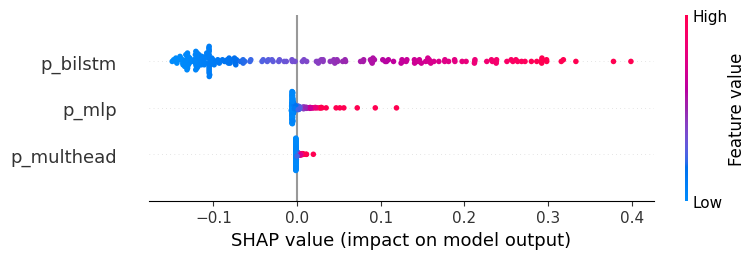

  0%|          | 0/200 [00:00<?, ?it/s]

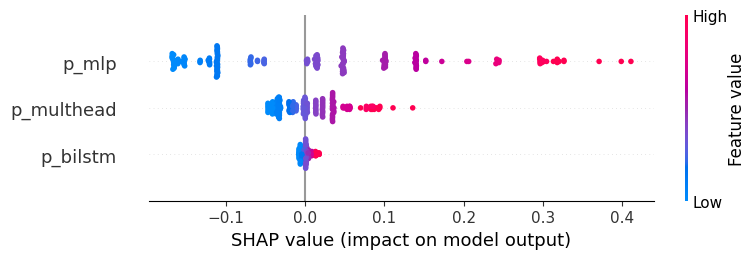

  0%|          | 0/200 [00:00<?, ?it/s]

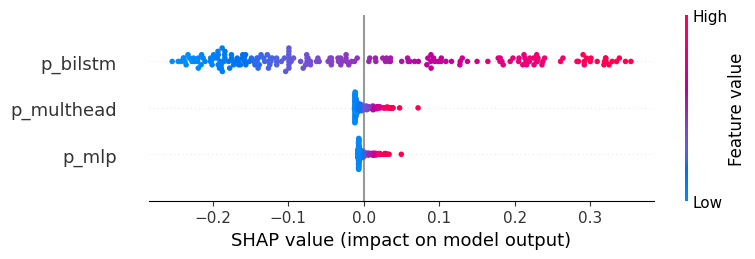

In [79]:
# EX-DL5 — beeswarm summary for the stacked blender (per label)
import numpy as np, shap, matplotlib.pyplot as plt, pickle, json, tensorflow as tf
from pathlib import Path

ART = Path("artifacts")
labels = ["diabetes","hypertension","thyroid_disorder"]

# rebuild Z = [p_mlp, p_bilstm, p_multhead] on the same split
with open(ART/"feature_columns.json") as f: cols_v1 = json.load(f)
with open(ART/"feature_columns_v2.json") as f: cols_v2 = json.load(f)

def align_df(df, cols):
    out = df.copy()
    for c in cols:
        if c not in out: out[c] = 0.0
    return out[cols].astype("float32")

def to_seq_2x72(X):
    import numpy as np
    X = np.asarray(X, dtype=np.float32); n,d = X.shape
    need = 144
    if d>need: X=X[:,:need]
    elif d<need: X=np.pad(X, ((0,0),(0,need-d)), "constant")
    return X.reshape(n,2,72)

# pick split
X_src = X_va if "X_va" in globals() else X_te
X_mlp = align_df(X_src, cols_v1)
X_mh  = align_df(X_src, cols_v2)
X_bi  = to_seq_2x72(X_mlp.values)

mlp    = tf.keras.models.load_model(ART/"mlp_dlup.keras", compile=False)
bilstm = tf.keras.models.load_model(ART/"bilstm_dlup.keras", compile=False)
mh     = tf.keras.models.load_model(ART/"mlp_resdl_multhead.keras", compile=False)

import pickle
with open(ART/"calibrators_mlp_hybrid.pkl","rb") as f:    cal_mlp = pickle.load(f)
with open(ART/"calibrators_bilstm_hybrid.pkl","rb") as f: cal_bi  = pickle.load(f)
with open(ART/"calibrators_resmlp_multhead.pkl","rb") as f: cal_mh  = pickle.load(f)

def _norm_cal_entry(e):
    import numpy as _np
    if isinstance(e, dict):
        t=str(e.get("type", e.get("kind",""))).lower()
        if "platt" in t:    return "platt",(float(e["coef"]), float(e["intercept"]))
        if "isotonic" in t: return "isotonic", e["model"]
    if isinstance(e,(list,tuple)):
        if len(e)==2:
            a,b=e
            if isinstance(a,str):
                k=a.lower()
                if "platt" in k:
                    if isinstance(b,(tuple,list,_np.ndarray)) and len(b)==2:
                        A,B=b; return "platt",(float(A), float(B))
                    return "platt",(float(b),0.0)
                if "isotonic" in k: return "isotonic", b
            if all(isinstance(v,(int,float,_np.floating)) for v in (a,b)):
                return "platt",(float(a), float(b))
        if len(e)==3 and isinstance(e[0],str) and "platt" in e[0].lower():
            return "platt",(float(e[1]), float(e[2]))
    if hasattr(e,"predict"): return "isotonic", e
    raise ValueError(e)

def apply_cal(P, cal):
    import numpy as np
    P=np.asarray(P, dtype=np.float32); out=np.zeros_like(P)
    labs=["diabetes","hypertension","thyroid_disorder"]
    for i,lab in enumerate(labs):
        k,obj=_norm_cal_entry(cal[lab])
        out[:,i]=1/(1+np.exp(-(obj[0]*P[:,i]+obj[1]))) if k=="platt" else obj.predict(P[:,i])
    return out

p_mlp = apply_cal( mlp.predict(X_mlp.values, batch_size=4096, verbose=0), cal_mlp)
p_bi  = apply_cal( bilstm.predict(X_bi,        batch_size=4096, verbose=0), cal_bi)
p_mh  = apply_cal( mh.predict(X_mh.values,     batch_size=4096, verbose=0), cal_mh)

with open(ART/"stack_blenders.pkl","rb") as f: blenders = pickle.load(f)

import numpy as np, shap, matplotlib.pyplot as plt
np.random.seed(42)
for j, lab in enumerate(labels):
    Z = np.stack([p_mlp[:,j], p_bi[:,j], p_mh[:,j]], axis=1).astype("float32")
    N = min(200, len(Z))
    bg = Z[np.random.choice(len(Z), size=N, replace=False)]
    ex = Z[np.random.choice(len(Z), size=N, replace=False)]
    f = lambda X: blenders[lab].predict_proba(np.asarray(X))[:,1]
    expl = shap.KernelExplainer(f, bg)
    sv = expl.shap_values(ex, nsamples="auto")
    shap.summary_plot(sv, ex, feature_names=["p_mlp","p_bilstm","p_multhead"], show=True)

In [80]:
# ── Cell INF1: Inference pipeline using saved artifacts ───────────────────
import json, joblib, numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path

ART_DIR = Path("artifacts")
LABELS = ["diabetes","hypertension","thyroid_disorder"]

# --- Load preprocessing + thresholds
scaler = joblib.load(ART_DIR / "standard_scaler.pkl")
feat_cols = json.load(open(ART_DIR / "feature_columns.json"))
log1p_cols = set(json.load(open(ART_DIR / "log1p_cols.json")))
thr_all = json.load(open(ART_DIR / "thresholds.json"))

def _prep_df(df_like):
    """Return DataFrame with correct columns, log1p where needed, then scale."""
    if isinstance(df_like, dict):
        df = pd.DataFrame([df_like])
    else:
        df = df_like.copy()

    # Ensure all required columns exist; fill missing with 0.0
    for c in feat_cols:
        if c not in df.columns:
            df[c] = 0.0
    # Drop extras & reorder
    df = df[feat_cols]

    # log1p on listed columns
    for c in log1p_cols:
        if c in df.columns:
            vals = pd.to_numeric(df[c], errors="coerce").astype(float)
            if (vals < 0).any():
                shift = (-(vals.min()) + 1e-9)
                vals = np.log1p(vals + shift)
            else:
                vals = np.log1p(vals)
            df[c] = vals

    Xs = pd.DataFrame(scaler.transform(df), columns=df.columns)
    return Xs

def _load_model(name):
    name = name.upper()
    if name in ("MLP","BILSTM"):
        fn = "mlp_iter_split.keras" if name=="MLP" else "bilstm_iter_split.keras"
        mdl = tf.keras.models.load_model(ART_DIR / fn, compile=False)
        return mdl, "keras", name
    elif name in ("LR","RF","XGB"):
        mdl = joblib.load(ART_DIR / f"{name.lower()}_models.pkl")
        return mdl, "sklearn_dict", name
    else:
        raise ValueError("MODEL_NAME must be one of: 'MLP','BiLSTM','LR','RF','XGB'")

def _proba(mdl, kind, X_df, model_tag):
    if kind == "keras":
        if model_tag == "BILSTM":
            arr = X_df.values.astype("float32")
            if arr.shape[1] % 2 == 1:
                arr = np.concatenate([arr, np.zeros((arr.shape[0], 1), dtype=np.float32)], axis=1)
            step = arr.shape[1] // 2
            arr = arr.reshape(arr.shape[0], 2, step)
            return mdl.predict(arr, verbose=0)
        else:
            return mdl.predict(X_df.values.astype("float32"), verbose=0)
    else:
        return np.column_stack([mdl[lab].predict_proba(X_df)[:,1] for lab in LABELS])

def run_inference(df_like, model_name="MLP", threshold_scheme="prevalence_matched"):
    """
    df_like: dict or DataFrame of raw features (any order; missing filled with 0)
    model_name: 'MLP','BiLSTM','LR','RF','XGB'
    threshold_scheme: 'prevalence_matched' or 'F0_5'
    returns: DataFrame with probs and labels
    """
    Xs = _prep_df(df_like)
    mdl, kind, tag = _load_model(model_name)
    P = _proba(mdl, kind, Xs, tag)

    th = thr_all[tag][threshold_scheme]
    thr_vec = np.array([th["diabetes"], th["hypertension"], th["thyroid_disorder"]], dtype=float)
    Yhat = (P >= thr_vec).astype(int)

    # Assemble output
    out = pd.DataFrame(P, columns=[f"p_{c}" for c in LABELS])
    for i, lab in enumerate(LABELS):
        out[f"yhat_{lab}"] = Yhat[:, i]
    return out

# --- quick demo on 5 rows from your TEST set
try:
    demo_in = X_test_final.head(5)
    demo_out = run_inference(demo_in, model_name="MLP", threshold_scheme="prevalence_matched")
    print("Demo (MLP @ prevalence-matched) on 5 TEST rows:")
    display(demo_out)
except Exception as e:
    print("Demo skipped:", e)

Demo skipped: File not found: filepath=artifacts/mlp_iter_split.keras. Please ensure the file is an accessible `.keras` zip file.


In [81]:
# ── Cell INF2: Batch inference on CSV predictions CSV ───────────────────
import pandas as pd, json, joblib, numpy as np, tensorflow as tf
from pathlib import Path

ART_DIR = Path("artifacts")
LABELS  = ["diabetes","hypertension","thyroid_disorder"]

# load artifacts once
scaler     = joblib.load(ART_DIR / "standard_scaler.pkl")
feat_cols  = json.load(open(ART_DIR / "feature_columns.json"))
log1p_cols = set(json.load(open(ART_DIR / "log1p_cols.json")))
thr_all    = json.load(open(ART_DIR / "thresholds.json"))

def _prep_df(df):
    df = df.copy()
    # keep only model features; add missing as 0.0
    for c in feat_cols:
        if c not in df.columns:
            df[c] = 0.0
    df = df[feat_cols]
    # log1p where needed
    for c in log1p_cols:
        vals = pd.to_numeric(df[c], errors="coerce").astype(float)
        neg = vals < 0
        if neg.any():
            shift = (-(vals.min()) + 1e-9)
            vals = np.log1p(vals + shift)
        else:
            vals = np.log1p(vals)
        df[c] = vals
    Xs = pd.DataFrame(scaler.transform(df), columns=df.columns)
    return Xs

def _load_model(name):
    name = name.upper()
    if name in ("MLP","BILSTM"):
        path = ART_DIR / ("mlp_iter_split.keras" if name=="MLP" else "bilstm_iter_split.keras")
        return tf.keras.models.load_model(path, compile=False), name, "keras"
    else:
        return joblib.load(ART_DIR / f"{name.lower()}_models.pkl"), name, "sklearn_dict"

def _predict(mdl, tag, kind, Xs):
    if kind == "keras":
        if tag == "BILSTM":
            arr = Xs.values.astype("float32")
            if arr.shape[1] % 2 == 1:
                arr = np.concatenate([arr, np.zeros((arr.shape[0],1), dtype=np.float32)], axis=1)
            step = arr.shape[1] // 2
            arr = arr.reshape(arr.shape[0], 2, step)
            return mdl.predict(arr, verbose=0)
        return mdl.predict(Xs.values.astype("float32"), verbose=0)
    else:
        return np.column_stack([mdl[lab].predict_proba(Xs)[:,1] for lab in LABELS])

def batch_infer_csv(input_csv, output_csv, model_name="MLP", threshold_scheme="prevalence_matched"):
    df_in = pd.read_csv(input_csv, low_memory=False)
    Xs   = _prep_df(df_in)
    mdl, tag, kind = _load_model(model_name)
    P = _predict(mdl, tag, kind, Xs)

    thr = thr_all[tag][threshold_scheme]
    thr_vec = np.array([thr["diabetes"], thr["hypertension"], thr["thyroid_disorder"]], dtype=float)
    Yhat = (P >= thr_vec).astype(int)

    out = df_in.copy()
    for i, lab in enumerate(LABELS):
        out[f"p_{lab}"] = P[:, i]
        out[f"yhat_{lab}"] = Yhat[:, i]
    out.to_csv(output_csv, index=False)
    print(f"Saved predictions → {output_csv}")

In [82]:
# ── Cell PKG: Zip artifacts for download ──────────────────────────────────
import shutil, os
zip_path = shutil.make_archive("nhanes_artifacts", "zip", "artifacts")
print("Created:", zip_path)

Created: /content/nhanes_artifacts.zip


In [83]:
# app.py
import os, json, pickle
from pathlib import Path
from typing import List, Dict, Any
import numpy as np
import pandas as pd
import tensorflow as tf
from fastapi import FastAPI
from pydantic import BaseModel
from functools import lru_cache

# ---------- config ----------
LABELS = ["diabetes", "hypertension", "thyroid_disorder"]
RELEASE = Path(os.environ.get("MODEL_DIR", "artifacts/release_stacked_mixed_v2"))


# ---------- utils ----------
def _align_df(df: pd.DataFrame, cols: List[str]) -> pd.DataFrame:
    out = df.copy()
    for c in cols:
        if c not in out.columns:
            out[c] = 0.0
    out = out[cols]
    return out.astype("float32")

def _to_seq_2x72(X_flat: np.ndarray) -> np.ndarray:
    X = np.asarray(X_flat, dtype=np.float32)
    n, d = X.shape
    steps, step = 2, 72
    need = steps * step
    if d > need:
        X = X[:, :need]
    elif d < need:
        X = np.pad(X, ((0, 0), (0, need - d)), mode="constant")
    return X.reshape(n, steps, step)

def _norm_cal_entry(entry):
    # Accepts ('platt',(a,b)) | ('isotonic', model) | dicts | raw (a,b) | object with .predict
    if isinstance(entry, (tuple, list)):
        if len(entry) == 2:
            a, b = entry
            if isinstance(a, str):
                k = a.lower()
                if "platt" in k:
                    if isinstance(b, (tuple, list, np.ndarray)) and len(b) == 2:
                        A, B = b; return "platt", (float(A), float(B))
                    return "platt", (float(b), 0.0)
                if "isotonic" in k:
                    return "isotonic", b
            if all(isinstance(v, (int, float, np.floating)) for v in (a, b)):
                return "platt", (float(a), float(b))
        if len(entry) == 3 and isinstance(entry[0], str) and "platt" in entry[0].lower():
            return "platt", (float(entry[1]), float(entry[2]))
    if isinstance(entry, dict):
        typ = str(entry.get("type", entry.get("kind", ""))).lower()
        if "platt" in typ:
            return "platt", (float(entry.get("coef")), float(entry.get("intercept")))
        if "isotonic" in typ:
            return "isotonic", entry.get("model")
    if hasattr(entry, "predict"):
        return "isotonic", entry
    raise ValueError(f"Bad calibrator entry: {entry}")

def apply_calibrators_hybrid(p_raw: np.ndarray, cal_dict: Dict[str, Any]) -> np.ndarray:
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(LABELS):
        kind, obj = _norm_cal_entry(cal_dict[lab])
        if kind == "platt":
            a, b = obj
            out[:, i] = 1.0 / (1.0 + np.exp(-(a * p_raw[:, i] + b)))
        else:
            out[:, i] = obj.predict(p_raw[:, i])
    return out


# ---------- load bundle (cached) ----------
@lru_cache(maxsize=1)
def _load_release():
    # columns
    with open(RELEASE / "feature_columns.json") as f:
        cols_v1 = json.load(f)  # 143 for MLP/BiLSTM
    with open(RELEASE / "feature_columns_v2.json") as f:
        cols_v2 = json.load(f)  # 150 for MultiHead

    # models
    mlp = tf.keras.models.load_model(RELEASE / "mlp_dlup.keras", compile=False)
    bilstm = tf.keras.models.load_model(RELEASE / "bilstm_dlup.keras", compile=False)
    mult = tf.keras.models.load_model(RELEASE / "mlp_resdl_multhead.keras", compile=False)

    # blenders + calibrators
    with open(RELEASE / "stack_blenders.pkl", "rb") as f:
        blenders = pickle.load(f)
    with open(RELEASE / "calibrators_mlp_hybrid.pkl", "rb") as f:
        cal_mlp = pickle.load(f)
    with open(RELEASE / "calibrators_bilstm_hybrid.pkl", "rb") as f:
        cal_bi = pickle.load(f)
    with open(RELEASE / "calibrators_resmlp_multhead.pkl", "rb") as f:
        cal_mult = pickle.load(f)
    with open(RELEASE / "calibrators_stacked_hybrid.pkl", "rb") as f:
        cal_stack = pickle.load(f)

    with open(RELEASE / "thresholds_stacked_selected.json") as f:
        sel = json.load(f)
    policy = sel["policy"]
    thresholds = {k: float(v) for k, v in sel["thresholds"].items()}

    # scaler
    scaler = None
    try:
        import joblib
        scaler = joblib.load(RELEASE / "standard_scaler_v2.pkl")
    except Exception:
        try:
            with open(RELEASE / "standard_scaler_v2.pkl", "rb") as f:
                scaler = pickle.load(f)
        except Exception:
            scaler = None

    return dict(
        cols_v1=cols_v1, cols_v2=cols_v2,
        mlp=mlp, bilstm=bilstm, mult=mult,
        blenders=blenders,
        cal_mlp=cal_mlp, cal_bi=cal_bi, cal_mult=cal_mult, cal_stack=cal_stack,
        policy=policy, thresholds=thresholds, scaler=scaler
    )


# ---------- FastAPI ----------
app = FastAPI(title="DL Stacked (mixed_v4_exact) Service", version="1.0.0")

class PredictRequest(BaseModel):
    rows: List[Dict[str, Any]]
    already_preprocessed: bool = True

@app.get("/health")
def health():
    ok = RELEASE.exists()
    return {"ok": ok, "bundle": str(RELEASE.resolve())}

@app.get("/meta")
def meta():
    r = _load_release()
    return {
        "labels": LABELS,
        "policy": r["policy"],
        "thresholds": r["thresholds"],
        "n_features_v1": len(r["cols_v1"]),
        "n_features_v2": len(r["cols_v2"]),
    }

@app.post("/predict")
def predict(req: PredictRequest):
    r = _load_release()
    df = pd.DataFrame(req.rows)

    # scaling
    X = df.copy()
    if not req.already_preprocessed and r["scaler"] is not None:
        superset = sorted(set(r["cols_v1"]) | set(r["cols_v2"]))
        X = _align_df(X, superset)
        X.iloc[:, :] = r["scaler"].transform(X.values)

    # per-model inputs
    X_mlp = _align_df(X, r["cols_v1"])
    X_bi = _to_seq_2x72(X_mlp.values)
    X_mult = _align_df(X, r["cols_v2"]).values

    # calibrated base probs
    p_mlp = apply_calibrators_hybrid(r["mlp"].predict(X_mlp.values, batch_size=4096, verbose=0), r["cal_mlp"])
    p_bi  = apply_calibrators_hybrid(r["bilstm"].predict(X_bi, batch_size=4096, verbose=0), r["cal_bi"])
    p_mu  = apply_calibrators_hybrid(r["mult"].predict(X_mult, batch_size=4096, verbose=0), r["cal_mult"])

    # stacked probs
    P = np.zeros_like(p_mlp, dtype=np.float32)
    for i, lab in enumerate(LABELS):
        Z = np.stack([p_mlp[:, i], p_bi[:, i], p_mu[:, i]], axis=1)
        P[:, i] = r["blenders"][lab].predict_proba(Z)[:, 1].astype(np.float32)

    # stacked calibration
    P = apply_calibrators_hybrid(P, r["cal_stack"])

    # thresholding
    thr = np.array([r["thresholds"][lab] for lab in LABELS], dtype=np.float32)
    Y = (P >= thr).astype("int32")

    # pack response
    probs = [dict(zip([f"p_{l}" for l in LABELS], map(float, row))) for row in P]
    preds = [dict(zip([f"yhat_{l}" for l in LABELS], row.tolist())) for row in Y]
    return {
        "policy": r["policy"],
        "thresholds": r["thresholds"],
        "probabilities": probs,
        "predictions": preds,
    }

Table 5-A — TEST results by model


,Model,Macro-AUPRC,Macro-AUROC,Diabetes AUPRC,Hypertension AUPRC,Thyroid AUPRC
0,Logistic Regression (v1),0.096,0.787,0.022,0.230,0.034
1,Random Forest (v1),0.074,0.758,0.017,0.184,0.021
2,MLP,0.095,0.782,0.021,0.234,0.029
3,BiLSTM,0.091,0.785,0.024,0.220,0.030
4,ResMLP (multi-head),0.094,0.789,0.020,0.225,0.031
5,Stacked DL (calibrated),0.096,0.791,0.024,0.235,0.030



VALIDATION Precision–Recall curves (one figure per label):


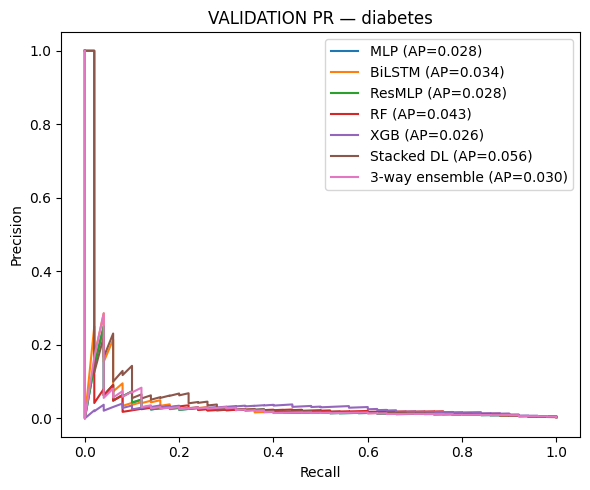

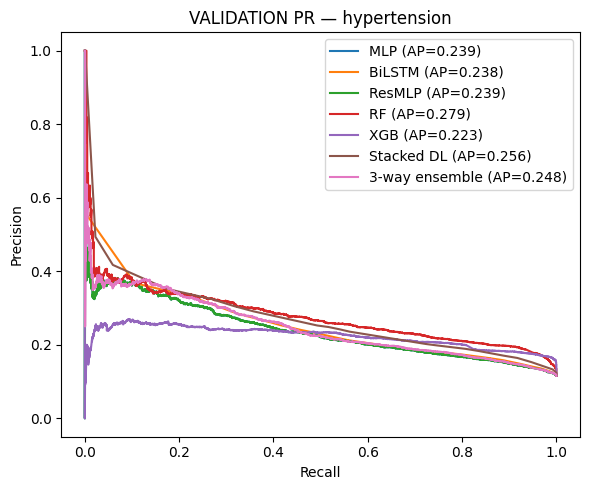

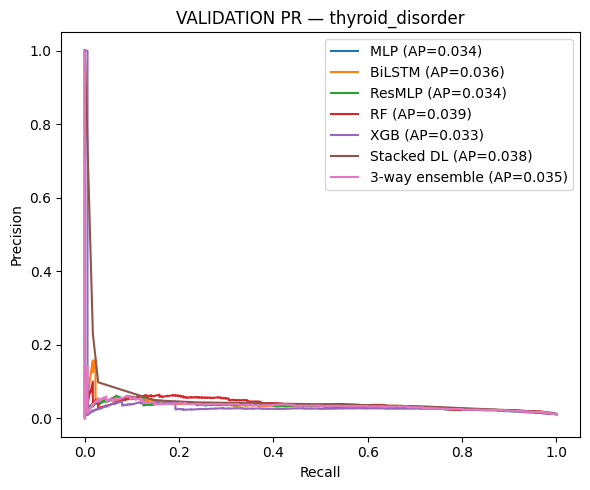


Calibration (reliability) curves — pre vs post (one figure per label):


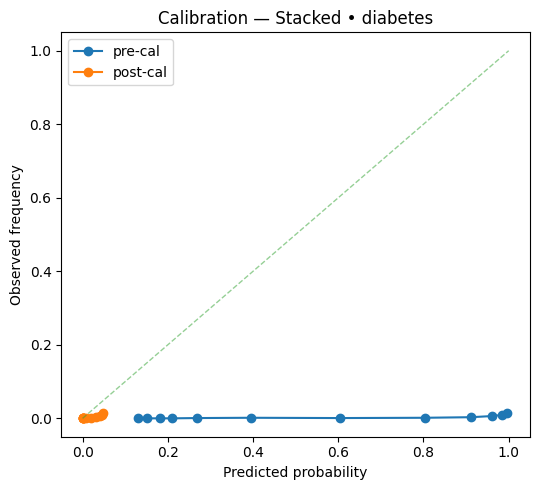

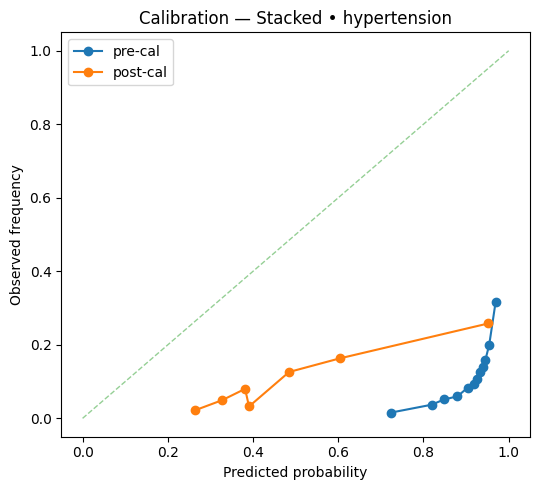

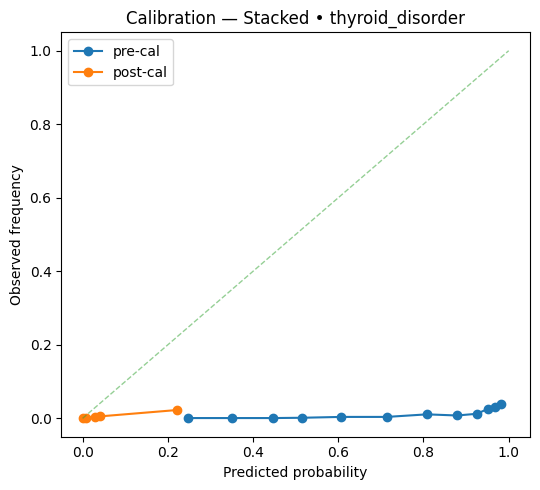


Global SHAP (top-20) — one bar plot per label:


PermutationExplainer explainer: 301it [17:58,  3.61s/it]


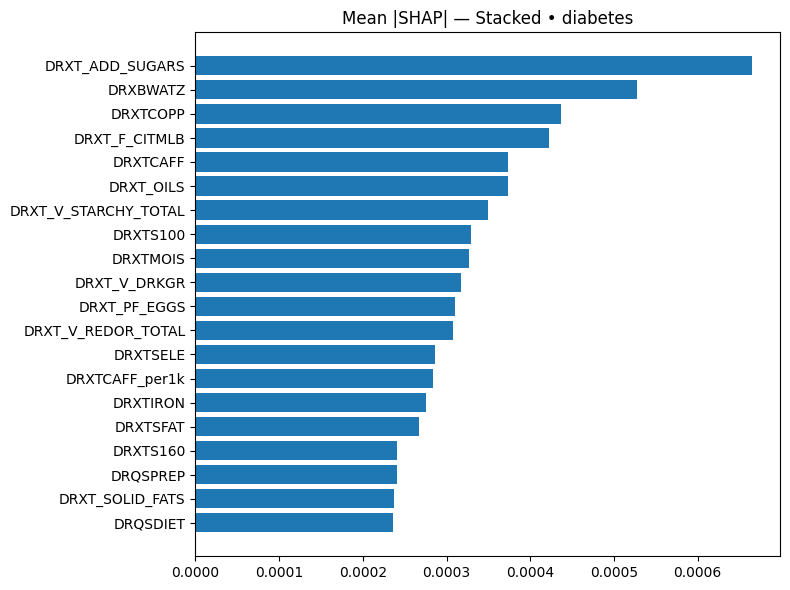


Force plots — diabetes (top 3 VAL cases):


PermutationExplainer explainer: 301it [12:13,  2.48s/it]


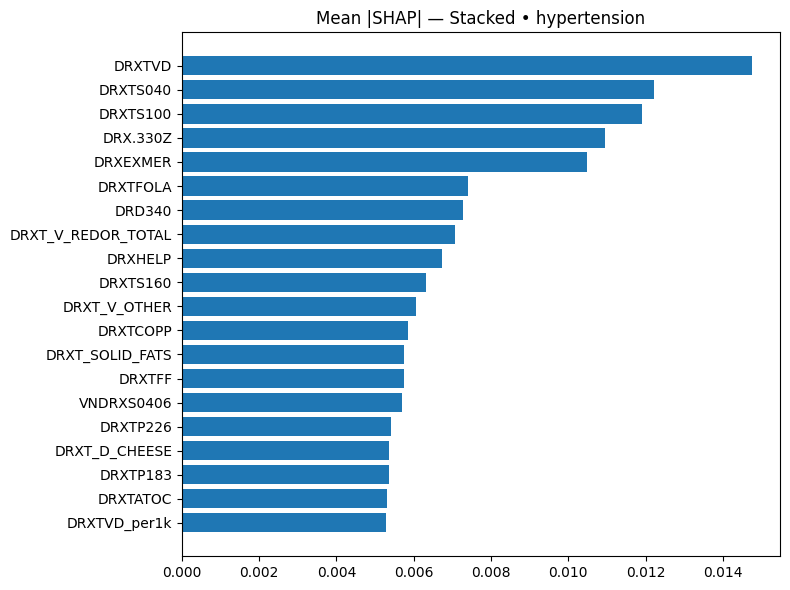


Force plots — hypertension (top 3 VAL cases):


PermutationExplainer explainer: 301it [11:57,  2.43s/it]


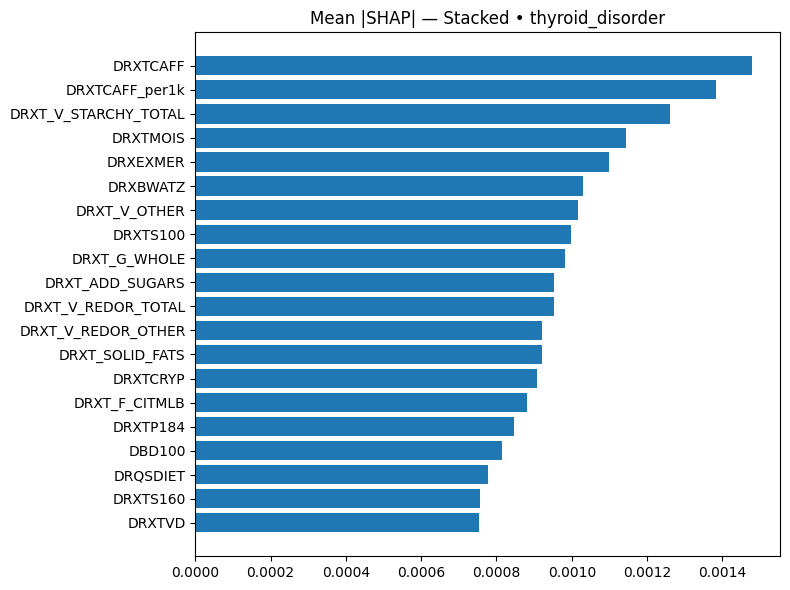


Force plots — thyroid_disorder (top 3 VAL cases):


PermutationExplainer explainer: 4it [00:10, 10.72s/it]               



Table 5-B — Threshold policy (VALIDATION & TEST)


,Label,Final threshold,VALIDATION PPV,VALIDATION Recall,TEST predicted-positive %
0,diabetes,0.02323,0.098,0.100,0.302
1,hypertension,0.21338,0.304,0.320,11.542
2,thyroid_disorder,0.23077,0.167,0.011,0.089


In [89]:
# ── Cell V1: Visual Pack

import os, json, pickle, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.metrics import precision_recall_curve, average_precision_score, precision_score, recall_score
from sklearn.calibration import calibration_curve  # ← fixed import

# ------------------------------------------------------------------
# 0) Utilities & assumptions
# ------------------------------------------------------------------
labels = ["diabetes","hypertension","thyroid_disorder"]

def _pick(env, *names):
    for n in names:
        if n in env and env[n] is not None:
            return env[n]
    raise NameError(f"Missing any of: {', '.join(names)}")

if "predict_pipeline" not in globals():
    raise NameError("predict_pipeline(...) is not defined. Run your DL29 cell first.")

# Try to infer model artifact root (release folder); fall back to 'artifacts'
ART = Path(os.environ.get("MODEL_DIR", "artifacts/release_stacked_mixed_v2"))
if not (ART / "stack_blenders.pkl").exists():
    ART = Path("artifacts")

# --- Patch: make `_load_model` robust to Path or string tokens -------------
# Some earlier cells define a `_load_model` that does `name.upper()` and crashes
# when given a Path. We override it here with a Path-safe version.
try:
    import tensorflow as tf
    ART_DIR = Path(os.environ.get("MODEL_DIR", "artifacts/release_stacked_mixed_v2"))

    # Choose the right ResMLP filename (both spellings supported)
    resmlp_candidates = ["resmlp_multihead.keras", "mlp_resdl_multhead.keras"]
    resmlp_file = next((f for f in resmlp_candidates if (ART_DIR / f).exists() or (ART / f).exists()),
                       resmlp_candidates[0])

    _MODEL_MAP = {
        "MLP": "mlp_dlup.keras",
        "BILSTM": "bilstm_dlup.keras",
        "RESMLP": resmlp_file,
    }
    _LOAD_CACHE = {}

    def _load_model(path_or_name):
        # Accept str token ("MLP"/"BILSTM"/"RESMLP" or filename) OR a pathlib.Path
        if isinstance(path_or_name, str):
            token = path_or_name.upper()
            fname = _MODEL_MAP.get(token, path_or_name)  # token or raw filename
            path = (ART_DIR / fname) if (ART_DIR / fname).exists() else (ART / fname)
        else:
            path = Path(path_or_name)

        path = path.resolve()
        key = str(path)
        if key not in _LOAD_CACHE:
            _LOAD_CACHE[key] = tf.keras.models.load_model(path, compile=False)
        return _LOAD_CACHE[key]

    globals()["_load_model"] = _load_model  # ensure predict_pipeline sees this
except Exception as e:
    print("[note] _load_model patch skipped:", e)

# ------------------------------------------------------------------
# 1) Table 5-A — TEST results by model (from your final numbers)
# ------------------------------------------------------------------
tbl5A = pd.DataFrame([
    ["Logistic Regression (v1)", 0.096, 0.787, 0.022, 0.230, 0.034],
    ["Random Forest (v1)",       0.074, 0.758, 0.017, 0.184, 0.021],
    ["MLP",                      0.095, 0.782, 0.021, 0.234, 0.029],
    ["BiLSTM",                   0.091, 0.785, 0.024, 0.220, 0.030],
    ["ResMLP (multi-head)",      0.094, 0.789, 0.020, 0.225, 0.031],
    ["Stacked DL (calibrated)",  0.096, 0.791, 0.024, 0.235, 0.030],
], columns=["Model","Macro-AUPRC","Macro-AUROC","Diabetes AUPRC","Hypertension AUPRC","Thyroid AUPRC"])
print("Table 5-A — TEST results by model")
display(tbl5A.style.format(precision=3))

# ------------------------------------------------------------------
# 2) VALIDATION PR curves (LR/RF if present; else MLP/BiLSTM/ResMLP/3-way/Stacked)
# ------------------------------------------------------------------
Xv = _pick(globals(), "X_val_final","X_va","X_valid","X_val")
yv_df = _pick(globals(), "y_val_final","y_va","y_valid","y_val")
y_true = yv_df.to_numpy(dtype=int)

# Collect any precomputed VAL probs
probs = {}
name_map = {"p_val":"MLP","p_val_bi":"BiLSTM","p_val_res":"ResMLP",
            "p_val_lr":"LR","p_val_rf":"RF","p_val_xgb":"XGB",
            "p_val_stack_cal":"Stacked DL"}
for var, nm in name_map.items():
    if var in globals() and globals()[var] is not None:
        probs[nm] = np.asarray(globals()[var])

# If missing, compute via predict_pipeline (already_preprocessed=True)
def _ensure_probs(key, use_model):
    if key not in probs:
        out,_ = predict_pipeline(Xv, use_model=use_model, already_preprocessed=True)
        if isinstance(out, pd.DataFrame):
            arr = out[[f"p_{l}" for l in labels]].to_numpy() if f"p_{labels[0]}" in out.columns else out.to_numpy()
        else:
            arr = np.asarray(out)
        probs[key] = arr

for key, use_model in [("MLP","mlp"), ("BiLSTM","bilstm"), ("ResMLP","resmlp_multhead"), ("Stacked DL","stacked")]:
    try:
        _ensure_probs(key, use_model)
    except Exception as e:
        print(f"[note] could not build {key}: {e}")

# 3-way ensemble (mean of base calibrated)
if all(k in probs for k in ("MLP","BiLSTM","ResMLP")) and "3-way ensemble" not in probs:
    probs["3-way ensemble"] = (probs["MLP"] + probs["BiLSTM"] + probs["ResMLP"]) / 3.0

print("\nVALIDATION Precision–Recall curves (one figure per label):")
for j, lab in enumerate(labels):
    plt.figure(figsize=(6.0, 5.0))
    for nm, P in probs.items():
        if P.shape[1] != 3:
            continue
        prec, rec, _ = precision_recall_curve(y_true[:, j], P[:, j])
        ap = average_precision_score(y_true[:, j], P[:, j])
        plt.plot(rec, prec, label=f"{nm} (AP={ap:.3f})")
    plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title(f"VALIDATION PR — {lab}")
    plt.legend(loc="best"); plt.tight_layout()
    plt.show()

# ------------------------------------------------------------------
# 3) Calibration curves (pre vs post) for Stacked model
# ------------------------------------------------------------------
# Build base calibrated if missing
for key, use_model in [("MLP","mlp"), ("BiLSTM","bilstm"), ("ResMLP","resmlp_multhead")]:
    if key not in probs:
        out,_ = predict_pipeline(Xv, use_model=use_model, already_preprocessed=True)
        probs[key] = out[[f"p_{l}" for l in labels]].to_numpy() if isinstance(out, pd.DataFrame) else np.asarray(out)

# Load stacker & its calibrator
with open(ART/"stack_blenders.pkl","rb") as f: blenders = pickle.load(f)
with open(ART/"calibrators_stacked_hybrid.pkl","rb") as f: cal_stack = pickle.load(f)

# Helper: normalize calibrator entries (platt / isotonic)
def _norm_cal_entry(entry):
    import numpy as _np
    if isinstance(entry, (tuple, list)):
        if len(entry)==2:
            a,b = entry
            if isinstance(a,str):
                k=a.lower()
                if "platt" in k:
                    if isinstance(b,(tuple,list,_np.ndarray)) and len(b)==2:
                        A,B=b; return "platt",(float(A), float(B))
                    return "platt",(float(b), 0.0)
                if "isotonic" in k: return "isotonic", b
            if all(isinstance(v,(int,float,_np.floating)) for v in (a,b)):
                return "platt",(float(a), float(b))
        if len(entry)==3 and isinstance(entry[0],str) and "platt" in entry[0].lower():
            return "platt",(float(entry[1]), float(entry[2]))
    if isinstance(entry, dict):
        typ=str(entry.get("type",entry.get("kind",""))).lower()
        if "platt" in typ: return "platt",(float(entry.get("coef")), float(entry.get("intercept")))
        if "isotonic" in typ: return "isotonic", entry.get("model")
    if hasattr(entry,"predict"): return "isotonic", entry
    raise ValueError(f"Bad calibrator entry: {entry}")

def _apply_calibrators_hybrid(p_raw, cal_dict):
    p_raw = np.asarray(p_raw, dtype=np.float32)
    out = np.zeros_like(p_raw, dtype=np.float32)
    for i, lab in enumerate(labels):
        kind, obj = _norm_cal_entry(cal_dict[lab])
        if kind == "platt":
            a,b = obj
            out[:, i] = 1.0 / (1.0 + np.exp(-(a * p_raw[:, i] + b)))
        else:
            out[:, i] = obj.predict(p_raw[:, i])
    return out

# Build pre/post stacked
P_pre = np.zeros_like(probs["MLP"], dtype=np.float32)
for i, lab in enumerate(labels):
    Z = np.stack([probs["MLP"][:,i], probs["BiLSTM"][:,i], probs["ResMLP"][:,i]], axis=1)
    P_pre[:, i] = blenders[lab].predict_proba(Z)[:, 1].astype(np.float32)
P_post = _apply_calibrators_hybrid(P_pre, cal_stack)

print("\nCalibration (reliability) curves — pre vs post (one figure per label):")
for j, lab in enumerate(labels):
    plt.figure(figsize=(5.5,5.0))
    for arr, nm in [(P_pre[:,j],"pre-cal"), (P_post[:,j],"post-cal")]:
        prob_true, prob_pred = calibration_curve(y_true[:,j], arr, n_bins=12, strategy="quantile")
        plt.plot(prob_pred, prob_true, marker="o", label=nm)
    plt.plot([0,1],[0,1],"--", lw=1, alpha=0.5)
    plt.xlabel("Predicted probability"); plt.ylabel("Observed frequency")
    plt.title(f"Calibration — Stacked • {lab}"); plt.legend(); plt.tight_layout()
    plt.show()

# ------------------------------------------------------------------
# 4) Global SHAP bars (top-20) for Stacked (per label) + 5) Force plots
# ------------------------------------------------------------------
try:
    import shap
    shap.initjs()
    rng = np.random.default_rng(42)
    n_bg = min(200, len(Xv))
    n_ex = min(300, len(Xv))
    idx_bg = rng.choice(len(Xv), size=n_bg, replace=False)
    idx_ex = rng.choice(len(Xv), size=n_ex, replace=False)
    X_bg = Xv.iloc[idx_bg].copy()
    X_ex = Xv.iloc[idx_ex].copy()

    def f_label(j):
        def _f(X_in):
            Xdf = pd.DataFrame(X_in, columns=Xv.columns)
            out,_ = predict_pipeline(Xdf, use_model="stacked", already_preprocessed=True)
            p = out[[f"p_{l}" for l in labels]].to_numpy()
            return p[:, j]
        return _f

    print("\nGlobal SHAP (top-20) — one bar plot per label:")
    for j, lab in enumerate(labels):
        expl = shap.Explainer(f_label(j), shap.maskers.Independent(X_bg), algorithm="permutation")
        sv = expl(X_ex, max_evals=2*X_ex.shape[1] + 1024)
        mean_abs = np.abs(sv.values).mean(axis=0).ravel()
        df_imp = pd.DataFrame({"feature": Xv.columns, "mean_abs_shap": mean_abs}).sort_values("mean_abs_shap", ascending=False)
        top = df_imp.head(20).iloc[::-1]
        plt.figure(figsize=(8,6)); plt.barh(top["feature"], top["mean_abs_shap"])
        plt.title(f"Mean |SHAP| — Stacked • {lab}"); plt.tight_layout(); plt.show()

        N_FORCE = min(3, len(Xv))
        p_lab = f_label(j)(Xv.values)
        top_idx = np.argsort(-p_lab)[:N_FORCE]
        print(f"\nForce plots — {lab} (top {N_FORCE} VAL cases):")
        sv_force = expl(Xv.iloc[top_idx], max_evals=2*Xv.shape[1] + 1024)
        for k in range(N_FORCE):
            display(shap.plots.force(sv_force[k], matplotlib=False))

except Exception as e:
    print("\n[Note] SHAP visualizations skipped due to:", e)

# ------------------------------------------------------------------
# 6) Table 5-B — Threshold policy summary (from selected thresholds + computed PPV/Recall on VAL, pos-rate on TEST)
# ------------------------------------------------------------------
with open(ART/"thresholds_stacked_selected.json","r") as f:
    sel = json.load(f)
thr = {k: float(v) for k,v in sel["thresholds"].items()}

X_t  = _pick(globals(), "X_test_final","X_te","X_test")
y_t  = _pick(globals(), "y_test_final","y_te","y_test").to_numpy(dtype=int)

P_val,_ = predict_pipeline(Xv, use_model="stacked", already_preprocessed=True)
P_val = P_val[[f"p_{l}" for l in labels]].to_numpy()
P_te,_  = predict_pipeline(X_t, use_model="stacked", already_preprocessed=True)
P_te  = P_te[[f"p_{l}" for l in labels]].to_numpy()

val_ppv, val_rec, te_pos = [], [], []
for j, lab in enumerate(labels):
    yhat_v = (P_val[:,j] >= thr[lab]).astype(int)
    yhat_t = (P_te[:,j]  >= thr[lab]).astype(int)
    val_ppv.append(precision_score(y_true[:,j], yhat_v, zero_division=0))
    val_rec.append(recall_score(  y_true[:,j], yhat_v, zero_division=0))
    te_pos.append(yhat_t.mean())

tbl5B = pd.DataFrame({
    "Label": labels,
    "Final threshold": [thr[l] for l in labels],
    "VALIDATION PPV":  [round(x,3) for x in val_ppv],
    "VALIDATION Recall":[round(x,3) for x in val_rec],
    "TEST predicted-positive %":[round(100*x,3) for x in te_pos]
})
print("\nTable 5-B — Threshold policy (VALIDATION & TEST)")
display(tbl5B.style.format({"Final threshold":"{:.5f}","VALIDATION PPV":"{:.3f}","VALIDATION Recall":"{:.3f}","TEST predicted-positive %":"{:.3f}"}))

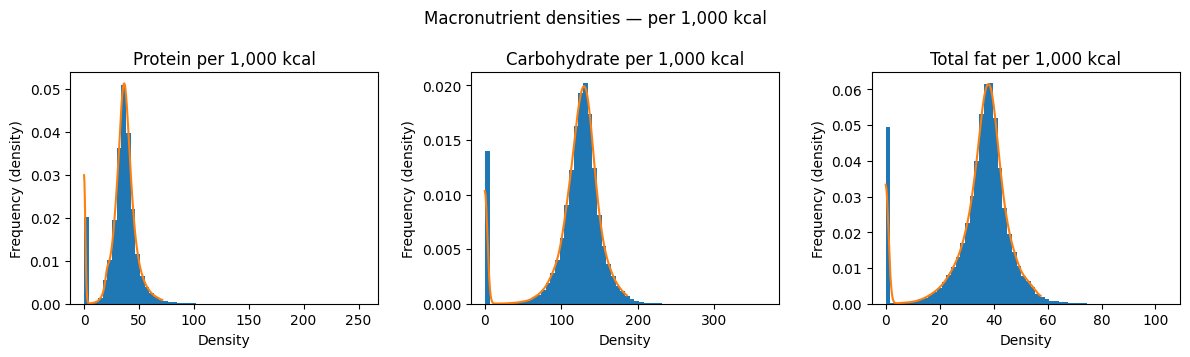

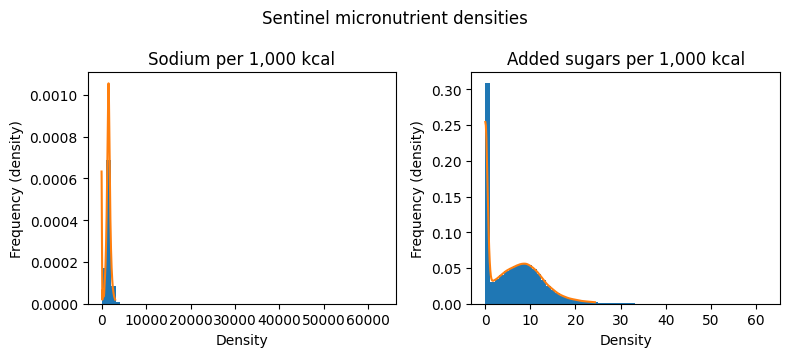

In [86]:
# ── Cell V2: Densities + Histograms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# DataFrame
if "diet" not in globals():
    raise RuntimeError("Please load your NHANES dietary DataFrame into a variable named `diet` first.")

# Helpers
def _first_present(df, candidates, required=True):
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(f"None of {candidates} found in columns.")
    return None

def add_density(df, total_col, energy_col, out_col=None):
    """
    density per 1,000 kcal = total / (energy/1000)
    Sets density to 0 if energy is missing/zero to avoid division errors.
    Returns the name of the created/overwritten column.
    """
    e = df[energy_col].astype(float).replace({0.0: np.nan})
    dens = df[total_col].astype(float) / (e / 1000.0)
    dens = dens.fillna(0.0)
    out = out_col or f"{total_col}_per1k"
    df[out] = dens
    return out

# Resolve likely NHANES column names
C_ENERGY = ["DRXTKCAL", "kcal_total"]
C_PROT   = ["DRXTPROT", "protein_total_g", "PROT"]
C_CARB   = ["DRXTCARB", "carb_total_g", "CARB"]
C_FAT    = ["DRXTTFAT", "fat_total_g", "TFAT"]
C_SOD    = ["DRXTSODI", "sodium_mg", "SODI", "DRXSODI"]
C_SUG    = ["DRXT_ADD_SUGARS", "addsugar_g", "ADDSUG", "DRXSUGA"]

_energy = _first_present(diet, C_ENERGY)
_prot   = _first_present(diet, C_PROT)
_carb   = _first_present(diet, C_CARB)
_fat    = _first_present(diet, C_FAT)
_sod    = _first_present(diet, C_SOD, required=False)
_sug    = _first_present(diet, C_SUG, required=False)

# --- Compute per-1,000 kcal densities
prot_per1k = add_density(diet, _prot, _energy)
carb_per1k = add_density(diet, _carb, _energy)
fat_per1k  = add_density(diet, _fat,  _energy)
sod_per1k  = add_density(diet, _sod,  _energy) if _sod else None
sug_per1k  = add_density(diet, _sug,  _energy) if _sug else None

# KDE helper
def _maybe_kde(xs):
    try:
        from scipy.stats import gaussian_kde
        xs = xs[~np.isnan(xs)]
        kde = gaussian_kde(xs)
        grid = np.linspace(np.nanpercentile(xs, 1), np.nanpercentile(xs, 99), 200)
        y = kde(grid)
        plt.plot(grid, y)
    except Exception:
        counts, bins = np.histogram(xs[~np.isnan(xs)], bins=60, density=True)
        centers = (bins[1:] + bins[:-1]) / 2
        win = np.ones(5) / 5.0
        smooth = np.convolve(counts, win, mode="same")
        plt.plot(centers, smooth)

# Macronutrient densities
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col, title in zip(
    axes,
    [prot_per1k, carb_per1k, fat_per1k],
    ["Protein per 1,000 kcal", "Carbohydrate per 1,000 kcal", "Total fat per 1,000 kcal"]
):
    xs = diet[col].astype(float).to_numpy()
    ax.hist(xs, bins=60, density=True)
    plt.sca(ax); _maybe_kde(xs)
    ax.set_title(title); ax.set_xlabel("Density"); ax.set_ylabel("Frequency (density)")

fig.suptitle("Macronutrient densities — per 1,000 kcal")
fig.tight_layout()
plt.show()

# Sentinel micronutrient densities
if sod_per1k or sug_per1k:
    nplots = 2 if (sod_per1k and sug_per1k) else 1
    fig, axes = plt.subplots(1, nplots, figsize=(8, 3.6))
    if nplots == 1:
        axes = np.array([axes])
    cols_titles = []
    if sod_per1k: cols_titles.append((sod_per1k, "Sodium per 1,000 kcal"))
    if sug_per1k: cols_titles.append((sug_per1k, "Added sugars per 1,000 kcal"))
    for ax, (col, title) in zip(axes, cols_titles):
        xs = diet[col].astype(float).to_numpy()
        ax.hist(xs, bins=60, density=True)
        plt.sca(ax); _maybe_kde(xs)
        ax.set_title(title); ax.set_xlabel("Density"); ax.set_ylabel("Frequency (density)")
    fig.suptitle("Sentinel micronutrient densities")
    fig.tight_layout()
    plt.show()

In [90]:
# ── Cell V2: target construction + illustrative sample rows
import re
import numpy as np
import pandas as pd

# Expect: a DataFrame named `resp`
if "resp" not in globals():
    raise RuntimeError("Please load your NHANES responses DataFrame into `resp` first.")

# Optional manual overrides if your columns have custom names
FORCE_MAP = {
    # "seqn": "participant_id",
    # "diabetes_ever": "diabetes_ever_flag",
    # "hypertension_ever": "htn_ever_flag",
}

AUTO_PICK = True  # set False if you prefer to fill FORCE_MAP manually

# ---------- utilities ----------
def _score_candidates(columns, weighted_tokens):
    """
    Rank columns by weighted token matches.
    weighted_tokens: list of (token, weight). Tokens matched case-insensitively.
    Returns list of (score, colname) sorted desc.
    """
    scores = []
    for c in columns:
        name = c.lower()
        s = 0
        for tok, w in weighted_tokens:
            if re.search(rf"\b{re.escape(tok)}\b", name):
                s += w
        # also allow non-boundary matches for typical patterns like diq010/bpq020
        for tok, w in weighted_tokens:
            if tok in {"diq010","bpq020"} and tok in name:
                s += w  # add again to boost exact code hits
        if s > 0:
            scores.append((s, c))
    scores.sort(key=lambda x: (-x[0], x[1]))
    return scores

def _map_yes(series):
    """
    NHANES-style mapping: numeric 1 -> 1; everything else -> 0.
    Strings 'yes','y','1','true' -> 1; others -> 0.
    """
    s = series
    if np.issubdtype(s.dtype, np.number):
        return (s == 1).astype(int)
    s = s.astype(str).str.strip().str.lower()
    return s.isin({"1", "yes", "y", "true"}).astype(int)

def _first_existing(df, names):
    for n in names:
        if n in df.columns:
            return n
    return None

# ---------- try to resolve columns ----------
cols = list(resp.columns)

# ID column (optional)
seqn_col = FORCE_MAP.get("seqn") or _first_existing(resp, ["SEQN","seqn","respondent_id","participant_id","id"])

# Diabetes-ever (prefer DIQ010-like or clear semantics)
diab_force = FORCE_MAP.get("diabetes_ever")
if diab_force and diab_force not in cols:
    raise KeyError(f"FORCE_MAP['diabetes_ever']='{diab_force}' not found in resp columns")

if diab_force:
    diab_src = diab_force
else:
    diab_scores = _score_candidates(cols, [
        ("diq010", 5), ("diabetes", 3), ("diab", 2), ("ever", 2), ("told", 1), ("dx", 1)
    ])
    diab_src = diab_scores[0][1] if (AUTO_PICK and diab_scores) else None

# Hypertension-ever (prefer BPQ020-like or clear semantics)
htn_force = FORCE_MAP.get("hypertension_ever")
if htn_force and htn_force not in cols:
    raise KeyError(f"FORCE_MAP['hypertension_ever']='{htn_force}' not found in resp columns")

if htn_force:
    htn_src = htn_force
else:
    htn_scores = _score_candidates(cols, [
        ("bpq020", 5), ("hypertension", 3), ("hyper", 2), ("bp", 1), ("ever", 2), ("told", 1)
    ])
    htn_src = htn_scores[0][1] if (AUTO_PICK and htn_scores) else None

# TSH labs (if any)
tsh_cols = [c for c in cols if re.search(r"tsh", c, flags=re.I)]
# narrow to the common NHANES LBXTSH* first if present
preferred_tsh = [c for c in ["LBXTSH","LBXTSH1","LBXTSH2"] if c in cols]
if preferred_tsh:
    tsh_cols = preferred_tsh

# ---------- sanity reporting ----------
print("Detected columns (edit FORCE_MAP if these look wrong):")
print(f"  ID column:              {seqn_col or '(not used)'}")
print(f"  Diabetes-ever source:   {diab_src or '(not found)'}")
if not diab_src and diab_scores:
    print("   ↳ suggestions:", [c for _, c in diab_scores[:5]])
print(f"  Hypertension-ever src:  {htn_src or '(not found)'}")
if not htn_src and htn_scores:
    print("   ↳ suggestions:", [c for _, c in htn_scores[:5]])
print(f"  TSH columns:            {tsh_cols if tsh_cols else '(none found)'}")

if not (diab_src and htn_src):
    print("\nCould not automatically resolve both ‘diabetes ever’ and ‘hypertension ever’.")
    print("Please set FORCE_MAP, e.g.:")
    print("FORCE_MAP = { 'diabetes_ever': '<your_diabetes_col>', 'hypertension_ever': '<your_htn_col>' }")
    # Do not raise; continue with what we have to show as much as possible.

# ---------- build derived label table ----------
keep = [c for c in [seqn_col, diab_src, htn_src] if c]
df_lab = resp[keep].copy()
rename_map = {}
if seqn_col: rename_map[seqn_col] = "SEQN"
if diab_src: rename_map[diab_src] = "DIABETES_SRC"
if htn_src:  rename_map[htn_src]  = "HYPERTENSION_SRC"
df_lab.rename(columns=rename_map, inplace=True)

# derive labels (use 0 if source missing so the table still prints)
if "DIABETES_SRC" in df_lab:
    df_lab["diabetes"] = _map_yes(df_lab["DIABETES_SRC"])
else:
    df_lab["diabetes"] = 0

if "HYPERTENSION_SRC" in df_lab:
    df_lab["hypertension"] = _map_yes(df_lab["HYPERTENSION_SRC"])
else:
    df_lab["hypertension"] = 0

# thyroid from TSH range if present
if tsh_cols:
    tsh = resp[tsh_cols].apply(pd.to_numeric, errors="coerce")
    out_low  = (tsh < 0.40).any(axis=1)
    out_high = (tsh > 4.50).any(axis=1)
    df_lab["thyroid_disorder"] = (out_low | out_high).astype(int)
    for c in tsh_cols:
        df_lab[c] = tsh[c]
else:
    df_lab["thyroid_disorder"] = 0

# ---------- pick a small illustrative sample across label combos ----------
df_lab["_combo"] = (df_lab["diabetes"].astype(str) +
                    df_lab["hypertension"].astype(str) +
                    df_lab["thyroid_disorder"].astype(str))

samples = []
for _, grp in df_lab.groupby("_combo"):
    samples.append(grp.head(2))  # up to two per combo
sample_df = (pd.concat(samples) if samples else df_lab.head(10)).drop(columns=["_combo"]).reset_index(drop=True)

display_cols = [c for c in ["SEQN","DIABETES_SRC","HYPERTENSION_SRC"] if c in sample_df.columns]
display_cols += [c for c in ["LBXTSH","LBXTSH1","LBXTSH2"] if c in sample_df.columns]
display_cols += ["diabetes","hypertension","thyroid_disorder"]
sample_df = sample_df[display_cols]

print("\nSample rows (illustrative for §4.2):")
print(sample_df.to_string(index=False))

Detected columns (edit FORCE_MAP if these look wrong):
  ID column:              SEQN
  Diabetes-ever source:   (not found)
  Hypertension-ever src:  (not found)
  TSH columns:            ['LBXTSH', 'LBXTSH1', 'LBXTSH2']

Could not automatically resolve both ‘diabetes ever’ and ‘hypertension ever’.
Please set FORCE_MAP, e.g.:
FORCE_MAP = { 'diabetes_ever': '<your_diabetes_col>', 'hypertension_ever': '<your_htn_col>' }

Sample rows (illustrative for §4.2):
 SEQN  LBXTSH  LBXTSH1  LBXTSH2  diabetes  hypertension  thyroid_disorder
    9   1.300    1.300    1.300         0             0                 0
   48   3.800    3.800      NaN         0             0                 0
  449   0.370    0.370      NaN         0             0                 1
  743   5.700    5.000    6.400         0             0                 1
